# Sensor-based and multimodal models

Sensor models (B-E), calibration/referral (F2) and multimodal stacking (H, I). Model D is the NTR-XGB sensor model reported in the paper.

Part of the code for *Robust Non-Motor Symptom Modeling for Parkinson's Disease Differential Diagnosis*. See the repository README for the run order.

In [ ]:
# Exact reproduction requires XGBoost 3.3.0 (restart the runtime after installing)
!pip install -q xgboost==3.3.0

## Model B - bilateral-asymmetry 1D-CNN

TENSORFLOW GPU CHECK
TensorFlow version: 2.20.0
Detected GPU: Tesla T4
Mixed-precision policy: <DTypePolicy "mixed_float16">
TensorFlow deterministic operations enabled.

MODEL B — CORRECTED EXPLICIT BILATERAL-ASYMMETRY 1D-CNN
Task-wise file : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_pd_dd_taskwise.npz
Fixed folds    : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Simple CNN dir : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/simple_1dcnn_gpu_5fold
Output folder  : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_b_bilateral_asymmetry_corrected_5fold

Available NPZ keys:
['X_tasks', 'y', 'patient_ids', 'questionnaire', 'condition_original', 'condition_3class', 'task_name

Model: "model_b_explicit_bilateral_asymmetry"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ left_wrist_tasks    │ (None, 11, 976,   │          0 │ -                 │
│ (InputLayer)        │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ right_wrist_tasks   │ (None, 11, 976,   │          0 │ -                 │
│ (InputLayer)        │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporary_left_fla… │ (None, 10736, 6)  │          0 │ left_wrist_tasks… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporary_right_fl… │ (None, 10736, 6)  │          0 │ right_wrist_task… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ merge_left_batch_t… │ (None, 976, 6)    │          0 │ temporary_left_f… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ merge_right_batch_… │ (None, 976, 6)    │          0 │ temporary_right_… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilateral_task_enc… │ (None, 128)       │     98,720 │ merge_left_batch… │
│ (Functional)        │                   │            │ merge_right_batc… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └                │ (None, 976, 6)    │          0 │ -                 │
│ left_single_task_i… │                   │            │                   │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └                │ (None, 976, 6)    │          0 │ -                 │
│ right_single_task_… │                   │            │                   │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └                │ (None, 96)        │     49,440 │ -                 │
│ shared_wrist_encod… │                   │            │                   │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│       └             │ (None, 976, 6)    │          0 │ -                 │
│ single_wrist_task_… │                   │            │                   │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│       └ wrist_conv1 │ (None, 976, 32)   │      1,344 │ -                 │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│       └ wrist_bn1   │ (None, 976, 32)   │        128 │ -                 │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│       └ wrist_relu1 │ (None, 976, 32)   │          0 │ -                 │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│       └ wrist_pool1 │ (None, 488, 32)   │          0 │ -                 │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 107,041 (418.13 KB)

 Trainable params: 106,593 (416.38 KB)

 Non-trainable params: 448 (1.75 KB)


Dummy forward-pass output shape: (2, 1)
Model parameter count          : 107041

✅ Corrected architecture test passed.

Training configuration:
Maximum epochs          : 100
Early-stopping patience : 15
Batch size              : 16
Validation fraction     : 0.2
Learning rate           : 0.001
Prediction threshold    : 0.5
Bootstrap iterations    : 2000

STARTING CORRECTED MODEL B FIVE-FOLD TRAINING

--------------------------------------------------------------------------------------
OUTER FOLD 1/5
--------------------------------------------------------------------------------------
Subtraining: 249 (PD=176, DD=73)
Validation : 63 (PD=45, DD=18)
Testing    : 78 (PD=55, DD=23)
Class weights: {0: 1.7054794520547945, 1: 0.7073863636363636}
Epoch 1/100
16/16 - 10s - 625ms/step - accuracy: 0.4739 - loss: 0.7322 - pr_auc: 0.7046 - roc_auc: 0.4868 - val_accuracy: 0.2857 - val_loss: 0.7642 - val_pr_auc: 0.7968 - val_roc_auc: 0.6617 - learning_rate: 0.0010
Epoch 2/100
16/16 - 1s - 71ms/step 

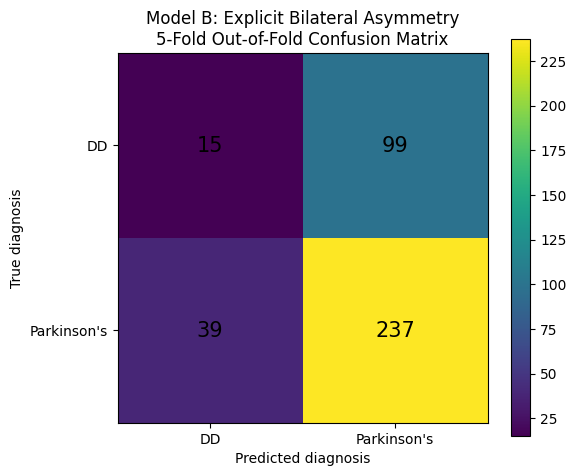

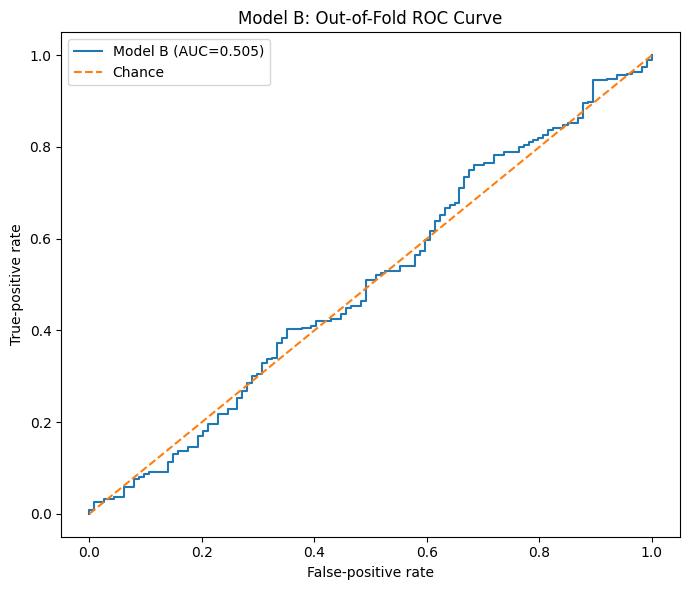

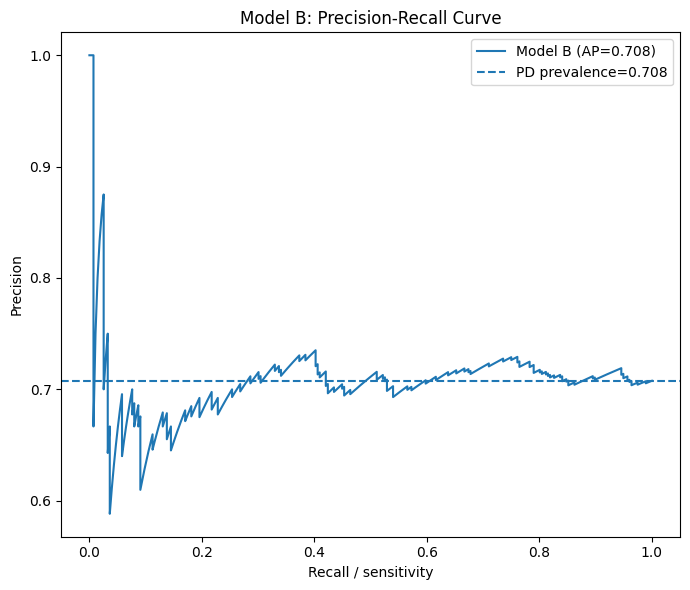

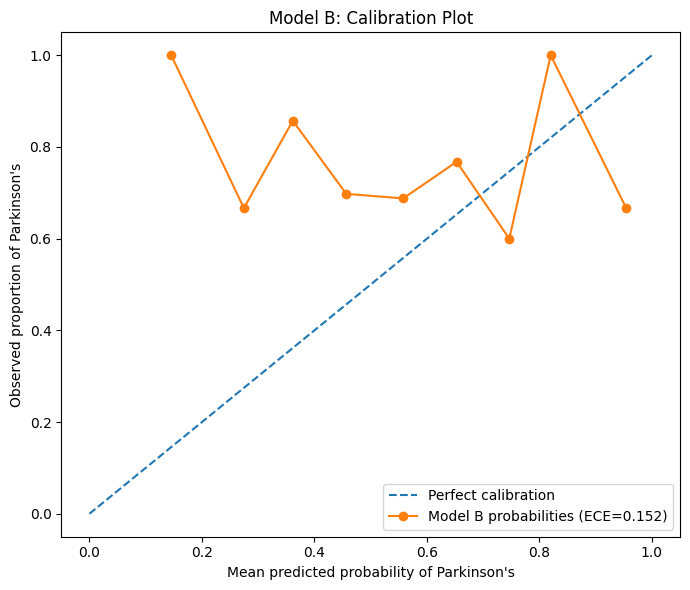

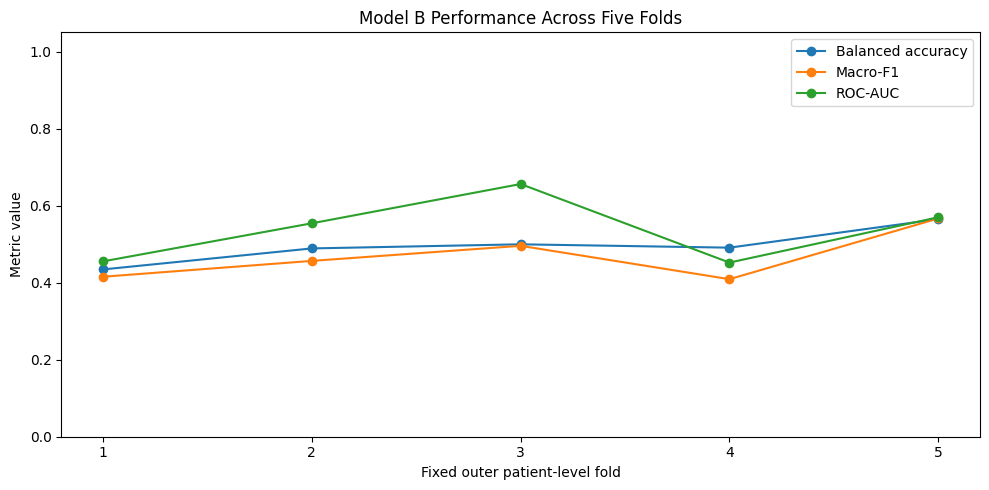

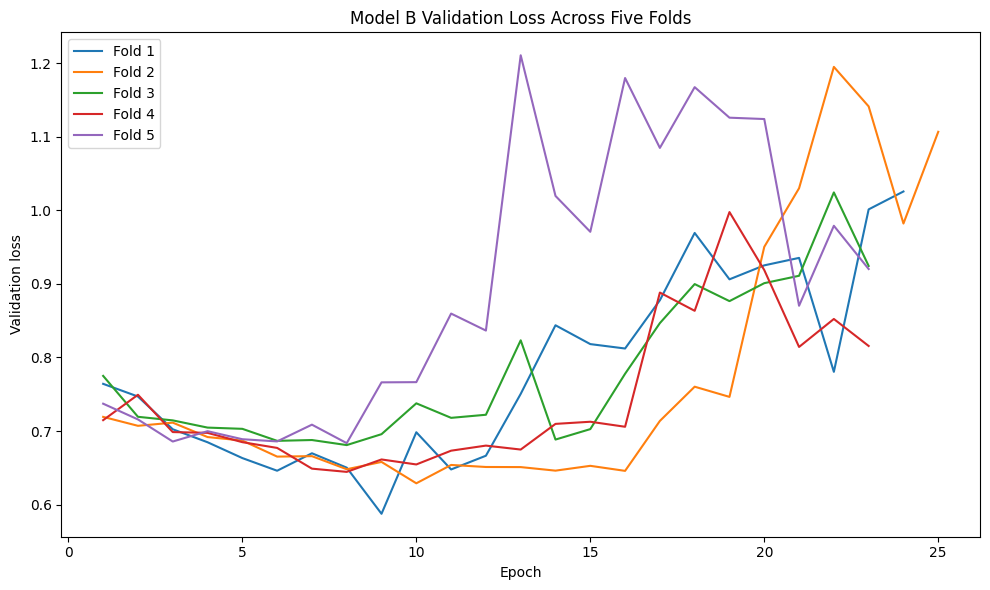

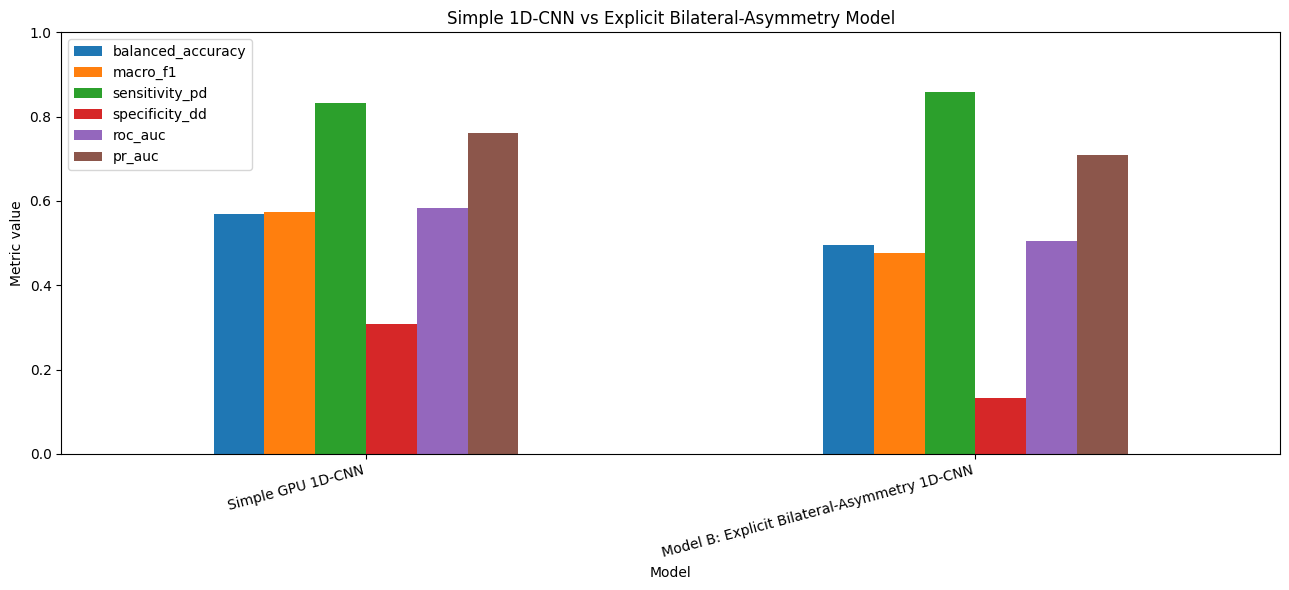


CORRECTED MODEL B TRAINING COMPLETE

Out-of-fold classification report:

                        precision    recall  f1-score   support

Differential Diagnosis     0.2778    0.1316    0.1786       114
           Parkinson's     0.7054    0.8587    0.7745       276

              accuracy                         0.6462       390
             macro avg     0.4916    0.4951    0.4765       390
          weighted avg     0.5804    0.6462    0.6003       390


Overall out-of-fold metrics:

accuracy                 : 0.6462
balanced_accuracy        : 0.4951
macro_f1                 : 0.4765
pd_f1                    : 0.7745
dd_f1                    : 0.1786
precision_pd             : 0.7054
sensitivity_pd           : 0.8587
specificity_dd           : 0.1316
ppv_pd                   : 0.7054
npv_dd                   : 0.2778
roc_auc                  : 0.5048
pr_auc                   : 0.7082
brier_score              : 0.2314
ece_10_bins              : 0.1523
true_negative            : 15
fa

In [ ]:
# =================================================================================================
# MODEL B — CORRECTED EXPLICIT BILATERAL-ASYMMETRY GPU 1D-CNN
# ONE COMPLETE CELL | KERAS 3 / TENSORFLOW 2.20 COMPATIBLE
# SAME FIXED 5 PATIENT-LEVEL FOLDS | MAXIMUM 100 EPOCHS
# =================================================================================================
#
# INPUT:
#   X_tasks shape = (390, 11, 976, 12)
#
# PER-TASK CHANNEL ORDER:
#   0,1,2   = Acceleration Left X/Y/Z
#   3,4,5   = Acceleration Right X/Y/Z
#   6,7,8   = Rotation Left X/Y/Z
#   9,10,11 = Rotation Right X/Y/Z
#
# MODEL B:
#   Shared left/right wrist CNN encoder
#          ↓
#   Left embedding L
#   Right embedding R
#          ↓
#   [L, R, |L-R|, L×R]
#          ↓
#   Learned bilateral task fusion
#          ↓
#   Equal averaging across 11 tasks
#          ↓
#   PD/DD classification
#
# NOT INCLUDED YET:
#   - Quality-aware task weighting
#   - Adaptive/minimum-task selection
#   - Probability calibration and specialist referral
#   - Missing task/wrist/sensor augmentation
#   - Final explainability experiments
# =================================================================================================

import os
import gc
import sys
import time
import random
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# =================================================================================================
# 1. TENSORFLOW IMPORT AND GPU CHECK
# =================================================================================================

try:
    import tensorflow as tf
except ImportError:
    print("Installing TensorFlow...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "tensorflow"
    ])
    import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

print("=" * 110)
print("TENSORFLOW GPU CHECK")
print("=" * 110)

print("TensorFlow version:", tf.__version__)

physical_gpus = tf.config.list_physical_devices("GPU")

if not physical_gpus:
    raise RuntimeError(
        "TensorFlow GPU detect nahi kar raha.\n\n"
        "Google Colab mein:\n"
        "Runtime → Change runtime type → T4 GPU\n"
        "phir runtime restart karke cell dobara run karein."
    )

for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

try:
    gpu_name = (
        tf.config.experimental
        .get_device_details(physical_gpus[0])
        .get("device_name", "Unknown GPU")
    )
except Exception:
    gpu_name = "GPU detected"

print("Detected GPU:", gpu_name)

try:
    keras.mixed_precision.set_global_policy("mixed_float16")
except Exception:
    keras.mixed_precision.set_global_policy("float32")

print("Mixed-precision policy:", keras.mixed_precision.global_policy())

# =================================================================================================
# 2. REPRODUCIBILITY
# =================================================================================================

GLOBAL_SEED = 42

random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
tf.keras.utils.set_random_seed(GLOBAL_SEED)

try:
    tf.config.experimental.enable_op_determinism()
    print("TensorFlow deterministic operations enabled.")
except Exception:
    print("Full deterministic operations could not be enabled.")

# =================================================================================================
# 3. PATHS
# =================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_READY_DIR = BASE_DIR / "project_ready_data"
FEATURE_ENGINEERING_DIR = PROJECT_READY_DIR / "feature_engineering"
BASELINE_ROOT = PROJECT_READY_DIR / "baseline_results"
PROPOSED_ROOT = PROJECT_READY_DIR / "proposed_model_results"

TASKWISE_FILE = (
    FEATURE_ENGINEERING_DIR
    / "pads_pd_dd_taskwise.npz"
)

FIXED_SPLIT_FILE = (
    BASELINE_ROOT
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

SIMPLE_CNN_DIR = (
    BASELINE_ROOT
    / "simple_1dcnn_gpu_5fold"
)

SIMPLE_CNN_SUMMARY_FILE = (
    SIMPLE_CNN_DIR
    / "overall_summary.csv"
)

SIMPLE_CNN_PREDICTIONS_FILE = (
    SIMPLE_CNN_DIR
    / "patient_predictions.csv"
)

OUTPUT_DIR = (
    PROPOSED_ROOT
    / "model_b_bilateral_asymmetry_corrected_5fold"
)

FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
HISTORY_DIR = OUTPUT_DIR / "training_histories"

for directory in [
    OUTPUT_DIR,
    FIGURE_DIR,
    MODEL_DIR,
    HISTORY_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

if not TASKWISE_FILE.exists():
    possible_files = list(
        BASE_DIR.rglob("pads_pd_dd_taskwise.npz")
    )

    if not possible_files:
        raise FileNotFoundError(
            "pads_pd_dd_taskwise.npz file nahi mili.\n"
            "Task-wise feature-engineering code dobara run karein."
        )

    TASKWISE_FILE = possible_files[0]

print("\n" + "=" * 110)
print("MODEL B — CORRECTED EXPLICIT BILATERAL-ASYMMETRY 1D-CNN")
print("=" * 110)

print("Task-wise file :", TASKWISE_FILE)
print("Fixed folds    :", FIXED_SPLIT_FILE)
print("Simple CNN dir :", SIMPLE_CNN_DIR)
print("Output folder  :", OUTPUT_DIR)

# =================================================================================================
# 4. LOAD TASK-WISE SIGNAL DATA
# =================================================================================================

npz_data = np.load(
    TASKWISE_FILE,
    allow_pickle=True
)

print("\nAvailable NPZ keys:")
print(npz_data.files)

required_keys = {
    "X_tasks",
    "y",
    "patient_ids",
}

missing_keys = required_keys - set(npz_data.files)

if missing_keys:
    raise ValueError(
        f"Required NPZ keys missing hain: {missing_keys}"
    )

X_all = np.asarray(
    npz_data["X_tasks"],
    dtype=np.float32
)

y = np.asarray(
    npz_data["y"],
    dtype=np.int32
)

patient_ids = np.array([
    str(patient_id).zfill(3)
    for patient_id in npz_data["patient_ids"].astype(str)
])

task_names = (
    npz_data["task_names"].astype(str)
    if "task_names" in npz_data.files
    else np.array([
        f"Task_{i + 1}"
        for i in range(X_all.shape[1])
    ])
)

stored_channel_names = (
    npz_data["channel_names"].astype(str)
    if "channel_names" in npz_data.files
    else np.array([])
)

print("\nLoaded task-wise tensor:", X_all.shape)
print("Labels shape           :", y.shape)
print("Unique patients        :", len(np.unique(patient_ids)))

print("\nClass distribution:")
print("Differential Diagnosis:", int(np.sum(y == 0)))
print("Parkinson's disease    :", int(np.sum(y == 1)))

if X_all.ndim != 4:
    raise ValueError(
        f"Expected a four-dimensional tensor, found {X_all.shape}."
    )

if X_all.shape[0] != len(y):
    raise ValueError(
        "Signal and label patient counts do not match."
    )

if len(np.unique(patient_ids)) != len(patient_ids):
    raise ValueError(
        "Duplicate patient IDs detected."
    )

N_PATIENTS = int(X_all.shape[0])
N_TASKS = int(X_all.shape[1])
N_TIMEPOINTS = int(X_all.shape[2])
N_CHANNELS = int(X_all.shape[3])

if N_CHANNELS != 12:
    raise ValueError(
        f"Expected 12 channels per task, found {N_CHANNELS}."
    )

print("\nSignal dimensions:")
print("Patients   :", N_PATIENTS)
print("Tasks      :", N_TASKS)
print("Timepoints :", N_TIMEPOINTS)
print("Channels   :", N_CHANNELS)

# =================================================================================================
# 5. CORRECT TASK-LOCAL CHANNEL MAPPING
# =================================================================================================
#
# Stored channel_names contains 132 names:
# 11 tasks × 12 channels.
#
# X_tasks already separates tasks on axis 1, so the model only sees
# 12 channel positions within each task.
# =================================================================================================

default_task_local_names = np.array([
    "Acceleration_Left_X",
    "Acceleration_Left_Y",
    "Acceleration_Left_Z",
    "Acceleration_Right_X",
    "Acceleration_Right_Y",
    "Acceleration_Right_Z",
    "Rotation_Left_X",
    "Rotation_Left_Y",
    "Rotation_Left_Z",
    "Rotation_Right_X",
    "Rotation_Right_Y",
    "Rotation_Right_Z",
])

if len(stored_channel_names) >= 12:
    first_task_names = stored_channel_names[:12]

    task_local_channel_names = np.array([
        name.replace(f"{task_names[0]}_", "", 1)
        if str(name).startswith(f"{task_names[0]}_")
        else str(name)
        for name in first_task_names
    ])
else:
    task_local_channel_names = default_task_local_names.copy()

LEFT_CHANNEL_INDICES = np.array(
    [0, 1, 2, 6, 7, 8],
    dtype=np.int32
)

RIGHT_CHANNEL_INDICES = np.array(
    [3, 4, 5, 9, 10, 11],
    dtype=np.int32
)

N_WRIST_CHANNELS = 6

print("\nCorrect task-local channel layout:")

for index, channel_name in enumerate(task_local_channel_names):
    print(f"{index:2d}: {channel_name}")

print("\nLeft wrist indices :", LEFT_CHANNEL_INDICES)
print("Right wrist indices:", RIGHT_CHANNEL_INDICES)

print("\nLeft wrist channels:")

for index in LEFT_CHANNEL_INDICES:
    print(f"  {index}: {task_local_channel_names[index]}")

print("\nRight wrist channels:")

for index in RIGHT_CHANNEL_INDICES:
    print(f"  {index}: {task_local_channel_names[index]}")

channel_mapping_df = pd.DataFrame({
    "within_task_channel_index": np.concatenate([
        LEFT_CHANNEL_INDICES,
        RIGHT_CHANNEL_INDICES,
    ]),
    "channel_name": np.concatenate([
        task_local_channel_names[LEFT_CHANNEL_INDICES],
        task_local_channel_names[RIGHT_CHANNEL_INDICES],
    ]),
    "wrist": (
        ["Left"] * N_WRIST_CHANNELS
        + ["Right"] * N_WRIST_CHANNELS
    ),
})

channel_mapping_df.to_csv(
    OUTPUT_DIR / "left_right_channel_mapping.csv",
    index=False
)

# =================================================================================================
# 6. LOAD OR RECREATE THE SAME FIXED OUTER FIVE FOLDS
# =================================================================================================

if FIXED_SPLIT_FILE.exists():
    fixed_splits = pd.read_csv(
        FIXED_SPLIT_FILE,
        dtype={"patient_id": str}
    )

    fixed_splits["patient_id"] = (
        fixed_splits["patient_id"]
        .astype(str)
        .str.zfill(3)
    )

    fixed_splits["role"] = (
        fixed_splits["role"]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    print("\nExisting fixed five folds loaded.")

else:
    print(
        "\nFixed fold file missing. Recreating using:\n"
        "StratifiedKFold(n_splits=5, shuffle=True, random_state=42)"
    )

    FIXED_SPLIT_FILE.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    outer_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    dummy_X = np.zeros(
        (N_PATIENTS, 1),
        dtype=np.float32
    )

    split_rows = []

    for fold_number, (train_indices, test_indices) in enumerate(
        outer_cv.split(dummy_X, y),
        start=1
    ):
        for index in train_indices:
            split_rows.append({
                "patient_id": patient_ids[index],
                "fold": fold_number,
                "role": "train",
                "true_label": int(y[index]),
            })

        for index in test_indices:
            split_rows.append({
                "patient_id": patient_ids[index],
                "fold": fold_number,
                "role": "test",
                "true_label": int(y[index]),
            })

    fixed_splits = pd.DataFrame(split_rows)

    fixed_splits.to_csv(
        FIXED_SPLIT_FILE,
        index=False
    )

    print("Fixed folds saved:", FIXED_SPLIT_FILE)

required_fold_columns = {
    "patient_id",
    "fold",
    "role",
}

if not required_fold_columns.issubset(
    fixed_splits.columns
):
    raise ValueError(
        "Fixed-fold file must contain patient_id, fold and role."
    )

available_folds = sorted(
    fixed_splits["fold"].unique()
)

if available_folds != [1, 2, 3, 4, 5]:
    raise ValueError(
        f"Expected folds [1,2,3,4,5], found {available_folds}."
    )

if set(fixed_splits["patient_id"]) != set(patient_ids):
    raise ValueError(
        "Fixed-fold patient IDs and task-wise NPZ patient IDs do not match."
    )

test_frequency = (
    fixed_splits.loc[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if (
    len(test_frequency) != N_PATIENTS
    or not (test_frequency == 1).all()
):
    raise ValueError(
        "Every patient must appear in outer testing exactly once."
    )

patient_to_index = {
    patient_id: index
    for index, patient_id in enumerate(patient_ids)
}

print("✅ Fixed outer five patient-level folds verified.")

# =================================================================================================
# 7. EVALUATION FUNCTIONS
# =================================================================================================

def expected_calibration_error(
    y_true,
    probability_pd,
    n_bins=10
):
    y_true = np.asarray(y_true)
    probability_pd = np.asarray(probability_pd)

    edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(n_bins):
        lower = edges[bin_index]
        upper = edges[bin_index + 1]

        if bin_index == n_bins - 1:
            mask = (
                (probability_pd >= lower)
                & (probability_pd <= upper)
            )
        else:
            mask = (
                (probability_pd >= lower)
                & (probability_pd < upper)
            )

        if not np.any(mask):
            continue

        mean_probability = float(
            np.mean(probability_pd[mask])
        )

        observed_rate = float(
            np.mean(y_true[mask])
        )

        ece += float(np.mean(mask)) * abs(
            observed_rate - mean_probability
        )

    return float(ece)


def calculate_metrics(
    y_true,
    y_pred,
    probability_pd
):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity_pd = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity_dd = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    ppv_pd = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    npv_dd = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "pd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "dd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),
        "precision_pd": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "sensitivity_pd": sensitivity_pd,
        "specificity_dd": specificity_dd,
        "ppv_pd": ppv_pd,
        "npv_dd": npv_dd,
        "roc_auc": roc_auc_score(
            y_true,
            probability_pd
        ),
        "pr_auc": average_precision_score(
            y_true,
            probability_pd
        ),
        "brier_score": brier_score_loss(
            y_true,
            probability_pd
        ),
        "ece_10_bins": expected_calibration_error(
            y_true,
            probability_pd,
            n_bins=10
        ),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

# =================================================================================================
# 8. NORMALIZATION FUNCTIONS
# =================================================================================================

def calculate_training_normalization(
    X_training
):
    finite_training = np.where(
        np.isfinite(X_training),
        X_training,
        np.nan
    )

    channel_mean = np.nanmean(
        finite_training,
        axis=(0, 1, 2),
        keepdims=True
    )

    channel_std = np.nanstd(
        finite_training,
        axis=(0, 1, 2),
        keepdims=True
    )

    channel_mean = np.where(
        np.isfinite(channel_mean),
        channel_mean,
        0.0
    ).astype(np.float32)

    channel_std = np.where(
        np.isfinite(channel_std)
        & (channel_std > 1e-6),
        channel_std,
        1.0
    ).astype(np.float32)

    return channel_mean, channel_std


def normalize_signals(
    X_data,
    channel_mean,
    channel_std
):
    X_clean = np.where(
        np.isfinite(X_data),
        X_data,
        channel_mean
    )

    X_normalized = (
        X_clean - channel_mean
    ) / channel_std

    X_normalized = np.clip(
        X_normalized,
        -10.0,
        10.0
    )

    return X_normalized.astype(
        np.float32
    )

# =================================================================================================
# 9. CORRECTED MODEL B ARCHITECTURE
# =================================================================================================

def build_bilateral_asymmetry_model(
    number_of_tasks,
    number_of_timepoints,
    wrist_channels=6,
    wrist_embedding_dimension=96,
    task_embedding_dimension=128,
    learning_rate=1e-3
):
    """
    Keras 3 compatible implementation.

    Multi-input TimeDistributed is intentionally not used.

    Instead:
      (batch, tasks, time, channels)
          ↓
      (batch × tasks, time, channels)
          ↓
      bilateral task encoder
          ↓
      (batch × tasks, task_embedding)
          ↓
      (batch, tasks, task_embedding)
    """

    # ---------------------------------------------------------------------------------------------
    # A. Shared wrist encoder
    # ---------------------------------------------------------------------------------------------

    wrist_input = keras.Input(
        shape=(
            number_of_timepoints,
            wrist_channels
        ),
        name="single_wrist_task_input"
    )

    x = layers.Conv1D(
        filters=32,
        kernel_size=7,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name="wrist_conv1"
    )(wrist_input)

    x = layers.BatchNormalization(
        name="wrist_bn1"
    )(x)

    x = layers.Activation(
        "relu",
        name="wrist_relu1"
    )(x)

    x = layers.MaxPooling1D(
        pool_size=2,
        name="wrist_pool1"
    )(x)

    x = layers.Conv1D(
        filters=64,
        kernel_size=5,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name="wrist_conv2"
    )(x)

    x = layers.BatchNormalization(
        name="wrist_bn2"
    )(x)

    x = layers.Activation(
        "relu",
        name="wrist_relu2"
    )(x)

    x = layers.MaxPooling1D(
        pool_size=2,
        name="wrist_pool2"
    )(x)

    x = layers.Conv1D(
        filters=128,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name="wrist_conv3"
    )(x)

    x = layers.BatchNormalization(
        name="wrist_bn3"
    )(x)

    x = layers.Activation(
        "relu",
        name="wrist_relu3"
    )(x)

    x = layers.GlobalAveragePooling1D(
        name="wrist_global_average_pool"
    )(x)

    wrist_embedding = layers.Dense(
        wrist_embedding_dimension,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(
            1e-4
        ),
        name="wrist_embedding"
    )(x)

    shared_wrist_encoder = keras.Model(
        inputs=wrist_input,
        outputs=wrist_embedding,
        name="shared_wrist_encoder"
    )

    # ---------------------------------------------------------------------------------------------
    # B. One-task bilateral encoder
    # ---------------------------------------------------------------------------------------------

    left_single_task_input = keras.Input(
        shape=(
            number_of_timepoints,
            wrist_channels
        ),
        name="left_single_task_input"
    )

    right_single_task_input = keras.Input(
        shape=(
            number_of_timepoints,
            wrist_channels
        ),
        name="right_single_task_input"
    )

    left_embedding = shared_wrist_encoder(
        left_single_task_input
    )

    right_embedding = shared_wrist_encoder(
        right_single_task_input
    )

    absolute_difference = layers.Lambda(
        lambda tensors: tf.abs(
            tensors[0] - tensors[1]
        ),
        output_shape=(
            wrist_embedding_dimension,
        ),
        name="absolute_left_right_difference"
    )([
        left_embedding,
        right_embedding
    ])

    multiplicative_interaction = layers.Multiply(
        name="left_right_product"
    )([
        left_embedding,
        right_embedding
    ])

    bilateral_features = layers.Concatenate(
        name="bilateral_feature_concatenation"
    )([
        left_embedding,
        right_embedding,
        absolute_difference,
        multiplicative_interaction
    ])

    task_embedding = layers.Dense(
        task_embedding_dimension,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(
            1e-4
        ),
        name="bilateral_task_fusion"
    )(bilateral_features)

    task_embedding = layers.Dropout(
        0.20,
        name="bilateral_task_dropout"
    )(task_embedding)

    bilateral_task_encoder = keras.Model(
        inputs=[
            left_single_task_input,
            right_single_task_input
        ],
        outputs=task_embedding,
        name="bilateral_task_encoder"
    )

    # ---------------------------------------------------------------------------------------------
    # C. Full patient model
    # ---------------------------------------------------------------------------------------------

    left_patient_input = keras.Input(
        shape=(
            number_of_tasks,
            number_of_timepoints,
            wrist_channels
        ),
        name="left_wrist_tasks"
    )

    right_patient_input = keras.Input(
        shape=(
            number_of_tasks,
            number_of_timepoints,
            wrist_channels
        ),
        name="right_wrist_tasks"
    )

    # Merge batch and task dimensions separately for left and right.
    flattened_left_tasks = layers.Reshape(
        target_shape=(
            number_of_tasks * number_of_timepoints,
            wrist_channels
        ),
        name="temporary_left_flatten_placeholder"
    )(left_patient_input)

    flattened_right_tasks = layers.Reshape(
        target_shape=(
            number_of_tasks * number_of_timepoints,
            wrist_channels
        ),
        name="temporary_right_flatten_placeholder"
    )(right_patient_input)

    # Convert (B, T*time, C) into (B*T, time, C) dynamically.
    flattened_left_tasks = layers.Lambda(
        lambda tensor: tf.reshape(
            tensor,
            (
                -1,
                number_of_timepoints,
                wrist_channels
            )
        ),
        output_shape=(
            number_of_timepoints,
            wrist_channels
        ),
        name="merge_left_batch_task_dimensions"
    )(flattened_left_tasks)

    flattened_right_tasks = layers.Lambda(
        lambda tensor: tf.reshape(
            tensor,
            (
                -1,
                number_of_timepoints,
                wrist_channels
            )
        ),
        output_shape=(
            number_of_timepoints,
            wrist_channels
        ),
        name="merge_right_batch_task_dimensions"
    )(flattened_right_tasks)

    flattened_task_embeddings = bilateral_task_encoder([
        flattened_left_tasks,
        flattened_right_tasks
    ])

    task_embeddings = layers.Lambda(
        lambda tensors: tf.reshape(
            tensors[0],
            (
                tf.shape(tensors[1])[0],
                number_of_tasks,
                task_embedding_dimension
            )
        ),
        output_shape=(
            number_of_tasks,
            task_embedding_dimension
        ),
        name="restore_patient_task_dimensions"
    )([
        flattened_task_embeddings,
        left_patient_input
    ])

    # Equal task averaging: no quality-aware fusion yet.
    patient_embedding = layers.GlobalAveragePooling1D(
        name="equal_average_across_tasks"
    )(task_embeddings)

    z = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(
            1e-4
        ),
        name="patient_dense_64"
    )(patient_embedding)

    z = layers.Dropout(
        0.40,
        name="patient_dropout"
    )(z)

    output = layers.Dense(
        1,
        activation="sigmoid",
        dtype="float32",
        name="pd_probability"
    )(z)

    model = keras.Model(
        inputs=[
            left_patient_input,
            right_patient_input
        ],
        outputs=output,
        name="model_b_explicit_bilateral_asymmetry"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate,
            clipnorm=1.0
        ),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),
            keras.metrics.AUC(
                name="roc_auc",
                curve="ROC"
            ),
            keras.metrics.AUC(
                name="pr_auc",
                curve="PR"
            ),
        ]
    )

    return model

# =================================================================================================
# 10. ARCHITECTURE TEST BEFORE TRAINING
# =================================================================================================

tf.keras.backend.clear_session()
gc.collect()

temporary_model = build_bilateral_asymmetry_model(
    number_of_tasks=N_TASKS,
    number_of_timepoints=N_TIMEPOINTS,
    wrist_channels=N_WRIST_CHANNELS,
    wrist_embedding_dimension=96,
    task_embedding_dimension=128,
    learning_rate=1e-3
)

print("\nCorrected Model B architecture:")
temporary_model.summary(
    expand_nested=True
)

MODEL_PARAMETER_COUNT = int(
    temporary_model.count_params()
)

dummy_left = np.zeros(
    (
        2,
        N_TASKS,
        N_TIMEPOINTS,
        N_WRIST_CHANNELS
    ),
    dtype=np.float32
)

dummy_right = np.zeros(
    (
        2,
        N_TASKS,
        N_TIMEPOINTS,
        N_WRIST_CHANNELS
    ),
    dtype=np.float32
)

dummy_output = temporary_model(
    [
        dummy_left,
        dummy_right
    ],
    training=False
)

print("\nDummy forward-pass output shape:", dummy_output.shape)
print("Model parameter count          :", MODEL_PARAMETER_COUNT)

if tuple(dummy_output.shape) != (2, 1):
    raise RuntimeError(
        f"Unexpected Model-B output shape: {dummy_output.shape}"
    )

del temporary_model, dummy_left, dummy_right, dummy_output

tf.keras.backend.clear_session()
gc.collect()

print("\n✅ Corrected architecture test passed.")

# =================================================================================================
# 11. TRAINING CONFIGURATION
# =================================================================================================

MAX_EPOCHS = 100
EARLY_STOPPING_PATIENCE = 15
BATCH_SIZE = 16
VALIDATION_FRACTION = 0.20
LEARNING_RATE = 1e-3
PREDICTION_THRESHOLD = 0.50
WRIST_EMBEDDING_DIMENSION = 96
TASK_EMBEDDING_DIMENSION = 128
N_BOOTSTRAPS = 2000

print("\nTraining configuration:")
print("Maximum epochs          :", MAX_EPOCHS)
print("Early-stopping patience :", EARLY_STOPPING_PATIENCE)
print("Batch size              :", BATCH_SIZE)
print("Validation fraction     :", VALIDATION_FRACTION)
print("Learning rate           :", LEARNING_RATE)
print("Prediction threshold    :", PREDICTION_THRESHOLD)
print("Bootstrap iterations    :", N_BOOTSTRAPS)

# =================================================================================================
# 12. OUT-OF-FOLD STORAGE
# =================================================================================================

out_of_fold_probability = np.full(
    N_PATIENTS,
    np.nan,
    dtype=np.float32
)

out_of_fold_prediction = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

fold_assignments = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

fold_result_rows = []
training_summary_rows = []
normalization_rows = []
assignment_rows = []

total_start_time = time.time()

print("\n" + "=" * 110)
print("STARTING CORRECTED MODEL B FIVE-FOLD TRAINING")
print("=" * 110)

# =================================================================================================
# 13. FIXED OUTER FIVE-FOLD TRAINING
# =================================================================================================

for fold_number in available_folds:
    fold_start_time = time.time()

    tf.keras.backend.clear_session()
    gc.collect()

    fold_seed = GLOBAL_SEED + int(fold_number)

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    tf.keras.utils.set_random_seed(fold_seed)

    current_fold = fixed_splits.loc[
        fixed_splits["fold"] == fold_number
    ]

    outer_train_ids = current_fold.loc[
        current_fold["role"] == "train",
        "patient_id"
    ].tolist()

    outer_test_ids = current_fold.loc[
        current_fold["role"] == "test",
        "patient_id"
    ].tolist()

    if set(outer_train_ids).intersection(outer_test_ids):
        raise RuntimeError(
            f"Outer-fold patient leakage detected in fold {fold_number}."
        )

    outer_train_indices = np.array([
        patient_to_index[patient_id]
        for patient_id in outer_train_ids
    ])

    outer_test_indices = np.array([
        patient_to_index[patient_id]
        for patient_id in outer_test_ids
    ])

    y_outer_train = y[outer_train_indices]
    y_test = y[outer_test_indices]

    # Same fold-specific validation strategy as Simple 1D-CNN.
    validation_splitter = StratifiedShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_FRACTION,
        random_state=fold_seed
    )

    relative_subtrain_indices, relative_validation_indices = next(
        validation_splitter.split(
            np.zeros(
                len(outer_train_indices),
                dtype=np.float32
            ),
            y_outer_train
        )
    )

    subtrain_indices = outer_train_indices[
        relative_subtrain_indices
    ]

    validation_indices = outer_train_indices[
        relative_validation_indices
    ]

    subtrain_ids = set(patient_ids[subtrain_indices])
    validation_ids = set(patient_ids[validation_indices])
    test_ids = set(patient_ids[outer_test_indices])

    if (
        subtrain_ids.intersection(validation_ids)
        or subtrain_ids.intersection(test_ids)
        or validation_ids.intersection(test_ids)
    ):
        raise RuntimeError(
            f"Subtrain/validation/test leakage detected in fold {fold_number}."
        )

    for index in subtrain_indices:
        assignment_rows.append({
            "fold": fold_number,
            "patient_id": patient_ids[index],
            "role": "subtrain",
            "true_label": int(y[index]),
        })

    for index in validation_indices:
        assignment_rows.append({
            "fold": fold_number,
            "patient_id": patient_ids[index],
            "role": "validation",
            "true_label": int(y[index]),
        })

    for index in outer_test_indices:
        assignment_rows.append({
            "fold": fold_number,
            "patient_id": patient_ids[index],
            "role": "test",
            "true_label": int(y[index]),
        })

    X_subtrain_raw = X_all[subtrain_indices]
    X_validation_raw = X_all[validation_indices]
    X_test_raw = X_all[outer_test_indices]

    y_subtrain = y[subtrain_indices]
    y_validation = y[validation_indices]

    # ---------------------------------------------------------------------------------------------
    # Normalization fitted only on subtraining patients
    # ---------------------------------------------------------------------------------------------

    channel_mean, channel_std = calculate_training_normalization(
        X_subtrain_raw
    )

    X_subtrain_normalized = normalize_signals(
        X_subtrain_raw,
        channel_mean,
        channel_std
    )

    X_validation_normalized = normalize_signals(
        X_validation_raw,
        channel_mean,
        channel_std
    )

    X_test_normalized = normalize_signals(
        X_test_raw,
        channel_mean,
        channel_std
    )

    for channel_index in range(N_CHANNELS):
        normalization_rows.append({
            "fold": fold_number,
            "channel_index": channel_index,
            "channel_name": task_local_channel_names[channel_index],
            "channel_mean": float(
                channel_mean[0, 0, 0, channel_index]
            ),
            "channel_std": float(
                channel_std[0, 0, 0, channel_index]
            ),
        })

    # ---------------------------------------------------------------------------------------------
    # Split into left and right wrist tensors
    # ---------------------------------------------------------------------------------------------

    X_subtrain_left = X_subtrain_normalized[
        ...,
        LEFT_CHANNEL_INDICES
    ].astype(np.float32)

    X_subtrain_right = X_subtrain_normalized[
        ...,
        RIGHT_CHANNEL_INDICES
    ].astype(np.float32)

    X_validation_left = X_validation_normalized[
        ...,
        LEFT_CHANNEL_INDICES
    ].astype(np.float32)

    X_validation_right = X_validation_normalized[
        ...,
        RIGHT_CHANNEL_INDICES
    ].astype(np.float32)

    X_test_left = X_test_normalized[
        ...,
        LEFT_CHANNEL_INDICES
    ].astype(np.float32)

    X_test_right = X_test_normalized[
        ...,
        RIGHT_CHANNEL_INDICES
    ].astype(np.float32)

    expected_shape = (
        N_TASKS,
        N_TIMEPOINTS,
        N_WRIST_CHANNELS
    )

    if X_subtrain_left.shape[1:] != expected_shape:
        raise RuntimeError(
            f"Unexpected left wrist shape: {X_subtrain_left.shape}"
        )

    if X_subtrain_right.shape[1:] != expected_shape:
        raise RuntimeError(
            f"Unexpected right wrist shape: {X_subtrain_right.shape}"
        )

    # ---------------------------------------------------------------------------------------------
    # Balanced class weights from subtraining patients only
    # ---------------------------------------------------------------------------------------------

    calculated_weights = compute_class_weight(
        class_weight="balanced",
        classes=np.array(
            [0, 1],
            dtype=np.int32
        ),
        y=y_subtrain
    )

    class_weight_dictionary = {
        0: float(calculated_weights[0]),
        1: float(calculated_weights[1]),
    }

    # ---------------------------------------------------------------------------------------------
    # Fresh model for current fold
    # ---------------------------------------------------------------------------------------------

    model = build_bilateral_asymmetry_model(
        number_of_tasks=N_TASKS,
        number_of_timepoints=N_TIMEPOINTS,
        wrist_channels=N_WRIST_CHANNELS,
        wrist_embedding_dimension=WRIST_EMBEDDING_DIMENSION,
        task_embedding_dimension=TASK_EMBEDDING_DIMENSION,
        learning_rate=LEARNING_RATE
    )

    fold_weights_path = (
        MODEL_DIR
        / f"model_b_fold_{fold_number}.weights.h5"
    )

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=EARLY_STOPPING_PATIENCE,
            mode="min",
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=6,
            min_lr=1e-6,
            mode="min",
            verbose=1
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=str(fold_weights_path),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=True,
            verbose=0
        ),
        keras.callbacks.TerminateOnNaN(),
    ]

    print("\n" + "-" * 86)
    print(f"OUTER FOLD {fold_number}/5")
    print("-" * 86)

    print(
        f"Subtraining: {len(subtrain_indices)} "
        f"(PD={np.sum(y_subtrain == 1)}, "
        f"DD={np.sum(y_subtrain == 0)})"
    )

    print(
        f"Validation : {len(validation_indices)} "
        f"(PD={np.sum(y_validation == 1)}, "
        f"DD={np.sum(y_validation == 0)})"
    )

    print(
        f"Testing    : {len(outer_test_indices)} "
        f"(PD={np.sum(y_test == 1)}, "
        f"DD={np.sum(y_test == 0)})"
    )

    print("Class weights:", class_weight_dictionary)

    history = model.fit(
        x=[
            X_subtrain_left,
            X_subtrain_right
        ],
        y=y_subtrain,
        validation_data=(
            [
                X_validation_left,
                X_validation_right
            ],
            y_validation
        ),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weight_dictionary,
        callbacks=callbacks,
        shuffle=True,
        verbose=2
    )

    # EarlyStopping already restores best weights.
    # Loading checkpoint adds a second verification.
    if fold_weights_path.exists():
        model.load_weights(
            fold_weights_path
        )

    history_df = pd.DataFrame(
        history.history
    )

    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )

    history_df.to_csv(
        HISTORY_DIR
        / f"fold_{fold_number}_history.csv",
        index=False
    )

    best_epoch = int(
        history_df["val_loss"].idxmin() + 1
    )

    best_validation_loss = float(
        history_df["val_loss"].min()
    )

    # ---------------------------------------------------------------------------------------------
    # Outer-test predictions
    # ---------------------------------------------------------------------------------------------

    test_probability = (
        model.predict(
            [
                X_test_left,
                X_test_right
            ],
            batch_size=BATCH_SIZE,
            verbose=0
        )
        .reshape(-1)
        .astype(np.float32)
    )

    test_probability = np.clip(
        test_probability,
        0.0,
        1.0
    )

    test_prediction = (
        test_probability >= PREDICTION_THRESHOLD
    ).astype(np.int32)

    out_of_fold_probability[
        outer_test_indices
    ] = test_probability

    out_of_fold_prediction[
        outer_test_indices
    ] = test_prediction

    fold_assignments[
        outer_test_indices
    ] = fold_number

    fold_metrics = calculate_metrics(
        y_test,
        test_prediction,
        test_probability
    )

    fold_seconds = time.time() - fold_start_time

    fold_row = {
        "fold": fold_number,
        "subtrain_patients": len(subtrain_indices),
        "validation_patients": len(validation_indices),
        "test_patients": len(outer_test_indices),
        "subtrain_pd": int(np.sum(y_subtrain == 1)),
        "subtrain_dd": int(np.sum(y_subtrain == 0)),
        "validation_pd": int(np.sum(y_validation == 1)),
        "validation_dd": int(np.sum(y_validation == 0)),
        "test_pd": int(np.sum(y_test == 1)),
        "test_dd": int(np.sum(y_test == 0)),
        "dd_class_weight": class_weight_dictionary[0],
        "pd_class_weight": class_weight_dictionary[1],
        "epochs_completed": len(history_df),
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "training_seconds": fold_seconds,
        **fold_metrics,
    }

    fold_result_rows.append(fold_row)

    training_summary_rows.append({
        "fold": fold_number,
        "epochs_completed": len(history_df),
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "training_minutes": fold_seconds / 60,
        "weights_path": str(fold_weights_path),
    })

    print("\nFold test results:")
    print(
        f"Balanced accuracy: {fold_metrics['balanced_accuracy']:.4f}"
    )
    print(
        f"Macro-F1:          {fold_metrics['macro_f1']:.4f}"
    )
    print(
        f"PD sensitivity:    {fold_metrics['sensitivity_pd']:.4f}"
    )
    print(
        f"DD specificity:    {fold_metrics['specificity_dd']:.4f}"
    )
    print(
        f"ROC-AUC:           {fold_metrics['roc_auc']:.4f}"
    )
    print(
        f"PR-AUC:            {fold_metrics['pr_auc']:.4f}"
    )
    print(
        f"Confusion: TN={fold_metrics['true_negative']}, "
        f"FP={fold_metrics['false_positive']}, "
        f"FN={fold_metrics['false_negative']}, "
        f"TP={fold_metrics['true_positive']}"
    )
    print(
        f"Epochs completed: {len(history_df)} | "
        f"Best epoch: {best_epoch}"
    )
    print(
        f"Fold runtime: {fold_seconds / 60:.2f} minutes"
    )

    del (
        X_subtrain_raw,
        X_validation_raw,
        X_test_raw,
        X_subtrain_normalized,
        X_validation_normalized,
        X_test_normalized,
        X_subtrain_left,
        X_subtrain_right,
        X_validation_left,
        X_validation_right,
        X_test_left,
        X_test_right,
        model,
        history,
        history_df,
    )

    tf.keras.backend.clear_session()
    gc.collect()

total_training_seconds = time.time() - total_start_time

# =================================================================================================
# 14. VERIFY COMPLETE OUT-OF-FOLD PREDICTIONS
# =================================================================================================

if np.isnan(out_of_fold_probability).any():
    missing_count = int(
        np.isnan(out_of_fold_probability).sum()
    )

    raise RuntimeError(
        f"{missing_count} patients did not receive probabilities."
    )

if np.any(out_of_fold_prediction < 0):
    raise RuntimeError(
        "Some patients did not receive predicted labels."
    )

if np.any(fold_assignments < 1):
    raise RuntimeError(
        "Some patients were not assigned to an outer test fold."
    )

overall_metrics = calculate_metrics(
    y,
    out_of_fold_prediction,
    out_of_fold_probability
)

# =================================================================================================
# 15. PATIENT-LEVEL BOOTSTRAP CONFIDENCE INTERVALS
# =================================================================================================

rng = np.random.default_rng(
    GLOBAL_SEED
)

bootstrap_rows = []

for bootstrap_iteration in range(N_BOOTSTRAPS):
    sampled_indices = rng.integers(
        low=0,
        high=N_PATIENTS,
        size=N_PATIENTS
    )

    sampled_y = y[sampled_indices]

    if len(np.unique(sampled_y)) < 2:
        continue

    bootstrap_metrics = calculate_metrics(
        sampled_y,
        out_of_fold_prediction[sampled_indices],
        out_of_fold_probability[sampled_indices]
    )

    bootstrap_metrics[
        "bootstrap_iteration"
    ] = bootstrap_iteration

    bootstrap_rows.append(
        bootstrap_metrics
    )

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

ci_metric_names = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

confidence_interval_rows = []

for metric_name in ci_metric_names:
    values = (
        bootstrap_df[metric_name]
        .dropna()
        .to_numpy()
    )

    confidence_interval_rows.append({
        "metric": metric_name,
        "value": overall_metrics[metric_name],
        "ci_95_lower": float(
            np.percentile(values, 2.5)
        ),
        "ci_95_upper": float(
            np.percentile(values, 97.5)
        ),
    })

confidence_intervals_df = pd.DataFrame(
    confidence_interval_rows
)

# =================================================================================================
# 16. CREATE AND SAVE RESULT TABLES
# =================================================================================================

fold_results_df = pd.DataFrame(
    fold_result_rows
)

training_summary_df = pd.DataFrame(
    training_summary_rows
)

normalization_df = pd.DataFrame(
    normalization_rows
)

assignments_df = pd.DataFrame(
    assignment_rows
)

patient_predictions_df = pd.DataFrame({
    "patient_id": patient_ids,
    "true_label": y,
    "true_group": np.where(
        y == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),
    "outer_fold": fold_assignments,
    "predicted_probability_pd": out_of_fold_probability,
    "predicted_label": out_of_fold_prediction,
    "predicted_group": np.where(
        out_of_fold_prediction == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),
    "correct_prediction": (
        out_of_fold_prediction == y
    ).astype(int),
})

summary_df = pd.DataFrame([{
    "model": "Model B: Explicit Bilateral-Asymmetry 1D-CNN",
    "model_stage": "B",
    "input": (
        "Raw 11-task bilateral accelerometer "
        "and gyroscope signals"
    ),
    "architecture": (
        "Shared wrist CNN + "
        "[L,R,abs(L-R),L*R] fusion + equal task averaging"
    ),
    "explicit_bilateral_asymmetry": True,
    "quality_aware_task_fusion": False,
    "adaptive_task_selection": False,
    "calibrated_referral": False,
    "missing_modality_augmentation": False,
    "patients": N_PATIENTS,
    "pd_patients": int(np.sum(y == 1)),
    "dd_patients": int(np.sum(y == 0)),
    "outer_folds": 5,
    "maximum_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "validation_fraction": VALIDATION_FRACTION,
    "classification_threshold": PREDICTION_THRESHOLD,
    "model_parameters": MODEL_PARAMETER_COUNT,
    "device": gpu_name,
    "mixed_precision": str(
        keras.mixed_precision.global_policy()
    ),
    "normalization": (
        "Channel-wise subtraining-only mean and standard deviation"
    ),
    "class_balance_method": (
        "Balanced class weights from subtraining patients"
    ),
    "oversampling_used": False,
    "total_training_minutes": total_training_seconds / 60,
    **overall_metrics,
}])

patient_predictions_df.to_csv(
    OUTPUT_DIR / "patient_predictions.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR / "fold_results.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR / "overall_summary.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR / "confidence_intervals_95.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR / "bootstrap_metrics.csv",
    index=False
)

training_summary_df.to_csv(
    OUTPUT_DIR / "training_summary_by_fold.csv",
    index=False
)

normalization_df.to_csv(
    OUTPUT_DIR / "normalization_statistics_by_fold.csv",
    index=False
)

assignments_df.to_csv(
    OUTPUT_DIR / "subtrain_validation_test_assignments.csv",
    index=False
)

# =================================================================================================
# 17. PAIRED COMPARISON WITH SIMPLE 1D-CNN
# =================================================================================================

paired_ci_df = pd.DataFrame()

if SIMPLE_CNN_PREDICTIONS_FILE.exists():
    simple_predictions = pd.read_csv(
        SIMPLE_CNN_PREDICTIONS_FILE,
        dtype={"patient_id": str}
    )

    simple_predictions["patient_id"] = (
        simple_predictions["patient_id"]
        .astype(str)
        .str.zfill(3)
    )

    required_simple_columns = {
        "patient_id",
        "true_label",
        "predicted_label",
        "predicted_probability_pd",
    }

    if required_simple_columns.issubset(
        simple_predictions.columns
    ):
        paired_df = (
            patient_predictions_df[
                [
                    "patient_id",
                    "true_label",
                    "predicted_label",
                    "predicted_probability_pd",
                ]
            ]
            .rename(columns={
                "predicted_label": "model_b_predicted_label",
                "predicted_probability_pd": "model_b_probability_pd",
            })
            .merge(
                simple_predictions[
                    [
                        "patient_id",
                        "true_label",
                        "predicted_label",
                        "predicted_probability_pd",
                    ]
                ].rename(columns={
                    "true_label": "simple_true_label",
                    "predicted_label": "simple_predicted_label",
                    "predicted_probability_pd": "simple_probability_pd",
                }),
                on="patient_id",
                how="inner"
            )
        )

        if len(paired_df) != N_PATIENTS:
            raise RuntimeError(
                "Simple CNN and Model-B predictions could not be paired completely."
            )

        if not np.array_equal(
            paired_df["true_label"].to_numpy(),
            paired_df["simple_true_label"].to_numpy()
        ):
            raise RuntimeError(
                "True labels differ between Simple CNN and Model B."
            )

        paired_y = paired_df[
            "true_label"
        ].to_numpy(dtype=int)

        simple_labels = paired_df[
            "simple_predicted_label"
        ].to_numpy(dtype=int)

        simple_probabilities = paired_df[
            "simple_probability_pd"
        ].to_numpy(dtype=float)

        model_b_labels = paired_df[
            "model_b_predicted_label"
        ].to_numpy(dtype=int)

        model_b_probabilities = paired_df[
            "model_b_probability_pd"
        ].to_numpy(dtype=float)

        simple_metrics = calculate_metrics(
            paired_y,
            simple_labels,
            simple_probabilities
        )

        paired_model_b_metrics = calculate_metrics(
            paired_y,
            model_b_labels,
            model_b_probabilities
        )

        paired_metric_names = [
            "balanced_accuracy",
            "macro_f1",
            "sensitivity_pd",
            "specificity_dd",
            "roc_auc",
            "pr_auc",
            "brier_score",
            "ece_10_bins",
        ]

        paired_summary_rows = []

        for metric_name in paired_metric_names:
            paired_summary_rows.append({
                "metric": metric_name,
                "simple_1dcnn": simple_metrics[metric_name],
                "model_b": paired_model_b_metrics[metric_name],
                "model_b_minus_simple": (
                    paired_model_b_metrics[metric_name]
                    - simple_metrics[metric_name]
                ),
            })

        paired_summary_df = pd.DataFrame(
            paired_summary_rows
        )

        paired_bootstrap_rows = []
        paired_rng = np.random.default_rng(
            GLOBAL_SEED
        )

        for bootstrap_iteration in range(N_BOOTSTRAPS):
            sampled_indices = paired_rng.integers(
                low=0,
                high=N_PATIENTS,
                size=N_PATIENTS
            )

            sampled_y = paired_y[
                sampled_indices
            ]

            if len(np.unique(sampled_y)) < 2:
                continue

            sampled_simple = calculate_metrics(
                sampled_y,
                simple_labels[sampled_indices],
                simple_probabilities[sampled_indices]
            )

            sampled_model_b = calculate_metrics(
                sampled_y,
                model_b_labels[sampled_indices],
                model_b_probabilities[sampled_indices]
            )

            row = {
                "bootstrap_iteration": bootstrap_iteration
            }

            for metric_name in paired_metric_names:
                row[f"simple_{metric_name}"] = (
                    sampled_simple[metric_name]
                )

                row[f"model_b_{metric_name}"] = (
                    sampled_model_b[metric_name]
                )

                row[f"delta_{metric_name}"] = (
                    sampled_model_b[metric_name]
                    - sampled_simple[metric_name]
                )

            paired_bootstrap_rows.append(row)

        paired_bootstrap_df = pd.DataFrame(
            paired_bootstrap_rows
        )

        paired_ci_rows = []

        for metric_name in paired_metric_names:
            delta_values = (
                paired_bootstrap_df[
                    f"delta_{metric_name}"
                ]
                .dropna()
                .to_numpy()
            )

            observed_delta = (
                paired_model_b_metrics[metric_name]
                - simple_metrics[metric_name]
            )

            paired_ci_rows.append({
                "metric": metric_name,
                "simple_1dcnn": simple_metrics[metric_name],
                "model_b": paired_model_b_metrics[metric_name],
                "observed_delta": observed_delta,
                "delta_ci_95_lower": float(
                    np.percentile(
                        delta_values,
                        2.5
                    )
                ),
                "delta_ci_95_upper": float(
                    np.percentile(
                        delta_values,
                        97.5
                    )
                ),
                "bootstrap_probability_delta_above_zero": float(
                    np.mean(delta_values > 0)
                ),
            })

        paired_ci_df = pd.DataFrame(
            paired_ci_rows
        )

        paired_df.to_csv(
            OUTPUT_DIR
            / "paired_patient_predictions_with_simple_cnn.csv",
            index=False
        )

        paired_summary_df.to_csv(
            OUTPUT_DIR
            / "paired_metric_comparison_with_simple_cnn.csv",
            index=False
        )

        paired_bootstrap_df.to_csv(
            OUTPUT_DIR
            / "paired_bootstrap_with_simple_cnn.csv",
            index=False
        )

        paired_ci_df.to_csv(
            OUTPUT_DIR
            / "paired_delta_confidence_intervals.csv",
            index=False
        )

# =================================================================================================
# 18. CONFUSION MATRIX
# =================================================================================================

cm = confusion_matrix(
    y,
    out_of_fold_prediction,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.colorbar()

plt.xticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.yticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.xlabel("Predicted diagnosis")
plt.ylabel("True diagnosis")

plt.title(
    "Model B: Explicit Bilateral Asymmetry\n"
    "5-Fold Out-of-Fold Confusion Matrix"
)

for row in range(2):
    for column in range(2):
        plt.text(
            column,
            row,
            str(cm[row, column]),
            ha="center",
            va="center",
            fontsize=15
        )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "01_confusion_matrix.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =================================================================================================
# 19. ROC CURVE
# =================================================================================================

fpr, tpr, _ = roc_curve(
    y,
    out_of_fold_probability
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=(
        f"Model B "
        f"(AUC={overall_metrics['roc_auc']:.3f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("Model B: Out-of-Fold ROC Curve")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "02_roc_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =================================================================================================
# 20. PRECISION-RECALL CURVE
# =================================================================================================

precision_values, recall_values, _ = precision_recall_curve(
    y,
    out_of_fold_probability
)

pd_prevalence = float(
    np.mean(y)
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    label=(
        f"Model B "
        f"(AP={overall_metrics['pr_auc']:.3f})"
    )
)

plt.axhline(
    pd_prevalence,
    linestyle="--",
    label=f"PD prevalence={pd_prevalence:.3f}"
)

plt.xlabel("Recall / sensitivity")
plt.ylabel("Precision")
plt.title("Model B: Precision-Recall Curve")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "03_precision_recall_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =================================================================================================
# 21. CALIBRATION PLOT
# =================================================================================================

N_BINS = 10
bin_edges = np.linspace(0.0, 1.0, N_BINS + 1)

mean_probabilities = []
observed_rates = []

for bin_index in range(N_BINS):
    lower = bin_edges[bin_index]
    upper = bin_edges[bin_index + 1]

    if bin_index == N_BINS - 1:
        mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability <= upper)
        )
    else:
        mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability < upper)
        )

    if not np.any(mask):
        continue

    mean_probabilities.append(
        float(
            np.mean(
                out_of_fold_probability[mask]
            )
        )
    )

    observed_rates.append(
        float(
            np.mean(
                y[mask]
            )
        )
    )

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    mean_probabilities,
    observed_rates,
    marker="o",
    label=(
        f"Model B probabilities "
        f"(ECE={overall_metrics['ece_10_bins']:.3f})"
    )
)

plt.xlabel(
    "Mean predicted probability of Parkinson's"
)

plt.ylabel(
    "Observed proportion of Parkinson's"
)

plt.title("Model B: Calibration Plot")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "04_calibration_plot.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =================================================================================================
# 22. FOLD PERFORMANCE
# =================================================================================================

plt.figure(figsize=(10, 5))

plt.plot(
    fold_results_df["fold"],
    fold_results_df["balanced_accuracy"],
    marker="o",
    label="Balanced accuracy"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["macro_f1"],
    marker="o",
    label="Macro-F1"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["roc_auc"],
    marker="o",
    label="ROC-AUC"
)

plt.xlabel("Fixed outer patient-level fold")
plt.ylabel("Metric value")
plt.title("Model B Performance Across Five Folds")
plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "05_fold_performance.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =================================================================================================
# 23. VALIDATION-LOSS CURVES
# =================================================================================================

plt.figure(figsize=(10, 6))

for fold_number in available_folds:
    history_file = (
        HISTORY_DIR
        / f"fold_{fold_number}_history.csv"
    )

    if not history_file.exists():
        continue

    fold_history = pd.read_csv(
        history_file
    )

    plt.plot(
        fold_history["epoch"],
        fold_history["val_loss"],
        label=f"Fold {fold_number}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Model B Validation Loss Across Five Folds")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "06_validation_loss_by_fold.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =================================================================================================
# 24. SIMPLE CNN VS MODEL B COMPARISON
# =================================================================================================

comparison_rows = []

if SIMPLE_CNN_SUMMARY_FILE.exists():
    simple_summary = pd.read_csv(
        SIMPLE_CNN_SUMMARY_FILE
    )

    comparison_rows.append(
        simple_summary.iloc[0].to_dict()
    )

comparison_rows.append(
    summary_df.iloc[0].to_dict()
)

comparison_df = pd.DataFrame(
    comparison_rows
)

comparison_df.to_csv(
    OUTPUT_DIR / "comparison_with_simple_1dcnn.csv",
    index=False
)

comparison_metrics = [
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
]

available_comparison_metrics = [
    metric
    for metric in comparison_metrics
    if metric in comparison_df.columns
]

if len(comparison_df) > 1:
    comparison_plot_df = (
        comparison_df[
            ["model"] + available_comparison_metrics
        ]
        .set_index("model")
    )

    plt.figure(figsize=(13, 6))

    comparison_plot_df.plot(
        kind="bar",
        ax=plt.gca()
    )

    plt.xlabel("Model")
    plt.ylabel("Metric value")

    plt.title(
        "Simple 1D-CNN vs Explicit Bilateral-Asymmetry Model"
    )

    plt.xticks(
        rotation=15,
        ha="right"
    )

    plt.ylim(0, 1)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / "07_simple_cnn_vs_model_b.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# =================================================================================================
# 25. FINAL RESULTS
# =================================================================================================

print("\n" + "=" * 110)
print("CORRECTED MODEL B TRAINING COMPLETE")
print("=" * 110)

print("\nOut-of-fold classification report:\n")

print(
    classification_report(
        y,
        out_of_fold_prediction,
        target_names=[
            "Differential Diagnosis",
            "Parkinson's",
        ],
        digits=4,
        zero_division=0
    )
)

print("\nOverall out-of-fold metrics:\n")

for metric_name, metric_value in overall_metrics.items():
    if isinstance(
        metric_value,
        (float, np.floating)
    ):
        print(
            f"{metric_name:25s}: {metric_value:.4f}"
        )
    else:
        print(
            f"{metric_name:25s}: {metric_value}"
        )

print(
    f"\nTotal training time: "
    f"{total_training_seconds / 60:.2f} minutes"
)

print("\nBootstrap 95% confidence intervals:\n")

print(
    confidence_intervals_df
    .round(4)
    .to_string(index=False)
)

print("\nFold-level results:\n")

fold_display_columns = [
    "fold",
    "subtrain_patients",
    "validation_patients",
    "test_patients",
    "test_pd",
    "test_dd",
    "dd_class_weight",
    "pd_class_weight",
    "epochs_completed",
    "best_epoch",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
    "training_seconds",
]

print(
    fold_results_df[
        fold_display_columns
    ]
    .round(4)
    .to_string(index=False)
)

if len(comparison_df) > 1:
    print("\nComparison with Simple 1D-CNN:\n")

    comparison_display_columns = [
        "model",
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "ece_10_bins",
    ]

    available_display_columns = [
        column
        for column in comparison_display_columns
        if column in comparison_df.columns
    ]

    print(
        comparison_df[
            available_display_columns
        ]
        .round(4)
        .to_string(index=False)
    )

if not paired_ci_df.empty:
    print(
        "\nPaired patient-level bootstrap differences "
        "(Model B minus Simple CNN):\n"
    )

    print(
        paired_ci_df
        .round(4)
        .to_string(index=False)
    )

print("\nFair-comparison controls:")
print("- Same 390 patients.")
print("- Same fixed five outer patient-level folds.")
print("- Every patient tested exactly once.")
print("- Same fold-specific validation strategy as Simple CNN.")
print("- Normalization fitted only on subtraining patients.")
print("- Balanced class weights fitted only on subtraining patients.")
print("- Maximum 100 epochs with early stopping.")
print("- Fixed probability threshold of 0.50.")
print("- Same metrics and 2,000 bootstrap iterations.")
print("- No SMOTE, oversampling or patient duplication.")

print("\nModel B components:")
print("- Shared CNN weights for both wrists.")
print("- Separate left and right wrist embeddings.")
print("- Explicit absolute left-right difference.")
print("- Explicit multiplicative left-right interaction.")
print("- Learned bilateral task fusion.")
print("- Equal averaging across 11 tasks.")

print("\nSaved files:")

for saved_path in sorted(
    OUTPUT_DIR.rglob("*")
):
    if saved_path.is_file():
        print(
            " -",
            saved_path.relative_to(OUTPUT_DIR)
        )

print(
    "\n✅ CORRECTED MODEL B BILATERAL-ASYMMETRY "
    "EXPERIMENT FINISHED."
)

## Model C - quality-aware task-fusion 1D-CNN

MODEL C — CORRECTED QUALITY-AWARE TASK-FUSION 1D-CNN
TensorFlow version: 2.20.0
Detected GPU: Tesla T4
Precision policy: <DTypePolicy "mixed_float16">
Deterministic TensorFlow operations enabled.

Task-wise file : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_pd_dd_taskwise.npz
Fixed folds    : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Output folder  : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_c_quality_aware_task_fusion_corrected_5fold

Input tensor: (390, 11, 976, 12)
Patients    : 390
PD          : 276
DD          : 114
Tasks       : 11
Timepoints  : 976
Channels    : 12

Motor tasks:
 1. Relaxed1
 2. Relaxed2
 3. RelaxedTask1
 4. RelaxedTask2
 5. StretchHold
 6. HoldWeight
 7. DrinkGlas
 8. CrossArms
 9. TouchNose
10. En

Model: "model_c_quality_aware_task_fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ patient_task_signa… │ (None, 11, 976,   │          0 │ -                 │
│ (InputLayer)        │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ merge_batch_task_d… │ (None, 976, 12)   │          0 │ patient_task_sig… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_task_encoder │ (None, 128)       │     54,912 │ merge_batch_task… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └                │ (None, 976, 12)   │          0 │ -                 │
│ single_task_signal  │                   │            │                   │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └ task_conv1     │ (None, 976, 32)   │      2,688 │ -                 │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └ task_bn1       │ (None, 976, 32)   │        128 │ -                 │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └ task_relu1     │ (None, 976, 32)   │          0 │ -                 │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └ task_pool1     │ (None, 488, 32)   │          0 │ -                 │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └ task_conv2     │ (None, 488, 64)   │     10,240 │ -                 │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └ task_bn2       │ (None, 488, 64)   │        256 │ -                 │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └ task_relu2     │ (None, 488, 64)   │          0 │ -                 │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └ task_pool2     │ (None, 244, 64)   │          0 │ -                 │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └ task_conv3     │ (None, 244, 128)  │     24,576 │ -                 │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └ task_bn3       │ (None, 244, 128)  │        512 │ -                 │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └ task_relu3     │ (None, 244, 128)  │          0 │ -                 │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│    └                │ (None, 128)       │          0 │ -                 │
│ task_global_pool    │                   │            │                   │
│ (GlobalAveragePool… │                   │            │                 

 Total params: 71,874 (280.76 KB)

 Trainable params: 71,426 (279.01 KB)

 Non-trainable params: 448 (1.75 KB)


Architecture test:
Probability shape: (2, 1)
Task-weight shape: (2, 11, 1)
Task-weight sums: [1.0000001 1.0000001]
Model parameters: 71874

✅ Corrected Model C architecture test passed.

Training configuration:
Maximum epochs       : 100
Early-stop patience  : 15
Batch size           : 16
Validation fraction  : 0.2
Learning rate        : 0.001
Prediction threshold : 0.5

STARTING CORRECTED MODEL C FIXED FIVE-FOLD TRAINING

------------------------------------------------------------------------------------------
OUTER FOLD 1/5
------------------------------------------------------------------------------------------
Subtraining: 249 (PD=176, DD=73)
Validation : 63 (PD=45, DD=18)
Testing    : 78 (PD=55, DD=23)
Class weights: {0: 1.7054794520547945, 1: 0.7073863636363636}
Epoch 1/100
16/16 - 6s - 362ms/step - accuracy: 0.5422 - loss: 0.7271 - pr_auc: 0.7092 - roc_auc: 0.5053 - val_accuracy: 0.2857 - val_loss: 0.7793 - val_pr_auc: 0.8131 - val_roc_auc: 0.6759 - learning_rate: 0.0010
Epoc

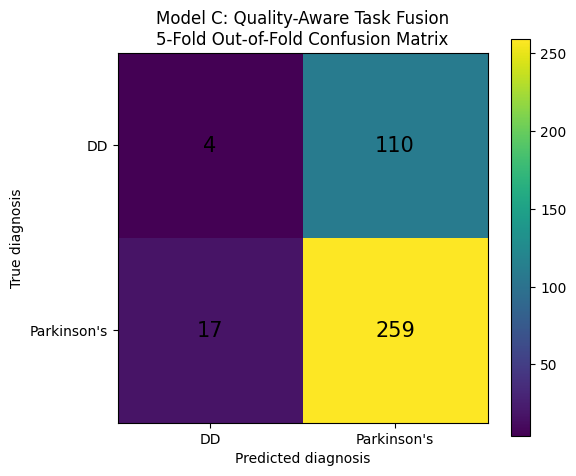

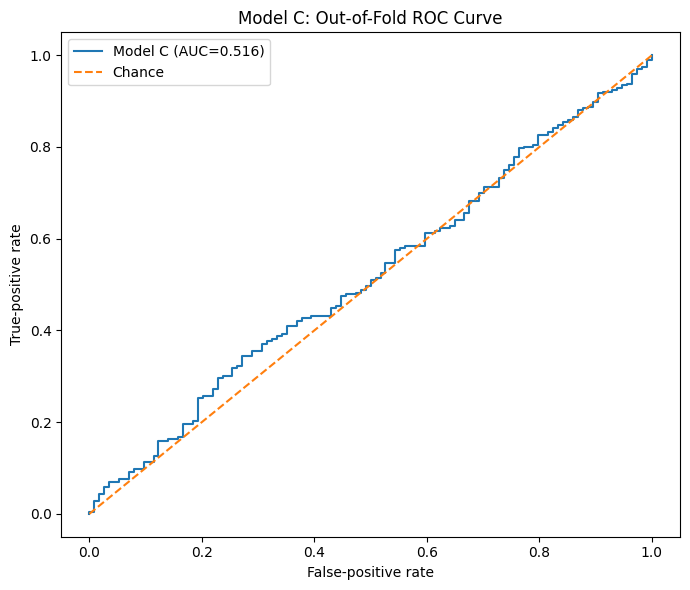

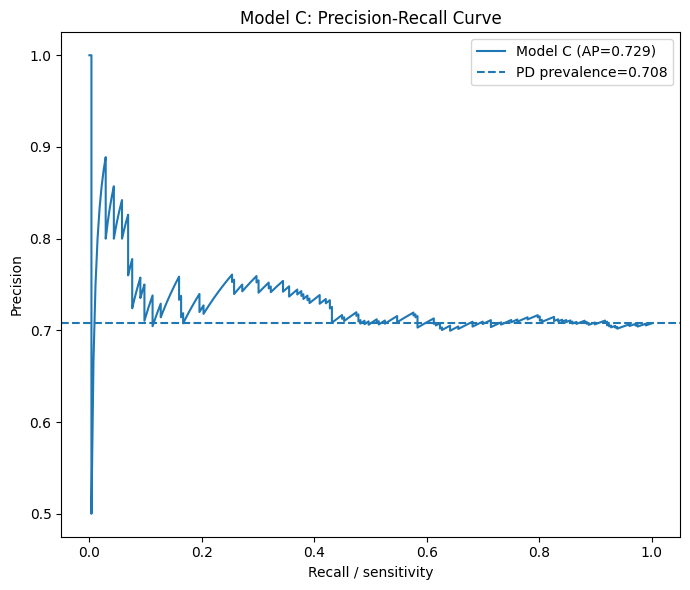

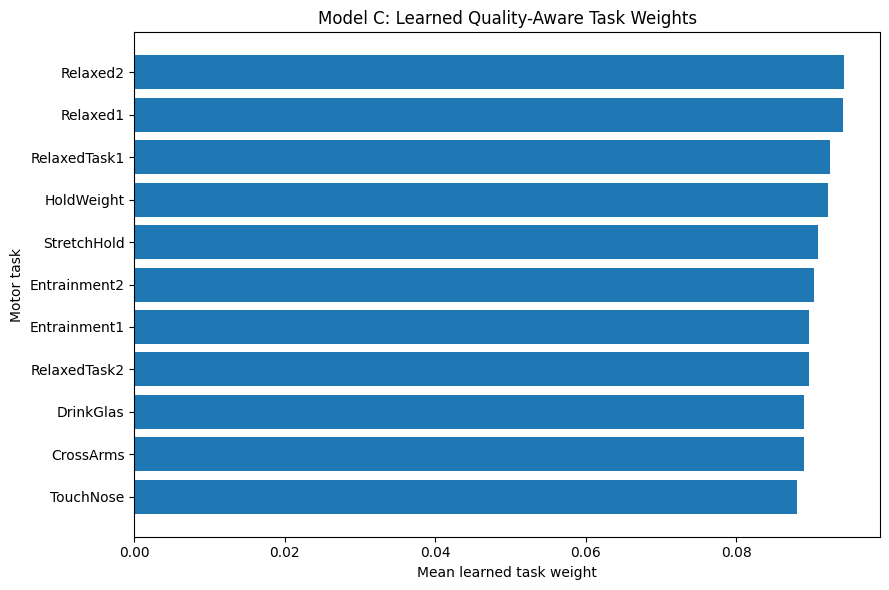

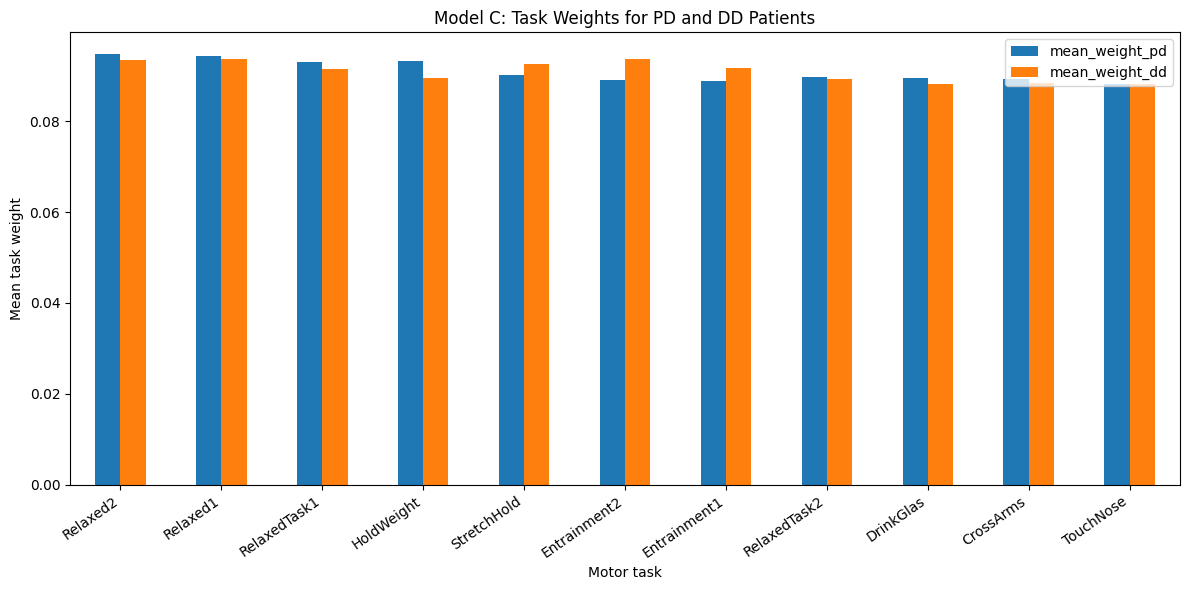

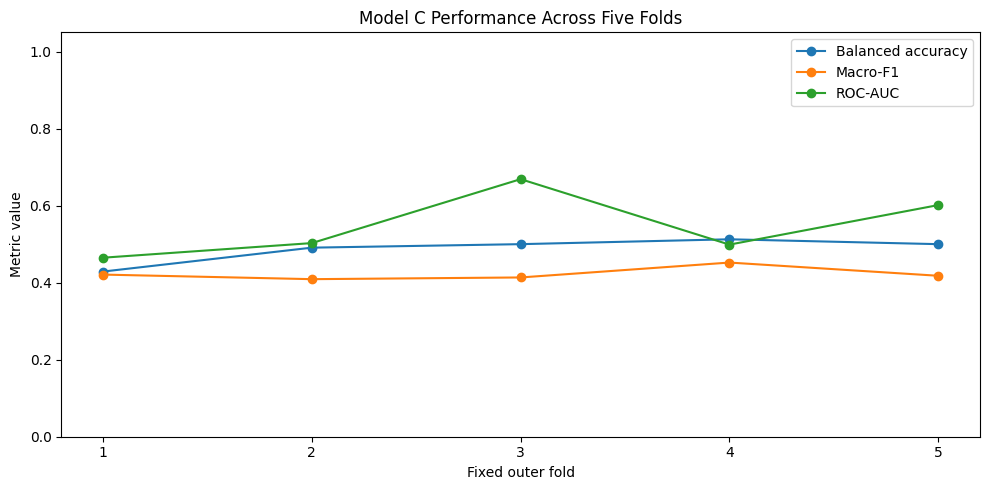

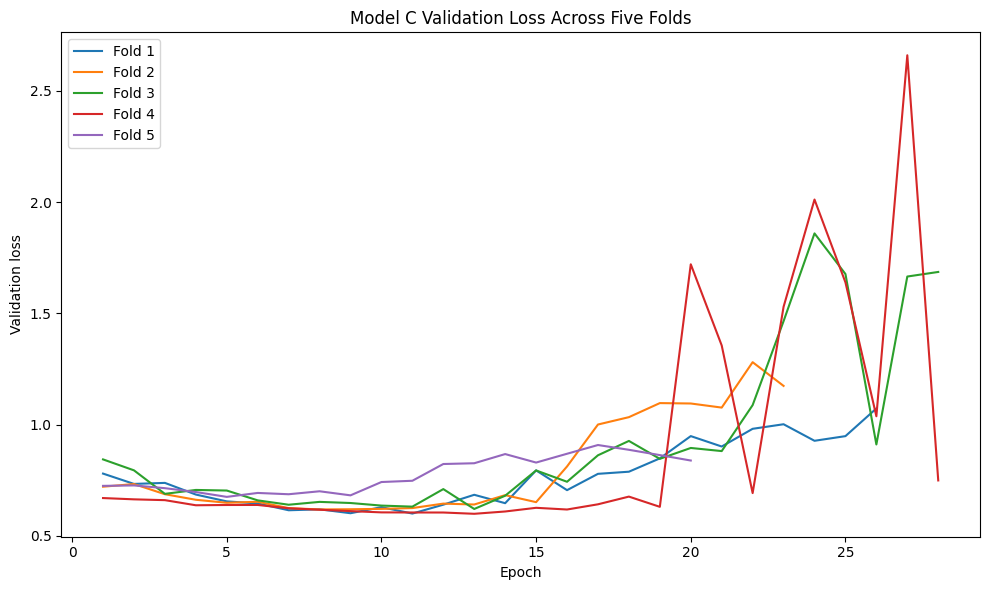


CORRECTED MODEL C TRAINING COMPLETE

Out-of-fold classification report:

                        precision    recall  f1-score   support

Differential Diagnosis     0.1905    0.0351    0.0593       114
           Parkinson's     0.7019    0.9384    0.8031       276

              accuracy                         0.6744       390
             macro avg     0.4462    0.4867    0.4312       390
          weighted avg     0.5524    0.6744    0.5857       390


Overall metrics:

accuracy                 : 0.6744
balanced_accuracy        : 0.4867
macro_f1                 : 0.4312
pd_f1                    : 0.8031
dd_f1                    : 0.0593
precision_pd             : 0.7019
sensitivity_pd           : 0.9384
specificity_dd           : 0.0351
roc_auc                  : 0.5164
pr_auc                   : 0.7291
brier_score              : 0.2232
ece_10_bins              : 0.0728
true_negative            : 4
false_positive           : 110
false_negative           : 17
true_positive         

In [ ]:
# ================================================================================================
# MODEL C — CORRECTED QUALITY-AWARE TASK-FUSION GPU 1D-CNN
# COMPLETE ONE-CELL CODE
# TensorFlow 2.20 / Keras 3 compatible
# Same fixed 5 patient-level folds | Maximum 100 epochs | Full evaluation
# ================================================================================================

import os
import gc
import sys
import time
import random
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# ================================================================================================
# 1. TENSORFLOW, GPU AND REPRODUCIBILITY
# ================================================================================================

try:
    import tensorflow as tf
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "tensorflow"
    ])
    import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedShuffleSplit,
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

print("=" * 110)
print("MODEL C — CORRECTED QUALITY-AWARE TASK-FUSION 1D-CNN")
print("=" * 110)
print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

if not gpus:
    raise RuntimeError(
        "GPU detect nahi hui.\n"
        "Google Colab: Runtime → Change runtime type → T4 GPU."
    )

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

try:
    GPU_NAME = (
        tf.config.experimental
        .get_device_details(gpus[0])
        .get("device_name", "GPU")
    )
except Exception:
    GPU_NAME = "GPU detected"

print("Detected GPU:", GPU_NAME)

try:
    keras.mixed_precision.set_global_policy("mixed_float16")
except Exception:
    keras.mixed_precision.set_global_policy("float32")

print("Precision policy:", keras.mixed_precision.global_policy())

GLOBAL_SEED = 42

random.seed(int(GLOBAL_SEED))
np.random.seed(int(GLOBAL_SEED))
tf.keras.utils.set_random_seed(int(GLOBAL_SEED))

try:
    tf.config.experimental.enable_op_determinism()
    print("Deterministic TensorFlow operations enabled.")
except Exception:
    print("Full TensorFlow determinism unavailable.")

# ================================================================================================
# 2. PATHS
# ================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = BASE_DIR / "project_ready_data"
FEATURE_DIR = PROJECT_DIR / "feature_engineering"
BASELINE_DIR = PROJECT_DIR / "baseline_results"
PROPOSED_DIR = PROJECT_DIR / "proposed_model_results"

TASKWISE_FILE = (
    FEATURE_DIR
    / "pads_pd_dd_taskwise.npz"
)

FIXED_SPLIT_FILE = (
    BASELINE_DIR
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

SIMPLE_CNN_DIR = (
    BASELINE_DIR
    / "simple_1dcnn_gpu_5fold"
)

SIMPLE_CNN_SUMMARY_FILE = (
    SIMPLE_CNN_DIR
    / "overall_summary.csv"
)

SIMPLE_CNN_PREDICTIONS_FILE = (
    SIMPLE_CNN_DIR
    / "patient_predictions.csv"
)

OUTPUT_DIR = (
    PROPOSED_DIR
    / "model_c_quality_aware_task_fusion_corrected_5fold"
)

FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
HISTORY_DIR = OUTPUT_DIR / "training_histories"

for folder in [
    OUTPUT_DIR,
    FIGURE_DIR,
    MODEL_DIR,
    HISTORY_DIR,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

if not TASKWISE_FILE.exists():
    taskwise_matches = list(
        BASE_DIR.rglob(
            "pads_pd_dd_taskwise.npz"
        )
    )

    if not taskwise_matches:
        raise FileNotFoundError(
            "pads_pd_dd_taskwise.npz file nahi mili."
        )

    TASKWISE_FILE = taskwise_matches[0]

print("\nTask-wise file :", TASKWISE_FILE)
print("Fixed folds    :", FIXED_SPLIT_FILE)
print("Output folder  :", OUTPUT_DIR)

# ================================================================================================
# 3. LOAD TASK-WISE DATA
# ================================================================================================

npz = np.load(
    TASKWISE_FILE,
    allow_pickle=True
)

required_keys = {
    "X_tasks",
    "y",
    "patient_ids",
}

missing_keys = required_keys - set(npz.files)

if missing_keys:
    raise ValueError(
        f"NPZ keys missing hain: {missing_keys}"
    )

X_all = np.asarray(
    npz["X_tasks"],
    dtype=np.float32
)

y = np.asarray(
    npz["y"],
    dtype=np.int32
)

patient_ids = np.array([
    str(patient_id).zfill(3)
    for patient_id
    in npz["patient_ids"].astype(str)
])

if "task_names" in npz.files:
    task_names = np.asarray(
        npz["task_names"]
    ).astype(str)
else:
    task_names = np.array([
        f"Task_{index + 1}"
        for index in range(X_all.shape[1])
    ])

if X_all.ndim != 4:
    raise ValueError(
        f"Expected four-dimensional X_tasks; found {X_all.shape}"
    )

N_PATIENTS = int(X_all.shape[0])
N_TASKS = int(X_all.shape[1])
N_TIMEPOINTS = int(X_all.shape[2])
N_CHANNELS = int(X_all.shape[3])

if N_CHANNELS != 12:
    raise ValueError(
        f"Expected 12 channels per task; found {N_CHANNELS}."
    )

if N_PATIENTS != len(y):
    raise ValueError(
        "Patient and target counts do not match."
    )

if len(np.unique(patient_ids)) != N_PATIENTS:
    raise ValueError(
        "Duplicate patient IDs detected."
    )

print("\nInput tensor:", X_all.shape)
print("Patients    :", N_PATIENTS)
print("PD          :", int(np.sum(y == 1)))
print("DD          :", int(np.sum(y == 0)))
print("Tasks       :", N_TASKS)
print("Timepoints  :", N_TIMEPOINTS)
print("Channels    :", N_CHANNELS)

print("\nMotor tasks:")

for task_index, task_name in enumerate(
    task_names,
    start=1
):
    print(
        f"{task_index:2d}. {task_name}"
    )

# ================================================================================================
# 4. LOAD OR RECREATE SAME FIXED FIVE FOLDS
# ================================================================================================

if FIXED_SPLIT_FILE.exists():

    fixed_splits = pd.read_csv(
        FIXED_SPLIT_FILE,
        dtype={"patient_id": str}
    )

    fixed_splits["patient_id"] = (
        fixed_splits["patient_id"]
        .astype(str)
        .str.zfill(3)
    )

    fixed_splits["role"] = (
        fixed_splits["role"]
        .astype(str)
        .str.lower()
        .str.strip()
    )

else:

    print(
        "\nFixed-fold file missing; recreating original folds."
    )

    FIXED_SPLIT_FILE.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    splitter = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    split_rows = []
    dummy_X = np.zeros(
        (N_PATIENTS, 1),
        dtype=np.float32
    )

    for fold_number, (
        train_indices,
        test_indices
    ) in enumerate(
        splitter.split(dummy_X, y),
        start=1
    ):

        for index in train_indices:
            split_rows.append({
                "patient_id": patient_ids[index],
                "fold": int(fold_number),
                "role": "train",
                "true_label": int(y[index]),
            })

        for index in test_indices:
            split_rows.append({
                "patient_id": patient_ids[index],
                "fold": int(fold_number),
                "role": "test",
                "true_label": int(y[index]),
            })

    fixed_splits = pd.DataFrame(
        split_rows
    )

    fixed_splits.to_csv(
        FIXED_SPLIT_FILE,
        index=False
    )

fixed_splits["fold"] = (
    pd.to_numeric(
        fixed_splits["fold"],
        errors="raise"
    )
    .astype(int)
)

available_folds = [
    int(value)
    for value in sorted(
        fixed_splits["fold"].unique()
    )
]

if available_folds != [1, 2, 3, 4, 5]:
    raise ValueError(
        f"Expected folds 1–5; found {available_folds}"
    )

if set(fixed_splits["patient_id"]) != set(patient_ids):
    raise ValueError(
        "Fixed-fold IDs and NPZ patient IDs do not match."
    )

test_counts = (
    fixed_splits.loc[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if (
    len(test_counts) != N_PATIENTS
    or not (test_counts == 1).all()
):
    raise ValueError(
        "Every patient must be an outer-test patient exactly once."
    )

patient_to_index = {
    patient_id: index
    for index, patient_id
    in enumerate(patient_ids)
}

print("\n✅ Same fixed five outer folds verified.")

# ================================================================================================
# 5. LABEL-FREE TASK QUALITY FEATURES
# ================================================================================================

QUALITY_FEATURE_NAMES = [
    "finite_ratio",
    "flat_ratio",
    "spike_ratio",
    "log_variability",
    "technical_quality",
]

N_QUALITY_FEATURES = int(
    len(QUALITY_FEATURE_NAMES)
)

QUALITY_CACHE_FILE = (
    OUTPUT_DIR
    / "task_quality_features.npy"
)


def extract_task_quality_features(
    X
):
    quality = np.zeros(
        (
            X.shape[0],
            X.shape[1],
            N_QUALITY_FEATURES
        ),
        dtype=np.float32
    )

    epsilon = 1e-6

    print("\nExtracting task-quality indicators...")

    for patient_index in range(
        X.shape[0]
    ):

        for task_index in range(
            X.shape[1]
        ):

            signal = np.asarray(
                X[
                    patient_index,
                    task_index
                ],
                dtype=np.float64
            )

            finite_mask = np.isfinite(
                signal
            )

            finite_ratio = float(
                np.mean(finite_mask)
            )

            if finite_ratio <= 0:
                quality[
                    patient_index,
                    task_index
                ] = [
                    0.0,
                    1.0,
                    1.0,
                    0.0,
                    0.0,
                ]

                continue

            signal_nan = np.where(
                finite_mask,
                signal,
                np.nan
            )

            channel_medians = np.nanmedian(
                signal_nan,
                axis=0,
                keepdims=True
            )

            channel_medians = np.where(
                np.isfinite(channel_medians),
                channel_medians,
                0.0
            )

            clean_signal = np.where(
                finite_mask,
                signal,
                channel_medians
            )

            differences = np.diff(
                clean_signal,
                axis=0
            )

            difference_scale = np.median(
                np.abs(differences),
                axis=0,
                keepdims=True
            )

            flat_threshold = np.maximum(
                difference_scale * 0.01,
                epsilon
            )

            flat_ratio = float(
                np.mean(
                    np.abs(differences)
                    <= flat_threshold
                )
            )

            channel_median = np.median(
                clean_signal,
                axis=0,
                keepdims=True
            )

            channel_mad = np.median(
                np.abs(
                    clean_signal
                    - channel_median
                ),
                axis=0,
                keepdims=True
            )

            robust_z = (
                np.abs(
                    clean_signal
                    - channel_median
                )
                / (
                    1.4826
                    * channel_mad
                    + epsilon
                )
            )

            spike_ratio = float(
                np.mean(
                    robust_z > 8.0
                )
            )

            channel_std = np.std(
                clean_signal,
                axis=0
            )

            variability = float(
                np.median(channel_std)
            )

            log_variability = float(
                np.log1p(
                    max(
                        variability,
                        0.0
                    )
                )
            )

            technical_quality = float(
                np.clip(
                    finite_ratio
                    * (
                        1.0
                        - min(
                            flat_ratio,
                            1.0
                        )
                    )
                    * (
                        1.0
                        - min(
                            spike_ratio,
                            1.0
                        )
                    ),
                    0.0,
                    1.0
                )
            )

            quality[
                patient_index,
                task_index
            ] = [
                finite_ratio,
                flat_ratio,
                spike_ratio,
                log_variability,
                technical_quality,
            ]

        if (
            (patient_index + 1) % 50 == 0
            or patient_index + 1
            == X.shape[0]
        ):
            print(
                f"Processed quality: "
                f"{patient_index + 1}/{X.shape[0]}"
            )

    return quality


if QUALITY_CACHE_FILE.exists():

    task_quality_all = np.load(
        QUALITY_CACHE_FILE
    ).astype(np.float32)

    expected_quality_shape = (
        N_PATIENTS,
        N_TASKS,
        N_QUALITY_FEATURES
    )

    if (
        task_quality_all.shape
        != expected_quality_shape
        or not np.isfinite(
            task_quality_all
        ).all()
    ):

        print(
            "Cached quality file invalid; recalculating."
        )

        task_quality_all = (
            extract_task_quality_features(
                X_all
            )
        )

        np.save(
            QUALITY_CACHE_FILE,
            task_quality_all
        )

else:

    task_quality_all = (
        extract_task_quality_features(
            X_all
        )
    )

    np.save(
        QUALITY_CACHE_FILE,
        task_quality_all
    )

print(
    "\nTask-quality tensor:",
    task_quality_all.shape
)

quality_summary_rows = []

for task_index, task_name in enumerate(
    task_names
):

    for quality_index, quality_name in enumerate(
        QUALITY_FEATURE_NAMES
    ):

        values = task_quality_all[
            :,
            task_index,
            quality_index
        ]

        quality_summary_rows.append({
            "task": task_name,
            "quality_feature": quality_name,
            "mean": float(
                np.mean(values)
            ),
            "std": float(
                np.std(values)
            ),
            "minimum": float(
                np.min(values)
            ),
            "maximum": float(
                np.max(values)
            ),
        })

quality_summary_df = pd.DataFrame(
    quality_summary_rows
)

quality_summary_df.to_csv(
    OUTPUT_DIR
    / "task_quality_feature_summary.csv",
    index=False
)

technical_quality_index = (
    QUALITY_FEATURE_NAMES.index(
        "technical_quality"
    )
)

print("\nMean technical quality by task:")

for task_index, task_name in enumerate(
    task_names
):

    print(
        f"{task_name:20s}: "
        f"{np.mean(task_quality_all[:, task_index, technical_quality_index]):.4f}"
    )

# ================================================================================================
# 6. METRICS
# ================================================================================================

def expected_calibration_error(
    y_true,
    probabilities,
    n_bins=10
):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(
        probabilities
    )

    edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(
        n_bins
    ):

        lower = edges[bin_index]
        upper = edges[
            bin_index + 1
        ]

        if bin_index == n_bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if not np.any(mask):
            continue

        observed = float(
            np.mean(y_true[mask])
        )

        predicted = float(
            np.mean(
                probabilities[mask]
            )
        )

        ece += float(
            np.mean(mask)
        ) * abs(
            observed - predicted
        )

    return float(ece)


def calculate_metrics(
    y_true,
    predictions,
    probabilities
):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions
        ),

        "macro_f1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "pd_f1": f1_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "dd_f1": f1_score(
            y_true,
            predictions,
            pos_label=0,
            zero_division=0
        ),

        "precision_pd": precision_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "sensitivity_pd": (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        ),

        "specificity_dd": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "roc_auc": roc_auc_score(
            y_true,
            probabilities
        ),

        "pr_auc": average_precision_score(
            y_true,
            probabilities
        ),

        "brier_score": brier_score_loss(
            y_true,
            probabilities
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            probabilities,
            n_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

# ================================================================================================
# 7. FOLD-SPECIFIC NORMALIZATION
# ================================================================================================

def fit_signal_normalization(
    X_train
):
    finite = np.where(
        np.isfinite(X_train),
        X_train,
        np.nan
    )

    mean = np.nanmean(
        finite,
        axis=(0, 1, 2),
        keepdims=True
    )

    std = np.nanstd(
        finite,
        axis=(0, 1, 2),
        keepdims=True
    )

    mean = np.where(
        np.isfinite(mean),
        mean,
        0.0
    ).astype(np.float32)

    std = np.where(
        np.isfinite(std)
        & (std > 1e-6),
        std,
        1.0
    ).astype(np.float32)

    return mean, std


def transform_signals(
    X,
    mean,
    std
):
    clean = np.where(
        np.isfinite(X),
        X,
        mean
    )

    normalized = (
        clean - mean
    ) / std

    return np.clip(
        normalized,
        -10.0,
        10.0
    ).astype(np.float32)


def fit_quality_normalization(
    Q_train
):
    mean = np.mean(
        Q_train,
        axis=(0, 1),
        keepdims=True
    )

    std = np.std(
        Q_train,
        axis=(0, 1),
        keepdims=True
    )

    std = np.where(
        std > 1e-6,
        std,
        1.0
    )

    return (
        mean.astype(np.float32),
        std.astype(np.float32)
    )


def transform_quality(
    Q,
    mean,
    std
):
    normalized = (
        Q - mean
    ) / std

    return np.clip(
        normalized,
        -10.0,
        10.0
    ).astype(np.float32)

# ================================================================================================
# 8. MODEL C ARCHITECTURE
# ================================================================================================

def build_quality_aware_model(
    number_of_tasks,
    number_of_timepoints,
    number_of_channels,
    number_of_quality_features,
    task_embedding_dimension=128,
    learning_rate=1e-3
):

    # Shared encoder for one task
    single_task_input = keras.Input(
        shape=(
            number_of_timepoints,
            number_of_channels
        ),
        name="single_task_signal"
    )

    x = layers.Conv1D(
        32,
        kernel_size=7,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name="task_conv1"
    )(single_task_input)

    x = layers.BatchNormalization(
        name="task_bn1"
    )(x)

    x = layers.Activation(
        "relu",
        name="task_relu1"
    )(x)

    x = layers.MaxPooling1D(
        pool_size=2,
        name="task_pool1"
    )(x)

    x = layers.Conv1D(
        64,
        kernel_size=5,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name="task_conv2"
    )(x)

    x = layers.BatchNormalization(
        name="task_bn2"
    )(x)

    x = layers.Activation(
        "relu",
        name="task_relu2"
    )(x)

    x = layers.MaxPooling1D(
        pool_size=2,
        name="task_pool2"
    )(x)

    x = layers.Conv1D(
        128,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name="task_conv3"
    )(x)

    x = layers.BatchNormalization(
        name="task_bn3"
    )(x)

    x = layers.Activation(
        "relu",
        name="task_relu3"
    )(x)

    x = layers.GlobalAveragePooling1D(
        name="task_global_pool"
    )(x)

    task_embedding = layers.Dense(
        task_embedding_dimension,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(
            1e-4
        ),
        name="task_embedding"
    )(x)

    shared_task_encoder = keras.Model(
        inputs=single_task_input,
        outputs=task_embedding,
        name="shared_task_encoder"
    )

    # Full patient inputs
    signal_input = keras.Input(
        shape=(
            number_of_tasks,
            number_of_timepoints,
            number_of_channels
        ),
        name="patient_task_signals"
    )

    quality_input = keras.Input(
        shape=(
            number_of_tasks,
            number_of_quality_features
        ),
        name="patient_task_quality"
    )

    # (B,T,L,C) → (B*T,L,C)
    flattened_signals = layers.Lambda(
        lambda tensor: tf.reshape(
            tensor,
            (
                -1,
                number_of_timepoints,
                number_of_channels
            )
        ),
        output_shape=(
            number_of_timepoints,
            number_of_channels
        ),
        name="merge_batch_task_dimensions"
    )(signal_input)

    flattened_embeddings = (
        shared_task_encoder(
            flattened_signals
        )
    )

    # (B*T,E) → (B,T,E)
    task_embeddings = layers.Lambda(
        lambda tensors: tf.reshape(
            tensors[0],
            (
                tf.shape(
                    tensors[1]
                )[0],
                number_of_tasks,
                task_embedding_dimension
            )
        ),
        output_shape=(
            number_of_tasks,
            task_embedding_dimension
        ),
        name="restore_task_dimensions"
    )([
        flattened_embeddings,
        signal_input
    ])

    task_embeddings = layers.Dropout(
        0.15,
        name="task_embedding_dropout"
    )(task_embeddings)

    # Combine task representation and quality features
    attention_input = layers.Concatenate(
        axis=-1,
        name="quality_attention_input"
    )([
        task_embeddings,
        quality_input
    ])

    attention_hidden = layers.Dense(
        64,
        activation="tanh",
        kernel_regularizer=keras.regularizers.l2(
            1e-4
        ),
        name="task_attention_hidden"
    )(attention_input)

    attention_logits = layers.Dense(
        1,
        activation=None,
        name="task_attention_logits"
    )(attention_hidden)

    task_weights = layers.Softmax(
        axis=1,
        name="quality_aware_task_weights"
    )(attention_logits)

    weighted_tasks = layers.Multiply(
        name="weighted_task_embeddings"
    )([
        task_embeddings,
        task_weights
    ])

    patient_embedding = layers.Lambda(
        lambda tensor: tf.reduce_sum(
            tensor,
            axis=1
        ),
        output_shape=(
            task_embedding_dimension,
        ),
        name="weighted_task_fusion"
    )(weighted_tasks)

    z = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(
            1e-4
        ),
        name="patient_dense"
    )(patient_embedding)

    z = layers.Dropout(
        0.40,
        name="patient_dropout"
    )(z)

    probability = layers.Dense(
        1,
        activation="sigmoid",
        dtype="float32",
        name="pd_probability"
    )(z)

    training_model = keras.Model(
        inputs=[
            signal_input,
            quality_input
        ],
        outputs=probability,
        name="model_c_quality_aware_task_fusion"
    )

    weight_extraction_model = keras.Model(
        inputs=[
            signal_input,
            quality_input
        ],
        outputs=[
            probability,
            task_weights
        ],
        name="model_c_probability_and_weights"
    )

    training_model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate,
            clipnorm=1.0
        ),

        loss=keras.losses.BinaryCrossentropy(),

        metrics=[
            keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),

            keras.metrics.AUC(
                name="roc_auc",
                curve="ROC"
            ),

            keras.metrics.AUC(
                name="pr_auc",
                curve="PR"
            ),
        ]
    )

    return (
        training_model,
        weight_extraction_model
    )

# ================================================================================================
# 9. ARCHITECTURE TEST
# ================================================================================================

tf.keras.backend.clear_session()
gc.collect()

test_model, test_weight_model = (
    build_quality_aware_model(
        number_of_tasks=N_TASKS,
        number_of_timepoints=N_TIMEPOINTS,
        number_of_channels=N_CHANNELS,
        number_of_quality_features=N_QUALITY_FEATURES,
        task_embedding_dimension=128,
        learning_rate=1e-3
    )
)

MODEL_PARAMETER_COUNT = int(
    test_model.count_params()
)

test_model.summary(
    expand_nested=True
)

dummy_signal = np.zeros(
    (
        2,
        N_TASKS,
        N_TIMEPOINTS,
        N_CHANNELS
    ),
    dtype=np.float32
)

dummy_quality = np.zeros(
    (
        2,
        N_TASKS,
        N_QUALITY_FEATURES
    ),
    dtype=np.float32
)

dummy_probability, dummy_weights = (
    test_weight_model.predict(
        [
            dummy_signal,
            dummy_quality
        ],
        verbose=0
    )
)

print("\nArchitecture test:")
print(
    "Probability shape:",
    dummy_probability.shape
)
print(
    "Task-weight shape:",
    dummy_weights.shape
)
print(
    "Task-weight sums:",
    np.sum(
        dummy_weights,
        axis=1
    ).reshape(-1)
)
print(
    "Model parameters:",
    MODEL_PARAMETER_COUNT
)

if dummy_probability.shape != (2, 1):
    raise RuntimeError(
        "Probability output shape is incorrect."
    )

if dummy_weights.shape != (
    2,
    N_TASKS,
    1
):
    raise RuntimeError(
        "Task-weight output shape is incorrect."
    )

if not np.allclose(
    np.sum(
        dummy_weights,
        axis=1
    ),
    1.0,
    atol=1e-5
):
    raise RuntimeError(
        "Task weights do not sum to one."
    )

del (
    test_model,
    test_weight_model,
    dummy_signal,
    dummy_quality,
    dummy_probability,
    dummy_weights
)

tf.keras.backend.clear_session()
gc.collect()

print("\n✅ Corrected Model C architecture test passed.")

# ================================================================================================
# 10. TRAINING CONFIGURATION
# ================================================================================================

MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 16
VALIDATION_FRACTION = 0.20
LEARNING_RATE = 1e-3
THRESHOLD = 0.50
N_BOOTSTRAPS = 2000

print("\nTraining configuration:")
print("Maximum epochs       :", MAX_EPOCHS)
print("Early-stop patience  :", PATIENCE)
print("Batch size           :", BATCH_SIZE)
print("Validation fraction  :", VALIDATION_FRACTION)
print("Learning rate        :", LEARNING_RATE)
print("Prediction threshold :", THRESHOLD)

# ================================================================================================
# 11. OOF STORAGE
# ================================================================================================

oof_probability = np.full(
    N_PATIENTS,
    np.nan,
    dtype=np.float32
)

oof_prediction = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

oof_fold = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

oof_task_weights = np.full(
    (
        N_PATIENTS,
        N_TASKS
    ),
    np.nan,
    dtype=np.float32
)

fold_rows = []
training_rows = []
assignment_rows = []
normalization_rows = []

total_start_time = time.time()

print("\n" + "=" * 110)
print("STARTING CORRECTED MODEL C FIXED FIVE-FOLD TRAINING")
print("=" * 110)

# ================================================================================================
# 12. FIVE-FOLD TRAINING
# ================================================================================================

for raw_fold_number in available_folds:

    # Critical correction:
    # convert NumPy/Pandas integer into native Python int.
    fold_number = int(
        raw_fold_number
    )

    fold_start_time = time.time()

    tf.keras.backend.clear_session()
    gc.collect()

    fold_seed = int(
        GLOBAL_SEED
        + fold_number
    )

    random.seed(
        int(fold_seed)
    )

    np.random.seed(
        int(fold_seed)
    )

    tf.keras.utils.set_random_seed(
        int(fold_seed)
    )

    fold_table = fixed_splits.loc[
        fixed_splits["fold"]
        == fold_number
    ]

    outer_train_ids = fold_table.loc[
        fold_table["role"] == "train",
        "patient_id"
    ].tolist()

    outer_test_ids = fold_table.loc[
        fold_table["role"] == "test",
        "patient_id"
    ].tolist()

    train_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id
        in outer_train_ids
    ], dtype=int)

    test_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id
        in outer_test_ids
    ], dtype=int)

    if set(train_indices).intersection(
        set(test_indices)
    ):
        raise RuntimeError(
            f"Outer leakage in fold {fold_number}."
        )

    y_outer_train = y[
        train_indices
    ]

    y_test = y[
        test_indices
    ]

    validation_splitter = StratifiedShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_FRACTION,
        random_state=int(fold_seed)
    )

    relative_train, relative_validation = next(
        validation_splitter.split(
            np.zeros(
                len(train_indices),
                dtype=np.float32
            ),
            y_outer_train
        )
    )

    subtrain_indices = train_indices[
        relative_train
    ]

    validation_indices = train_indices[
        relative_validation
    ]

    if (
        set(subtrain_indices).intersection(
            set(validation_indices)
        )
        or set(subtrain_indices).intersection(
            set(test_indices)
        )
        or set(validation_indices).intersection(
            set(test_indices)
        )
    ):
        raise RuntimeError(
            f"Data leakage in fold {fold_number}."
        )

    for index in subtrain_indices:
        assignment_rows.append({
            "fold": fold_number,
            "patient_id": patient_ids[index],
            "role": "subtrain",
            "true_label": int(y[index]),
        })

    for index in validation_indices:
        assignment_rows.append({
            "fold": fold_number,
            "patient_id": patient_ids[index],
            "role": "validation",
            "true_label": int(y[index]),
        })

    for index in test_indices:
        assignment_rows.append({
            "fold": fold_number,
            "patient_id": patient_ids[index],
            "role": "test",
            "true_label": int(y[index]),
        })

    X_subtrain_raw = X_all[
        subtrain_indices
    ]

    X_validation_raw = X_all[
        validation_indices
    ]

    X_test_raw = X_all[
        test_indices
    ]

    Q_subtrain_raw = task_quality_all[
        subtrain_indices
    ]

    Q_validation_raw = task_quality_all[
        validation_indices
    ]

    Q_test_raw = task_quality_all[
        test_indices
    ]

    y_subtrain = y[
        subtrain_indices
    ]

    y_validation = y[
        validation_indices
    ]

    # Subtraining-only signal normalization
    signal_mean, signal_std = (
        fit_signal_normalization(
            X_subtrain_raw
        )
    )

    X_subtrain = transform_signals(
        X_subtrain_raw,
        signal_mean,
        signal_std
    )

    X_validation = transform_signals(
        X_validation_raw,
        signal_mean,
        signal_std
    )

    X_test = transform_signals(
        X_test_raw,
        signal_mean,
        signal_std
    )

    # Subtraining-only quality normalization
    quality_mean, quality_std = (
        fit_quality_normalization(
            Q_subtrain_raw
        )
    )

    Q_subtrain = transform_quality(
        Q_subtrain_raw,
        quality_mean,
        quality_std
    )

    Q_validation = transform_quality(
        Q_validation_raw,
        quality_mean,
        quality_std
    )

    Q_test = transform_quality(
        Q_test_raw,
        quality_mean,
        quality_std
    )

    for quality_index, quality_name in enumerate(
        QUALITY_FEATURE_NAMES
    ):
        normalization_rows.append({
            "fold": fold_number,
            "quality_feature": quality_name,
            "mean": float(
                quality_mean[
                    0,
                    0,
                    quality_index
                ]
            ),
            "std": float(
                quality_std[
                    0,
                    0,
                    quality_index
                ]
            ),
        })

    class_weight_values = compute_class_weight(
        class_weight="balanced",
        classes=np.array(
            [0, 1],
            dtype=np.int32
        ),
        y=y_subtrain
    )

    class_weights = {
        0: float(
            class_weight_values[0]
        ),
        1: float(
            class_weight_values[1]
        ),
    }

    model, weight_model = (
        build_quality_aware_model(
            number_of_tasks=N_TASKS,
            number_of_timepoints=N_TIMEPOINTS,
            number_of_channels=N_CHANNELS,
            number_of_quality_features=N_QUALITY_FEATURES,
            task_embedding_dimension=128,
            learning_rate=LEARNING_RATE
        )
    )

    fold_weights_file = (
        MODEL_DIR
        / f"model_c_fold_{fold_number}.weights.h5"
    )

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            mode="min",
            restore_best_weights=True,
            verbose=1
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=6,
            min_lr=1e-6,
            mode="min",
            verbose=1
        ),

        keras.callbacks.ModelCheckpoint(
            filepath=str(
                fold_weights_file
            ),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=True,
            verbose=0
        ),

        keras.callbacks.TerminateOnNaN(),
    ]

    print("\n" + "-" * 90)
    print(
        f"OUTER FOLD {fold_number}/5"
    )
    print("-" * 90)

    print(
        f"Subtraining: {len(subtrain_indices)} "
        f"(PD={np.sum(y_subtrain == 1)}, "
        f"DD={np.sum(y_subtrain == 0)})"
    )

    print(
        f"Validation : {len(validation_indices)} "
        f"(PD={np.sum(y_validation == 1)}, "
        f"DD={np.sum(y_validation == 0)})"
    )

    print(
        f"Testing    : {len(test_indices)} "
        f"(PD={np.sum(y_test == 1)}, "
        f"DD={np.sum(y_test == 0)})"
    )

    print(
        "Class weights:",
        class_weights
    )

    history = model.fit(
        x=[
            X_subtrain,
            Q_subtrain
        ],

        y=y_subtrain,

        validation_data=(
            [
                X_validation,
                Q_validation
            ],
            y_validation
        ),

        epochs=MAX_EPOCHS,

        batch_size=BATCH_SIZE,

        class_weight=class_weights,

        callbacks=callbacks,

        shuffle=True,

        verbose=2
    )

    if fold_weights_file.exists():
        model.load_weights(
            fold_weights_file
        )

    history_df = pd.DataFrame(
        history.history
    )

    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )

    history_df.to_csv(
        HISTORY_DIR
        / f"fold_{fold_number}_history.csv",
        index=False
    )

    best_epoch = int(
        history_df[
            "val_loss"
        ].idxmin()
        + 1
    )

    # weight_model and model share the same layer objects.
    test_probabilities, test_task_weights = (
        weight_model.predict(
            [
                X_test,
                Q_test
            ],
            batch_size=BATCH_SIZE,
            verbose=0
        )
    )

    test_probabilities = np.clip(
        test_probabilities.reshape(-1),
        0.0,
        1.0
    ).astype(np.float32)

    test_task_weights = (
        test_task_weights[
            :,
            :,
            0
        ]
        .astype(np.float32)
    )

    task_weight_sums = np.sum(
        test_task_weights,
        axis=1
    )

    if not np.allclose(
        task_weight_sums,
        1.0,
        atol=1e-4
    ):
        raise RuntimeError(
            f"Task weights do not sum to one "
            f"in fold {fold_number}."
        )

    test_predictions = (
        test_probabilities
        >= THRESHOLD
    ).astype(np.int32)

    oof_probability[
        test_indices
    ] = test_probabilities

    oof_prediction[
        test_indices
    ] = test_predictions

    oof_fold[
        test_indices
    ] = fold_number

    oof_task_weights[
        test_indices
    ] = test_task_weights

    fold_metrics = calculate_metrics(
        y_test,
        test_predictions,
        test_probabilities
    )

    fold_seconds = (
        time.time()
        - fold_start_time
    )

    fold_rows.append({
        "fold": fold_number,

        "subtrain_patients": int(
            len(subtrain_indices)
        ),

        "validation_patients": int(
            len(validation_indices)
        ),

        "test_patients": int(
            len(test_indices)
        ),

        "test_pd": int(
            np.sum(y_test == 1)
        ),

        "test_dd": int(
            np.sum(y_test == 0)
        ),

        "dd_class_weight": float(
            class_weights[0]
        ),

        "pd_class_weight": float(
            class_weights[1]
        ),

        "epochs_completed": int(
            len(history_df)
        ),

        "best_epoch": best_epoch,

        "best_validation_loss": float(
            history_df[
                "val_loss"
            ].min()
        ),

        "training_seconds": float(
            fold_seconds
        ),

        **fold_metrics,
    })

    training_rows.append({
        "fold": fold_number,

        "epochs_completed": int(
            len(history_df)
        ),

        "best_epoch": best_epoch,

        "best_validation_loss": float(
            history_df[
                "val_loss"
            ].min()
        ),

        "training_minutes": float(
            fold_seconds / 60
        ),

        "weights_file": str(
            fold_weights_file
        ),
    })

    print("\nFold test results:")
    print(
        f"Balanced accuracy: "
        f"{fold_metrics['balanced_accuracy']:.4f}"
    )
    print(
        f"Macro-F1:          "
        f"{fold_metrics['macro_f1']:.4f}"
    )
    print(
        f"PD sensitivity:    "
        f"{fold_metrics['sensitivity_pd']:.4f}"
    )
    print(
        f"DD specificity:    "
        f"{fold_metrics['specificity_dd']:.4f}"
    )
    print(
        f"ROC-AUC:           "
        f"{fold_metrics['roc_auc']:.4f}"
    )
    print(
        f"PR-AUC:            "
        f"{fold_metrics['pr_auc']:.4f}"
    )

    print("\nMean task weights in this test fold:")

    fold_mean_weights = np.mean(
        test_task_weights,
        axis=0
    )

    for task_name, task_weight in sorted(
        zip(
            task_names,
            fold_mean_weights
        ),
        key=lambda pair: pair[1],
        reverse=True
    ):
        print(
            f"{task_name:20s}: "
            f"{task_weight:.4f}"
        )

    del (
        X_subtrain_raw,
        X_validation_raw,
        X_test_raw,
        Q_subtrain_raw,
        Q_validation_raw,
        Q_test_raw,
        X_subtrain,
        X_validation,
        X_test,
        Q_subtrain,
        Q_validation,
        Q_test,
        model,
        weight_model,
        history,
        history_df,
        test_probabilities,
        test_predictions,
        test_task_weights
    )

    tf.keras.backend.clear_session()
    gc.collect()

total_training_seconds = (
    time.time()
    - total_start_time
)

# ================================================================================================
# 13. VERIFY OOF OUTPUT
# ================================================================================================

if np.isnan(
    oof_probability
).any():
    raise RuntimeError(
        "Some patients did not receive probabilities."
    )

if np.any(
    oof_prediction < 0
):
    raise RuntimeError(
        "Some patients did not receive predictions."
    )

if np.isnan(
    oof_task_weights
).any():
    raise RuntimeError(
        "Some patients did not receive task weights."
    )

if not np.allclose(
    np.sum(
        oof_task_weights,
        axis=1
    ),
    1.0,
    atol=1e-4
):
    raise RuntimeError(
        "Some OOF task-weight rows do not sum to one."
    )

overall_metrics = calculate_metrics(
    y,
    oof_prediction,
    oof_probability
)

# ================================================================================================
# 14. BOOTSTRAP 95% CONFIDENCE INTERVALS
# ================================================================================================

bootstrap_rng = np.random.default_rng(
    int(GLOBAL_SEED)
)

bootstrap_rows = []

for bootstrap_iteration in range(
    N_BOOTSTRAPS
):

    sampled_indices = bootstrap_rng.integers(
        low=0,
        high=N_PATIENTS,
        size=N_PATIENTS
    )

    sampled_y = y[
        sampled_indices
    ]

    if len(
        np.unique(sampled_y)
    ) < 2:
        continue

    bootstrap_metrics = calculate_metrics(
        sampled_y,
        oof_prediction[
            sampled_indices
        ],
        oof_probability[
            sampled_indices
        ]
    )

    bootstrap_metrics[
        "bootstrap_iteration"
    ] = int(
        bootstrap_iteration
    )

    bootstrap_rows.append(
        bootstrap_metrics
    )

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

ci_metric_names = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

ci_rows = []

for metric_name in ci_metric_names:

    values = (
        bootstrap_df[
            metric_name
        ]
        .dropna()
        .to_numpy()
    )

    ci_rows.append({
        "metric": metric_name,

        "value": float(
            overall_metrics[
                metric_name
            ]
        ),

        "ci_95_lower": float(
            np.percentile(
                values,
                2.5
            )
        ),

        "ci_95_upper": float(
            np.percentile(
                values,
                97.5
            )
        ),
    })

confidence_intervals_df = pd.DataFrame(
    ci_rows
)

# ================================================================================================
# 15. TASK-WEIGHT ANALYSIS
# ================================================================================================

patient_task_weight_df = pd.DataFrame(
    oof_task_weights,
    columns=[
        f"weight__{task_name}"
        for task_name
        in task_names
    ]
)

patient_task_weight_df.insert(
    0,
    "outer_fold",
    oof_fold
)

patient_task_weight_df.insert(
    0,
    "true_label",
    y
)

patient_task_weight_df.insert(
    0,
    "patient_id",
    patient_ids
)

patient_task_weight_df.to_csv(
    OUTPUT_DIR
    / "patient_level_task_weights.csv",
    index=False
)

task_weight_summary_rows = []

for task_index, task_name in enumerate(
    task_names
):

    all_weights = oof_task_weights[
        :,
        task_index
    ]

    pd_weights = oof_task_weights[
        y == 1,
        task_index
    ]

    dd_weights = oof_task_weights[
        y == 0,
        task_index
    ]

    task_weight_summary_rows.append({
        "task": task_name,

        "mean_weight_all": float(
            np.mean(all_weights)
        ),

        "std_weight_all": float(
            np.std(all_weights)
        ),

        "mean_weight_pd": float(
            np.mean(pd_weights)
        ),

        "mean_weight_dd": float(
            np.mean(dd_weights)
        ),

        "pd_minus_dd_weight": float(
            np.mean(pd_weights)
            - np.mean(dd_weights)
        ),
    })

task_weight_summary_df = pd.DataFrame(
    task_weight_summary_rows
).sort_values(
    "mean_weight_all",
    ascending=False
)

task_weight_summary_df.to_csv(
    OUTPUT_DIR
    / "task_weight_summary.csv",
    index=False
)

# ================================================================================================
# 16. SAVE PRIMARY RESULTS
# ================================================================================================

fold_results_df = pd.DataFrame(
    fold_rows
)

training_summary_df = pd.DataFrame(
    training_rows
)

assignments_df = pd.DataFrame(
    assignment_rows
)

normalization_df = pd.DataFrame(
    normalization_rows
)

patient_predictions_df = pd.DataFrame({
    "patient_id": patient_ids,

    "true_label": y,

    "true_group": np.where(
        y == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),

    "outer_fold": oof_fold,

    "predicted_probability_pd": (
        oof_probability
    ),

    "predicted_label": (
        oof_prediction
    ),

    "predicted_group": np.where(
        oof_prediction == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),

    "correct_prediction": (
        oof_prediction == y
    ).astype(int),
})

summary_df = pd.DataFrame([{
    "model": (
        "Model C: Quality-Aware Task-Fusion 1D-CNN"
    ),

    "model_stage": "C",

    "input": (
        "Raw 11-task bilateral IMU signals "
        "plus five label-free task-quality indicators"
    ),

    "quality_features": ", ".join(
        QUALITY_FEATURE_NAMES
    ),

    "task_fusion": (
        "Learned softmax quality-aware task weighting"
    ),

    "explicit_bilateral_asymmetry": False,

    "quality_aware_task_fusion": True,

    "adaptive_minimum_task_selection": False,

    "calibrated_referral": False,

    "missing_modality_augmentation": False,

    "patients": N_PATIENTS,

    "pd_patients": int(
        np.sum(y == 1)
    ),

    "dd_patients": int(
        np.sum(y == 0)
    ),

    "outer_folds": 5,

    "maximum_epochs": MAX_EPOCHS,

    "early_stopping_patience": PATIENCE,

    "batch_size": BATCH_SIZE,

    "learning_rate": LEARNING_RATE,

    "classification_threshold": THRESHOLD,

    "model_parameters": MODEL_PARAMETER_COUNT,

    "device": GPU_NAME,

    "mixed_precision": str(
        keras.mixed_precision.global_policy()
    ),

    "normalization": (
        "Subtraining-only signal and quality normalization"
    ),

    "class_balance_method": (
        "Subtraining-only balanced class weights"
    ),

    "oversampling_used": False,

    "total_training_minutes": float(
        total_training_seconds / 60
    ),

    **overall_metrics,
}])

patient_predictions_df.to_csv(
    OUTPUT_DIR
    / "patient_predictions.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR
    / "fold_results.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR
    / "overall_summary.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR
    / "confidence_intervals_95.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR
    / "bootstrap_metrics.csv",
    index=False
)

training_summary_df.to_csv(
    OUTPUT_DIR
    / "training_summary_by_fold.csv",
    index=False
)

assignments_df.to_csv(
    OUTPUT_DIR
    / "subtrain_validation_test_assignments.csv",
    index=False
)

normalization_df.to_csv(
    OUTPUT_DIR
    / "quality_normalization_by_fold.csv",
    index=False
)

# ================================================================================================
# 17. PAIRED COMPARISON WITH SIMPLE 1D-CNN
# ================================================================================================

paired_ci_df = pd.DataFrame()

if SIMPLE_CNN_PREDICTIONS_FILE.exists():

    simple_df = pd.read_csv(
        SIMPLE_CNN_PREDICTIONS_FILE,
        dtype={"patient_id": str}
    )

    simple_df["patient_id"] = (
        simple_df["patient_id"]
        .astype(str)
        .str.zfill(3)
    )

    required_simple_columns = {
        "patient_id",
        "true_label",
        "predicted_label",
        "predicted_probability_pd",
    }

    if required_simple_columns.issubset(
        simple_df.columns
    ):

        paired_df = (
            patient_predictions_df[
                [
                    "patient_id",
                    "true_label",
                    "predicted_label",
                    "predicted_probability_pd",
                ]
            ]
            .rename(columns={
                "predicted_label": (
                    "model_c_label"
                ),

                "predicted_probability_pd": (
                    "model_c_probability"
                ),
            })
            .merge(
                simple_df[
                    [
                        "patient_id",
                        "true_label",
                        "predicted_label",
                        "predicted_probability_pd",
                    ]
                ].rename(columns={
                    "true_label": (
                        "simple_true_label"
                    ),

                    "predicted_label": (
                        "simple_label"
                    ),

                    "predicted_probability_pd": (
                        "simple_probability"
                    ),
                }),

                on="patient_id",

                how="inner"
            )
        )

        if len(paired_df) != N_PATIENTS:
            raise RuntimeError(
                "Simple CNN and Model C patients "
                "could not be paired completely."
            )

        if not np.array_equal(
            paired_df[
                "true_label"
            ].to_numpy(),
            paired_df[
                "simple_true_label"
            ].to_numpy()
        ):
            raise RuntimeError(
                "Simple CNN and Model C true labels differ."
            )

        paired_y = paired_df[
            "true_label"
        ].to_numpy(dtype=int)

        simple_labels = paired_df[
            "simple_label"
        ].to_numpy(dtype=int)

        simple_probabilities = paired_df[
            "simple_probability"
        ].to_numpy(dtype=float)

        model_c_labels = paired_df[
            "model_c_label"
        ].to_numpy(dtype=int)

        model_c_probabilities = paired_df[
            "model_c_probability"
        ].to_numpy(dtype=float)

        simple_metrics = calculate_metrics(
            paired_y,
            simple_labels,
            simple_probabilities
        )

        paired_model_c_metrics = calculate_metrics(
            paired_y,
            model_c_labels,
            model_c_probabilities
        )

        paired_metric_names = [
            "balanced_accuracy",
            "macro_f1",
            "sensitivity_pd",
            "specificity_dd",
            "roc_auc",
            "pr_auc",
            "brier_score",
            "ece_10_bins",
        ]

        paired_rng = np.random.default_rng(
            int(GLOBAL_SEED)
        )

        paired_bootstrap_rows = []

        for bootstrap_iteration in range(
            N_BOOTSTRAPS
        ):

            indices = paired_rng.integers(
                0,
                N_PATIENTS,
                size=N_PATIENTS
            )

            sampled_y = paired_y[
                indices
            ]

            if len(
                np.unique(sampled_y)
            ) < 2:
                continue

            sampled_simple = calculate_metrics(
                sampled_y,
                simple_labels[indices],
                simple_probabilities[indices]
            )

            sampled_model_c = calculate_metrics(
                sampled_y,
                model_c_labels[indices],
                model_c_probabilities[indices]
            )

            row = {
                "bootstrap_iteration": int(
                    bootstrap_iteration
                )
            }

            for metric_name in paired_metric_names:

                row[
                    f"simple_{metric_name}"
                ] = sampled_simple[
                    metric_name
                ]

                row[
                    f"model_c_{metric_name}"
                ] = sampled_model_c[
                    metric_name
                ]

                row[
                    f"delta_{metric_name}"
                ] = (
                    sampled_model_c[
                        metric_name
                    ]
                    - sampled_simple[
                        metric_name
                    ]
                )

            paired_bootstrap_rows.append(
                row
            )

        paired_bootstrap_df = pd.DataFrame(
            paired_bootstrap_rows
        )

        paired_ci_rows = []

        for metric_name in paired_metric_names:

            delta_values = (
                paired_bootstrap_df[
                    f"delta_{metric_name}"
                ]
                .dropna()
                .to_numpy()
            )

            observed_delta = (
                paired_model_c_metrics[
                    metric_name
                ]
                - simple_metrics[
                    metric_name
                ]
            )

            paired_ci_rows.append({
                "metric": metric_name,

                "simple_1dcnn": simple_metrics[
                    metric_name
                ],

                "model_c": paired_model_c_metrics[
                    metric_name
                ],

                "observed_delta": observed_delta,

                "delta_ci_95_lower": float(
                    np.percentile(
                        delta_values,
                        2.5
                    )
                ),

                "delta_ci_95_upper": float(
                    np.percentile(
                        delta_values,
                        97.5
                    )
                ),

                "bootstrap_probability_delta_above_zero": float(
                    np.mean(
                        delta_values > 0
                    )
                ),
            })

        paired_ci_df = pd.DataFrame(
            paired_ci_rows
        )

        paired_df.to_csv(
            OUTPUT_DIR
            / "paired_patient_predictions_with_simple_cnn.csv",
            index=False
        )

        paired_bootstrap_df.to_csv(
            OUTPUT_DIR
            / "paired_bootstrap_with_simple_cnn.csv",
            index=False
        )

        paired_ci_df.to_csv(
            OUTPUT_DIR
            / "paired_delta_confidence_intervals.csv",
            index=False
        )

# ================================================================================================
# 18. FIGURES
# ================================================================================================

# Confusion matrix
confusion = confusion_matrix(
    y,
    oof_prediction,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
plt.imshow(confusion)
plt.colorbar()

plt.xticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.yticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.xlabel("Predicted diagnosis")
plt.ylabel("True diagnosis")

plt.title(
    "Model C: Quality-Aware Task Fusion\n"
    "5-Fold Out-of-Fold Confusion Matrix"
)

for row in range(2):
    for column in range(2):
        plt.text(
            column,
            row,
            str(
                confusion[
                    row,
                    column
                ]
            ),
            ha="center",
            va="center",
            fontsize=15
        )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_confusion_matrix.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ROC curve
fpr, tpr, _ = roc_curve(
    y,
    oof_probability
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=(
        f"Model C "
        f"(AUC={overall_metrics['roc_auc']:.3f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("Model C: Out-of-Fold ROC Curve")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_roc_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Precision-recall curve
precision_values, recall_values, _ = (
    precision_recall_curve(
        y,
        oof_probability
    )
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    label=(
        f"Model C "
        f"(AP={overall_metrics['pr_auc']:.3f})"
    )
)

plt.axhline(
    float(np.mean(y)),
    linestyle="--",
    label=(
        f"PD prevalence="
        f"{np.mean(y):.3f}"
    )
)

plt.xlabel("Recall / sensitivity")
plt.ylabel("Precision")
plt.title("Model C: Precision-Recall Curve")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "03_precision_recall_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Mean task weights
task_plot_df = (
    task_weight_summary_df
    .sort_values(
        "mean_weight_all",
        ascending=True
    )
)

plt.figure(figsize=(9, 6))

plt.barh(
    task_plot_df["task"],
    task_plot_df["mean_weight_all"]
)

plt.xlabel("Mean learned task weight")
plt.ylabel("Motor task")

plt.title(
    "Model C: Learned Quality-Aware Task Weights"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "04_mean_task_weights.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# PD vs DD task weights
group_weight_df = (
    task_weight_summary_df[
        [
            "task",
            "mean_weight_pd",
            "mean_weight_dd",
        ]
    ]
    .set_index("task")
)

plt.figure(figsize=(12, 6))

group_weight_df.plot(
    kind="bar",
    ax=plt.gca()
)

plt.xlabel("Motor task")
plt.ylabel("Mean task weight")

plt.title(
    "Model C: Task Weights for PD and DD Patients"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "05_pd_vs_dd_task_weights.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Fold performance
plt.figure(figsize=(10, 5))

plt.plot(
    fold_results_df["fold"],
    fold_results_df[
        "balanced_accuracy"
    ],
    marker="o",
    label="Balanced accuracy"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df[
        "macro_f1"
    ],
    marker="o",
    label="Macro-F1"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df[
        "roc_auc"
    ],
    marker="o",
    label="ROC-AUC"
)

plt.xlabel("Fixed outer fold")
plt.ylabel("Metric value")
plt.title("Model C Performance Across Five Folds")
plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "06_fold_performance.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Validation-loss curves
plt.figure(figsize=(10, 6))

for fold_number in available_folds:

    history_file = (
        HISTORY_DIR
        / f"fold_{int(fold_number)}_history.csv"
    )

    if history_file.exists():

        history_data = pd.read_csv(
            history_file
        )

        plt.plot(
            history_data["epoch"],
            history_data["val_loss"],
            label=(
                f"Fold {int(fold_number)}"
            )
        )

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Model C Validation Loss Across Five Folds")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "07_validation_loss.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ================================================================================================
# 19. FINAL PRINT
# ================================================================================================

print("\n" + "=" * 110)
print("CORRECTED MODEL C TRAINING COMPLETE")
print("=" * 110)

print("\nOut-of-fold classification report:\n")

print(
    classification_report(
        y,
        oof_prediction,
        target_names=[
            "Differential Diagnosis",
            "Parkinson's"
        ],
        digits=4,
        zero_division=0
    )
)

print("\nOverall metrics:\n")

for metric_name, metric_value in overall_metrics.items():

    if isinstance(
        metric_value,
        (
            float,
            np.floating
        )
    ):
        print(
            f"{metric_name:25s}: "
            f"{metric_value:.4f}"
        )
    else:
        print(
            f"{metric_name:25s}: "
            f"{metric_value}"
        )

print(
    f"\nTotal training time: "
    f"{total_training_seconds / 60:.2f} minutes"
)

print("\nBootstrap 95% confidence intervals:\n")

print(
    confidence_intervals_df
    .round(4)
    .to_string(index=False)
)

print("\nFold-level results:\n")

fold_display_columns = [
    "fold",
    "test_patients",
    "test_pd",
    "test_dd",
    "epochs_completed",
    "best_epoch",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

print(
    fold_results_df[
        fold_display_columns
    ]
    .round(4)
    .to_string(index=False)
)

print("\nLearned task-weight ranking:\n")

print(
    task_weight_summary_df
    .round(4)
    .to_string(index=False)
)

if not paired_ci_df.empty:

    print(
        "\nPaired comparison: "
        "Model C minus Simple 1D-CNN\n"
    )

    print(
        paired_ci_df
        .round(4)
        .to_string(index=False)
    )

print("\nFair-comparison controls:")
print("- Same 390 patients.")
print("- Same fixed five outer folds.")
print("- Each patient tested exactly once.")
print("- Same fold-specific validation strategy.")
print("- Maximum 100 epochs.")
print("- Same batch size and class weighting.")
print("- Signal normalization uses subtraining data only.")
print("- Quality normalization uses subtraining data only.")
print("- Fixed classification threshold of 0.50.")
print("- Same evaluation metrics.")
print("- 2,000 patient-level bootstrap samples.")
print("- No SMOTE or patient duplication.")

print("\nModel C includes:")
print("- Shared task-wise 1D-CNN encoder.")
print("- Five label-free technical quality features.")
print("- Learned softmax task weighting.")
print("- Weighted fusion of all 11 motor tasks.")

print("\nSaved files:")

for saved_path in sorted(
    OUTPUT_DIR.rglob("*")
):
    if saved_path.is_file():
        print(
            " -",
            saved_path.relative_to(
                OUTPUT_DIR
            )
        )

print(
    "\n✅ CORRECTED MODEL C QUALITY-AWARE "
    "TASK-FUSION EXPERIMENT FINISHED."
)

## Model D - nested motor-task selection (NTR-XGB)

MODEL D — NESTED MINIMUM / ADAPTIVE MOTOR-TASK SELECTION
XGBoost version: 3.3.0

GPU check:
✅ XGBoost GPU test successful.

Feature file : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Fixed folds : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Output      : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_d_nested_minimum_task_selection_xgboost
Device      : cuda

Complete feature-table shape: (390, 1486)
Patients: 390
PD      : 276
DD      : 114

Feature counts by motor task:
Relaxed1            : 134 features
Relaxed2            : 134 features
RelaxedTask1        : 134 features
RelaxedTask2        : 134 features
StretchHold         : 134 features
HoldWeight          : 134 features
DrinkGlas           : 134 fe

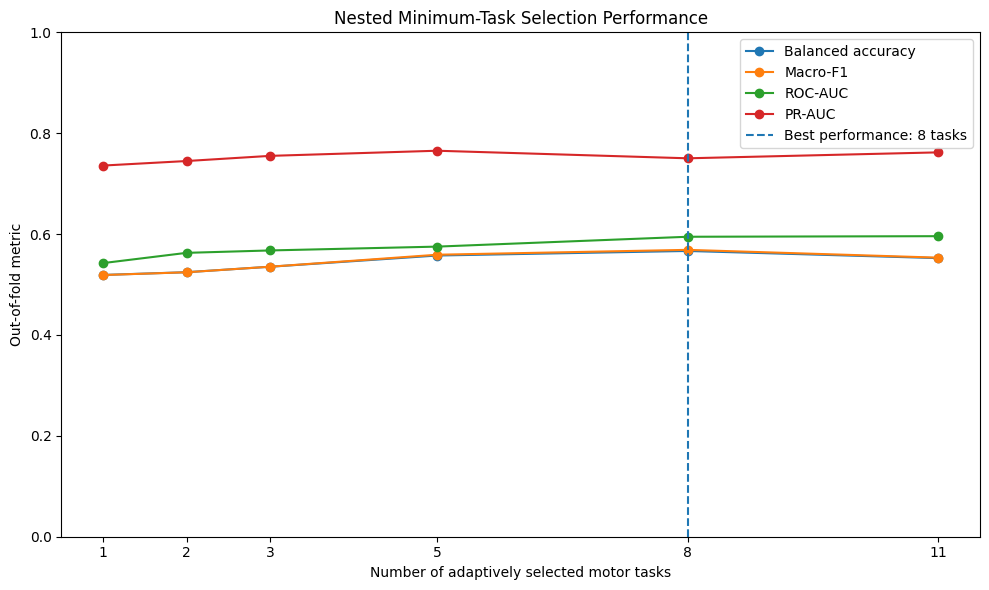

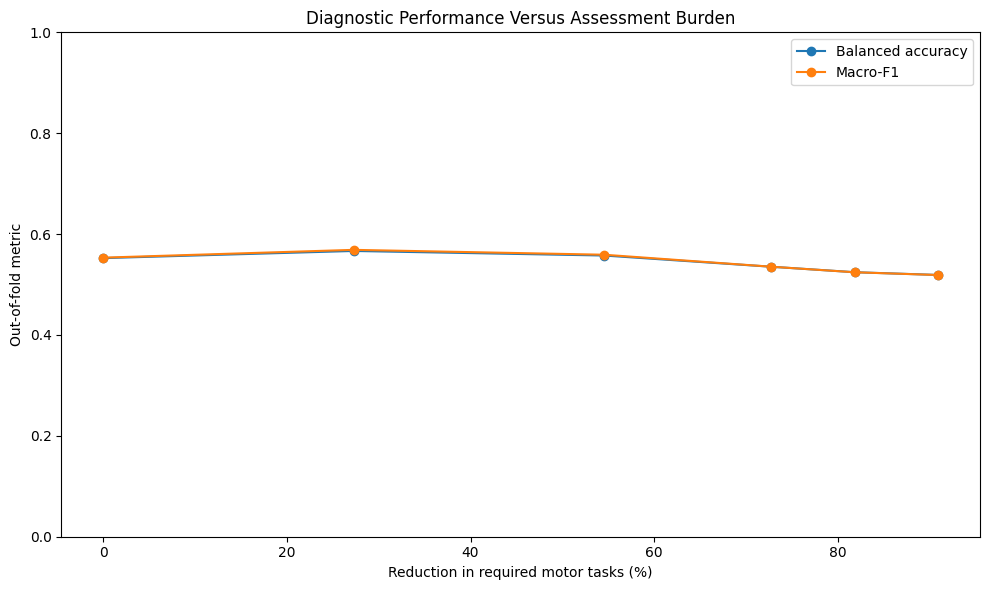

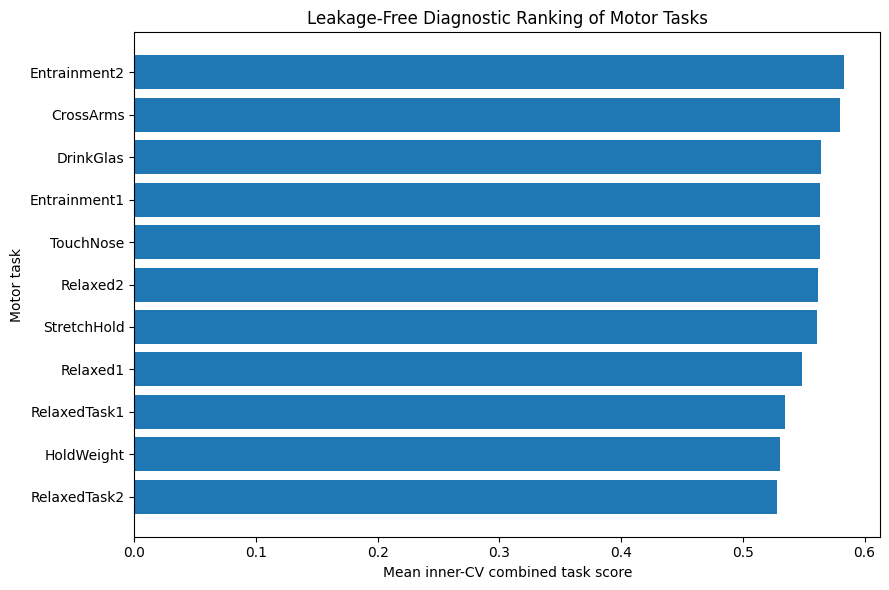

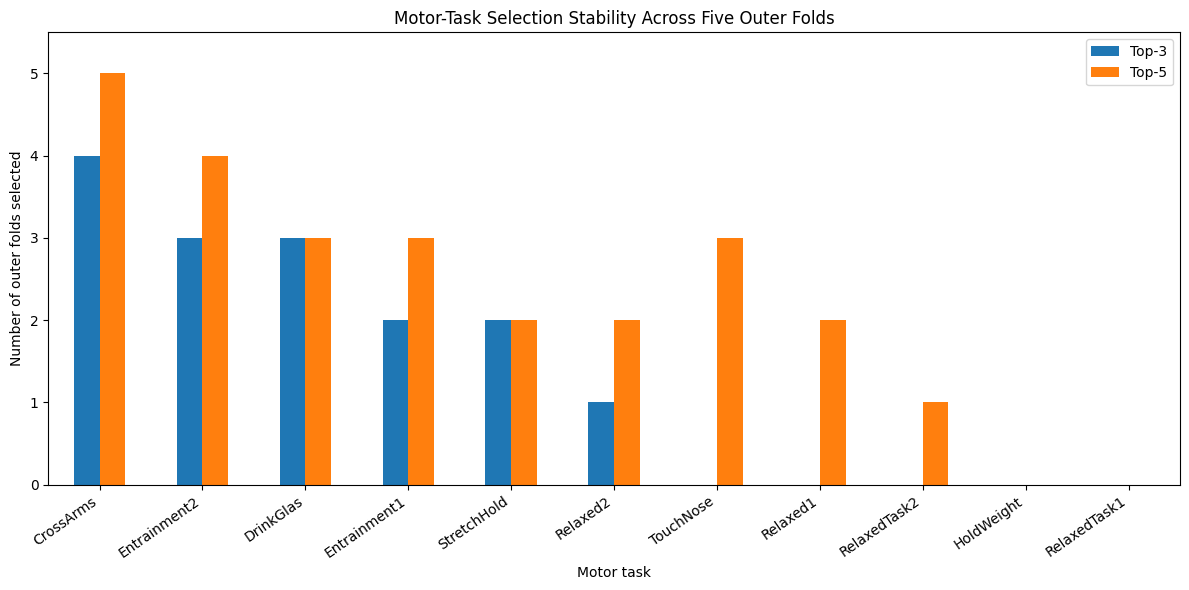

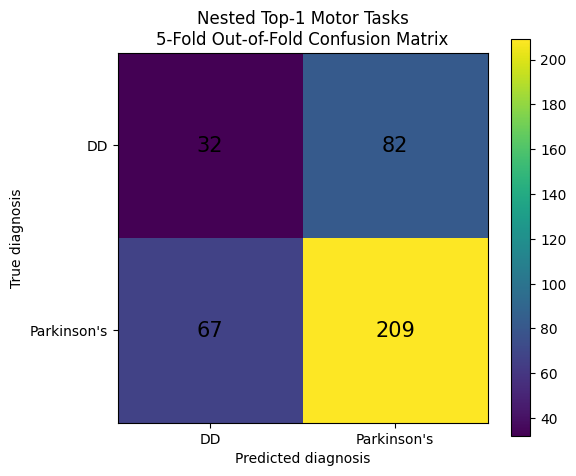

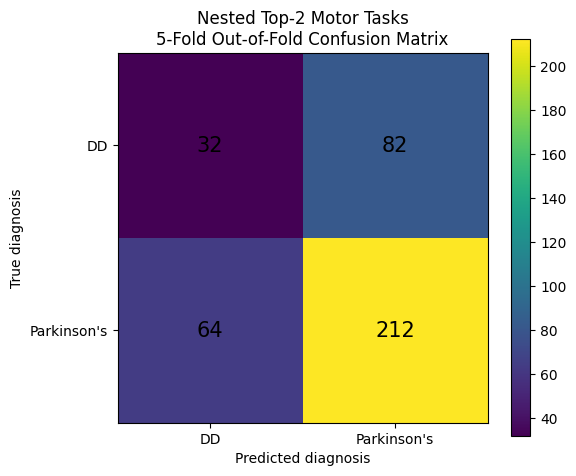

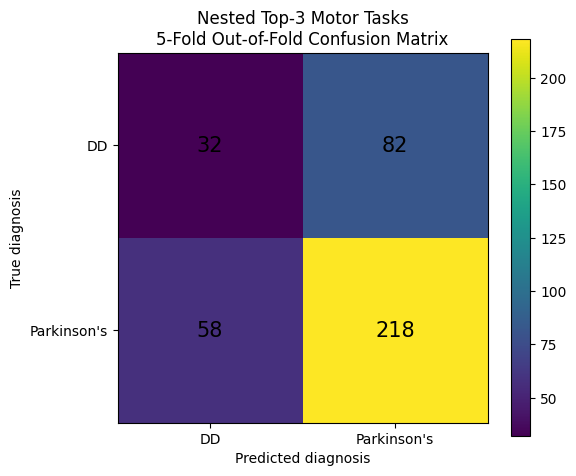

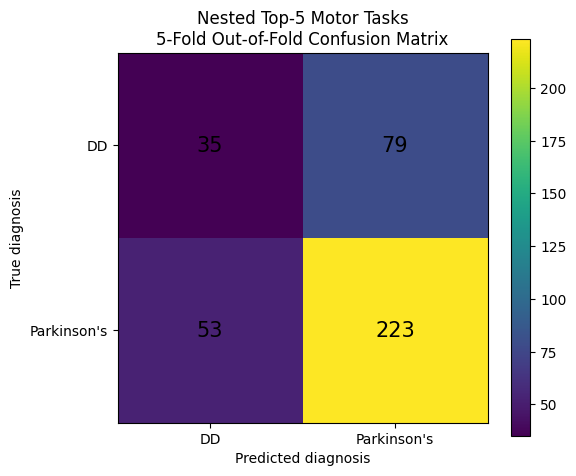

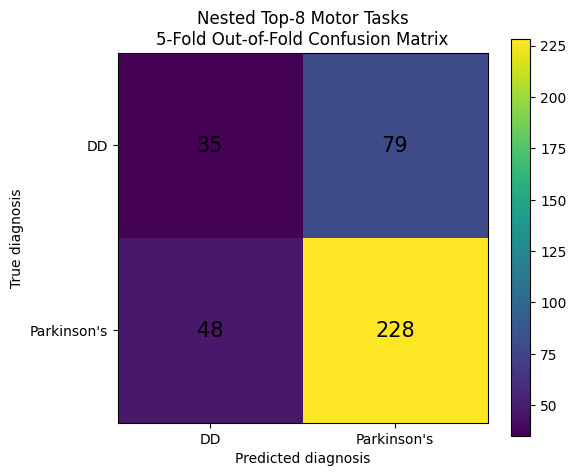

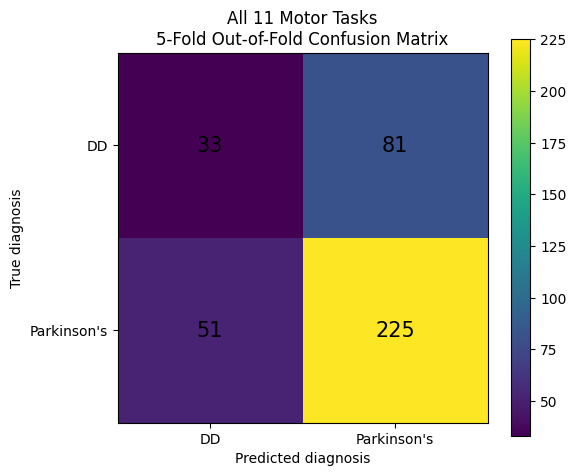

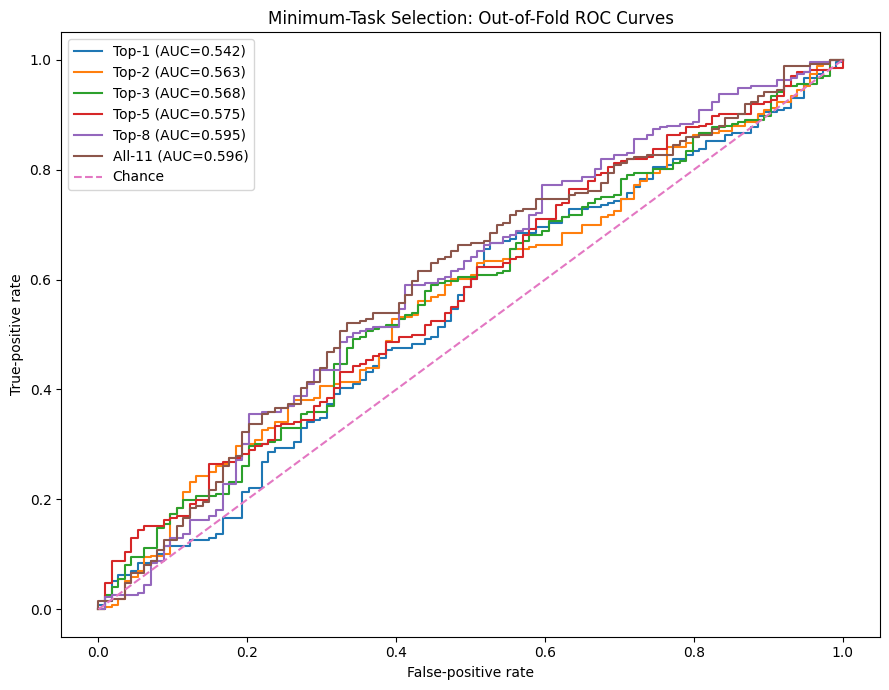

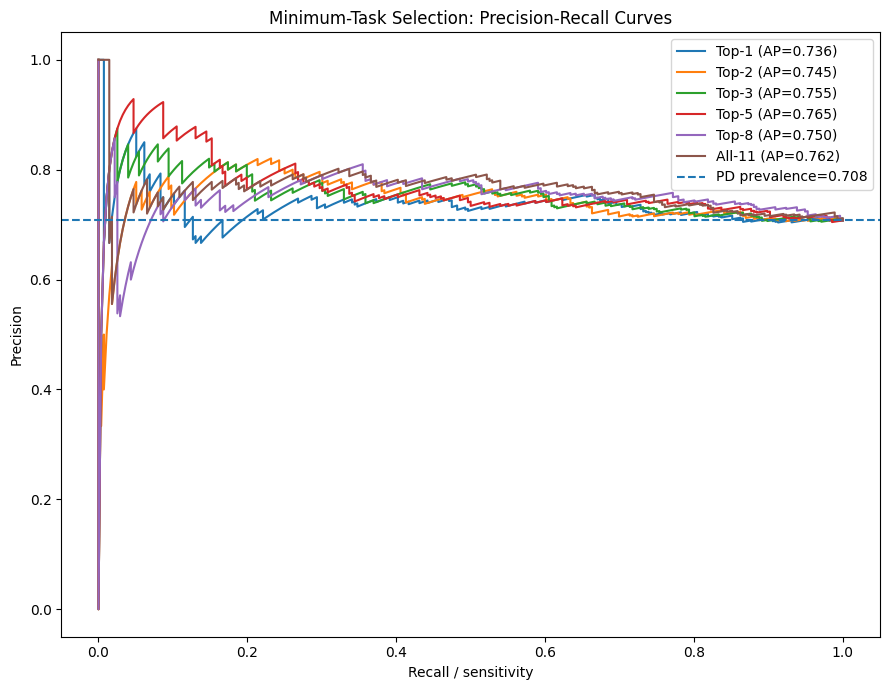


NESTED MINIMUM-TASK SELECTION COMPLETE

Overall out-of-fold results:

 task_count  assessment_reduction_percent  balanced_accuracy  macro_f1  sensitivity_pd  specificity_dd  roc_auc  pr_auc  brier_score  ece_10_bins
          1                       90.9091             0.5190    0.5188          0.7572          0.2807   0.5425  0.7359       0.2453       0.1659
          2                       81.8182             0.5244    0.5243          0.7681          0.2807   0.5628  0.7448       0.2371       0.1341
          3                       72.7273             0.5353    0.5353          0.7899          0.2807   0.5676  0.7551       0.2358       0.1388
          5                       54.5455             0.5575    0.5591          0.8080          0.3070   0.5752  0.7653       0.2320       0.1411
          8                       27.2727             0.5666    0.5687          0.8261          0.3070   0.5947  0.7503       0.2254       0.1283
         11                        0.0000            

In [ ]:
# ==================================================================================================
# MODEL D — LEAKAGE-FREE NESTED MINIMUM / ADAPTIVE MOTOR-TASK SELECTION
# ONE COMPLETE CELL
#
# BACKBONE:
# GPU XGBoost
#
# OUTER VALIDATION:
# Same fixed 5 patient-level folds used by all previous models
#
# INNER PROCEDURE:
# 1. Rank all 11 motor tasks using only outer-training patients
# 2. Evaluate each task through inner 3-fold CV
# 3. Select Top-1, Top-2, Top-3, Top-5, Top-8 and All-11 tasks
# 4. Tune XGBoost separately for each task count using inner CV
# 5. Test once on untouched outer-test patients
#
# CLASS BALANCE:
# Balanced patient sample weights; no SMOTE, duplication or undersampling
#
# PRIMARY METRICS:
# Balanced accuracy, Macro-F1, PD sensitivity, DD specificity,
# ROC-AUC, PR-AUC, Brier score and ECE
# ==================================================================================================

import os
import gc
import sys
import time
import json
import random
import warnings
import subprocess
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# ==================================================================================================
# 1. INSTALL / IMPORT REQUIRED PACKAGES
# ==================================================================================================

try:
    import xgboost as xgb
except ImportError:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "xgboost"
    ])
    import xgboost as xgb

from sklearn.model_selection import (
    StratifiedKFold,
    ParameterGrid
)

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve,
    precision_recall_curve
)

print("=" * 115)
print("MODEL D — NESTED MINIMUM / ADAPTIVE MOTOR-TASK SELECTION")
print("=" * 115)

print("XGBoost version:", xgb.__version__)

# ==================================================================================================
# 2. REPRODUCIBILITY
# ==================================================================================================

GLOBAL_SEED = 42

random.seed(int(GLOBAL_SEED))
np.random.seed(int(GLOBAL_SEED))

# ==================================================================================================
# 3. GPU CHECK
# ==================================================================================================

print("\nGPU check:")

os.system("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader")

GPU_AVAILABLE = False

try:
    test_X = np.random.randn(20, 4).astype(np.float32)
    test_y = np.array([0, 1] * 10, dtype=np.int32)

    gpu_test_model = xgb.XGBClassifier(
        n_estimators=2,
        max_depth=2,
        learning_rate=0.1,
        tree_method="hist",
        device="cuda",
        random_state=GLOBAL_SEED,
        eval_metric="logloss"
    )

    gpu_test_model.fit(test_X, test_y)

    GPU_AVAILABLE = True
    print("✅ XGBoost GPU test successful.")

    del gpu_test_model, test_X, test_y
    gc.collect()

except Exception as gpu_error:
    print("⚠️ GPU test failed. CPU fallback will be used.")
    print("GPU error:", str(gpu_error)[:500])

DEVICE = "cuda" if GPU_AVAILABLE else "cpu"

# ==================================================================================================
# 4. PATHS
# ==================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = BASE_DIR / "project_ready_data"
FEATURE_DIR = PROJECT_DIR / "feature_engineering"
BASELINE_DIR = PROJECT_DIR / "baseline_results"
PROPOSED_DIR = PROJECT_DIR / "proposed_model_results"

FEATURE_FILE = (
    FEATURE_DIR
    / "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = (
    BASELINE_DIR
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

OUTPUT_DIR = (
    PROPOSED_DIR
    / "model_d_nested_minimum_task_selection_xgboost"
)

FIGURE_DIR = OUTPUT_DIR / "figures"
PREDICTION_DIR = OUTPUT_DIR / "predictions"
MODEL_INFO_DIR = OUTPUT_DIR / "model_information"

for directory in [
    OUTPUT_DIR,
    FIGURE_DIR,
    PREDICTION_DIR,
    MODEL_INFO_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# Automatically locate files if expected path is unavailable.
if not FEATURE_FILE.exists():
    feature_matches = list(
        BASE_DIR.rglob(
            "pads_engineered_features.csv"
        )
    )

    if not feature_matches:
        raise FileNotFoundError(
            "pads_engineered_features.csv file nahi mili."
        )

    FEATURE_FILE = feature_matches[0]

if not FIXED_SPLIT_FILE.exists():
    split_matches = list(
        BASE_DIR.rglob(
            "fixed_outer_5fold_splits.csv"
        )
    )

    if not split_matches:
        raise FileNotFoundError(
            "fixed_outer_5fold_splits.csv file nahi mili."
        )

    FIXED_SPLIT_FILE = split_matches[0]

print("\nFeature file :", FEATURE_FILE)
print("Fixed folds :", FIXED_SPLIT_FILE)
print("Output      :", OUTPUT_DIR)
print("Device      :", DEVICE)

# ==================================================================================================
# 5. LOAD ENGINEERED FEATURE TABLE
# ==================================================================================================

data = pd.read_csv(
    FEATURE_FILE
)

print("\nComplete feature-table shape:", data.shape)

# Identify patient ID column.
possible_id_columns = [
    "patient_id",
    "id",
    "patient",
    "Patient_ID"
]

PATIENT_ID_COLUMN = next(
    (
        column
        for column in possible_id_columns
        if column in data.columns
    ),
    None
)

if PATIENT_ID_COLUMN is None:
    raise ValueError(
        "Patient ID column identify nahi hui."
    )

data[PATIENT_ID_COLUMN] = (
    data[PATIENT_ID_COLUMN]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(3)
)

# Identify target column.
possible_target_columns = [
    "y",
    "label",
    "target",
    "condition_2class",
    "diagnostic_group"
]

TARGET_COLUMN = next(
    (
        column
        for column in possible_target_columns
        if column in data.columns
    ),
    None
)

if TARGET_COLUMN is None:
    raise ValueError(
        "Target column identify nahi hui."
    )

# Convert target robustly.
if pd.api.types.is_numeric_dtype(
    data[TARGET_COLUMN]
):
    target_numeric = pd.to_numeric(
        data[TARGET_COLUMN],
        errors="coerce"
    )

    unique_target_values = sorted(
        target_numeric.dropna().unique()
    )

    if set(unique_target_values).issubset({0, 1}):
        y = target_numeric.astype(int).to_numpy()

    elif set(unique_target_values).issubset({1, 2}):
        # Assumption: Parkinson's = 1, DD = 2.
        y = (
            target_numeric == 1
        ).astype(int).to_numpy()

    else:
        raise ValueError(
            f"Unexpected numeric target values: {unique_target_values}"
        )

else:
    normalized_target = (
        data[TARGET_COLUMN]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    y = normalized_target.map({
        "parkinson's": 1,
        "parkinsons": 1,
        "parkinson": 1,
        "pd": 1,
        "1": 1,

        "differential diagnosis": 0,
        "differential-diagnosis": 0,
        "dd": 0,
        "other movement disorders": 0,
        "0": 0
    }).to_numpy()

    if pd.isna(y).any():
        unknown_targets = sorted(
            normalized_target[
                pd.isna(y)
            ].unique()
        )

        raise ValueError(
            f"Unknown target labels: {unknown_targets}"
        )

    y = y.astype(int)

patient_ids = data[
    PATIENT_ID_COLUMN
].to_numpy()

if len(np.unique(patient_ids)) != len(patient_ids):
    raise ValueError(
        "Duplicate patient IDs detected."
    )

print("Patients:", len(patient_ids))
print("PD      :", int(np.sum(y == 1)))
print("DD      :", int(np.sum(y == 0)))

if len(patient_ids) != 390:
    print(
        f"⚠️ Expected 390 PD-vs-DD patients, found {len(patient_ids)}."
    )

# ==================================================================================================
# 6. DEFINE MOTOR TASKS AND FEATURE GROUPS
# ==================================================================================================

TASK_NAMES = [
    "Relaxed1",
    "Relaxed2",
    "RelaxedTask1",
    "RelaxedTask2",
    "StretchHold",
    "HoldWeight",
    "DrinkGlas",
    "CrossArms",
    "TouchNose",
    "Entrainment1",
    "Entrainment2"
]

# Columns that must never enter the model.
metadata_exact_columns = {
    PATIENT_ID_COLUMN,
    TARGET_COLUMN,
    "condition",
    "condition_original",
    "condition_3class",
    "diagnostic_group",
    "resource_type",
    "study_id",
    "disease_comment",
    "age",
    "age_at_diagnosis",
    "height",
    "weight",
    "gender",
    "handedness",
    "appearance_in_kinship",
    "appearance_in_first_grade_kinship",
    "effect_of_alcohol_on_tremor",
    "questionnaire",
    "group",
    "class",
    "target_name"
}

candidate_feature_columns = []

for column in data.columns:
    if column in metadata_exact_columns:
        continue

    # Only numeric columns can enter XGBoost.
    converted = pd.to_numeric(
        data[column],
        errors="coerce"
    )

    if converted.notna().sum() > 0:
        candidate_feature_columns.append(
            column
        )

# Assign every feature to a task based on its prefix.
task_to_features = {}

for task_name in TASK_NAMES:

    task_prefixes = [
        f"{task_name}__",
        f"{task_name}_",
        f"{task_name} "
    ]

    matched_columns = [
        column
        for column in candidate_feature_columns
        if any(
            str(column).startswith(prefix)
            for prefix in task_prefixes
        )
    ]

    task_to_features[
        task_name
    ] = matched_columns

print("\nFeature counts by motor task:")

for task_name in TASK_NAMES:
    print(
        f"{task_name:20s}: "
        f"{len(task_to_features[task_name])} features"
    )

tasks_without_features = [
    task_name
    for task_name in TASK_NAMES
    if len(task_to_features[task_name]) == 0
]

if tasks_without_features:
    raise ValueError(
        "No features detected for these tasks: "
        f"{tasks_without_features}\n\n"
        "Feature names ka prefix inspect karna hoga."
    )

all_task_feature_columns = []

for task_name in TASK_NAMES:
    all_task_feature_columns.extend(
        task_to_features[task_name]
    )

# Remove duplicates while preserving order.
all_task_feature_columns = list(
    dict.fromkeys(
        all_task_feature_columns
    )
)

print(
    "\nTotal task-associated features:",
    len(all_task_feature_columns)
)

# Convert features to numeric.
X_dataframe = data[
    all_task_feature_columns
].apply(
    pd.to_numeric,
    errors="coerce"
)

# Replace infinity with missing values.
X_dataframe = X_dataframe.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Total missing feature cells:",
    int(X_dataframe.isna().sum().sum())
)

# ==================================================================================================
# 7. LOAD AND VERIFY SAME FIXED FIVE OUTER FOLDS
# ==================================================================================================

fixed_splits = pd.read_csv(
    FIXED_SPLIT_FILE,
    dtype={"patient_id": str}
)

required_split_columns = {
    "patient_id",
    "fold",
    "role"
}

if not required_split_columns.issubset(
    fixed_splits.columns
):
    raise ValueError(
        "Fixed split file must contain patient_id, fold and role."
    )

fixed_splits["patient_id"] = (
    fixed_splits["patient_id"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(3)
)

fixed_splits["fold"] = pd.to_numeric(
    fixed_splits["fold"],
    errors="raise"
).astype(int)

fixed_splits["role"] = (
    fixed_splits["role"]
    .astype(str)
    .str.lower()
    .str.strip()
)

AVAILABLE_FOLDS = [
    int(value)
    for value in sorted(
        fixed_splits["fold"].unique()
    )
]

if AVAILABLE_FOLDS != [1, 2, 3, 4, 5]:
    raise ValueError(
        f"Expected folds 1–5, found {AVAILABLE_FOLDS}"
    )

if set(fixed_splits["patient_id"]) != set(patient_ids):
    missing_from_features = (
        set(fixed_splits["patient_id"])
        - set(patient_ids)
    )

    missing_from_folds = (
        set(patient_ids)
        - set(fixed_splits["patient_id"])
    )

    raise ValueError(
        "Patient IDs do not match.\n"
        f"Missing from feature table: {missing_from_features}\n"
        f"Missing from fold file: {missing_from_folds}"
    )

test_counts = (
    fixed_splits.loc[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if (
    len(test_counts) != len(patient_ids)
    or not (test_counts == 1).all()
):
    raise ValueError(
        "Every patient must occur as outer-test exactly once."
    )

patient_to_index = {
    patient_id: index
    for index, patient_id in enumerate(
        patient_ids
    )
}

print("\n✅ Same fixed five patient-level folds verified.")

# ==================================================================================================
# 8. EXPERIMENT CONFIGURATION
# ==================================================================================================

TASK_COUNTS = [
    1,
    2,
    3,
    5,
    8,
    11
]

INNER_FOLDS = 3
PREDICTION_THRESHOLD = 0.50
N_BOOTSTRAPS = 2000

# Ranking model is kept fixed to avoid selecting tasks and tuning the
# ranking model simultaneously.
RANKING_MODEL_PARAMETERS = {
    "n_estimators": 250,
    "max_depth": 3,
    "learning_rate": 0.05,
    "subsample": 0.80,
    "colsample_bytree": 0.80,
    "min_child_weight": 3,
    "reg_alpha": 0.10,
    "reg_lambda": 2.0
}

# Small fair tuning grid for final top-k models.
PARAMETER_GRID = {
    "n_estimators": [
        250,
        500
    ],

    "max_depth": [
        2,
        3,
        4
    ],

    "learning_rate": [
        0.03,
        0.07
    ],

    "subsample": [
        0.80
    ],

    "colsample_bytree": [
        0.70,
        1.00
    ],

    "min_child_weight": [
        1,
        5
    ],

    "reg_alpha": [
        0.0,
        0.20
    ],

    "reg_lambda": [
        2.0
    ]
}

parameter_combinations = list(
    ParameterGrid(
        PARAMETER_GRID
    )
)

print("\nExperiment configuration:")
print("Task counts              :", TASK_COUNTS)
print("Inner folds              :", INNER_FOLDS)
print("Parameter combinations   :", len(parameter_combinations))
print("Classification threshold :", PREDICTION_THRESHOLD)
print("Bootstrap iterations     :", N_BOOTSTRAPS)

# ==================================================================================================
# 9. HELPER FUNCTIONS
# ==================================================================================================

def expected_calibration_error(
    y_true,
    probabilities,
    n_bins=10
):
    y_true = np.asarray(
        y_true,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(n_bins):
        lower = bin_edges[bin_index]
        upper = bin_edges[bin_index + 1]

        if bin_index == n_bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if not np.any(mask):
            continue

        confidence = float(
            np.mean(
                probabilities[mask]
            )
        )

        observed = float(
            np.mean(
                y_true[mask]
            )
        )

        ece += (
            float(np.mean(mask))
            * abs(observed - confidence)
        )

    return float(ece)


def calculate_metrics(
    y_true,
    predictions,
    probabilities
):
    y_true = np.asarray(
        y_true,
        dtype=int
    )

    predictions = np.asarray(
        predictions,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity_pd = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity_dd = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions
        ),

        "macro_f1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "pd_f1": f1_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "dd_f1": f1_score(
            y_true,
            predictions,
            pos_label=0,
            zero_division=0
        ),

        "precision_pd": precision_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "sensitivity_pd": sensitivity_pd,

        "specificity_dd": specificity_dd,

        "roc_auc": roc_auc_score(
            y_true,
            probabilities
        ),

        "pr_auc": average_precision_score(
            y_true,
            probabilities
        ),

        "brier_score": brier_score_loss(
            y_true,
            probabilities
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            probabilities,
            n_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }


def create_xgboost_model(
    parameters,
    seed
):
    model_parameters = {
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "tree_method": "hist",
        "device": DEVICE,
        "random_state": int(seed),
        "n_jobs": 2,
        "verbosity": 0
    }

    model_parameters.update(
        parameters
    )

    return xgb.XGBClassifier(
        **model_parameters
    )


def fit_preprocessor(
    training_dataframe
):
    """
    Fits preprocessing on current training patients only.

    Steps:
    1. Median imputation
    2. Constant-feature removal
    """

    imputer = SimpleImputer(
        strategy="median"
    )

    X_imputed = imputer.fit_transform(
        training_dataframe
    )

    variance_filter = VarianceThreshold(
        threshold=0.0
    )

    X_filtered = variance_filter.fit_transform(
        X_imputed
    )

    return (
        imputer,
        variance_filter,
        X_filtered.astype(np.float32)
    )


def transform_with_preprocessor(
    dataframe,
    imputer,
    variance_filter
):
    X_imputed = imputer.transform(
        dataframe
    )

    X_filtered = variance_filter.transform(
        X_imputed
    )

    return X_filtered.astype(
        np.float32
    )


def get_features_for_tasks(
    selected_tasks
):
    feature_columns = []

    for task_name in selected_tasks:
        feature_columns.extend(
            task_to_features[
                task_name
            ]
        )

    return list(
        dict.fromkeys(
            feature_columns
        )
    )


def inner_cv_score(
    training_indices,
    feature_columns,
    parameters,
    seed
):
    """
    Leakage-free inner 3-fold CV score.

    Preprocessing and balanced sample weights are fitted inside each
    inner training fold.
    """

    inner_splitter = StratifiedKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=int(seed)
    )

    y_training = y[
        training_indices
    ]

    fold_scores = []

    for inner_fold_number, (
        relative_inner_train,
        relative_inner_validation
    ) in enumerate(
        inner_splitter.split(
            np.zeros(
                len(training_indices)
            ),
            y_training
        ),
        start=1
    ):
        inner_train_indices = training_indices[
            relative_inner_train
        ]

        inner_validation_indices = training_indices[
            relative_inner_validation
        ]

        X_inner_train_df = X_dataframe.loc[
            inner_train_indices,
            feature_columns
        ]

        X_inner_validation_df = X_dataframe.loc[
            inner_validation_indices,
            feature_columns
        ]

        y_inner_train = y[
            inner_train_indices
        ]

        y_inner_validation = y[
            inner_validation_indices
        ]

        (
            imputer,
            variance_filter,
            X_inner_train
        ) = fit_preprocessor(
            X_inner_train_df
        )

        X_inner_validation = (
            transform_with_preprocessor(
                X_inner_validation_df,
                imputer,
                variance_filter
            )
        )

        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_inner_train
        )

        model = create_xgboost_model(
            parameters=parameters,
            seed=(
                int(seed)
                + int(inner_fold_number)
            )
        )

        model.fit(
            X_inner_train,
            y_inner_train,
            sample_weight=sample_weights,
            verbose=False
        )

        probabilities = model.predict_proba(
            X_inner_validation
        )[:, 1]

        predictions = (
            probabilities
            >= PREDICTION_THRESHOLD
        ).astype(int)

        balanced_accuracy = (
            balanced_accuracy_score(
                y_inner_validation,
                predictions
            )
        )

        roc_auc = roc_auc_score(
            y_inner_validation,
            probabilities
        )

        macro_f1 = f1_score(
            y_inner_validation,
            predictions,
            average="macro",
            zero_division=0
        )

        # Primary score strongly emphasizes balanced classification.
        combined_score = (
            0.60 * balanced_accuracy
            + 0.25 * macro_f1
            + 0.15 * roc_auc
        )

        fold_scores.append({
            "balanced_accuracy": balanced_accuracy,
            "macro_f1": macro_f1,
            "roc_auc": roc_auc,
            "combined_score": combined_score
        })

        del (
            X_inner_train_df,
            X_inner_validation_df,
            X_inner_train,
            X_inner_validation,
            imputer,
            variance_filter,
            model
        )

        gc.collect()

    fold_scores_df = pd.DataFrame(
        fold_scores
    )

    return {
        "mean_balanced_accuracy": float(
            fold_scores_df[
                "balanced_accuracy"
            ].mean()
        ),

        "mean_macro_f1": float(
            fold_scores_df[
                "macro_f1"
            ].mean()
        ),

        "mean_roc_auc": float(
            fold_scores_df[
                "roc_auc"
            ].mean()
        ),

        "mean_combined_score": float(
            fold_scores_df[
                "combined_score"
            ].mean()
        )
    }


def bootstrap_confidence_intervals(
    y_true,
    predictions,
    probabilities,
    iterations,
    seed
):
    rng = np.random.default_rng(
        int(seed)
    )

    rows = []

    sample_size = len(y_true)

    for bootstrap_iteration in range(
        iterations
    ):
        sampled_indices = rng.integers(
            low=0,
            high=sample_size,
            size=sample_size
        )

        sampled_y = y_true[
            sampled_indices
        ]

        if len(
            np.unique(sampled_y)
        ) < 2:
            continue

        metrics = calculate_metrics(
            sampled_y,
            predictions[
                sampled_indices
            ],
            probabilities[
                sampled_indices
            ]
        )

        metrics[
            "bootstrap_iteration"
        ] = int(
            bootstrap_iteration
        )

        rows.append(metrics)

    bootstrap_df = pd.DataFrame(
        rows
    )

    ci_rows = []

    ci_metric_names = [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "ece_10_bins"
    ]

    observed_metrics = calculate_metrics(
        y_true,
        predictions,
        probabilities
    )

    for metric_name in ci_metric_names:
        values = (
            bootstrap_df[
                metric_name
            ]
            .dropna()
            .to_numpy()
        )

        ci_rows.append({
            "metric": metric_name,
            "value": observed_metrics[
                metric_name
            ],
            "ci_95_lower": float(
                np.percentile(
                    values,
                    2.5
                )
            ),
            "ci_95_upper": float(
                np.percentile(
                    values,
                    97.5
                )
            )
        })

    return (
        bootstrap_df,
        pd.DataFrame(ci_rows)
    )

# ==================================================================================================
# 10. STORAGE
# ==================================================================================================

N_PATIENTS = len(
    patient_ids
)

oof_probabilities = {
    task_count: np.full(
        N_PATIENTS,
        np.nan,
        dtype=np.float32
    )
    for task_count in TASK_COUNTS
}

oof_predictions = {
    task_count: np.full(
        N_PATIENTS,
        -1,
        dtype=np.int32
    )
    for task_count in TASK_COUNTS
}

oof_fold_assignments = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

task_ranking_rows = []
selected_task_rows = []
parameter_rows = []
fold_result_rows = []

total_start_time = time.time()

# ==================================================================================================
# 11. OUTER FIVE-FOLD EXPERIMENT
# ==================================================================================================

print("\n" + "=" * 115)
print("STARTING NESTED TASK-SELECTION EXPERIMENT")
print("=" * 115)

for raw_outer_fold in AVAILABLE_FOLDS:

    outer_fold = int(
        raw_outer_fold
    )

    fold_start_time = time.time()

    fold_seed = int(
        GLOBAL_SEED
        + outer_fold * 100
    )

    random.seed(
        fold_seed
    )

    np.random.seed(
        fold_seed
    )

    current_fold = fixed_splits.loc[
        fixed_splits["fold"]
        == outer_fold
    ]

    outer_train_ids = current_fold.loc[
        current_fold["role"] == "train",
        "patient_id"
    ].tolist()

    outer_test_ids = current_fold.loc[
        current_fold["role"] == "test",
        "patient_id"
    ].tolist()

    outer_train_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id in outer_train_ids
    ], dtype=int)

    outer_test_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id in outer_test_ids
    ], dtype=int)

    if set(
        outer_train_indices
    ).intersection(
        set(outer_test_indices)
    ):
        raise RuntimeError(
            f"Patient leakage in outer fold {outer_fold}."
        )

    y_outer_train = y[
        outer_train_indices
    ]

    y_outer_test = y[
        outer_test_indices
    ]

    print("\n" + "-" * 100)
    print(
        f"OUTER FOLD {outer_fold}/5"
    )
    print("-" * 100)

    print(
        f"Training: {len(outer_train_indices)} "
        f"(PD={np.sum(y_outer_train == 1)}, "
        f"DD={np.sum(y_outer_train == 0)})"
    )

    print(
        f"Testing : {len(outer_test_indices)} "
        f"(PD={np.sum(y_outer_test == 1)}, "
        f"DD={np.sum(y_outer_test == 0)})"
    )

    # ==============================================================================================
    # 11A. RANK ALL 11 TASKS USING OUTER-TRAINING PATIENTS ONLY
    # ==============================================================================================

    print("\nStep 1: Ranking 11 tasks using inner three-fold CV...")

    fold_task_ranking = []

    for task_position, task_name in enumerate(
        TASK_NAMES,
        start=1
    ):
        task_features = task_to_features[
            task_name
        ]

        task_score = inner_cv_score(
            training_indices=outer_train_indices,
            feature_columns=task_features,
            parameters=RANKING_MODEL_PARAMETERS,
            seed=(
                fold_seed
                + task_position
            )
        )

        ranking_row = {
            "outer_fold": outer_fold,
            "task": task_name,
            "number_of_features": len(
                task_features
            ),
            **task_score
        }

        fold_task_ranking.append(
            ranking_row
        )

        task_ranking_rows.append(
            ranking_row
        )

        print(
            f"{task_name:20s} | "
            f"BA={task_score['mean_balanced_accuracy']:.4f} | "
            f"F1={task_score['mean_macro_f1']:.4f} | "
            f"AUC={task_score['mean_roc_auc']:.4f} | "
            f"Combined={task_score['mean_combined_score']:.4f}"
        )

    fold_task_ranking_df = pd.DataFrame(
        fold_task_ranking
    ).sort_values(
        [
            "mean_combined_score",
            "mean_balanced_accuracy",
            "mean_roc_auc"
        ],
        ascending=False
    ).reset_index(drop=True)

    ranked_tasks = fold_task_ranking_df[
        "task"
    ].tolist()

    print("\nTask ranking for this outer fold:")

    for rank_number, task_name in enumerate(
        ranked_tasks,
        start=1
    ):
        print(
            f"{rank_number:2d}. {task_name}"
        )

    # ==============================================================================================
    # 11B. TEST TOP-K TASK CONFIGURATIONS
    # ==============================================================================================

    for task_count in TASK_COUNTS:

        selected_tasks = ranked_tasks[
            :task_count
        ]

        selected_features = get_features_for_tasks(
            selected_tasks
        )

        print("\n" + "." * 90)
        print(
            f"Task configuration: Top-{task_count}"
        )
        print(
            "Selected tasks:",
            ", ".join(selected_tasks)
        )
        print(
            "Input features:",
            len(selected_features)
        )

        # ==========================================================================================
        # INNER HYPERPARAMETER TUNING
        # ==========================================================================================

        best_parameters = None
        best_inner_score = -np.inf
        best_inner_metrics = None

        for parameter_index, parameters in enumerate(
            parameter_combinations,
            start=1
        ):
            inner_result = inner_cv_score(
                training_indices=outer_train_indices,
                feature_columns=selected_features,
                parameters=parameters,
                seed=(
                    fold_seed
                    + task_count * 1000
                    + parameter_index
                )
            )

            if (
                inner_result[
                    "mean_combined_score"
                ]
                > best_inner_score
            ):
                best_inner_score = inner_result[
                    "mean_combined_score"
                ]

                best_parameters = parameters.copy()

                best_inner_metrics = (
                    inner_result.copy()
                )

        print(
            "Best inner score:",
            f"{best_inner_score:.4f}"
        )

        print(
            "Best parameters:",
            best_parameters
        )

        # ==========================================================================================
        # FIT PREPROCESSING AND FINAL MODEL ON COMPLETE OUTER-TRAINING FOLD
        # ==========================================================================================

        X_outer_train_df = X_dataframe.loc[
            outer_train_indices,
            selected_features
        ]

        X_outer_test_df = X_dataframe.loc[
            outer_test_indices,
            selected_features
        ]

        (
            final_imputer,
            final_variance_filter,
            X_outer_train
        ) = fit_preprocessor(
            X_outer_train_df
        )

        X_outer_test = (
            transform_with_preprocessor(
                X_outer_test_df,
                final_imputer,
                final_variance_filter
            )
        )

        final_sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_outer_train
        )

        final_model = create_xgboost_model(
            parameters=best_parameters,
            seed=(
                fold_seed
                + task_count * 10000
            )
        )

        final_model.fit(
            X_outer_train,
            y_outer_train,
            sample_weight=final_sample_weights,
            verbose=False
        )

        test_probabilities = final_model.predict_proba(
            X_outer_test
        )[:, 1]

        test_predictions = (
            test_probabilities
            >= PREDICTION_THRESHOLD
        ).astype(int)

        oof_probabilities[
            task_count
        ][outer_test_indices] = (
            test_probabilities
        )

        oof_predictions[
            task_count
        ][outer_test_indices] = (
            test_predictions
        )

        oof_fold_assignments[
            outer_test_indices
        ] = outer_fold

        outer_metrics = calculate_metrics(
            y_outer_test,
            test_predictions,
            test_probabilities
        )

        print(
            f"Outer BA={outer_metrics['balanced_accuracy']:.4f} | "
            f"Macro-F1={outer_metrics['macro_f1']:.4f} | "
            f"PD sensitivity={outer_metrics['sensitivity_pd']:.4f} | "
            f"DD specificity={outer_metrics['specificity_dd']:.4f} | "
            f"AUC={outer_metrics['roc_auc']:.4f} | "
            f"PR-AUC={outer_metrics['pr_auc']:.4f}"
        )

        selected_task_rows.append({
            "outer_fold": outer_fold,
            "task_count": task_count,
            "selected_tasks": " | ".join(
                selected_tasks
            ),
            "number_of_selected_features_before_filter": len(
                selected_features
            ),
            "number_of_selected_features_after_filter": int(
                X_outer_train.shape[1]
            ),
            "assessment_reduction_percent": (
                1.0
                - task_count / len(TASK_NAMES)
            ) * 100.0
        })

        parameter_rows.append({
            "outer_fold": outer_fold,
            "task_count": task_count,
            "best_inner_combined_score": best_inner_score,
            "best_inner_balanced_accuracy": best_inner_metrics[
                "mean_balanced_accuracy"
            ],
            "best_inner_macro_f1": best_inner_metrics[
                "mean_macro_f1"
            ],
            "best_inner_roc_auc": best_inner_metrics[
                "mean_roc_auc"
            ],
            "best_parameters": json.dumps(
                best_parameters
            )
        })

        fold_result_rows.append({
            "outer_fold": outer_fold,
            "task_count": task_count,
            "selected_tasks": " | ".join(
                selected_tasks
            ),
            "number_of_features": int(
                X_outer_train.shape[1]
            ),
            "assessment_reduction_percent": (
                1.0
                - task_count / len(TASK_NAMES)
            ) * 100.0,
            **outer_metrics
        })

        del (
            X_outer_train_df,
            X_outer_test_df,
            X_outer_train,
            X_outer_test,
            final_imputer,
            final_variance_filter,
            final_model,
            test_probabilities,
            test_predictions
        )

        gc.collect()

    fold_minutes = (
        time.time()
        - fold_start_time
    ) / 60

    print(
        f"\nOuter fold {outer_fold} completed "
        f"in {fold_minutes:.2f} minutes."
    )

total_runtime_minutes = (
    time.time()
    - total_start_time
) / 60

# ==================================================================================================
# 12. VERIFY COMPLETE OUT-OF-FOLD PREDICTIONS
# ==================================================================================================

for task_count in TASK_COUNTS:

    if np.isnan(
        oof_probabilities[
            task_count
        ]
    ).any():
        raise RuntimeError(
            f"Missing OOF probabilities for Top-{task_count}."
        )

    if np.any(
        oof_predictions[
            task_count
        ] < 0
    ):
        raise RuntimeError(
            f"Missing OOF labels for Top-{task_count}."
        )

if np.any(
    oof_fold_assignments < 1
):
    raise RuntimeError(
        "Some patients are missing outer-fold assignments."
    )

print("\n✅ Every patient received one OOF prediction for every task count.")

# ==================================================================================================
# 13. OVERALL RESULTS AND CONFIDENCE INTERVALS
# ==================================================================================================

overall_summary_rows = []
all_confidence_interval_rows = []
all_bootstrap_rows = []
all_patient_prediction_rows = []

for task_count in TASK_COUNTS:

    probabilities = oof_probabilities[
        task_count
    ]

    predictions = oof_predictions[
        task_count
    ]

    metrics = calculate_metrics(
        y,
        predictions,
        probabilities
    )

    assessment_reduction = (
        1.0
        - task_count / len(TASK_NAMES)
    ) * 100.0

    overall_summary_rows.append({
        "model": "GPU XGBoost",
        "experiment": (
            f"Nested Top-{task_count} "
            f"motor-task selection"
            if task_count < 11
            else "All 11 motor tasks"
        ),
        "task_count": task_count,
        "total_available_tasks": len(
            TASK_NAMES
        ),
        "assessment_reduction_percent": assessment_reduction,
        "patients": N_PATIENTS,
        "pd_patients": int(
            np.sum(y == 1)
        ),
        "dd_patients": int(
            np.sum(y == 0)
        ),
        "outer_folds": 5,
        "inner_folds": INNER_FOLDS,
        "classification_threshold": PREDICTION_THRESHOLD,
        "class_balance_method": (
            "Balanced sample weights inside each training fold"
        ),
        "oversampling_used": False,
        **metrics
    })

    (
        bootstrap_df,
        confidence_intervals_df
    ) = bootstrap_confidence_intervals(
        y_true=y,
        predictions=predictions,
        probabilities=probabilities,
        iterations=N_BOOTSTRAPS,
        seed=(
            GLOBAL_SEED
            + task_count
        )
    )

    bootstrap_df.insert(
        0,
        "task_count",
        task_count
    )

    confidence_intervals_df.insert(
        0,
        "task_count",
        task_count
    )

    all_bootstrap_rows.append(
        bootstrap_df
    )

    all_confidence_interval_rows.append(
        confidence_intervals_df
    )

    for patient_index in range(
        N_PATIENTS
    ):
        all_patient_prediction_rows.append({
            "patient_id": patient_ids[
                patient_index
            ],
            "true_label": int(
                y[patient_index]
            ),
            "true_group": (
                "Parkinson's"
                if y[patient_index] == 1
                else "Differential Diagnosis"
            ),
            "outer_fold": int(
                oof_fold_assignments[
                    patient_index
                ]
            ),
            "task_count": task_count,
            "predicted_probability_pd": float(
                probabilities[
                    patient_index
                ]
            ),
            "predicted_label": int(
                predictions[
                    patient_index
                ]
            ),
            "predicted_group": (
                "Parkinson's"
                if predictions[
                    patient_index
                ] == 1
                else "Differential Diagnosis"
            ),
            "correct_prediction": int(
                predictions[
                    patient_index
                ]
                == y[
                    patient_index
                ]
            )
        })

overall_summary_df = pd.DataFrame(
    overall_summary_rows
).sort_values(
    "task_count"
)

confidence_intervals_all_df = pd.concat(
    all_confidence_interval_rows,
    ignore_index=True
)

bootstrap_all_df = pd.concat(
    all_bootstrap_rows,
    ignore_index=True
)

patient_predictions_all_df = pd.DataFrame(
    all_patient_prediction_rows
)

task_ranking_df = pd.DataFrame(
    task_ranking_rows
)

selected_tasks_df = pd.DataFrame(
    selected_task_rows
)

best_parameters_df = pd.DataFrame(
    parameter_rows
)

fold_results_df = pd.DataFrame(
    fold_result_rows
)

# ==================================================================================================
# 14. DETERMINE BEST AND MINIMUM ACCEPTABLE TASK CONFIGURATIONS
# ==================================================================================================

# Best by balanced accuracy, then Macro-F1, then ROC-AUC.
best_row = (
    overall_summary_df
    .sort_values(
        [
            "balanced_accuracy",
            "macro_f1",
            "roc_auc"
        ],
        ascending=False
    )
    .iloc[0]
)

best_task_count = int(
    best_row[
        "task_count"
    ]
)

all_task_row = (
    overall_summary_df.loc[
        overall_summary_df[
            "task_count"
        ] == 11
    ]
    .iloc[0]
)

all_task_balanced_accuracy = float(
    all_task_row[
        "balanced_accuracy"
    ]
)

# Retain at least 95% of all-task balanced accuracy.
retention_threshold = (
    0.95
    * all_task_balanced_accuracy
)

acceptable_rows = (
    overall_summary_df.loc[
        overall_summary_df[
            "balanced_accuracy"
        ] >= retention_threshold
    ]
    .sort_values(
        "task_count"
    )
)

minimum_acceptable_task_count = int(
    acceptable_rows.iloc[0][
        "task_count"
    ]
)

minimum_acceptable_row = (
    acceptable_rows.iloc[0]
)

decision_summary_df = pd.DataFrame([
    {
        "criterion": "Best observed performance",
        "selected_task_count": best_task_count,
        "balanced_accuracy": float(
            best_row[
                "balanced_accuracy"
            ]
        ),
        "macro_f1": float(
            best_row[
                "macro_f1"
            ]
        ),
        "roc_auc": float(
            best_row[
                "roc_auc"
            ]
        ),
        "assessment_reduction_percent": float(
            best_row[
                "assessment_reduction_percent"
            ]
        )
    },
    {
        "criterion": (
            "Minimum tasks retaining at least "
            "95% of all-task balanced accuracy"
        ),
        "selected_task_count": (
            minimum_acceptable_task_count
        ),
        "balanced_accuracy": float(
            minimum_acceptable_row[
                "balanced_accuracy"
            ]
        ),
        "macro_f1": float(
            minimum_acceptable_row[
                "macro_f1"
            ]
        ),
        "roc_auc": float(
            minimum_acceptable_row[
                "roc_auc"
            ]
        ),
        "assessment_reduction_percent": float(
            minimum_acceptable_row[
                "assessment_reduction_percent"
            ]
        )
    }
])

# ==================================================================================================
# 15. TASK-SELECTION FREQUENCY
# ==================================================================================================

selection_frequency_rows = []

for task_count in TASK_COUNTS:

    task_counter = Counter()

    subset = selected_tasks_df.loc[
        selected_tasks_df[
            "task_count"
        ] == task_count
    ]

    for selected_task_string in subset[
        "selected_tasks"
    ]:
        selected_task_list = [
            task.strip()
            for task in selected_task_string.split("|")
        ]

        task_counter.update(
            selected_task_list
        )

    for task_name in TASK_NAMES:
        selection_frequency_rows.append({
            "task_count": task_count,
            "task": task_name,
            "number_of_outer_folds_selected": int(
                task_counter[
                    task_name
                ]
            ),
            "selection_frequency_percent": (
                task_counter[
                    task_name
                ] / 5
            ) * 100.0
        })

selection_frequency_df = pd.DataFrame(
    selection_frequency_rows
)

# Mean inner ranking score by task.
mean_task_ranking_df = (
    task_ranking_df
    .groupby(
        "task",
        as_index=False
    )
    .agg(
        mean_inner_balanced_accuracy=(
            "mean_balanced_accuracy",
            "mean"
        ),
        std_inner_balanced_accuracy=(
            "mean_balanced_accuracy",
            "std"
        ),
        mean_inner_macro_f1=(
            "mean_macro_f1",
            "mean"
        ),
        mean_inner_roc_auc=(
            "mean_roc_auc",
            "mean"
        ),
        mean_inner_combined_score=(
            "mean_combined_score",
            "mean"
        )
    )
    .sort_values(
        "mean_inner_combined_score",
        ascending=False
    )
)

# ==================================================================================================
# 16. SAVE ALL TABLES
# ==================================================================================================

overall_summary_df.to_csv(
    OUTPUT_DIR
    / "minimum_task_overall_summary.csv",
    index=False
)

confidence_intervals_all_df.to_csv(
    OUTPUT_DIR
    / "minimum_task_confidence_intervals_95.csv",
    index=False
)

bootstrap_all_df.to_csv(
    OUTPUT_DIR
    / "minimum_task_bootstrap_metrics.csv",
    index=False
)

patient_predictions_all_df.to_csv(
    OUTPUT_DIR
    / "minimum_task_patient_predictions.csv",
    index=False
)

task_ranking_df.to_csv(
    OUTPUT_DIR
    / "task_ranking_by_outer_fold.csv",
    index=False
)

mean_task_ranking_df.to_csv(
    OUTPUT_DIR
    / "mean_task_ranking_across_folds.csv",
    index=False
)

selected_tasks_df.to_csv(
    OUTPUT_DIR
    / "selected_tasks_by_fold_and_count.csv",
    index=False
)

selection_frequency_df.to_csv(
    OUTPUT_DIR
    / "task_selection_frequency.csv",
    index=False
)

best_parameters_df.to_csv(
    OUTPUT_DIR
    / "best_parameters_by_fold_and_task_count.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR
    / "fold_results_by_task_count.csv",
    index=False
)

decision_summary_df.to_csv(
    OUTPUT_DIR
    / "minimum_task_decision_summary.csv",
    index=False
)

# ==================================================================================================
# 17. FIGURE — PERFORMANCE BY NUMBER OF TASKS
# ==================================================================================================

plt.figure(figsize=(10, 6))

plt.plot(
    overall_summary_df[
        "task_count"
    ],
    overall_summary_df[
        "balanced_accuracy"
    ],
    marker="o",
    label="Balanced accuracy"
)

plt.plot(
    overall_summary_df[
        "task_count"
    ],
    overall_summary_df[
        "macro_f1"
    ],
    marker="o",
    label="Macro-F1"
)

plt.plot(
    overall_summary_df[
        "task_count"
    ],
    overall_summary_df[
        "roc_auc"
    ],
    marker="o",
    label="ROC-AUC"
)

plt.plot(
    overall_summary_df[
        "task_count"
    ],
    overall_summary_df[
        "pr_auc"
    ],
    marker="o",
    label="PR-AUC"
)

plt.axvline(
    best_task_count,
    linestyle="--",
    label=(
        f"Best performance: "
        f"{best_task_count} tasks"
    )
)

plt.xlabel("Number of adaptively selected motor tasks")
plt.ylabel("Out-of-fold metric")
plt.title(
    "Nested Minimum-Task Selection Performance"
)
plt.xticks(TASK_COUNTS)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_performance_by_task_count.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 18. FIGURE — PERFORMANCE VERSUS ASSESSMENT REDUCTION
# ==================================================================================================

plot_df = overall_summary_df.sort_values(
    "assessment_reduction_percent"
)

plt.figure(figsize=(10, 6))

plt.plot(
    plot_df[
        "assessment_reduction_percent"
    ],
    plot_df[
        "balanced_accuracy"
    ],
    marker="o",
    label="Balanced accuracy"
)

plt.plot(
    plot_df[
        "assessment_reduction_percent"
    ],
    plot_df[
        "macro_f1"
    ],
    marker="o",
    label="Macro-F1"
)

plt.xlabel("Reduction in required motor tasks (%)")
plt.ylabel("Out-of-fold metric")
plt.title(
    "Diagnostic Performance Versus Assessment Burden"
)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_performance_vs_assessment_reduction.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 19. FIGURE — MEAN TASK RANKING
# ==================================================================================================

task_ranking_plot = (
    mean_task_ranking_df
    .sort_values(
        "mean_inner_combined_score",
        ascending=True
    )
)

plt.figure(figsize=(9, 6))

plt.barh(
    task_ranking_plot[
        "task"
    ],
    task_ranking_plot[
        "mean_inner_combined_score"
    ]
)

plt.xlabel(
    "Mean inner-CV combined task score"
)
plt.ylabel("Motor task")
plt.title(
    "Leakage-Free Diagnostic Ranking of Motor Tasks"
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "03_mean_task_ranking.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 20. FIGURE — TOP-3 AND TOP-5 SELECTION FREQUENCY
# ==================================================================================================

frequency_plot_df = selection_frequency_df.loc[
    selection_frequency_df[
        "task_count"
    ].isin([3, 5])
].pivot(
    index="task",
    columns="task_count",
    values="number_of_outer_folds_selected"
).fillna(0)

frequency_plot_df.columns = [
    f"Top-{int(column)}"
    for column in frequency_plot_df.columns
]

frequency_plot_df = (
    frequency_plot_df
    .sort_values(
        list(
            frequency_plot_df.columns
        ),
        ascending=False
    )
)

plt.figure(figsize=(12, 6))

frequency_plot_df.plot(
    kind="bar",
    ax=plt.gca()
)

plt.xlabel("Motor task")
plt.ylabel(
    "Number of outer folds selected"
)
plt.title(
    "Motor-Task Selection Stability Across Five Outer Folds"
)
plt.xticks(
    rotation=35,
    ha="right"
)
plt.ylim(0, 5.5)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "04_top3_top5_task_selection_frequency.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 21. FIGURE — CONFUSION MATRICES FOR EACH TASK COUNT
# ==================================================================================================

for task_count in TASK_COUNTS:

    confusion = confusion_matrix(
        y,
        oof_predictions[
            task_count
        ],
        labels=[0, 1]
    )

    plt.figure(figsize=(6, 5))
    plt.imshow(confusion)
    plt.colorbar()

    plt.xticks(
        [0, 1],
        ["DD", "Parkinson's"]
    )

    plt.yticks(
        [0, 1],
        ["DD", "Parkinson's"]
    )

    plt.xlabel("Predicted diagnosis")
    plt.ylabel("True diagnosis")

    title_text = (
        f"Nested Top-{task_count} Motor Tasks"
        if task_count < 11
        else "All 11 Motor Tasks"
    )

    plt.title(
        f"{title_text}\n"
        "5-Fold Out-of-Fold Confusion Matrix"
    )

    for row in range(2):
        for column in range(2):
            plt.text(
                column,
                row,
                str(
                    confusion[
                        row,
                        column
                    ]
                ),
                ha="center",
                va="center",
                fontsize=15
            )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / f"05_confusion_matrix_top_{task_count}.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ==================================================================================================
# 22. FIGURE — ROC CURVES
# ==================================================================================================

plt.figure(figsize=(9, 7))

for task_count in TASK_COUNTS:

    false_positive_rate, true_positive_rate, _ = roc_curve(
        y,
        oof_probabilities[
            task_count
        ]
    )

    task_auc = roc_auc_score(
        y,
        oof_probabilities[
            task_count
        ]
    )

    label_name = (
        f"Top-{task_count}"
        if task_count < 11
        else "All-11"
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=(
            f"{label_name} "
            f"(AUC={task_auc:.3f})"
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title(
    "Minimum-Task Selection: Out-of-Fold ROC Curves"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "06_roc_curves_by_task_count.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 23. FIGURE — PRECISION-RECALL CURVES
# ==================================================================================================

plt.figure(figsize=(9, 7))

for task_count in TASK_COUNTS:

    precision_values, recall_values, _ = (
        precision_recall_curve(
            y,
            oof_probabilities[
                task_count
            ]
        )
    )

    task_ap = average_precision_score(
        y,
        oof_probabilities[
            task_count
        ]
    )

    label_name = (
        f"Top-{task_count}"
        if task_count < 11
        else "All-11"
    )

    plt.plot(
        recall_values,
        precision_values,
        label=(
            f"{label_name} "
            f"(AP={task_ap:.3f})"
        )
    )

plt.axhline(
    float(np.mean(y)),
    linestyle="--",
    label=(
        f"PD prevalence={np.mean(y):.3f}"
    )
)

plt.xlabel("Recall / sensitivity")
plt.ylabel("Precision")
plt.title(
    "Minimum-Task Selection: Precision-Recall Curves"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "07_precision_recall_curves_by_task_count.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 24. FINAL OUTPUT
# ==================================================================================================

print("\n" + "=" * 115)
print("NESTED MINIMUM-TASK SELECTION COMPLETE")
print("=" * 115)

display_columns = [
    "task_count",
    "assessment_reduction_percent",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins"
]

print("\nOverall out-of-fold results:\n")

print(
    overall_summary_df[
        display_columns
    ]
    .round(4)
    .to_string(index=False)
)

print("\nDecision summary:\n")

print(
    decision_summary_df
    .round(4)
    .to_string(index=False)
)

print("\nMean leakage-free task ranking:\n")

print(
    mean_task_ranking_df
    .round(4)
    .to_string(index=False)
)

print("\nBest performing task count:", best_task_count)

print(
    "Best balanced accuracy:",
    f"{best_row['balanced_accuracy']:.4f}"
)

print(
    "Best Macro-F1:",
    f"{best_row['macro_f1']:.4f}"
)

print(
    "Best ROC-AUC:",
    f"{best_row['roc_auc']:.4f}"
)

print(
    "Assessment reduction:",
    f"{best_row['assessment_reduction_percent']:.2f}%"
)

print(
    "\nMinimum tasks retaining at least 95% "
    "of the all-task balanced accuracy:",
    minimum_acceptable_task_count
)

print(
    "Retained balanced accuracy:",
    f"{minimum_acceptable_row['balanced_accuracy']:.4f}"
)

print(
    "Assessment reduction:",
    f"{minimum_acceptable_row['assessment_reduction_percent']:.2f}%"
)

print(
    f"\nTotal runtime: {total_runtime_minutes:.2f} minutes"
)

print("\nScientific controls:")
print("- Same 390 PD-vs-DD patients.")
print("- Same fixed five outer patient-level folds.")
print("- Every patient tested exactly once for each task count.")
print("- Task ranking performed only inside outer-training patients.")
print("- Hyperparameter tuning performed only inside outer-training patients.")
print("- Imputation and variance filtering fitted inside training folds.")
print("- Balanced patient sample weights used in every training fold.")
print("- No SMOTE, oversampling, duplication or undersampling.")
print("- Fixed classification threshold of 0.50.")
print("- Same evaluation metrics for every task count.")
print("- 2,000 patient-level bootstrap samples.")

print("\nSaved files:")

for saved_file in sorted(
    OUTPUT_DIR.rglob("*")
):
    if saved_file.is_file():
        print(
            " -",
            saved_file.relative_to(
                OUTPUT_DIR
            )
        )

print(
    "\n✅ MODEL D NESTED MINIMUM / ADAPTIVE "
    "MOTOR-TASK SELECTION FINISHED."
)

## Model D - final results audit

In [ ]:
# ==================================================================================================
# AFTER MODEL D — FINAL NTR-XGB RESULTS AND TABLE 3/TABLE 5 AUDIT
# Run only after the complete Model-D cell finishes successfully.
# ==================================================================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# ==================================================================================================
# 1. PATHS
# ==================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = BASE_DIR / "project_ready_data"

MODEL_D_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_d_nested_minimum_task_selection_xgboost"
)

PREDICTION_FILE = (
    MODEL_D_DIR
    / "minimum_task_patient_predictions.csv"
)

OVERALL_FILE = (
    MODEL_D_DIR
    / "minimum_task_overall_summary.csv"
)

CI_FILE = (
    MODEL_D_DIR
    / "minimum_task_confidence_intervals_95.csv"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "manuscript_final_postprocessing"
    / "ntr_xgb_audit"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Search automatically if expected location is unavailable.
if not PREDICTION_FILE.exists():

    prediction_matches = list(
        BASE_DIR.rglob(
            "minimum_task_patient_predictions.csv"
        )
    )

    if not prediction_matches:
        raise FileNotFoundError(
            "minimum_task_patient_predictions.csv nahi mili.\n"
            "Model-D cell shayad abhi complete nahi hua."
        )

    PREDICTION_FILE = prediction_matches[0]

if not OVERALL_FILE.exists():

    overall_matches = list(
        BASE_DIR.rglob(
            "minimum_task_overall_summary.csv"
        )
    )

    if overall_matches:
        OVERALL_FILE = overall_matches[0]

if not CI_FILE.exists():

    ci_matches = list(
        BASE_DIR.rglob(
            "minimum_task_confidence_intervals_95.csv"
        )
    )

    if ci_matches:
        CI_FILE = ci_matches[0]

print("=" * 115)
print("NTR-XGB FINAL AUDIT")
print("=" * 115)

print("Prediction file:", PREDICTION_FILE)
print("Overall file   :", OVERALL_FILE)
print("CI file        :", CI_FILE)
print("Audit output   :", OUTPUT_DIR)

# ==================================================================================================
# 2. METRIC FUNCTIONS
# ==================================================================================================

def expected_calibration_error(
    labels,
    probabilities,
    bins=10
):
    labels = np.asarray(
        labels,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    edges = np.linspace(
        0.0,
        1.0,
        bins + 1
    )

    ece = 0.0

    for index in range(bins):

        lower = edges[index]
        upper = edges[index + 1]

        if index == bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if np.any(mask):

            ece += (
                np.mean(mask)
                * abs(
                    np.mean(labels[mask])
                    - np.mean(probabilities[mask])
                )
            )

    return float(ece)


def calculate_metrics(
    labels,
    predictions,
    probabilities
):
    labels = np.asarray(
        labels,
        dtype=int
    )

    predictions = np.asarray(
        predictions,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    return {
        "patients": int(len(labels)),
        "accuracy": accuracy_score(
            labels,
            predictions
        ),
        "balanced_accuracy": balanced_accuracy_score(
            labels,
            predictions
        ),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),
        "sensitivity_pd": sensitivity,
        "specificity_dd": specificity,
        "roc_auc": roc_auc_score(
            labels,
            probabilities
        ),
        "pr_auc": average_precision_score(
            labels,
            probabilities
        ),
        "brier_score": brier_score_loss(
            labels,
            probabilities
        ),
        "ece_10_bins": expected_calibration_error(
            labels,
            probabilities,
            bins=10
        ),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }

# ==================================================================================================
# 3. LOAD AND VALIDATE PATIENT PREDICTIONS
# ==================================================================================================

predictions_df = pd.read_csv(
    PREDICTION_FILE,
    dtype={"patient_id": str}
)

required_columns = {
    "patient_id",
    "outer_fold",
    "task_count",
    "true_label",
    "predicted_probability_pd",
    "predicted_label"
}

missing_columns = (
    required_columns
    - set(predictions_df.columns)
)

if missing_columns:
    raise ValueError(
        "Prediction file mein columns missing hain: "
        f"{sorted(missing_columns)}"
    )

predictions_df["patient_id"] = (
    predictions_df["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

for column in [
    "outer_fold",
    "task_count",
    "true_label",
    "predicted_label"
]:
    predictions_df[column] = pd.to_numeric(
        predictions_df[column],
        errors="raise"
    ).astype(int)

predictions_df[
    "predicted_probability_pd"
] = pd.to_numeric(
    predictions_df[
        "predicted_probability_pd"
    ],
    errors="raise"
).astype(float)

available_task_counts = sorted(
    predictions_df[
        "task_count"
    ].unique()
)

print("\nAvailable task counts:", available_task_counts)
print("Total rows:", len(predictions_df))

validation_rows = []

for task_count in available_task_counts:

    subset = predictions_df.loc[
        predictions_df["task_count"]
        == task_count
    ]

    validation_rows.append({
        "task_count": task_count,
        "rows": len(subset),
        "unique_patients": subset[
            "patient_id"
        ].nunique(),
        "outer_folds": subset[
            "outer_fold"
        ].nunique(),
        "pd_patients": int(
            np.sum(
                subset["true_label"] == 1
            )
        ),
        "dd_patients": int(
            np.sum(
                subset["true_label"] == 0
            )
        )
    })

validation_df = pd.DataFrame(
    validation_rows
)

print("\nPrediction validation:")
print(
    validation_df.to_string(
        index=False
    )
)

if not (
    validation_df["unique_patients"]
    == 390
).all():
    raise RuntimeError(
        "Har task-count ke liye 390 unique patients nahi hain."
    )

if not (
    validation_df["outer_folds"]
    == 5
).all():
    raise RuntimeError(
        "Har task-count ke liye five outer folds nahi hain."
    )

# ==================================================================================================
# 4. RECALCULATE EXACT POOLED METRICS
# ==================================================================================================

metric_rows = []

for task_count in available_task_counts:

    subset = (
        predictions_df.loc[
            predictions_df["task_count"]
            == task_count
        ]
        .drop_duplicates(
            subset=["patient_id"],
            keep="last"
        )
        .sort_values("patient_id")
    )

    labels = subset[
        "true_label"
    ].to_numpy(dtype=int)

    probabilities = subset[
        "predicted_probability_pd"
    ].to_numpy(dtype=float)

    saved_predictions = subset[
        "predicted_label"
    ].to_numpy(dtype=int)

    threshold_predictions = (
        probabilities >= 0.50
    ).astype(int)

    saved_metrics = calculate_metrics(
        labels,
        saved_predictions,
        probabilities
    )

    threshold_metrics = calculate_metrics(
        labels,
        threshold_predictions,
        probabilities
    )

    metric_rows.append({
        "task_count": task_count,
        "evaluation": "saved_predictions",
        "classification_threshold": (
            "saved Model-D labels"
        ),
        **saved_metrics
    })

    metric_rows.append({
        "task_count": task_count,
        "evaluation": "recalculated_threshold_0.50",
        "classification_threshold": 0.50,
        **threshold_metrics
    })

audit_df = pd.DataFrame(
    metric_rows
)

audit_df.to_csv(
    OUTPUT_DIR
    / "ntr_xgb_complete_metric_audit.csv",
    index=False
)

# ==================================================================================================
# 5. VERIFY SAVED LABELS AGAINST THRESHOLD 0.50
# ==================================================================================================

agreement_rows = []

for task_count in available_task_counts:

    subset = predictions_df.loc[
        predictions_df["task_count"]
        == task_count
    ].copy()

    threshold_predictions = (
        subset[
            "predicted_probability_pd"
        ].to_numpy(dtype=float)
        >= 0.50
    ).astype(int)

    saved_predictions = subset[
        "predicted_label"
    ].to_numpy(dtype=int)

    matching_labels = int(
        np.sum(
            threshold_predictions
            == saved_predictions
        )
    )

    agreement_rows.append({
        "task_count": task_count,
        "patients": len(subset),
        "matching_labels": matching_labels,
        "different_labels": int(
            len(subset)
            - matching_labels
        ),
        "agreement_percent": (
            100.0
            * matching_labels
            / len(subset)
        )
    })

agreement_df = pd.DataFrame(
    agreement_rows
)

agreement_df.to_csv(
    OUTPUT_DIR
    / "ntr_xgb_threshold_agreement.csv",
    index=False
)

# ==================================================================================================
# 6. MANUSCRIPT-READY TASK-COUNT TABLE
# ==================================================================================================

manuscript_table_df = (
    audit_df.loc[
        audit_df["evaluation"]
        == "saved_predictions"
    ]
    [
        [
            "task_count",
            "patients",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "sensitivity_pd",
            "specificity_dd",
            "roc_auc",
            "pr_auc",
            "brier_score",
            "ece_10_bins",
            "true_negative",
            "false_positive",
            "false_negative",
            "true_positive"
        ]
    ]
    .sort_values("task_count")
    .reset_index(drop=True)
)

manuscript_table_df.to_csv(
    OUTPUT_DIR
    / "ntr_xgb_manuscript_ready_results.csv",
    index=False
)

print("\n" + "=" * 115)
print("FINAL NTR-XGB POOLED RESULTS")
print("=" * 115)

print(
    manuscript_table_df
    .round(4)
    .to_string(index=False)
)

print("\n" + "=" * 115)
print("SAVED LABELS VERSUS THRESHOLD 0.50")
print("=" * 115)

print(
    agreement_df
    .round(4)
    .to_string(index=False)
)

# ==================================================================================================
# 7. TOP-8 TABLE 3 / TABLE 5 COMPARISON
# ==================================================================================================

top8_df = audit_df.loc[
    audit_df["task_count"] == 8
].copy()

if top8_df.empty:
    raise RuntimeError(
        "Top-8 task predictions nahi milin."
    )

TABLE_3_VALUES = {
    "balanced_accuracy": 0.5666,
    "macro_f1": 0.5687,
    "sensitivity_pd": 0.8261,
    "specificity_dd": 0.3070
}

TABLE_5_VALUES = {
    "accuracy": 0.5897,
    "balanced_accuracy": 0.5634,
    "macro_f1": 0.5499,
    "sensitivity_pd": 0.6268,
    "specificity_dd": 0.5000
}


def mean_absolute_distance(
    row,
    target
):
    return float(
        np.mean([
            abs(
                float(row[metric])
                - target_value
            )
            for metric, target_value
            in target.items()
        ])
    )


top8_df[
    "distance_to_table_3"
] = top8_df.apply(
    lambda row: mean_absolute_distance(
        row,
        TABLE_3_VALUES
    ),
    axis=1
)

top8_df[
    "distance_to_table_5"
] = top8_df.apply(
    lambda row: mean_absolute_distance(
        row,
        TABLE_5_VALUES
    ),
    axis=1
)

top8_df.to_csv(
    OUTPUT_DIR
    / "ntr_xgb_top8_table3_table5_comparison.csv",
    index=False
)

print("\n" + "=" * 115)
print("TOP-8 AUDIT")
print("=" * 115)

print(
    top8_df[
        [
            "evaluation",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "sensitivity_pd",
            "specificity_dd",
            "roc_auc",
            "pr_auc",
            "brier_score",
            "ece_10_bins",
            "true_negative",
            "false_positive",
            "false_negative",
            "true_positive",
            "distance_to_table_3",
            "distance_to_table_5"
        ]
    ]
    .round(6)
    .to_string(index=False)
)

# ==================================================================================================
# 8. COMPARE AGAINST MODEL-D SAVED SUMMARY
# ==================================================================================================

summary_comparison_df = None

if OVERALL_FILE.exists():

    saved_summary_df = pd.read_csv(
        OVERALL_FILE
    )

    saved_summary_df[
        "task_count"
    ] = pd.to_numeric(
        saved_summary_df[
            "task_count"
        ],
        errors="raise"
    ).astype(int)

    recalculated_df = (
        manuscript_table_df
        .copy()
    )

    comparison_metrics = [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "ece_10_bins"
    ]

    summary_comparison_df = saved_summary_df.merge(
        recalculated_df,
        on="task_count",
        how="inner",
        suffixes=(
            "_saved_summary",
            "_recalculated"
        )
    )

    for metric in comparison_metrics:

        saved_column = (
            metric
            + "_saved_summary"
        )

        recalculated_column = (
            metric
            + "_recalculated"
        )

        if (
            saved_column in
            summary_comparison_df.columns
            and recalculated_column in
            summary_comparison_df.columns
        ):
            summary_comparison_df[
                metric + "_difference"
            ] = (
                summary_comparison_df[
                    recalculated_column
                ]
                - summary_comparison_df[
                    saved_column
                ]
            )

    summary_comparison_df.to_csv(
        OUTPUT_DIR
        / "ntr_xgb_saved_summary_comparison.csv",
        index=False
    )

# ==================================================================================================
# 9. LOAD AND PRINT CONFIDENCE INTERVALS
# ==================================================================================================

if CI_FILE.exists():

    ci_df = pd.read_csv(
        CI_FILE
    )

    ci_df["task_count"] = pd.to_numeric(
        ci_df["task_count"],
        errors="raise"
    ).astype(int)

    top8_ci_df = ci_df.loc[
        ci_df["task_count"] == 8
    ].copy()

    top8_ci_df.to_csv(
        OUTPUT_DIR
        / "ntr_xgb_top8_confidence_intervals.csv",
        index=False
    )

    print("\n" + "=" * 115)
    print("TOP-8 BOOTSTRAP 95% CONFIDENCE INTERVALS")
    print("=" * 115)

    print(
        top8_ci_df
        .round(6)
        .to_string(index=False)
    )

# ==================================================================================================
# 10. AUTOMATIC VERDICT
# ==================================================================================================

saved_top8 = top8_df.loc[
    top8_df["evaluation"]
    == "saved_predictions"
].iloc[0]

threshold_top8 = top8_df.loc[
    top8_df["evaluation"]
    == "recalculated_threshold_0.50"
].iloc[0]

all_top8_labels_match = (
    agreement_df.loc[
        agreement_df["task_count"] == 8,
        "different_labels"
    ].iloc[0]
    == 0
)

verdict_lines = [
    "NTR-XGB TOP-8 FINAL VERDICT",
    "=" * 75,
    "",
    "Recalculated Top-8 metrics:",
    (
        f"Accuracy={saved_top8['accuracy']:.4f}, "
        f"Balanced accuracy={saved_top8['balanced_accuracy']:.4f}, "
        f"Macro-F1={saved_top8['macro_f1']:.4f}, "
        f"Sensitivity={saved_top8['sensitivity_pd']:.4f}, "
        f"Specificity={saved_top8['specificity_dd']:.4f}, "
        f"ROC-AUC={saved_top8['roc_auc']:.4f}."
    ),
    ""
]

if all_top8_labels_match:

    verdict_lines.append(
        "Saved Top-8 labels exactly match probability >= 0.50."
    )

    verdict_lines.append(
        "Therefore, only one valid pooled Top-8 classification result "
        "is supported by Model D."
    )

else:

    verdict_lines.append(
        "Saved Top-8 labels do not completely match probability >= 0.50."
    )

    verdict_lines.append(
        "The saved prediction procedure requires further inspection."
    )

table3_distance = float(
    saved_top8[
        "distance_to_table_3"
    ]
)

table5_distance = float(
    saved_top8[
        "distance_to_table_5"
    ]
)

verdict_lines.append("")

if table3_distance < table5_distance:

    verdict_lines.append(
        "The recalculated result is closer to the manuscript Table 3 row."
    )

    verdict_lines.append(
        "Table 5 should not be retained unless another explicitly "
        "documented prediction procedure reproduces it."
    )

elif table5_distance < table3_distance:

    verdict_lines.append(
        "The recalculated result is closer to the manuscript Table 5 row."
    )

    verdict_lines.append(
        "Table 3 should be corrected to the patient-level pooled result."
    )

else:

    verdict_lines.append(
        "Neither manuscript row is clearly closer."
    )

    verdict_lines.append(
        "Use the exact recalculated patient-level metrics printed above."
    )

verdict_lines.extend([
    "",
    "Recommended manuscript action:",
    "Report one pooled out-of-fold Top-8 result calculated from all 390 patients.",
    "Do not report an unlabelled mean-of-fold result as pooled performance."
])

verdict_text = "\n".join(
    verdict_lines
)

print("\n" + "=" * 115)
print(verdict_text)
print("=" * 115)

(
    OUTPUT_DIR
    / "ntr_xgb_final_verdict.txt"
).write_text(
    verdict_text,
    encoding="utf-8"
)

print("\nSaved files:")

for file_path in sorted(
    OUTPUT_DIR.glob("*")
):
    print(" -", file_path)

print("\n✅ Model-D/NTR audit complete.")

NTR-XGB FINAL AUDIT
Prediction file: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_d_nested_minimum_task_selection_xgboost/minimum_task_patient_predictions.csv
Overall file   : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_d_nested_minimum_task_selection_xgboost/minimum_task_overall_summary.csv
CI file        : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_d_nested_minimum_task_selection_xgboost/minimum_task_confidence_intervals_95.csv
Audit output   : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/ntr_xgb_audit

Available task counts: [np.int64(1), np.int64(2), np.int64(3), np.int64(5), np.int64(8), np.int64(11)]
Total rows: 2340

Prediction validation:
 task_count  rows  unique_patients  outer_f

## Model E - missing task/wrist/sensor robustness

CORRECTED MODEL E — EXACT MODEL-D REPRODUCTION + MISSING-INPUT ROBUSTNESS
XGBoost version: 3.3.0
✅ XGBoost GPU test successful.

Files:
Feature table       : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Fixed folds         : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Selected tasks      : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_d_nested_minimum_task_selection_xgboost/selected_tasks_by_fold_and_count.csv
Best parameters     : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_d_nested_minimum_task_selection_xgboost/best_parameters_by_fold_and_task_count.csv
Model-D predictions : /content/pads_dataset/pads-parkinsons-disease-smartwatc

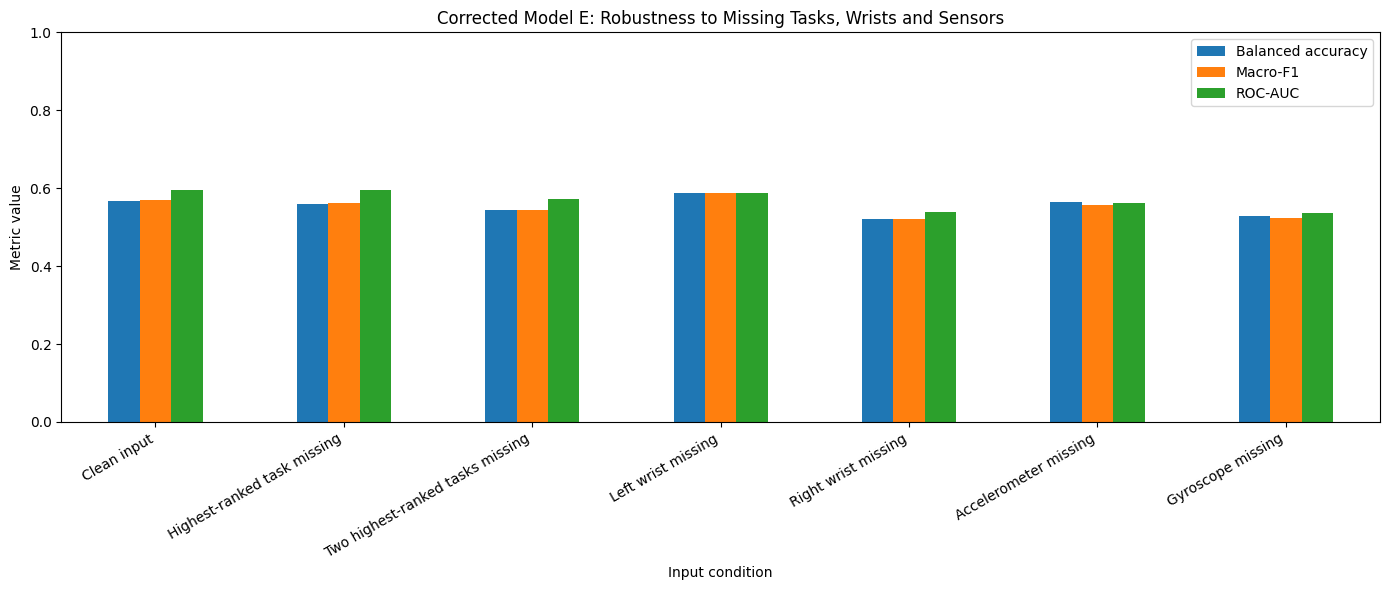

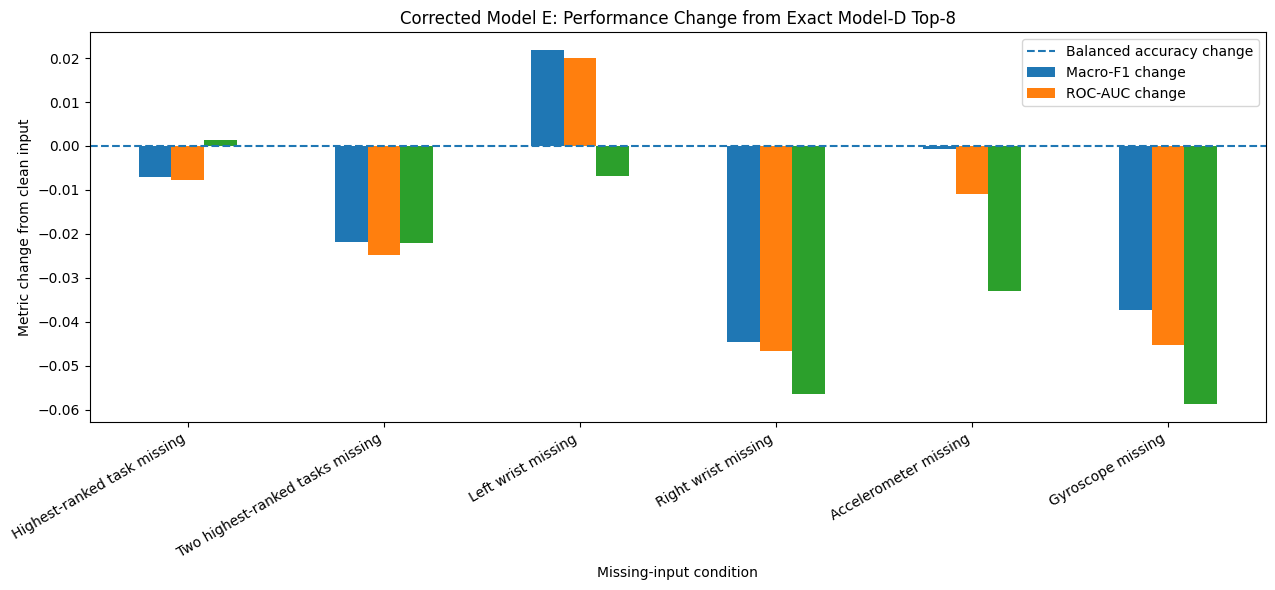

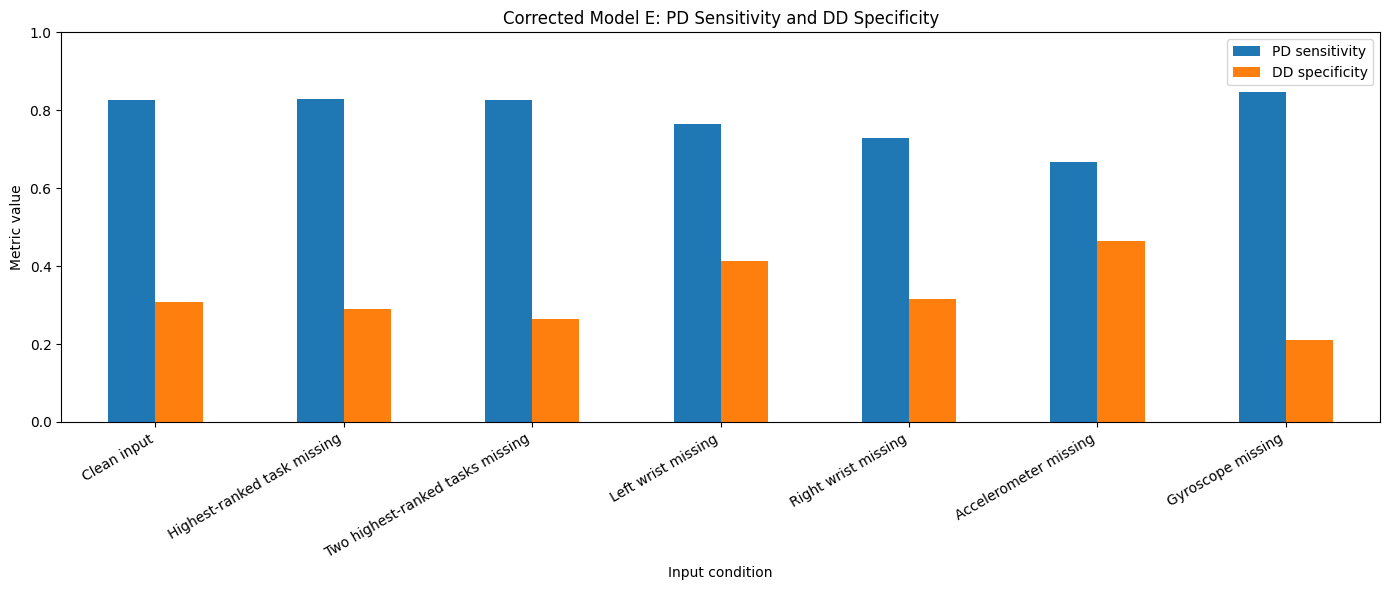

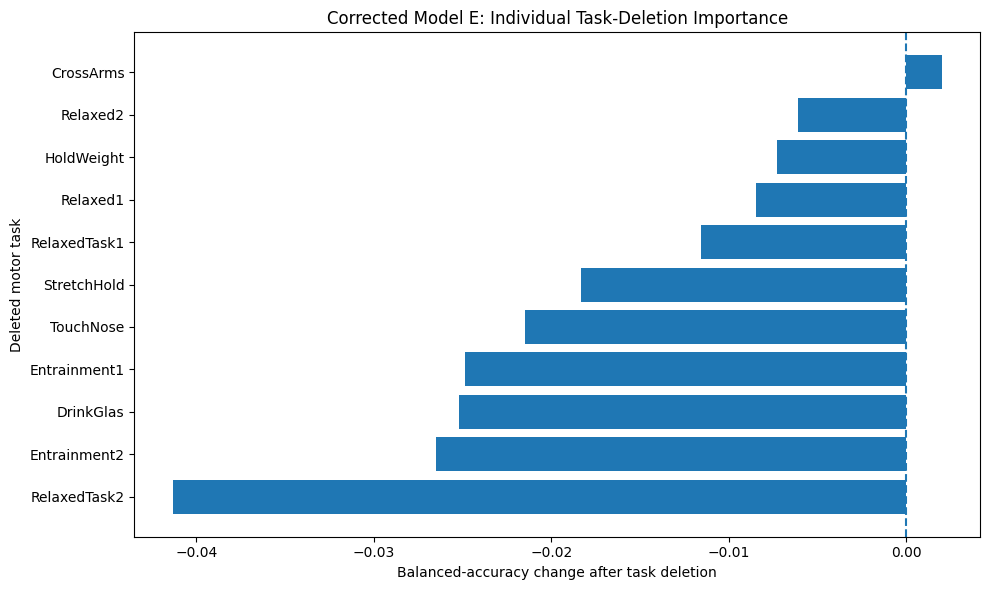

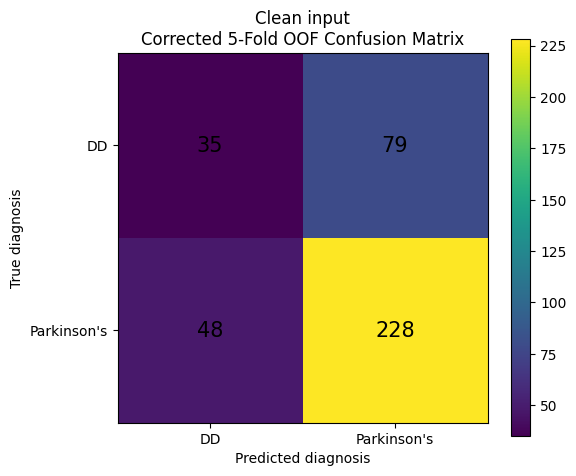

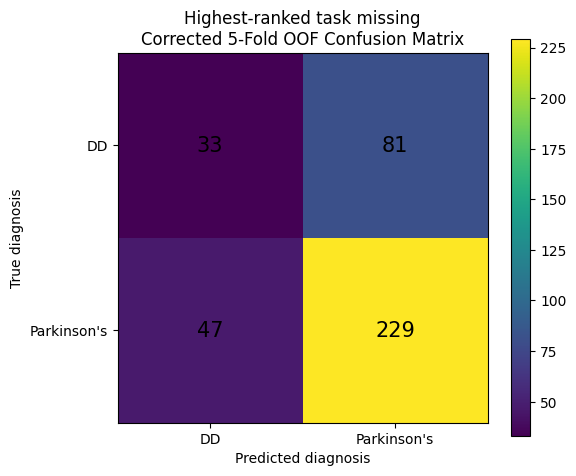

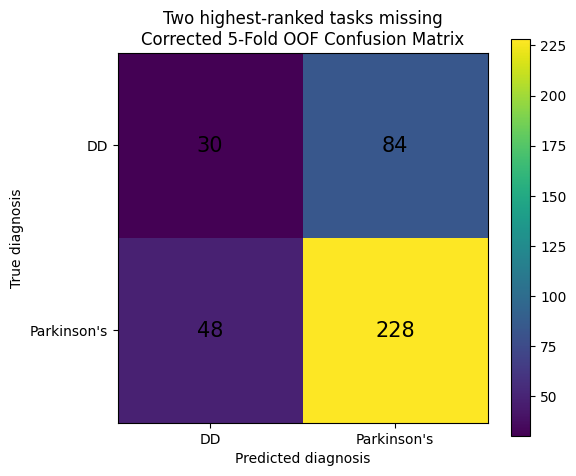

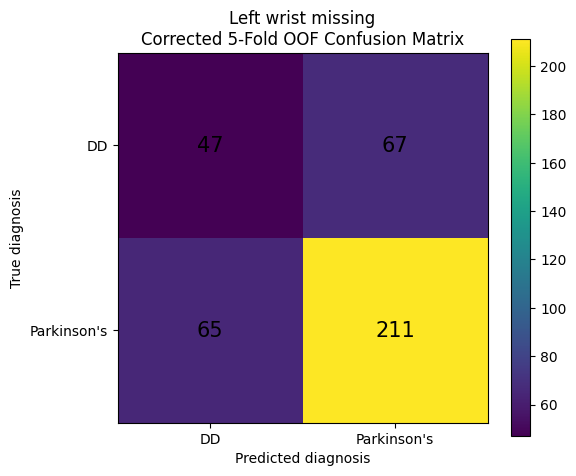

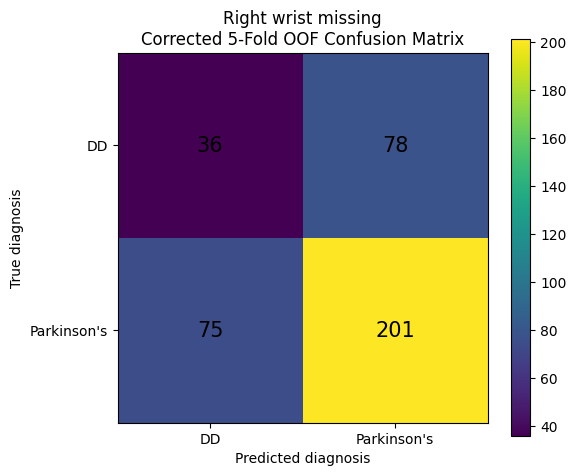

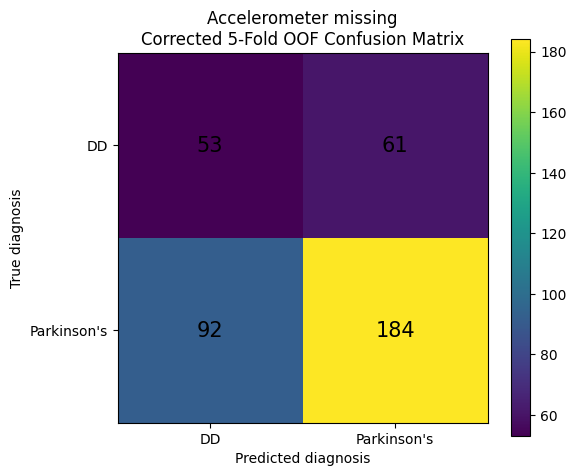

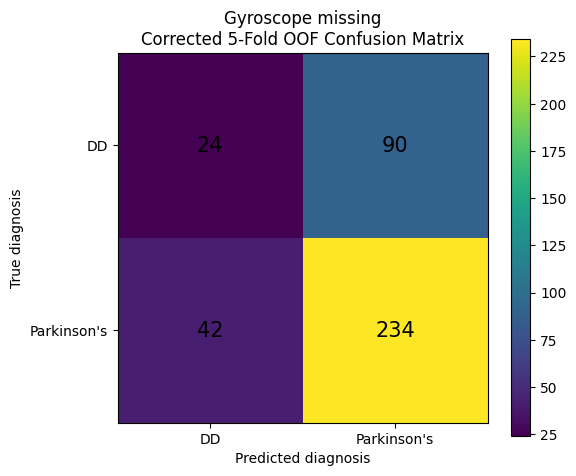

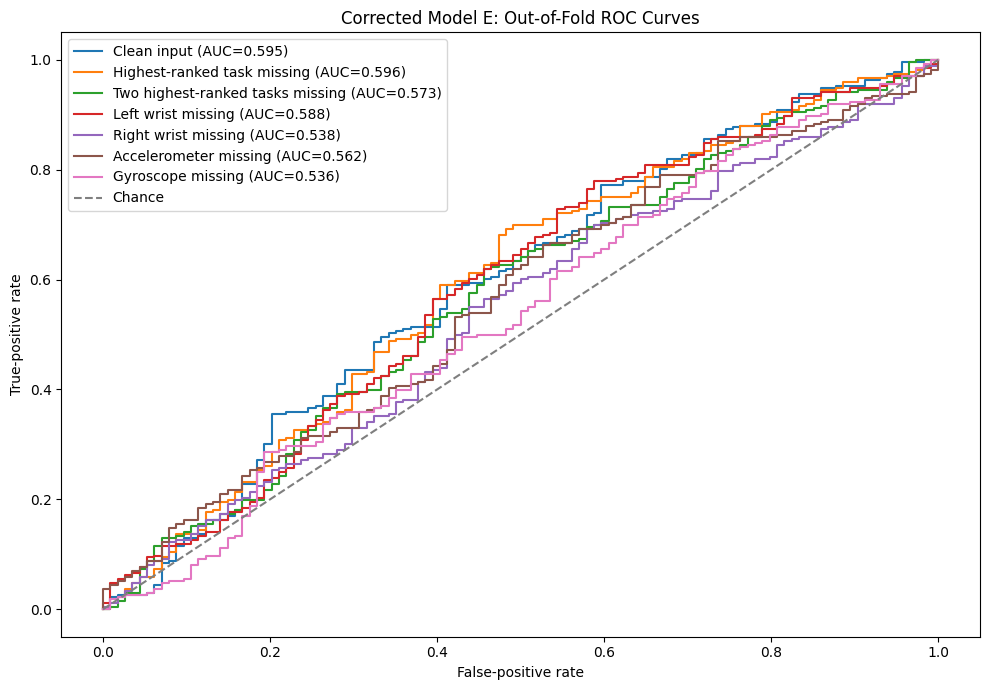


CORRECTED MODEL E COMPLETE

Model-D reproduction verification:

 selected_task_count  patients  maximum_probability_difference  mean_probability_difference  probability_tolerance  probabilities_match  matching_predicted_labels  all_labels_match
                   8       390                             0.0                          0.0               0.000001                 True                        390              True

Corrected robustness results:

           scenario_display_name  balanced_accuracy  macro_f1  sensitivity_pd  specificity_dd  roc_auc  pr_auc  brier_score  ece_10_bins  balanced_accuracy_change_from_clean  balanced_accuracy_retained_percent
                     Clean input             0.5666    0.5687          0.8261          0.3070   0.5947  0.7503       0.2254       0.1283                               0.0000                            100.0000
     Highest-ranked task missing             0.5596    0.5609          0.8297          0.2895   0.5960  0.7549       0.22

In [ ]:
# ==================================================================================================
# CORRECTED MODEL E
# EXACT MODEL-D TOP-8 REPRODUCTION + MISSING TASK / WRIST / SENSOR ROBUSTNESS
# COMPLETE ONE-CELL CODE
#
# CRITICAL CORRECTION:
# Model D final seed:
#   fold_seed = GLOBAL_SEED + outer_fold * 100
#   final_seed = fold_seed + task_count * 10000
#
# For Top-8:
#   final_seed = 42 + outer_fold * 100 + 80000
#
# This cell verifies that clean Model-E predictions reproduce the saved
# Model-D Top-8 patient-level predictions before accepting robustness results.
# ==================================================================================================

import os
import gc
import sys
import ast
import json
import time
import random
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ==================================================================================================
# 1. IMPORT / INSTALL PACKAGES
# ==================================================================================================

try:
    import xgboost as xgb
except ImportError:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "xgboost"
    ])
    import xgboost as xgb

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve
)

print("=" * 118)
print("CORRECTED MODEL E — EXACT MODEL-D REPRODUCTION + MISSING-INPUT ROBUSTNESS")
print("=" * 118)

print("XGBoost version:", xgb.__version__)

# ==================================================================================================
# 2. GLOBAL CONFIGURATION
# ==================================================================================================

GLOBAL_SEED = 42
SELECTED_TASK_COUNT = 8
PREDICTION_THRESHOLD = 0.50
N_BOOTSTRAPS = 2000

random.seed(int(GLOBAL_SEED))
np.random.seed(int(GLOBAL_SEED))

# ==================================================================================================
# 3. GPU CHECK
# ==================================================================================================

GPU_AVAILABLE = False

try:
    gpu_test_X = np.random.randn(
        20,
        4
    ).astype(np.float32)

    gpu_test_y = np.array(
        [0, 1] * 10,
        dtype=np.int32
    )

    gpu_test_model = xgb.XGBClassifier(
        n_estimators=2,
        max_depth=2,
        learning_rate=0.1,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        device="cuda",
        random_state=int(GLOBAL_SEED),
        verbosity=0
    )

    gpu_test_model.fit(
        gpu_test_X,
        gpu_test_y
    )

    GPU_AVAILABLE = True

    print("✅ XGBoost GPU test successful.")

    del (
        gpu_test_X,
        gpu_test_y,
        gpu_test_model
    )

    gc.collect()

except Exception as gpu_error:
    print("⚠️ GPU test failed. CPU fallback will be used.")
    print("GPU error:", str(gpu_error)[:500])

DEVICE = (
    "cuda"
    if GPU_AVAILABLE
    else "cpu"
)

# ==================================================================================================
# 4. PATHS
# ==================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = (
    BASE_DIR
    / "project_ready_data"
)

FEATURE_DIR = (
    PROJECT_DIR
    / "feature_engineering"
)

BASELINE_DIR = (
    PROJECT_DIR
    / "baseline_results"
)

PROPOSED_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
)

FEATURE_FILE = (
    FEATURE_DIR
    / "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = (
    BASELINE_DIR
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

MODEL_D_DIR = (
    PROPOSED_DIR
    / "model_d_nested_minimum_task_selection_xgboost"
)

SELECTED_TASK_FILE = (
    MODEL_D_DIR
    / "selected_tasks_by_fold_and_count.csv"
)

BEST_PARAMETER_FILE = (
    MODEL_D_DIR
    / "best_parameters_by_fold_and_task_count.csv"
)

MODEL_D_PREDICTION_FILE = (
    MODEL_D_DIR
    / "minimum_task_patient_predictions.csv"
)

OUTPUT_DIR = (
    PROPOSED_DIR
    / "model_e_corrected_exact_model_d_top8_robustness"
)

FIGURE_DIR = (
    OUTPUT_DIR
    / "figures"
)

for folder in [
    OUTPUT_DIR,
    FIGURE_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


def locate_required_file(
    expected_path,
    filename
):
    if expected_path.exists():
        return expected_path

    matches = list(
        BASE_DIR.rglob(filename)
    )

    if not matches:
        raise FileNotFoundError(
            f"Required file nahi mili: {filename}"
        )

    return matches[0]


FEATURE_FILE = locate_required_file(
    FEATURE_FILE,
    "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = locate_required_file(
    FIXED_SPLIT_FILE,
    "fixed_outer_5fold_splits.csv"
)

SELECTED_TASK_FILE = locate_required_file(
    SELECTED_TASK_FILE,
    "selected_tasks_by_fold_and_count.csv"
)

BEST_PARAMETER_FILE = locate_required_file(
    BEST_PARAMETER_FILE,
    "best_parameters_by_fold_and_task_count.csv"
)

MODEL_D_PREDICTION_FILE = locate_required_file(
    MODEL_D_PREDICTION_FILE,
    "minimum_task_patient_predictions.csv"
)

print("\nFiles:")
print("Feature table       :", FEATURE_FILE)
print("Fixed folds         :", FIXED_SPLIT_FILE)
print("Selected tasks      :", SELECTED_TASK_FILE)
print("Best parameters     :", BEST_PARAMETER_FILE)
print("Model-D predictions :", MODEL_D_PREDICTION_FILE)
print("Output directory    :", OUTPUT_DIR)
print("Device              :", DEVICE)

# ==================================================================================================
# 5. LOAD FEATURE TABLE
# ==================================================================================================

data = pd.read_csv(
    FEATURE_FILE
)

print(
    "\nComplete feature-table shape:",
    data.shape
)

possible_id_columns = [
    "patient_id",
    "id",
    "patient",
    "Patient_ID"
]

PATIENT_ID_COLUMN = next(
    (
        column
        for column in possible_id_columns
        if column in data.columns
    ),
    None
)

if PATIENT_ID_COLUMN is None:
    raise ValueError(
        "Patient-ID column identify nahi hui."
    )

possible_target_columns = [
    "y",
    "label",
    "target",
    "condition_2class",
    "diagnostic_group"
]

TARGET_COLUMN = next(
    (
        column
        for column in possible_target_columns
        if column in data.columns
    ),
    None
)

if TARGET_COLUMN is None:
    raise ValueError(
        "Target column identify nahi hui."
    )

data[PATIENT_ID_COLUMN] = (
    data[PATIENT_ID_COLUMN]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

# --------------------------------------------------------------------------------------------------
# Robust target conversion
# --------------------------------------------------------------------------------------------------

if pd.api.types.is_numeric_dtype(
    data[TARGET_COLUMN]
):
    numeric_target = pd.to_numeric(
        data[TARGET_COLUMN],
        errors="coerce"
    )

    unique_target_values = set(
        numeric_target
        .dropna()
        .unique()
    )

    if unique_target_values.issubset(
        {0, 1}
    ):
        y = (
            numeric_target
            .astype(int)
            .to_numpy()
        )

    elif unique_target_values.issubset(
        {1, 2}
    ):
        y = (
            numeric_target == 1
        ).astype(int).to_numpy()

    else:
        raise ValueError(
            "Unexpected numeric target values: "
            f"{sorted(unique_target_values)}"
        )

else:
    normalized_target = (
        data[TARGET_COLUMN]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    target_mapping = {
        "parkinson's": 1,
        "parkinsons": 1,
        "parkinson": 1,
        "pd": 1,
        "1": 1,

        "differential diagnosis": 0,
        "differential-diagnosis": 0,
        "other movement disorders": 0,
        "dd": 0,
        "0": 0
    }

    mapped_target = normalized_target.map(
        target_mapping
    )

    if mapped_target.isna().any():
        unknown_values = sorted(
            normalized_target[
                mapped_target.isna()
            ].unique()
        )

        raise ValueError(
            f"Unknown target values: {unknown_values}"
        )

    y = (
        mapped_target
        .astype(int)
        .to_numpy()
    )

patient_ids = (
    data[PATIENT_ID_COLUMN]
    .to_numpy()
)

N_PATIENTS = int(
    len(patient_ids)
)

if len(np.unique(patient_ids)) != N_PATIENTS:
    raise ValueError(
        "Duplicate patient IDs detected."
    )

print("Patients:", N_PATIENTS)
print("PD      :", int(np.sum(y == 1)))
print("DD      :", int(np.sum(y == 0)))

# ==================================================================================================
# 6. DEFINE TASKS AND FEATURE GROUPS
# ==================================================================================================

TASK_NAMES = [
    "Relaxed1",
    "Relaxed2",
    "RelaxedTask1",
    "RelaxedTask2",
    "StretchHold",
    "HoldWeight",
    "DrinkGlas",
    "CrossArms",
    "TouchNose",
    "Entrainment1",
    "Entrainment2"
]

metadata_columns = {
    PATIENT_ID_COLUMN,
    TARGET_COLUMN,
    "condition",
    "condition_original",
    "condition_3class",
    "diagnostic_group",
    "resource_type",
    "study_id",
    "disease_comment",
    "age",
    "age_at_diagnosis",
    "height",
    "weight",
    "gender",
    "handedness",
    "appearance_in_kinship",
    "appearance_in_first_grade_kinship",
    "effect_of_alcohol_on_tremor",
    "questionnaire",
    "group",
    "class",
    "target_name"
}

candidate_feature_columns = []

for column in data.columns:
    if column in metadata_columns:
        continue

    converted_column = pd.to_numeric(
        data[column],
        errors="coerce"
    )

    if converted_column.notna().sum() > 0:
        candidate_feature_columns.append(
            column
        )

X_dataframe = (
    data[candidate_feature_columns]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

task_to_features = {}

for task_name in TASK_NAMES:
    prefixes = [
        f"{task_name}__",
        f"{task_name}_",
        f"{task_name} "
    ]

    task_to_features[task_name] = [
        column
        for column in candidate_feature_columns
        if any(
            str(column).startswith(prefix)
            for prefix in prefixes
        )
    ]

print("\nFeature counts by task:")

for task_name in TASK_NAMES:
    print(
        f"{task_name:20s}: "
        f"{len(task_to_features[task_name])}"
    )

tasks_without_features = [
    task_name
    for task_name in TASK_NAMES
    if len(task_to_features[task_name]) == 0
]

if tasks_without_features:
    raise ValueError(
        "Features missing for tasks: "
        f"{tasks_without_features}"
    )

# ==================================================================================================
# 7. LOAD AND VERIFY FIXED FOLDS
# ==================================================================================================

fixed_splits = pd.read_csv(
    FIXED_SPLIT_FILE,
    dtype={"patient_id": str}
)

required_split_columns = {
    "patient_id",
    "fold",
    "role"
}

if not required_split_columns.issubset(
    fixed_splits.columns
):
    raise ValueError(
        "Fixed-fold file mein patient_id, fold aur role required hain."
    )

fixed_splits["patient_id"] = (
    fixed_splits["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

fixed_splits["fold"] = pd.to_numeric(
    fixed_splits["fold"],
    errors="raise"
).astype(int)

fixed_splits["role"] = (
    fixed_splits["role"]
    .astype(str)
    .str.lower()
    .str.strip()
)

AVAILABLE_FOLDS = [
    int(value)
    for value in sorted(
        fixed_splits["fold"].unique()
    )
]

if AVAILABLE_FOLDS != [1, 2, 3, 4, 5]:
    raise ValueError(
        f"Expected folds [1,2,3,4,5], found {AVAILABLE_FOLDS}."
    )

if set(
    fixed_splits["patient_id"]
) != set(patient_ids):
    raise ValueError(
        "Feature-table aur fixed-fold patient IDs match nahi karte."
    )

test_patient_frequency = (
    fixed_splits.loc[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if (
    len(test_patient_frequency) != N_PATIENTS
    or not (
        test_patient_frequency == 1
    ).all()
):
    raise ValueError(
        "Every patient must appear as outer-test exactly once."
    )

patient_to_index = {
    patient_id: index
    for index, patient_id
    in enumerate(patient_ids)
}

print(
    "\n✅ Same fixed five patient-level outer folds verified."
)

# ==================================================================================================
# 8. LOAD MODEL-D TOP-8 TASKS AND HYPERPARAMETERS
# ==================================================================================================

selected_task_table = pd.read_csv(
    SELECTED_TASK_FILE
)

parameter_table = pd.read_csv(
    BEST_PARAMETER_FILE
)

selected_task_table["outer_fold"] = (
    pd.to_numeric(
        selected_task_table["outer_fold"],
        errors="raise"
    )
    .astype(int)
)

selected_task_table["task_count"] = (
    pd.to_numeric(
        selected_task_table["task_count"],
        errors="raise"
    )
    .astype(int)
)

parameter_table["outer_fold"] = (
    pd.to_numeric(
        parameter_table["outer_fold"],
        errors="raise"
    )
    .astype(int)
)

parameter_table["task_count"] = (
    pd.to_numeric(
        parameter_table["task_count"],
        errors="raise"
    )
    .astype(int)
)

top8_task_table = selected_task_table.loc[
    selected_task_table["task_count"]
    == SELECTED_TASK_COUNT
].copy()

top8_parameter_table = parameter_table.loc[
    parameter_table["task_count"]
    == SELECTED_TASK_COUNT
].copy()

if len(top8_task_table) != 5:
    raise ValueError(
        "Expected five Top-8 selected-task rows; "
        f"found {len(top8_task_table)}."
    )

if len(top8_parameter_table) != 5:
    raise ValueError(
        "Expected five Top-8 parameter rows; "
        f"found {len(top8_parameter_table)}."
    )


def parse_selected_tasks(
    selected_task_value
):
    tasks = [
        task.strip()
        for task in str(
            selected_task_value
        ).split("|")
        if task.strip()
    ]

    return tasks


def parse_parameter_dictionary(
    parameter_value
):
    if isinstance(
        parameter_value,
        dict
    ):
        return parameter_value

    text = str(
        parameter_value
    ).strip()

    try:
        return json.loads(text)

    except Exception:
        return ast.literal_eval(text)


fold_to_tasks = {}
fold_to_parameters = {}

for _, row in top8_task_table.iterrows():
    fold_number = int(
        row["outer_fold"]
    )

    selected_tasks = parse_selected_tasks(
        row["selected_tasks"]
    )

    if len(selected_tasks) != SELECTED_TASK_COUNT:
        raise ValueError(
            f"Fold {fold_number} has "
            f"{len(selected_tasks)} tasks instead of 8."
        )

    unknown_tasks = [
        task
        for task in selected_tasks
        if task not in TASK_NAMES
    ]

    if unknown_tasks:
        raise ValueError(
            f"Unknown tasks in fold {fold_number}: "
            f"{unknown_tasks}"
        )

    fold_to_tasks[
        fold_number
    ] = selected_tasks

for _, row in top8_parameter_table.iterrows():
    fold_number = int(
        row["outer_fold"]
    )

    fold_to_parameters[
        fold_number
    ] = parse_parameter_dictionary(
        row["best_parameters"]
    )

print("\nFold-specific Top-8 configurations:")

for fold_number in AVAILABLE_FOLDS:
    model_d_fold_seed = int(
        GLOBAL_SEED
        + fold_number * 100
    )

    model_d_final_seed = int(
        model_d_fold_seed
        + SELECTED_TASK_COUNT * 10000
    )

    print(
        f"Fold {fold_number}: "
        f"{', '.join(fold_to_tasks[fold_number])}"
    )

    print(
        f"  Exact Model-D final seed: "
        f"{model_d_final_seed}"
    )

# ==================================================================================================
# 9. LOAD SAVED MODEL-D TOP-8 PREDICTIONS
# ==================================================================================================

model_d_predictions = pd.read_csv(
    MODEL_D_PREDICTION_FILE,
    dtype={"patient_id": str}
)

required_prediction_columns = {
    "patient_id",
    "task_count",
    "true_label",
    "predicted_probability_pd",
    "predicted_label"
}

if not required_prediction_columns.issubset(
    model_d_predictions.columns
):
    raise ValueError(
        "Model-D prediction file mein required columns missing hain: "
        f"{required_prediction_columns - set(model_d_predictions.columns)}"
    )

model_d_predictions["patient_id"] = (
    model_d_predictions["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

model_d_predictions["task_count"] = (
    pd.to_numeric(
        model_d_predictions["task_count"],
        errors="raise"
    )
    .astype(int)
)

model_d_top8_predictions = (
    model_d_predictions.loc[
        model_d_predictions["task_count"]
        == SELECTED_TASK_COUNT
    ]
    .copy()
)

if len(model_d_top8_predictions) != N_PATIENTS:
    raise ValueError(
        "Expected 390 Model-D Top-8 predictions; "
        f"found {len(model_d_top8_predictions)}."
    )

model_d_top8_predictions = (
    model_d_top8_predictions
    .set_index("patient_id")
    .loc[patient_ids]
    .reset_index()
)

if not np.array_equal(
    model_d_top8_predictions[
        "true_label"
    ].to_numpy(dtype=int),
    y
):
    raise ValueError(
        "Model-D Top-8 true labels current feature-table labels se match nahi karte."
    )

model_d_saved_probability = (
    model_d_top8_predictions[
        "predicted_probability_pd"
    ]
    .to_numpy(dtype=np.float32)
)

model_d_saved_prediction = (
    model_d_top8_predictions[
        "predicted_label"
    ]
    .to_numpy(dtype=np.int32)
)

print(
    "\n✅ Saved Model-D Top-8 patient predictions loaded."
)

# ==================================================================================================
# 10. FEATURE-DETECTION HELPERS
# ==================================================================================================

def feature_name_lower(
    column
):
    return str(column).lower()


def is_left_feature(
    column
):
    name = feature_name_lower(
        column
    )

    return (
        "__left__" in name
        or "_left_" in name
        or name.endswith("_left")
        or "__l__" in name
    )


def is_right_feature(
    column
):
    name = feature_name_lower(
        column
    )

    return (
        "__right__" in name
        or "_right_" in name
        or name.endswith("_right")
        or "__r__" in name
    )


def is_bilateral_or_asymmetry_feature(
    column
):
    name = feature_name_lower(
        column
    )

    bilateral_keywords = [
        "bilateral",
        "asymmetry",
        "asymmetric",
        "left_vs_right",
        "right_vs_left",
        "left-right",
        "right-left",
        "lr_difference",
        "rl_difference",
        "abs_difference",
        "wrist_difference"
    ]

    return any(
        keyword in name
        for keyword in bilateral_keywords
    )


def is_acceleration_feature(
    column
):
    name = feature_name_lower(
        column
    )

    acceleration_keywords = [
        "acceleration",
        "accelerometer",
        "__acc__",
        "_acc_",
        "acc_x",
        "acc_y",
        "acc_z"
    ]

    return any(
        keyword in name
        for keyword in acceleration_keywords
    )


def is_rotation_feature(
    column
):
    name = feature_name_lower(
        column
    )

    rotation_keywords = [
        "rotation",
        "gyroscope",
        "gyro",
        "__gyr__",
        "_gyr_",
        "rot_x",
        "rot_y",
        "rot_z"
    ]

    return any(
        keyword in name
        for keyword in rotation_keywords
    )


def features_for_selected_tasks(
    selected_tasks
):
    feature_columns = []

    for task_name in selected_tasks:
        feature_columns.extend(
            task_to_features[
                task_name
            ]
        )

    return list(
        dict.fromkeys(
            feature_columns
        )
    )


def features_for_one_task(
    selected_feature_columns,
    task_name
):
    task_feature_set = set(
        task_to_features[
            task_name
        ]
    )

    return [
        column
        for column in selected_feature_columns
        if column in task_feature_set
    ]

# ==================================================================================================
# 11. PREPROCESSING — SAME AS MODEL D
# ==================================================================================================

def fit_preprocessor(
    training_dataframe
):
    imputer = SimpleImputer(
        strategy="median"
    )

    X_imputed = imputer.fit_transform(
        training_dataframe
    )

    variance_filter = VarianceThreshold(
        threshold=0.0
    )

    X_filtered = variance_filter.fit_transform(
        X_imputed
    )

    return (
        imputer,
        variance_filter,
        X_filtered.astype(np.float32)
    )


def transform_with_preprocessor(
    dataframe,
    imputer,
    variance_filter
):
    X_imputed = imputer.transform(
        dataframe
    )

    X_filtered = variance_filter.transform(
        X_imputed
    )

    return X_filtered.astype(
        np.float32
    )

# ==================================================================================================
# 12. XGBOOST MODEL — SAME AS MODEL D
# ==================================================================================================

def create_model_d_xgboost(
    best_parameters,
    exact_model_d_seed
):
    model_parameters = {
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "tree_method": "hist",
        "device": DEVICE,
        "random_state": int(
            exact_model_d_seed
        ),
        "n_jobs": 2,
        "verbosity": 0
    }

    model_parameters.update(
        best_parameters
    )

    return xgb.XGBClassifier(
        **model_parameters
    )

# ==================================================================================================
# 13. METRICS
# ==================================================================================================

def expected_calibration_error(
    y_true,
    probabilities,
    n_bins=10
):
    y_true = np.asarray(
        y_true,
        dtype=np.int32
    )

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(
        n_bins
    ):
        lower = bin_edges[
            bin_index
        ]

        upper = bin_edges[
            bin_index + 1
        ]

        if bin_index == n_bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if not np.any(mask):
            continue

        mean_probability = float(
            np.mean(
                probabilities[mask]
            )
        )

        observed_rate = float(
            np.mean(
                y_true[mask]
            )
        )

        ece += float(
            np.mean(mask)
        ) * abs(
            observed_rate
            - mean_probability
        )

    return float(ece)


def calculate_metrics(
    y_true,
    predicted_labels,
    predicted_probabilities
):
    y_true = np.asarray(
        y_true,
        dtype=np.int32
    )

    predicted_labels = np.asarray(
        predicted_labels,
        dtype=np.int32
    )

    predicted_probabilities = np.asarray(
        predicted_probabilities,
        dtype=np.float64
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predicted_labels,
        labels=[0, 1]
    ).ravel()

    sensitivity_pd = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity_dd = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            predicted_labels
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predicted_labels
        ),

        "macro_f1": f1_score(
            y_true,
            predicted_labels,
            average="macro",
            zero_division=0
        ),

        "pd_f1": f1_score(
            y_true,
            predicted_labels,
            pos_label=1,
            zero_division=0
        ),

        "dd_f1": f1_score(
            y_true,
            predicted_labels,
            pos_label=0,
            zero_division=0
        ),

        "precision_pd": precision_score(
            y_true,
            predicted_labels,
            pos_label=1,
            zero_division=0
        ),

        "sensitivity_pd": sensitivity_pd,

        "specificity_dd": specificity_dd,

        "roc_auc": roc_auc_score(
            y_true,
            predicted_probabilities
        ),

        "pr_auc": average_precision_score(
            y_true,
            predicted_probabilities
        ),

        "brier_score": brier_score_loss(
            y_true,
            predicted_probabilities
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            predicted_probabilities,
            n_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }

# ==================================================================================================
# 14. MISSINGNESS SCENARIOS
# ==================================================================================================

PRIMARY_SCENARIOS = [
    "clean",
    "highest_ranked_task_missing",
    "two_highest_ranked_tasks_missing",
    "left_wrist_missing",
    "right_wrist_missing",
    "acceleration_missing",
    "rotation_missing"
]

SCENARIO_DISPLAY_NAMES = {
    "clean": "Clean input",
    "highest_ranked_task_missing": "Highest-ranked task missing",
    "two_highest_ranked_tasks_missing": "Two highest-ranked tasks missing",
    "left_wrist_missing": "Left wrist missing",
    "right_wrist_missing": "Right wrist missing",
    "acceleration_missing": "Accelerometer missing",
    "rotation_missing": "Gyroscope missing"
}


def apply_missingness(
    clean_dataframe,
    selected_feature_columns,
    selected_tasks,
    scenario_name
):
    modified_dataframe = (
        clean_dataframe.copy()
    )

    missing_columns = []

    if scenario_name == "clean":
        return (
            modified_dataframe,
            missing_columns
        )

    if scenario_name == (
        "highest_ranked_task_missing"
    ):
        missing_columns = (
            features_for_one_task(
                selected_feature_columns,
                selected_tasks[0]
            )
        )

    elif scenario_name == (
        "two_highest_ranked_tasks_missing"
    ):
        for task_name in selected_tasks[:2]:
            missing_columns.extend(
                features_for_one_task(
                    selected_feature_columns,
                    task_name
                )
            )

    elif scenario_name == (
        "left_wrist_missing"
    ):
        missing_columns = [
            column
            for column in selected_feature_columns
            if (
                is_left_feature(column)
                or is_bilateral_or_asymmetry_feature(
                    column
                )
            )
        ]

    elif scenario_name == (
        "right_wrist_missing"
    ):
        missing_columns = [
            column
            for column in selected_feature_columns
            if (
                is_right_feature(column)
                or is_bilateral_or_asymmetry_feature(
                    column
                )
            )
        ]

    elif scenario_name == (
        "acceleration_missing"
    ):
        missing_columns = [
            column
            for column in selected_feature_columns
            if is_acceleration_feature(
                column
            )
        ]

    elif scenario_name == (
        "rotation_missing"
    ):
        missing_columns = [
            column
            for column in selected_feature_columns
            if is_rotation_feature(
                column
            )
        ]

    elif scenario_name.startswith(
        "individual_task_missing__"
    ):
        task_name = scenario_name.split(
            "__",
            1
        )[1]

        missing_columns = (
            features_for_one_task(
                selected_feature_columns,
                task_name
            )
        )

    else:
        raise ValueError(
            "Unknown scenario: "
            f"{scenario_name}"
        )

    missing_columns = list(
        dict.fromkeys(
            missing_columns
        )
    )

    if missing_columns:
        modified_dataframe.loc[
            :,
            missing_columns
        ] = np.nan

    return (
        modified_dataframe,
        missing_columns
    )

# ==================================================================================================
# 15. STORAGE
# ==================================================================================================

scenario_probability_storage = {
    scenario_name: np.full(
        N_PATIENTS,
        np.nan,
        dtype=np.float32
    )
    for scenario_name in PRIMARY_SCENARIOS
}

scenario_prediction_storage = {
    scenario_name: np.full(
        N_PATIENTS,
        -1,
        dtype=np.int32
    )
    for scenario_name in PRIMARY_SCENARIOS
}

oof_fold = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

fold_scenario_rows = []
removed_feature_rows = []
individual_task_prediction_rows = []
seed_verification_rows = []

total_start_time = time.time()

# ==================================================================================================
# 16. EXACT MODEL-D REPRODUCTION AND ROBUSTNESS EVALUATION
# ==================================================================================================

print("\n" + "=" * 118)
print("STARTING EXACT MODEL-D TOP-8 REPRODUCTION")
print("=" * 118)

for raw_fold_number in AVAILABLE_FOLDS:
    fold_number = int(
        raw_fold_number
    )

    fold_start_time = time.time()

    # ----------------------------------------------------------------------------------------------
    # Exact seeds copied from Model D
    # ----------------------------------------------------------------------------------------------

    model_d_fold_seed = int(
        GLOBAL_SEED
        + fold_number * 100
    )

    model_d_final_seed = int(
        model_d_fold_seed
        + SELECTED_TASK_COUNT * 10000
    )

    random.seed(
        int(model_d_final_seed)
    )

    np.random.seed(
        int(model_d_final_seed)
    )

    selected_tasks = fold_to_tasks[
        fold_number
    ]

    selected_features = (
        features_for_selected_tasks(
            selected_tasks
        )
    )

    best_parameters = fold_to_parameters[
        fold_number
    ]

    current_fold_table = fixed_splits.loc[
        fixed_splits["fold"]
        == fold_number
    ]

    train_patient_ids = current_fold_table.loc[
        current_fold_table["role"]
        == "train",
        "patient_id"
    ].tolist()

    test_patient_ids = current_fold_table.loc[
        current_fold_table["role"]
        == "test",
        "patient_id"
    ].tolist()

    train_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id
        in train_patient_ids
    ], dtype=int)

    test_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id
        in test_patient_ids
    ], dtype=int)

    if set(train_indices).intersection(
        set(test_indices)
    ):
        raise RuntimeError(
            f"Patient leakage detected in fold {fold_number}."
        )

    y_train = y[
        train_indices
    ]

    y_test = y[
        test_indices
    ]

    X_train_dataframe = X_dataframe.loc[
        train_indices,
        selected_features
    ].copy()

    X_test_clean_dataframe = X_dataframe.loc[
        test_indices,
        selected_features
    ].copy()

    (
        imputer,
        variance_filter,
        X_train
    ) = fit_preprocessor(
        X_train_dataframe
    )

    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train
    )

    model = create_model_d_xgboost(
        best_parameters=best_parameters,
        exact_model_d_seed=model_d_final_seed
    )

    model.fit(
        X_train,
        y_train,
        sample_weight=sample_weights,
        verbose=False
    )

    print("\n" + "-" * 105)
    print(
        f"OUTER FOLD {fold_number}/5"
    )
    print("-" * 105)

    print(
        f"Training: {len(train_indices)} "
        f"(PD={np.sum(y_train == 1)}, "
        f"DD={np.sum(y_train == 0)})"
    )

    print(
        f"Testing : {len(test_indices)} "
        f"(PD={np.sum(y_test == 1)}, "
        f"DD={np.sum(y_test == 0)})"
    )

    print(
        "Selected tasks:",
        ", ".join(selected_tasks)
    )

    print(
        "Selected features:",
        len(selected_features)
    )

    print(
        "Exact Model-D seed:",
        model_d_final_seed
    )

    # ----------------------------------------------------------------------------------------------
    # Evaluate all primary scenarios
    # ----------------------------------------------------------------------------------------------

    for scenario_name in PRIMARY_SCENARIOS:
        (
            scenario_dataframe,
            missing_columns
        ) = apply_missingness(
            clean_dataframe=(
                X_test_clean_dataframe
            ),
            selected_feature_columns=(
                selected_features
            ),
            selected_tasks=selected_tasks,
            scenario_name=scenario_name
        )

        X_scenario = transform_with_preprocessor(
            scenario_dataframe,
            imputer,
            variance_filter
        )

        scenario_probabilities = (
            model.predict_proba(
                X_scenario
            )[:, 1]
            .astype(np.float32)
        )

        scenario_predictions = (
            scenario_probabilities
            >= PREDICTION_THRESHOLD
        ).astype(np.int32)

        scenario_probability_storage[
            scenario_name
        ][test_indices] = (
            scenario_probabilities
        )

        scenario_prediction_storage[
            scenario_name
        ][test_indices] = (
            scenario_predictions
        )

        oof_fold[
            test_indices
        ] = fold_number

        scenario_metrics = calculate_metrics(
            y_test,
            scenario_predictions,
            scenario_probabilities
        )

        fold_scenario_rows.append({
            "outer_fold": fold_number,
            "exact_model_d_seed": (
                model_d_final_seed
            ),
            "scenario": scenario_name,
            "selected_tasks": " | ".join(
                selected_tasks
            ),
            "number_of_selected_tasks": (
                SELECTED_TASK_COUNT
            ),
            "number_of_input_features": (
                len(selected_features)
            ),
            "number_of_features_made_missing": (
                len(missing_columns)
            ),
            "percentage_features_made_missing": (
                100.0
                * len(missing_columns)
                / max(
                    len(selected_features),
                    1
                )
            ),
            **scenario_metrics
        })

        removed_feature_rows.append({
            "outer_fold": fold_number,
            "scenario": scenario_name,
            "removed_feature_count": (
                len(missing_columns)
            ),
            "removed_features": " | ".join(
                missing_columns
            )
        })

        print(
            f"{scenario_name:38s} | "
            f"BA={scenario_metrics['balanced_accuracy']:.4f} | "
            f"F1={scenario_metrics['macro_f1']:.4f} | "
            f"PD sens={scenario_metrics['sensitivity_pd']:.4f} | "
            f"DD spec={scenario_metrics['specificity_dd']:.4f} | "
            f"AUC={scenario_metrics['roc_auc']:.4f}"
        )

        del (
            scenario_dataframe,
            X_scenario,
            scenario_probabilities,
            scenario_predictions
        )

    # ----------------------------------------------------------------------------------------------
    # Individual deletion of each selected task
    # ----------------------------------------------------------------------------------------------

    print("\nIndividual selected-task deletion:")

    for task_rank, task_name in enumerate(
        selected_tasks,
        start=1
    ):
        individual_scenario_name = (
            f"individual_task_missing__"
            f"{task_name}"
        )

        (
            task_missing_dataframe,
            task_missing_columns
        ) = apply_missingness(
            clean_dataframe=(
                X_test_clean_dataframe
            ),
            selected_feature_columns=(
                selected_features
            ),
            selected_tasks=selected_tasks,
            scenario_name=(
                individual_scenario_name
            )
        )

        X_task_missing = transform_with_preprocessor(
            task_missing_dataframe,
            imputer,
            variance_filter
        )

        task_missing_probabilities = (
            model.predict_proba(
                X_task_missing
            )[:, 1]
            .astype(np.float32)
        )

        task_missing_predictions = (
            task_missing_probabilities
            >= PREDICTION_THRESHOLD
        ).astype(np.int32)

        task_missing_metrics = calculate_metrics(
            y_test,
            task_missing_predictions,
            task_missing_probabilities
        )

        for local_index, patient_index in enumerate(
            test_indices
        ):
            individual_task_prediction_rows.append({
                "patient_id": (
                    patient_ids[
                        patient_index
                    ]
                ),
                "outer_fold": fold_number,
                "exact_model_d_seed": (
                    model_d_final_seed
                ),
                "task_rank_in_fold": (
                    task_rank
                ),
                "missing_task": (
                    task_name
                ),
                "true_label": int(
                    y[
                        patient_index
                    ]
                ),
                "predicted_probability_pd": float(
                    task_missing_probabilities[
                        local_index
                    ]
                ),
                "predicted_label": int(
                    task_missing_predictions[
                        local_index
                    ]
                )
            })

        print(
            f"Rank {task_rank} — "
            f"{task_name:18s} | "
            f"BA={task_missing_metrics['balanced_accuracy']:.4f} | "
            f"AUC={task_missing_metrics['roc_auc']:.4f}"
        )

        del (
            task_missing_dataframe,
            X_task_missing,
            task_missing_probabilities,
            task_missing_predictions
        )

    # ----------------------------------------------------------------------------------------------
    # Fold-level reproduction check against saved Model-D clean predictions
    # ----------------------------------------------------------------------------------------------

    generated_clean_fold_probability = (
        scenario_probability_storage[
            "clean"
        ][test_indices]
    )

    saved_clean_fold_probability = (
        model_d_saved_probability[
            test_indices
        ]
    )

    absolute_differences = np.abs(
        generated_clean_fold_probability
        - saved_clean_fold_probability
    )

    fold_max_difference = float(
        np.max(
            absolute_differences
        )
    )

    fold_mean_difference = float(
        np.mean(
            absolute_differences
        )
    )

    generated_fold_labels = (
        scenario_prediction_storage[
            "clean"
        ][test_indices]
    )

    saved_fold_labels = (
        model_d_saved_prediction[
            test_indices
        ]
    )

    label_matches = int(
        np.sum(
            generated_fold_labels
            == saved_fold_labels
        )
    )

    seed_verification_rows.append({
        "outer_fold": fold_number,
        "exact_model_d_seed": (
            model_d_final_seed
        ),
        "test_patients": int(
            len(test_indices)
        ),
        "maximum_probability_difference": (
            fold_max_difference
        ),
        "mean_probability_difference": (
            fold_mean_difference
        ),
        "matching_predicted_labels": (
            label_matches
        ),
        "all_labels_match": bool(
            label_matches
            == len(test_indices)
        )
    })

    print("\nFold reproduction check:")
    print(
        "Maximum probability difference:",
        f"{fold_max_difference:.12f}"
    )

    print(
        "Mean probability difference   :",
        f"{fold_mean_difference:.12f}"
    )

    print(
        "Matching predicted labels     :",
        f"{label_matches}/{len(test_indices)}"
    )

    fold_runtime_minutes = (
        time.time()
        - fold_start_time
    ) / 60.0

    print(
        f"Fold {fold_number} completed in "
        f"{fold_runtime_minutes:.3f} minutes."
    )

    del (
        X_train_dataframe,
        X_test_clean_dataframe,
        X_train,
        imputer,
        variance_filter,
        model
    )

    gc.collect()

total_runtime_minutes = (
    time.time()
    - total_start_time
) / 60.0

# ==================================================================================================
# 17. VERIFY COMPLETE PREDICTIONS
# ==================================================================================================

for scenario_name in PRIMARY_SCENARIOS:
    if np.isnan(
        scenario_probability_storage[
            scenario_name
        ]
    ).any():
        raise RuntimeError(
            f"Missing probabilities for scenario: {scenario_name}"
        )

    if np.any(
        scenario_prediction_storage[
            scenario_name
        ] < 0
    ):
        raise RuntimeError(
            f"Missing labels for scenario: {scenario_name}"
        )

if np.any(
    oof_fold < 1
):
    raise RuntimeError(
        "Some patients do not have an outer-fold assignment."
    )

# ==================================================================================================
# 18. GLOBAL MODEL-D REPRODUCTION CHECK
# ==================================================================================================

corrected_clean_probability = (
    scenario_probability_storage[
        "clean"
    ]
)

corrected_clean_prediction = (
    scenario_prediction_storage[
        "clean"
    ]
)

global_absolute_difference = np.abs(
    corrected_clean_probability
    - model_d_saved_probability
)

global_max_difference = float(
    np.max(
        global_absolute_difference
    )
)

global_mean_difference = float(
    np.mean(
        global_absolute_difference
    )
)

global_label_match_count = int(
    np.sum(
        corrected_clean_prediction
        == model_d_saved_prediction
    )
)

all_labels_match = bool(
    global_label_match_count
    == N_PATIENTS
)

# Float tolerance allows only negligible numerical variation.
REPRODUCTION_TOLERANCE = 1e-6

probabilities_match = bool(
    global_max_difference
    <= REPRODUCTION_TOLERANCE
)

print("\n" + "=" * 118)
print("GLOBAL MODEL-D TOP-8 REPRODUCTION CHECK")
print("=" * 118)

print(
    "Maximum probability difference:",
    f"{global_max_difference:.12f}"
)

print(
    "Mean probability difference   :",
    f"{global_mean_difference:.12f}"
)

print(
    "Matching predicted labels     :",
    f"{global_label_match_count}/{N_PATIENTS}"
)

print(
    "Probability tolerance         :",
    REPRODUCTION_TOLERANCE
)

print(
    "Probabilities match           :",
    probabilities_match
)

print(
    "All labels match              :",
    all_labels_match
)

seed_verification_df = pd.DataFrame(
    seed_verification_rows
)

global_verification_df = pd.DataFrame([
    {
        "selected_task_count": (
            SELECTED_TASK_COUNT
        ),
        "patients": N_PATIENTS,
        "maximum_probability_difference": (
            global_max_difference
        ),
        "mean_probability_difference": (
            global_mean_difference
        ),
        "probability_tolerance": (
            REPRODUCTION_TOLERANCE
        ),
        "probabilities_match": (
            probabilities_match
        ),
        "matching_predicted_labels": (
            global_label_match_count
        ),
        "all_labels_match": (
            all_labels_match
        )
    }
])

seed_verification_df.to_csv(
    OUTPUT_DIR
    / "fold_level_model_d_reproduction_check.csv",
    index=False
)

global_verification_df.to_csv(
    OUTPUT_DIR
    / "global_model_d_reproduction_check.csv",
    index=False
)

if not probabilities_match or not all_labels_match:
    raise RuntimeError(
        "\nClean corrected Model-E predictions saved Model-D Top-8 "
        "predictions ko exactly reproduce nahi kar rahi.\n"
        f"Maximum probability difference = {global_max_difference}\n"
        f"Matching labels = {global_label_match_count}/{N_PATIENTS}\n\n"
        "Robustness results ko final use na karein. "
        "Feature table, XGBoost version, selected-task file aur "
        "Model-D prediction file verify karein."
    )

print(
    "\n✅ Clean Model-E predictions exactly reproduce "
    "the saved Model-D Top-8 experiment."
)

# ==================================================================================================
# 19. OVERALL ROBUSTNESS METRICS
# ==================================================================================================

clean_metrics = calculate_metrics(
    y,
    corrected_clean_prediction,
    corrected_clean_probability
)

overall_robustness_rows = []
patient_prediction_rows = []

for scenario_name in PRIMARY_SCENARIOS:
    probabilities = (
        scenario_probability_storage[
            scenario_name
        ]
    )

    predictions = (
        scenario_prediction_storage[
            scenario_name
        ]
    )

    metrics = calculate_metrics(
        y,
        predictions,
        probabilities
    )

    overall_robustness_rows.append({
        "scenario": scenario_name,
        "scenario_display_name": (
            SCENARIO_DISPLAY_NAMES[
                scenario_name
            ]
        ),
        **metrics,
        "balanced_accuracy_change_from_clean": (
            metrics["balanced_accuracy"]
            - clean_metrics["balanced_accuracy"]
        ),
        "macro_f1_change_from_clean": (
            metrics["macro_f1"]
            - clean_metrics["macro_f1"]
        ),
        "roc_auc_change_from_clean": (
            metrics["roc_auc"]
            - clean_metrics["roc_auc"]
        ),
        "pr_auc_change_from_clean": (
            metrics["pr_auc"]
            - clean_metrics["pr_auc"]
        ),
        "balanced_accuracy_retained_percent": (
            100.0
            * metrics["balanced_accuracy"]
            / max(
                clean_metrics[
                    "balanced_accuracy"
                ],
                1e-8
            )
        )
    })

    for patient_index in range(
        N_PATIENTS
    ):
        patient_prediction_rows.append({
            "patient_id": (
                patient_ids[
                    patient_index
                ]
            ),
            "outer_fold": int(
                oof_fold[
                    patient_index
                ]
            ),
            "scenario": (
                scenario_name
            ),
            "true_label": int(
                y[
                    patient_index
                ]
            ),
            "predicted_probability_pd": float(
                probabilities[
                    patient_index
                ]
            ),
            "predicted_label": int(
                predictions[
                    patient_index
                ]
            ),
            "correct_prediction": int(
                predictions[
                    patient_index
                ]
                == y[
                    patient_index
                ]
            )
        })

overall_robustness_df = pd.DataFrame(
    overall_robustness_rows
)

patient_predictions_df = pd.DataFrame(
    patient_prediction_rows
)

fold_scenario_df = pd.DataFrame(
    fold_scenario_rows
)

removed_features_df = pd.DataFrame(
    removed_feature_rows
)

individual_task_predictions_df = pd.DataFrame(
    individual_task_prediction_rows
)

# ==================================================================================================
# 20. PAIRED PATIENT-LEVEL BOOTSTRAP AGAINST CLEAN
# ==================================================================================================

paired_metric_names = [
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins"
]

bootstrap_rng = np.random.default_rng(
    int(GLOBAL_SEED)
)

paired_bootstrap_rows = []
paired_ci_rows = []

for scenario_name in PRIMARY_SCENARIOS:
    if scenario_name == "clean":
        continue

    scenario_predictions = (
        scenario_prediction_storage[
            scenario_name
        ]
    )

    scenario_probabilities = (
        scenario_probability_storage[
            scenario_name
        ]
    )

    observed_scenario_metrics = (
        calculate_metrics(
            y,
            scenario_predictions,
            scenario_probabilities
        )
    )

    metric_delta_storage = {
        metric_name: []
        for metric_name in paired_metric_names
    }

    for bootstrap_iteration in range(
        N_BOOTSTRAPS
    ):
        sampled_indices = (
            bootstrap_rng.integers(
                low=0,
                high=N_PATIENTS,
                size=N_PATIENTS
            )
        )

        sampled_y = y[
            sampled_indices
        ]

        if len(
            np.unique(sampled_y)
        ) < 2:
            continue

        sampled_clean_metrics = (
            calculate_metrics(
                sampled_y,
                corrected_clean_prediction[
                    sampled_indices
                ],
                corrected_clean_probability[
                    sampled_indices
                ]
            )
        )

        sampled_scenario_metrics = (
            calculate_metrics(
                sampled_y,
                scenario_predictions[
                    sampled_indices
                ],
                scenario_probabilities[
                    sampled_indices
                ]
            )
        )

        bootstrap_row = {
            "scenario": scenario_name,
            "bootstrap_iteration": int(
                bootstrap_iteration
            )
        }

        for metric_name in paired_metric_names:
            metric_delta = (
                sampled_scenario_metrics[
                    metric_name
                ]
                - sampled_clean_metrics[
                    metric_name
                ]
            )

            metric_delta_storage[
                metric_name
            ].append(
                metric_delta
            )

            bootstrap_row[
                f"delta_{metric_name}"
            ] = metric_delta

        paired_bootstrap_rows.append(
            bootstrap_row
        )

    for metric_name in paired_metric_names:
        delta_values = np.asarray(
            metric_delta_storage[
                metric_name
            ],
            dtype=np.float64
        )

        observed_delta = (
            observed_scenario_metrics[
                metric_name
            ]
            - clean_metrics[
                metric_name
            ]
        )

        paired_ci_rows.append({
            "scenario": scenario_name,
            "metric": metric_name,
            "clean_value": (
                clean_metrics[
                    metric_name
                ]
            ),
            "scenario_value": (
                observed_scenario_metrics[
                    metric_name
                ]
            ),
            "observed_delta": (
                observed_delta
            ),
            "delta_ci_95_lower": float(
                np.percentile(
                    delta_values,
                    2.5
                )
            ),
            "delta_ci_95_upper": float(
                np.percentile(
                    delta_values,
                    97.5
                )
            ),
            "bootstrap_probability_delta_below_zero": float(
                np.mean(
                    delta_values < 0
                )
            )
        })

paired_bootstrap_df = pd.DataFrame(
    paired_bootstrap_rows
)

paired_ci_df = pd.DataFrame(
    paired_ci_rows
)

# ==================================================================================================
# 21. INDIVIDUAL TASK-DELETION SUMMARY
# ==================================================================================================

individual_task_summary_rows = []

for task_name in TASK_NAMES:
    task_rows = (
        individual_task_predictions_df.loc[
            individual_task_predictions_df[
                "missing_task"
            ] == task_name
        ]
    )

    if task_rows.empty:
        continue

    task_y = (
        task_rows[
            "true_label"
        ]
        .to_numpy(dtype=np.int32)
    )

    task_probabilities = (
        task_rows[
            "predicted_probability_pd"
        ]
        .to_numpy(dtype=np.float32)
    )

    task_predictions = (
        task_rows[
            "predicted_label"
        ]
        .to_numpy(dtype=np.int32)
    )

    task_metrics = calculate_metrics(
        task_y,
        task_predictions,
        task_probabilities
    )

    individual_task_summary_rows.append({
        "missing_task": task_name,
        "number_of_test_occurrences": int(
            len(task_rows)
        ),
        **task_metrics,
        "balanced_accuracy_change_from_clean": (
            task_metrics[
                "balanced_accuracy"
            ]
            - clean_metrics[
                "balanced_accuracy"
            ]
        ),
        "macro_f1_change_from_clean": (
            task_metrics[
                "macro_f1"
            ]
            - clean_metrics[
                "macro_f1"
            ]
        ),
        "roc_auc_change_from_clean": (
            task_metrics[
                "roc_auc"
            ]
            - clean_metrics[
                "roc_auc"
            ]
        )
    })

individual_task_summary_df = pd.DataFrame(
    individual_task_summary_rows
)

if not individual_task_summary_df.empty:
    individual_task_summary_df = (
        individual_task_summary_df
        .sort_values(
            "balanced_accuracy_change_from_clean"
        )
    )

# ==================================================================================================
# 22. FINAL ROBUSTNESS SUMMARY
# ==================================================================================================

missing_condition_df = (
    overall_robustness_df.loc[
        overall_robustness_df[
            "scenario"
        ] != "clean"
    ]
)

mean_missing_balanced_accuracy = float(
    missing_condition_df[
        "balanced_accuracy"
    ].mean()
)

worst_case_balanced_accuracy = float(
    missing_condition_df[
        "balanced_accuracy"
    ].min()
)

mean_retained_balanced_accuracy = float(
    missing_condition_df[
        "balanced_accuracy_retained_percent"
    ].mean()
)

robustness_final_summary_df = pd.DataFrame([
    {
        "model": (
            "Model-D exact Top-8 GPU XGBoost"
        ),
        "clean_model_d_reproduced": True,
        "clean_balanced_accuracy": (
            clean_metrics[
                "balanced_accuracy"
            ]
        ),
        "clean_macro_f1": (
            clean_metrics[
                "macro_f1"
            ]
        ),
        "clean_roc_auc": (
            clean_metrics[
                "roc_auc"
            ]
        ),
        "mean_missing_scenario_balanced_accuracy": (
            mean_missing_balanced_accuracy
        ),
        "worst_case_balanced_accuracy": (
            worst_case_balanced_accuracy
        ),
        "mean_balanced_accuracy_retained_percent": (
            mean_retained_balanced_accuracy
        ),
        "number_of_primary_missing_scenarios": (
            len(PRIMARY_SCENARIOS) - 1
        ),
        "patients": N_PATIENTS,
        "outer_folds": 5,
        "selected_task_count": (
            SELECTED_TASK_COUNT
        ),
        "classification_threshold": (
            PREDICTION_THRESHOLD
        ),
        "training_augmentation_used": False,
        "missingness_introduced_on_outer_test_only": True,
        "total_runtime_minutes": (
            total_runtime_minutes
        )
    }
])

# ==================================================================================================
# 23. SAVE TABLES
# ==================================================================================================

overall_robustness_df.to_csv(
    OUTPUT_DIR
    / "corrected_robustness_overall_summary.csv",
    index=False
)

fold_scenario_df.to_csv(
    OUTPUT_DIR
    / "corrected_robustness_fold_results.csv",
    index=False
)

patient_predictions_df.to_csv(
    OUTPUT_DIR
    / "corrected_robustness_patient_predictions.csv",
    index=False
)

removed_features_df.to_csv(
    OUTPUT_DIR
    / "corrected_removed_features_by_scenario.csv",
    index=False
)

paired_bootstrap_df.to_csv(
    OUTPUT_DIR
    / "corrected_paired_bootstrap_vs_clean.csv",
    index=False
)

paired_ci_df.to_csv(
    OUTPUT_DIR
    / "corrected_paired_degradation_confidence_intervals.csv",
    index=False
)

individual_task_predictions_df.to_csv(
    OUTPUT_DIR
    / "corrected_individual_task_missing_predictions.csv",
    index=False
)

individual_task_summary_df.to_csv(
    OUTPUT_DIR
    / "corrected_individual_task_missing_summary.csv",
    index=False
)

robustness_final_summary_df.to_csv(
    OUTPUT_DIR
    / "corrected_robustness_final_summary.csv",
    index=False
)

# ==================================================================================================
# 24. FIGURE 1 — PRIMARY ROBUSTNESS METRICS
# ==================================================================================================

plot_df = (
    overall_robustness_df
    .set_index(
        "scenario_display_name"
    )
)

plt.figure(
    figsize=(14, 6)
)

plot_df[
    [
        "balanced_accuracy",
        "macro_f1",
        "roc_auc"
    ]
].plot(
    kind="bar",
    ax=plt.gca()
)

plt.xlabel("Input condition")
plt.ylabel("Metric value")

plt.title(
    "Corrected Model E: Robustness to Missing Tasks, Wrists and Sensors"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.ylim(
    0.0,
    1.0
)

plt.legend([
    "Balanced accuracy",
    "Macro-F1",
    "ROC-AUC"
])

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_corrected_primary_robustness_metrics.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 25. FIGURE 2 — CHANGE FROM CLEAN
# ==================================================================================================

change_plot_df = (
    overall_robustness_df.loc[
        overall_robustness_df[
            "scenario"
        ] != "clean"
    ]
    .set_index(
        "scenario_display_name"
    )
)

plt.figure(
    figsize=(13, 6)
)

change_plot_df[
    [
        "balanced_accuracy_change_from_clean",
        "macro_f1_change_from_clean",
        "roc_auc_change_from_clean"
    ]
].plot(
    kind="bar",
    ax=plt.gca()
)

plt.axhline(
    0.0,
    linestyle="--"
)

plt.xlabel("Missing-input condition")
plt.ylabel("Metric change from clean input")

plt.title(
    "Corrected Model E: Performance Change from Exact Model-D Top-8"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.legend([
    "Balanced accuracy change",
    "Macro-F1 change",
    "ROC-AUC change"
])

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_corrected_change_from_clean.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 26. FIGURE 3 — SENSITIVITY AND SPECIFICITY
# ==================================================================================================

plt.figure(
    figsize=(14, 6)
)

plot_df[
    [
        "sensitivity_pd",
        "specificity_dd"
    ]
].plot(
    kind="bar",
    ax=plt.gca()
)

plt.xlabel("Input condition")
plt.ylabel("Metric value")

plt.title(
    "Corrected Model E: PD Sensitivity and DD Specificity"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.ylim(
    0.0,
    1.0
)

plt.legend([
    "PD sensitivity",
    "DD specificity"
])

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "03_corrected_sensitivity_specificity.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 27. FIGURE 4 — INDIVIDUAL TASK DELETION
# ==================================================================================================

if not individual_task_summary_df.empty:
    task_plot_df = (
        individual_task_summary_df
        .sort_values(
            "balanced_accuracy_change_from_clean",
            ascending=True
        )
    )

    plt.figure(
        figsize=(10, 6)
    )

    plt.barh(
        task_plot_df[
            "missing_task"
        ],
        task_plot_df[
            "balanced_accuracy_change_from_clean"
        ]
    )

    plt.axvline(
        0.0,
        linestyle="--"
    )

    plt.xlabel(
        "Balanced-accuracy change after task deletion"
    )

    plt.ylabel(
        "Deleted motor task"
    )

    plt.title(
        "Corrected Model E: Individual Task-Deletion Importance"
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "04_corrected_individual_task_deletion.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ==================================================================================================
# 28. FIGURE 5 — CONFUSION MATRICES
# ==================================================================================================

for scenario_name in PRIMARY_SCENARIOS:
    confusion = confusion_matrix(
        y,
        scenario_prediction_storage[
            scenario_name
        ],
        labels=[0, 1]
    )

    plt.figure(
        figsize=(6, 5)
    )

    plt.imshow(
        confusion
    )

    plt.colorbar()

    plt.xticks(
        [0, 1],
        [
            "DD",
            "Parkinson's"
        ]
    )

    plt.yticks(
        [0, 1],
        [
            "DD",
            "Parkinson's"
        ]
    )

    plt.xlabel(
        "Predicted diagnosis"
    )

    plt.ylabel(
        "True diagnosis"
    )

    plt.title(
        f"{SCENARIO_DISPLAY_NAMES[scenario_name]}\n"
        "Corrected 5-Fold OOF Confusion Matrix"
    )

    for row_index in range(2):
        for column_index in range(2):
            plt.text(
                column_index,
                row_index,
                str(
                    confusion[
                        row_index,
                        column_index
                    ]
                ),
                ha="center",
                va="center",
                fontsize=15
            )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / (
            "05_corrected_confusion_"
            f"{scenario_name}.png"
        ),
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ==================================================================================================
# 29. FIGURE 6 — ROC CURVES
# ==================================================================================================

plt.figure(
    figsize=(10, 7)
)

for scenario_name in PRIMARY_SCENARIOS:
    false_positive_rate, true_positive_rate, _ = (
        roc_curve(
            y,
            scenario_probability_storage[
                scenario_name
            ]
        )
    )

    auc_value = roc_auc_score(
        y,
        scenario_probability_storage[
            scenario_name
        ]
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=(
            f"{SCENARIO_DISPLAY_NAMES[scenario_name]} "
            f"(AUC={auc_value:.3f})"
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

plt.xlabel(
    "False-positive rate"
)

plt.ylabel(
    "True-positive rate"
)

plt.title(
    "Corrected Model E: Out-of-Fold ROC Curves"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "06_corrected_roc_curves.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 30. FINAL OUTPUT
# ==================================================================================================

print("\n" + "=" * 118)
print("CORRECTED MODEL E COMPLETE")
print("=" * 118)

print("\nModel-D reproduction verification:\n")

print(
    global_verification_df
    .round(12)
    .to_string(
        index=False
    )
)

display_columns = [
    "scenario_display_name",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
    "balanced_accuracy_change_from_clean",
    "balanced_accuracy_retained_percent"
]

print("\nCorrected robustness results:\n")

print(
    overall_robustness_df[
        display_columns
    ]
    .round(4)
    .to_string(
        index=False
    )
)

print("\nFinal robustness summary:\n")

print(
    robustness_final_summary_df
    .round(4)
    .to_string(
        index=False
    )
)

if not individual_task_summary_df.empty:
    individual_display_columns = [
        "missing_task",
        "number_of_test_occurrences",
        "balanced_accuracy",
        "macro_f1",
        "roc_auc",
        "balanced_accuracy_change_from_clean"
    ]

    print(
        "\nIndividual task-deletion summary:\n"
    )

    print(
        individual_task_summary_df[
            individual_display_columns
        ]
        .round(4)
        .to_string(
            index=False
        )
    )

print("\nScientific verification:")
print("- Same 390 PD-versus-DD patients.")
print("- Same fixed five outer patient-level folds.")
print("- Same fold-specific Model-D Top-8 tasks.")
print("- Same fold-specific Model-D hyperparameters.")
print("- Exact Model-D final random seed reproduced.")
print("- Same feature order and preprocessing.")
print("- Clean predictions verified against saved Model-D predictions.")
print("- Missingness introduced only in untouched outer-test patients.")
print("- Training-fold median imputation used for unavailable inputs.")
print("- Balanced sample weights used in outer training.")
print("- No SMOTE, patient duplication or test leakage.")
print("- Same fixed threshold of 0.50.")
print("- Paired 2,000-sample patient-level bootstrap.")

print(
    f"\nTotal runtime: "
    f"{total_runtime_minutes:.3f} minutes"
)

print("\nSaved files:")

for saved_file in sorted(
    OUTPUT_DIR.rglob("*")
):
    if saved_file.is_file():
        print(
            " -",
            saved_file.relative_to(
                OUTPUT_DIR
            )
        )

print(
    "\n✅ CORRECTED MODEL E EXACT MODEL-D "
    "TOP-8 ROBUSTNESS ANALYSIS FINISHED."
)

## Model F2 - calibration and referral (sensor)

CORRECTED MODEL F2 — PLATT CALIBRATION, TUNED THRESHOLD AND SPECIALIST REFERRAL
XGBoost version: 3.3.0
✅ XGBoost GPU test successful.

Input files:
Feature table       : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Fixed folds         : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Selected tasks      : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_d_nested_minimum_task_selection_xgboost/selected_tasks_by_fold_and_count.csv
Best parameters     : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_d_nested_minimum_task_selection_xgboost/best_parameters_by_fold_and_task_count.csv
Model-D predictions : /content/pads_dataset/pads-parkinsons-disea

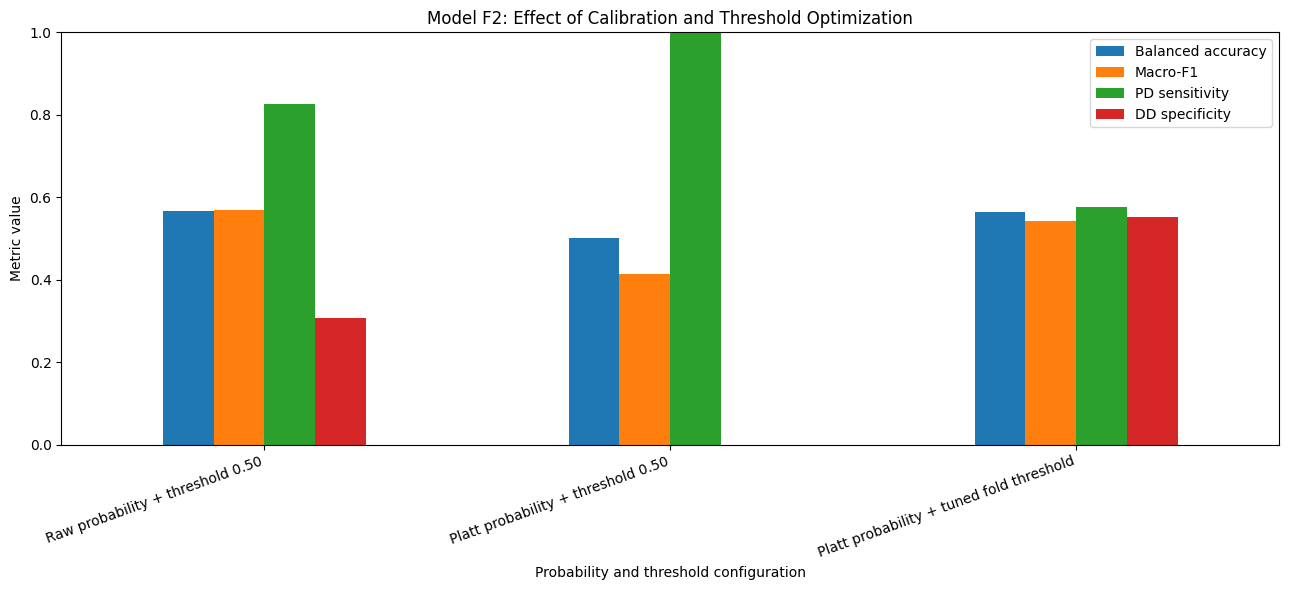

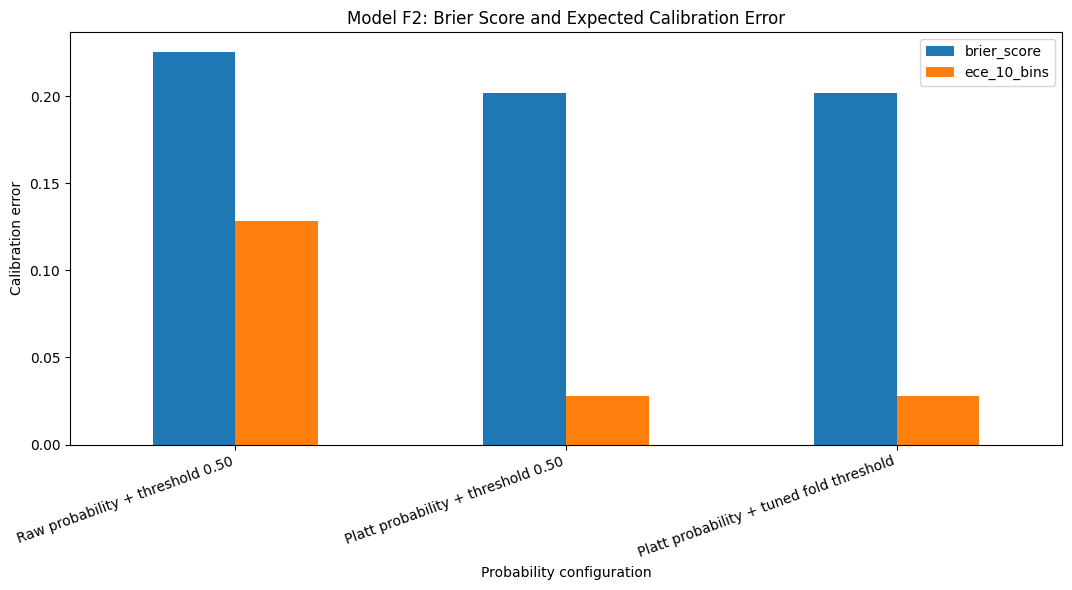

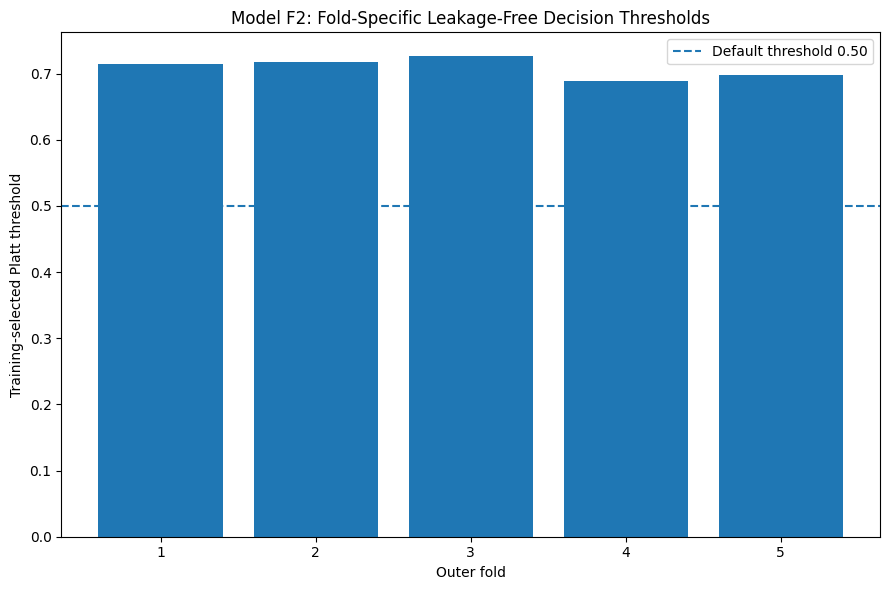

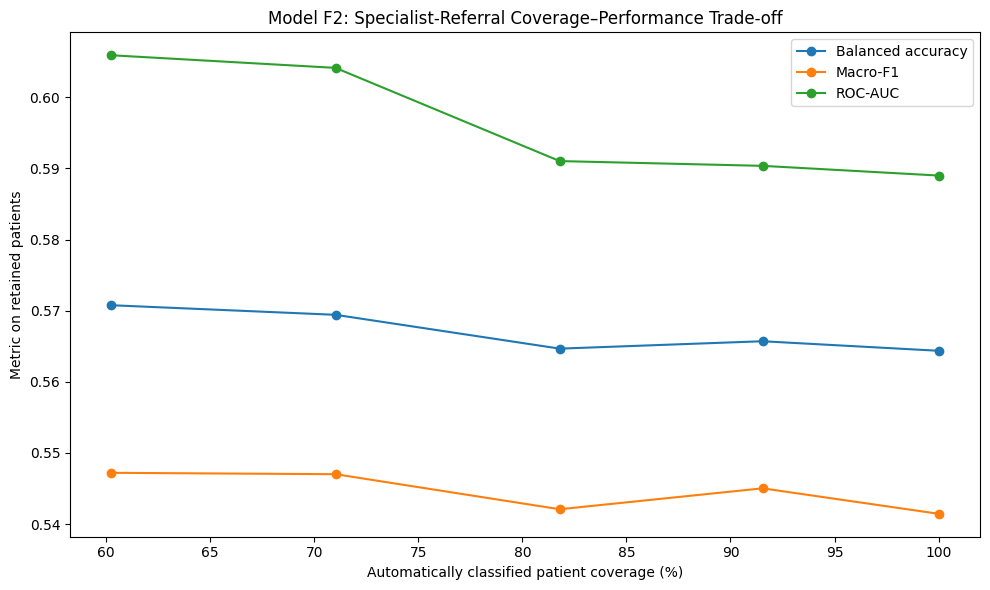

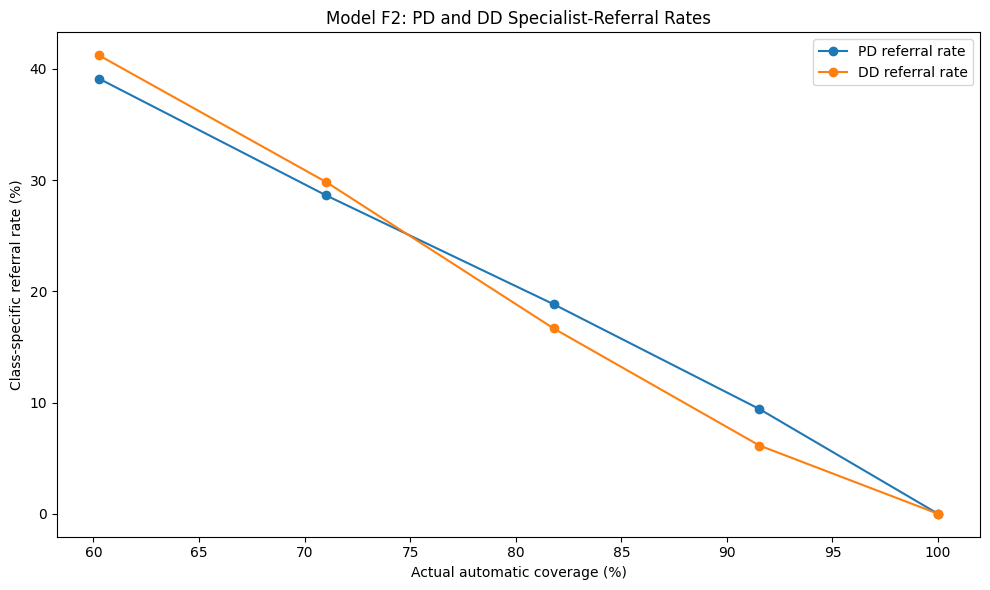

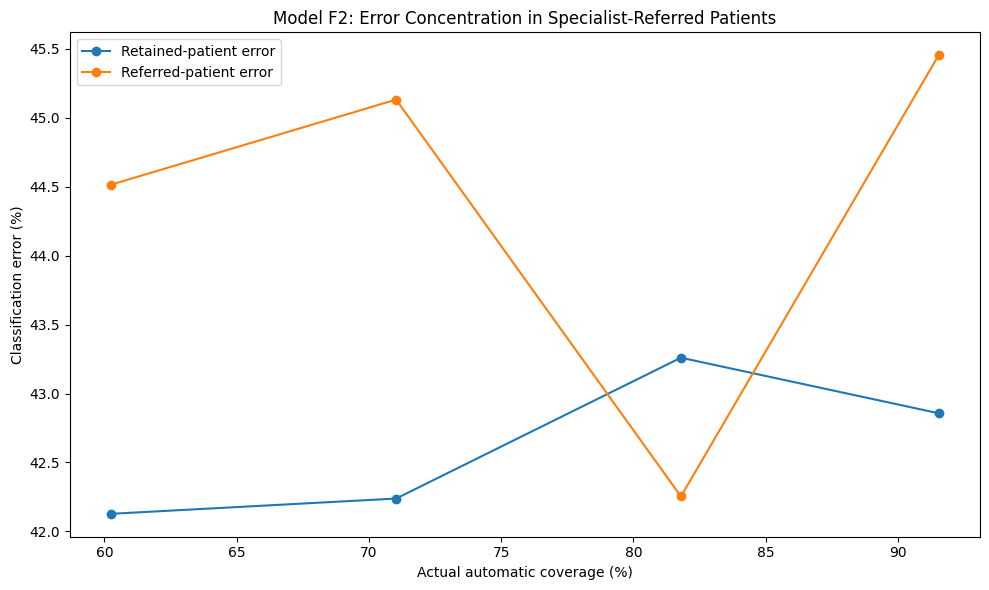

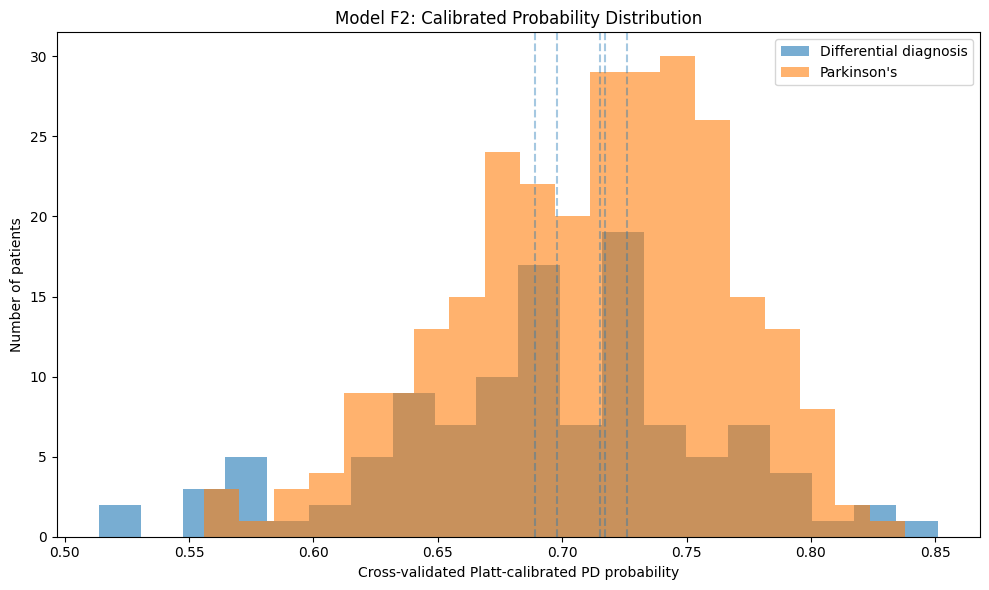


CORRECTED MODEL F2 COMPLETE

Overall configuration comparison:

                           configuration  balanced_accuracy  macro_f1  sensitivity_pd  specificity_dd  roc_auc  pr_auc  brier_score  ece_10_bins  true_negative  false_positive  false_negative  true_positive
        Raw probability + threshold 0.50             0.5666    0.5687          0.8261          0.3070   0.5947  0.7503       0.2254       0.1283             35              79              48            228
      Platt probability + threshold 0.50             0.5000    0.4144          1.0000          0.0000   0.5890  0.7466       0.2021       0.0280              0             114               0            276
Platt probability + tuned fold threshold             0.5644    0.5414          0.5761          0.5526   0.5890  0.7466       0.2021       0.0280             63              51             117            159

Fold-specific tuned thresholds:

 outer_fold  tuned_threshold  cross_fitted_train_balanced_accuracy  raw_o

In [ ]:
# ==================================================================================================
# CORRECTED MODEL F2
# CROSS-FITTED PLATT CALIBRATION + LEAKAGE-FREE THRESHOLD OPTIMIZATION
# + SPECIALIST REFERRAL / SELECTIVE CLASSIFICATION
#
# REQUIRED EXISTING FILES:
# - pads_engineered_features.csv
# - fixed_outer_5fold_splits.csv
# - Model D selected_tasks_by_fold_and_count.csv
# - Model D best_parameters_by_fold_and_task_count.csv
# - Model D minimum_task_patient_predictions.csv
#
# OLD BASELINES, MODEL B AND MODEL C FILES ARE NOT REQUIRED.
#
# SCIENTIFIC PROCEDURE PER OUTER FOLD:
# 1. Use Model-D fold-specific Top-8 tasks and best hyperparameters.
# 2. Generate raw inner OOF probabilities on outer-training patients only.
# 3. Generate cross-fitted Platt-calibrated probabilities on outer-training patients:
#       - Calibrator fitted on calibration-training split
#       - Predictions generated on separate calibration-validation split
# 4. Select threshold maximizing balanced accuracy on cross-fitted calibrated probabilities.
# 5. Fit final Platt calibrator on all inner OOF outer-training probabilities.
# 6. Train exact Model-D final base model on complete outer-training fold.
# 7. Apply Platt calibration and tuned threshold to untouched outer-test patients.
# 8. Define uncertainty relative to tuned threshold:
#       confidence = abs(calibrated_probability - tuned_threshold)
# 9. Select referral confidence cutoffs only from outer-training cross-fitted confidence.
#
# TARGET COVERAGES:
# 100%, 90%, 80%, 70%, 60%
# ==================================================================================================

import os
import gc
import sys
import ast
import json
import time
import random
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ==================================================================================================
# 1. IMPORT / INSTALL PACKAGES
# ==================================================================================================

try:
    import xgboost as xgb
except ImportError:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "xgboost"
    ])
    import xgboost as xgb

from sklearn.model_selection import (
    StratifiedKFold
)

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve
)

print("=" * 120)
print("CORRECTED MODEL F2 — PLATT CALIBRATION, TUNED THRESHOLD AND SPECIALIST REFERRAL")
print("=" * 120)

print("XGBoost version:", xgb.__version__)

# ==================================================================================================
# 2. GLOBAL CONFIGURATION
# ==================================================================================================

GLOBAL_SEED = 42

SELECTED_TASK_COUNT = 8

BASE_MODEL_INNER_FOLDS = 3

CALIBRATOR_CV_FOLDS = 5

RAW_THRESHOLD = 0.50

N_BOOTSTRAPS = 2000

TARGET_COVERAGES = [
    1.00,
    0.90,
    0.80,
    0.70,
    0.60
]

# Dense threshold grid for training-fold threshold optimization.
THRESHOLD_GRID = np.linspace(
    0.05,
    0.95,
    901
)

random.seed(
    int(GLOBAL_SEED)
)

np.random.seed(
    int(GLOBAL_SEED)
)

# ==================================================================================================
# 3. GPU CHECK
# ==================================================================================================

GPU_AVAILABLE = False

try:
    gpu_test_X = np.random.randn(
        20,
        4
    ).astype(np.float32)

    gpu_test_y = np.array(
        [0, 1] * 10,
        dtype=np.int32
    )

    gpu_test_model = xgb.XGBClassifier(
        n_estimators=2,
        max_depth=2,
        tree_method="hist",
        device="cuda",
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=GLOBAL_SEED,
        verbosity=0
    )

    gpu_test_model.fit(
        gpu_test_X,
        gpu_test_y
    )

    GPU_AVAILABLE = True

    print("✅ XGBoost GPU test successful.")

    del (
        gpu_test_X,
        gpu_test_y,
        gpu_test_model
    )

    gc.collect()

except Exception as gpu_error:
    print("⚠️ GPU unavailable; CPU fallback will be used.")
    print("GPU error:", str(gpu_error)[:500])

DEVICE = (
    "cuda"
    if GPU_AVAILABLE
    else "cpu"
)

# ==================================================================================================
# 4. PATHS
# ==================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = (
    BASE_DIR
    / "project_ready_data"
)

FEATURE_DIR = (
    PROJECT_DIR
    / "feature_engineering"
)

BASELINE_DIR = (
    PROJECT_DIR
    / "baseline_results"
)

PROPOSED_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
)

FEATURE_FILE = (
    FEATURE_DIR
    / "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = (
    BASELINE_DIR
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

MODEL_D_DIR = (
    PROPOSED_DIR
    / "model_d_nested_minimum_task_selection_xgboost"
)

SELECTED_TASK_FILE = (
    MODEL_D_DIR
    / "selected_tasks_by_fold_and_count.csv"
)

BEST_PARAMETER_FILE = (
    MODEL_D_DIR
    / "best_parameters_by_fold_and_task_count.csv"
)

MODEL_D_PREDICTION_FILE = (
    MODEL_D_DIR
    / "minimum_task_patient_predictions.csv"
)

OUTPUT_DIR = (
    PROPOSED_DIR
    / "model_f2_corrected_platt_threshold_referral"
)

FIGURE_DIR = (
    OUTPUT_DIR
    / "figures"
)

for directory in [
    OUTPUT_DIR,
    FIGURE_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


def locate_required_file(
    expected_path,
    filename
):
    if expected_path.exists():
        return expected_path

    matches = list(
        BASE_DIR.rglob(filename)
    )

    if not matches:
        raise FileNotFoundError(
            f"Required file nahi mili: {filename}"
        )

    return matches[0]


FEATURE_FILE = locate_required_file(
    FEATURE_FILE,
    "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = locate_required_file(
    FIXED_SPLIT_FILE,
    "fixed_outer_5fold_splits.csv"
)

SELECTED_TASK_FILE = locate_required_file(
    SELECTED_TASK_FILE,
    "selected_tasks_by_fold_and_count.csv"
)

BEST_PARAMETER_FILE = locate_required_file(
    BEST_PARAMETER_FILE,
    "best_parameters_by_fold_and_task_count.csv"
)

MODEL_D_PREDICTION_FILE = locate_required_file(
    MODEL_D_PREDICTION_FILE,
    "minimum_task_patient_predictions.csv"
)

print("\nInput files:")
print("Feature table       :", FEATURE_FILE)
print("Fixed folds         :", FIXED_SPLIT_FILE)
print("Selected tasks      :", SELECTED_TASK_FILE)
print("Best parameters     :", BEST_PARAMETER_FILE)
print("Model-D predictions :", MODEL_D_PREDICTION_FILE)
print("Output directory    :", OUTPUT_DIR)
print("Device              :", DEVICE)

# ==================================================================================================
# 5. LOAD FEATURE TABLE
# ==================================================================================================

data = pd.read_csv(
    FEATURE_FILE
)

possible_id_columns = [
    "patient_id",
    "id",
    "patient",
    "Patient_ID"
]

PATIENT_ID_COLUMN = next(
    (
        column
        for column in possible_id_columns
        if column in data.columns
    ),
    None
)

if PATIENT_ID_COLUMN is None:
    raise ValueError(
        "Patient-ID column identify nahi hui."
    )

possible_target_columns = [
    "y",
    "label",
    "target",
    "condition_2class",
    "diagnostic_group"
]

TARGET_COLUMN = next(
    (
        column
        for column in possible_target_columns
        if column in data.columns
    ),
    None
)

if TARGET_COLUMN is None:
    raise ValueError(
        "Target column identify nahi hui."
    )

data[PATIENT_ID_COLUMN] = (
    data[PATIENT_ID_COLUMN]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

# --------------------------------------------------------------------------------------------------
# Target conversion
# --------------------------------------------------------------------------------------------------

if pd.api.types.is_numeric_dtype(
    data[TARGET_COLUMN]
):
    numeric_target = pd.to_numeric(
        data[TARGET_COLUMN],
        errors="coerce"
    )

    unique_values = set(
        numeric_target
        .dropna()
        .unique()
    )

    if unique_values.issubset(
        {0, 1}
    ):
        y = numeric_target.astype(
            int
        ).to_numpy()

    elif unique_values.issubset(
        {1, 2}
    ):
        y = (
            numeric_target == 1
        ).astype(int).to_numpy()

    else:
        raise ValueError(
            f"Unexpected numeric target values: {sorted(unique_values)}"
        )

else:
    normalized_target = (
        data[TARGET_COLUMN]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    target_mapping = {
        "parkinson's": 1,
        "parkinsons": 1,
        "parkinson": 1,
        "pd": 1,
        "1": 1,

        "differential diagnosis": 0,
        "differential-diagnosis": 0,
        "other movement disorders": 0,
        "dd": 0,
        "0": 0
    }

    mapped_target = normalized_target.map(
        target_mapping
    )

    if mapped_target.isna().any():
        unknown_labels = sorted(
            normalized_target[
                mapped_target.isna()
            ].unique()
        )

        raise ValueError(
            f"Unknown target labels: {unknown_labels}"
        )

    y = mapped_target.astype(
        int
    ).to_numpy()

patient_ids = (
    data[PATIENT_ID_COLUMN]
    .to_numpy()
)

N_PATIENTS = int(
    len(patient_ids)
)

if len(
    np.unique(patient_ids)
) != N_PATIENTS:
    raise ValueError(
        "Duplicate patient IDs detected."
    )

print("\nFeature-table shape:", data.shape)
print("Patients:", N_PATIENTS)
print("PD      :", int(np.sum(y == 1)))
print("DD      :", int(np.sum(y == 0)))

# ==================================================================================================
# 6. IDENTIFY TASK FEATURES
# ==================================================================================================

TASK_NAMES = [
    "Relaxed1",
    "Relaxed2",
    "RelaxedTask1",
    "RelaxedTask2",
    "StretchHold",
    "HoldWeight",
    "DrinkGlas",
    "CrossArms",
    "TouchNose",
    "Entrainment1",
    "Entrainment2"
]

metadata_columns = {
    PATIENT_ID_COLUMN,
    TARGET_COLUMN,
    "condition",
    "condition_original",
    "condition_3class",
    "diagnostic_group",
    "resource_type",
    "study_id",
    "disease_comment",
    "age",
    "age_at_diagnosis",
    "height",
    "weight",
    "gender",
    "handedness",
    "appearance_in_kinship",
    "appearance_in_first_grade_kinship",
    "effect_of_alcohol_on_tremor",
    "questionnaire",
    "group",
    "class",
    "target_name"
}

candidate_feature_columns = []

for column in data.columns:
    if column in metadata_columns:
        continue

    converted = pd.to_numeric(
        data[column],
        errors="coerce"
    )

    if converted.notna().sum() > 0:
        candidate_feature_columns.append(
            column
        )

X_dataframe = (
    data[candidate_feature_columns]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

task_to_features = {}

for task_name in TASK_NAMES:
    prefixes = [
        f"{task_name}__",
        f"{task_name}_",
        f"{task_name} "
    ]

    task_to_features[
        task_name
    ] = [
        column
        for column in candidate_feature_columns
        if any(
            str(column).startswith(prefix)
            for prefix in prefixes
        )
    ]

print("\nFeatures per task:")

for task_name in TASK_NAMES:
    print(
        f"{task_name:20s}: "
        f"{len(task_to_features[task_name])}"
    )

missing_feature_tasks = [
    task
    for task in TASK_NAMES
    if len(task_to_features[task]) == 0
]

if missing_feature_tasks:
    raise ValueError(
        f"No features detected for tasks: {missing_feature_tasks}"
    )


def features_for_tasks(
    selected_tasks
):
    selected_columns = []

    for task_name in selected_tasks:
        selected_columns.extend(
            task_to_features[
                task_name
            ]
        )

    return list(
        dict.fromkeys(
            selected_columns
        )
    )

# ==================================================================================================
# 7. LOAD AND VERIFY FIXED OUTER FOLDS
# ==================================================================================================

fixed_splits = pd.read_csv(
    FIXED_SPLIT_FILE,
    dtype={"patient_id": str}
)

required_split_columns = {
    "patient_id",
    "fold",
    "role"
}

if not required_split_columns.issubset(
    fixed_splits.columns
):
    raise ValueError(
        "Fixed-fold file must contain patient_id, fold and role."
    )

fixed_splits["patient_id"] = (
    fixed_splits["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

fixed_splits["fold"] = pd.to_numeric(
    fixed_splits["fold"],
    errors="raise"
).astype(int)

fixed_splits["role"] = (
    fixed_splits["role"]
    .astype(str)
    .str.lower()
    .str.strip()
)

AVAILABLE_FOLDS = [
    int(value)
    for value in sorted(
        fixed_splits["fold"].unique()
    )
]

if AVAILABLE_FOLDS != [
    1,
    2,
    3,
    4,
    5
]:
    raise ValueError(
        f"Expected folds 1–5, found {AVAILABLE_FOLDS}"
    )

if set(
    fixed_splits["patient_id"]
) != set(patient_ids):
    raise ValueError(
        "Feature-table and fixed-fold patient IDs do not match."
    )

test_frequency = (
    fixed_splits.loc[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if (
    len(test_frequency) != N_PATIENTS
    or not (test_frequency == 1).all()
):
    raise ValueError(
        "Every patient must appear as outer-test exactly once."
    )

patient_to_index = {
    patient_id: index
    for index, patient_id
    in enumerate(patient_ids)
}

print(
    "\n✅ Same fixed five outer patient-level folds verified."
)

# ==================================================================================================
# 8. LOAD MODEL-D TOP-8 TASKS AND PARAMETERS
# ==================================================================================================

selected_task_table = pd.read_csv(
    SELECTED_TASK_FILE
)

parameter_table = pd.read_csv(
    BEST_PARAMETER_FILE
)

for table in [
    selected_task_table,
    parameter_table
]:
    table["outer_fold"] = pd.to_numeric(
        table["outer_fold"],
        errors="raise"
    ).astype(int)

    table["task_count"] = pd.to_numeric(
        table["task_count"],
        errors="raise"
    ).astype(int)

top8_task_table = selected_task_table.loc[
    selected_task_table[
        "task_count"
    ] == SELECTED_TASK_COUNT
].copy()

top8_parameter_table = parameter_table.loc[
    parameter_table[
        "task_count"
    ] == SELECTED_TASK_COUNT
].copy()

if len(top8_task_table) != 5:
    raise ValueError(
        "Expected five Top-8 task rows."
    )

if len(top8_parameter_table) != 5:
    raise ValueError(
        "Expected five Top-8 parameter rows."
    )


def parse_selected_tasks(
    value
):
    return [
        task.strip()
        for task in str(value).split("|")
        if task.strip()
    ]


def parse_parameters(
    value
):
    if isinstance(
        value,
        dict
    ):
        return value

    text = str(value).strip()

    try:
        return json.loads(text)

    except Exception:
        return ast.literal_eval(text)


fold_to_tasks = {}

for _, row in top8_task_table.iterrows():
    fold_number = int(
        row["outer_fold"]
    )

    selected_tasks = parse_selected_tasks(
        row["selected_tasks"]
    )

    if len(selected_tasks) != 8:
        raise ValueError(
            f"Fold {fold_number} does not contain eight selected tasks."
        )

    fold_to_tasks[
        fold_number
    ] = selected_tasks


fold_to_parameters = {}

for _, row in top8_parameter_table.iterrows():
    fold_number = int(
        row["outer_fold"]
    )

    fold_to_parameters[
        fold_number
    ] = parse_parameters(
        row["best_parameters"]
    )

print("\nFold-specific Top-8 tasks:")

for fold_number in AVAILABLE_FOLDS:
    print(
        f"Fold {fold_number}: "
        f"{', '.join(fold_to_tasks[fold_number])}"
    )

# ==================================================================================================
# 9. LOAD SAVED MODEL-D TOP-8 PREDICTIONS
# ==================================================================================================

model_d_predictions = pd.read_csv(
    MODEL_D_PREDICTION_FILE,
    dtype={"patient_id": str}
)

required_prediction_columns = {
    "patient_id",
    "task_count",
    "true_label",
    "predicted_probability_pd",
    "predicted_label"
}

if not required_prediction_columns.issubset(
    model_d_predictions.columns
):
    raise ValueError(
        "Model-D patient prediction file is incomplete."
    )

model_d_predictions["patient_id"] = (
    model_d_predictions["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

model_d_predictions["task_count"] = pd.to_numeric(
    model_d_predictions["task_count"],
    errors="raise"
).astype(int)

model_d_top8 = (
    model_d_predictions.loc[
        model_d_predictions[
            "task_count"
        ] == SELECTED_TASK_COUNT
    ]
    .set_index("patient_id")
    .loc[patient_ids]
    .reset_index()
)

if len(model_d_top8) != N_PATIENTS:
    raise ValueError(
        "Expected one Model-D Top-8 prediction per patient."
    )

saved_model_d_probability = (
    model_d_top8[
        "predicted_probability_pd"
    ].to_numpy(dtype=np.float32)
)

saved_model_d_label = (
    model_d_top8[
        "predicted_label"
    ].to_numpy(dtype=np.int32)
)

# ==================================================================================================
# 10. PREPROCESSING FUNCTIONS
# ==================================================================================================

def fit_preprocessor(
    training_dataframe
):
    imputer = SimpleImputer(
        strategy="median"
    )

    X_imputed = imputer.fit_transform(
        training_dataframe
    )

    variance_filter = VarianceThreshold(
        threshold=0.0
    )

    X_filtered = variance_filter.fit_transform(
        X_imputed
    )

    return (
        imputer,
        variance_filter,
        X_filtered.astype(np.float32)
    )


def transform_preprocessor(
    dataframe,
    imputer,
    variance_filter
):
    X_imputed = imputer.transform(
        dataframe
    )

    X_filtered = variance_filter.transform(
        X_imputed
    )

    return X_filtered.astype(
        np.float32
    )

# ==================================================================================================
# 11. MODEL FUNCTIONS
# ==================================================================================================

def create_xgboost_model(
    parameters,
    seed
):
    model_parameters = {
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "tree_method": "hist",
        "device": DEVICE,
        "random_state": int(seed),
        "n_jobs": 2,
        "verbosity": 0
    }

    model_parameters.update(
        parameters
    )

    return xgb.XGBClassifier(
        **model_parameters
    )


def probability_to_logit(
    probabilities
):
    clipped = np.clip(
        probabilities,
        1e-6,
        1.0 - 1e-6
    )

    return np.log(
        clipped
        / (1.0 - clipped)
    ).reshape(-1, 1)


def fit_platt_calibrator(
    probabilities,
    labels,
    seed
):
    calibrator = LogisticRegression(
        solver="lbfgs",
        C=1e6,
        max_iter=3000,
        random_state=int(seed)
    )

    calibrator.fit(
        probability_to_logit(
            probabilities
        ),
        labels
    )

    return calibrator


def apply_platt_calibrator(
    calibrator,
    probabilities
):
    return calibrator.predict_proba(
        probability_to_logit(
            probabilities
        )
    )[:, 1]

# ==================================================================================================
# 12. METRICS
# ==================================================================================================

def expected_calibration_error(
    y_true,
    probabilities,
    n_bins=10
):
    y_true = np.asarray(
        y_true,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(
        n_bins
    ):
        lower = bin_edges[
            bin_index
        ]

        upper = bin_edges[
            bin_index + 1
        ]

        if bin_index == n_bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if not np.any(mask):
            continue

        predicted_frequency = float(
            np.mean(
                probabilities[mask]
            )
        )

        observed_frequency = float(
            np.mean(
                y_true[mask]
            )
        )

        ece += float(
            np.mean(mask)
        ) * abs(
            predicted_frequency
            - observed_frequency
        )

    return float(ece)


def calculate_metrics(
    y_true,
    predictions,
    probabilities
):
    y_true = np.asarray(
        y_true,
        dtype=int
    )

    predictions = np.asarray(
        predictions,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity_pd = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity_dd = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    metric_dictionary = {
        "accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions
        ),

        "macro_f1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "pd_f1": f1_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "dd_f1": f1_score(
            y_true,
            predictions,
            pos_label=0,
            zero_division=0
        ),

        "precision_pd": precision_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "sensitivity_pd": sensitivity_pd,

        "specificity_dd": specificity_dd,

        "roc_auc": roc_auc_score(
            y_true,
            probabilities
        ),

        "pr_auc": average_precision_score(
            y_true,
            probabilities
        ),

        "brier_score": brier_score_loss(
            y_true,
            probabilities
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            probabilities,
            n_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }

    return metric_dictionary


def calculate_retained_metrics(
    y_true,
    predictions,
    probabilities
):
    if len(y_true) == 0:
        return {
            "accuracy": np.nan,
            "balanced_accuracy": np.nan,
            "macro_f1": np.nan,
            "sensitivity_pd": np.nan,
            "specificity_dd": np.nan,
            "roc_auc": np.nan,
            "pr_auc": np.nan
        }

    predictions = np.asarray(
        predictions,
        dtype=int
    )

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    confusion = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = confusion.ravel()

    sensitivity_pd = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity_dd = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    if len(
        np.unique(y_true)
    ) == 2:
        balanced_accuracy = balanced_accuracy_score(
            y_true,
            predictions
        )

        roc_auc = roc_auc_score(
            y_true,
            probabilities
        )

        pr_auc = average_precision_score(
            y_true,
            probabilities
        )

    else:
        balanced_accuracy = np.nan
        roc_auc = np.nan
        pr_auc = np.nan

    return {
        "accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "balanced_accuracy": balanced_accuracy,

        "macro_f1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "sensitivity_pd": sensitivity_pd,

        "specificity_dd": specificity_dd,

        "roc_auc": roc_auc,

        "pr_auc": pr_auc
    }

# ==================================================================================================
# 13. THRESHOLD SELECTION
# ==================================================================================================

def select_balanced_threshold(
    y_true,
    probabilities
):
    candidate_rows = []

    for threshold in THRESHOLD_GRID:
        predictions = (
            probabilities
            >= threshold
        ).astype(int)

        balanced_accuracy = balanced_accuracy_score(
            y_true,
            predictions
        )

        macro_f1 = f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        )

        candidate_rows.append({
            "threshold": float(
                threshold
            ),
            "balanced_accuracy": float(
                balanced_accuracy
            ),
            "macro_f1": float(
                macro_f1
            ),
            "distance_from_half": float(
                abs(
                    threshold
                    - 0.50
                )
            )
        })

    threshold_table = pd.DataFrame(
        candidate_rows
    )

    best_row = (
        threshold_table
        .sort_values(
            [
                "balanced_accuracy",
                "macro_f1",
                "distance_from_half"
            ],
            ascending=[
                False,
                False,
                True
            ]
        )
        .iloc[0]
    )

    return (
        float(
            best_row[
                "threshold"
            ]
        ),
        threshold_table
    )

# ==================================================================================================
# 14. STORAGE
# ==================================================================================================

raw_oof_probability = np.full(
    N_PATIENTS,
    np.nan,
    dtype=np.float32
)

platt_oof_probability = np.full(
    N_PATIENTS,
    np.nan,
    dtype=np.float32
)

raw_oof_prediction = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

platt_half_oof_prediction = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

platt_tuned_oof_prediction = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

patient_threshold = np.full(
    N_PATIENTS,
    np.nan,
    dtype=np.float32
)

patient_confidence = np.full(
    N_PATIENTS,
    np.nan,
    dtype=np.float32
)

oof_fold = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

coverage_retained_mask = {
    coverage: np.zeros(
        N_PATIENTS,
        dtype=bool
    )
    for coverage in TARGET_COVERAGES
}

fold_summary_rows = []
threshold_candidate_rows = []
referral_threshold_rows = []
cross_fitted_training_rows = []

total_start_time = time.time()

# ==================================================================================================
# 15. OUTER-FOLD TRAINING, CALIBRATION AND THRESHOLD OPTIMIZATION
# ==================================================================================================

print("\n" + "=" * 120)
print("STARTING CORRECTED LEAKAGE-FREE CALIBRATION")
print("=" * 120)

for raw_outer_fold in AVAILABLE_FOLDS:
    outer_fold = int(
        raw_outer_fold
    )

    fold_start_time = time.time()

    selected_tasks = fold_to_tasks[
        outer_fold
    ]

    selected_features = features_for_tasks(
        selected_tasks
    )

    best_parameters = fold_to_parameters[
        outer_fold
    ]

    current_fold_table = fixed_splits.loc[
        fixed_splits["fold"]
        == outer_fold
    ]

    outer_train_ids = current_fold_table.loc[
        current_fold_table["role"]
        == "train",
        "patient_id"
    ].tolist()

    outer_test_ids = current_fold_table.loc[
        current_fold_table["role"]
        == "test",
        "patient_id"
    ].tolist()

    outer_train_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id
        in outer_train_ids
    ], dtype=int)

    outer_test_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id
        in outer_test_ids
    ], dtype=int)

    if set(
        outer_train_indices
    ).intersection(
        set(
            outer_test_indices
        )
    ):
        raise RuntimeError(
            f"Patient leakage detected in fold {outer_fold}."
        )

    y_outer_train = y[
        outer_train_indices
    ]

    y_outer_test = y[
        outer_test_indices
    ]

    # ==============================================================================================
    # STEP A: GENERATE RAW INNER OOF PROBABILITIES ON OUTER-TRAINING PATIENTS
    # ==============================================================================================

    inner_raw_oof_probability = np.full(
        len(outer_train_indices),
        np.nan,
        dtype=np.float32
    )

    base_inner_splitter = StratifiedKFold(
        n_splits=BASE_MODEL_INNER_FOLDS,
        shuffle=True,
        random_state=int(
            GLOBAL_SEED
            + outer_fold * 1000
        )
    )

    for inner_fold_number, (
        relative_inner_train,
        relative_inner_validation
    ) in enumerate(
        base_inner_splitter.split(
            np.zeros(
                len(outer_train_indices)
            ),
            y_outer_train
        ),
        start=1
    ):
        inner_train_indices = outer_train_indices[
            relative_inner_train
        ]

        inner_validation_indices = outer_train_indices[
            relative_inner_validation
        ]

        X_inner_train_df = X_dataframe.loc[
            inner_train_indices,
            selected_features
        ]

        X_inner_validation_df = X_dataframe.loc[
            inner_validation_indices,
            selected_features
        ]

        y_inner_train = y[
            inner_train_indices
        ]

        (
            inner_imputer,
            inner_variance_filter,
            X_inner_train
        ) = fit_preprocessor(
            X_inner_train_df
        )

        X_inner_validation = transform_preprocessor(
            X_inner_validation_df,
            inner_imputer,
            inner_variance_filter
        )

        inner_sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_inner_train
        )

        inner_model_seed = int(
            GLOBAL_SEED
            + outer_fold * 10000
            + inner_fold_number
        )

        inner_model = create_xgboost_model(
            parameters=best_parameters,
            seed=inner_model_seed
        )

        inner_model.fit(
            X_inner_train,
            y_inner_train,
            sample_weight=inner_sample_weights,
            verbose=False
        )

        inner_validation_probability = (
            inner_model.predict_proba(
                X_inner_validation
            )[:, 1]
        )

        inner_raw_oof_probability[
            relative_inner_validation
        ] = inner_validation_probability

        del (
            X_inner_train_df,
            X_inner_validation_df,
            X_inner_train,
            X_inner_validation,
            inner_imputer,
            inner_variance_filter,
            inner_model
        )

        gc.collect()

    if np.isnan(
        inner_raw_oof_probability
    ).any():
        raise RuntimeError(
            f"Missing base-model inner OOF probabilities in fold {outer_fold}."
        )

    # ==============================================================================================
    # STEP B: CROSS-FITTED PLATT CALIBRATION ON OUTER-TRAINING PATIENTS
    # ==============================================================================================

    cross_fitted_platt_probability = np.full(
        len(outer_train_indices),
        np.nan,
        dtype=np.float32
    )

    calibration_splitter = StratifiedKFold(
        n_splits=CALIBRATOR_CV_FOLDS,
        shuffle=True,
        random_state=int(
            GLOBAL_SEED
            + outer_fold * 2000
        )
    )

    for calibration_fold_number, (
        calibration_train_relative_indices,
        calibration_validation_relative_indices
    ) in enumerate(
        calibration_splitter.split(
            inner_raw_oof_probability.reshape(-1, 1),
            y_outer_train
        ),
        start=1
    ):
        calibration_train_probability = (
            inner_raw_oof_probability[
                calibration_train_relative_indices
            ]
        )

        calibration_train_labels = (
            y_outer_train[
                calibration_train_relative_indices
            ]
        )

        calibration_validation_probability = (
            inner_raw_oof_probability[
                calibration_validation_relative_indices
            ]
        )

        calibrator = fit_platt_calibrator(
            probabilities=calibration_train_probability,
            labels=calibration_train_labels,
            seed=(
                GLOBAL_SEED
                + outer_fold * 3000
                + calibration_fold_number
            )
        )

        calibrated_validation_probability = (
            apply_platt_calibrator(
                calibrator,
                calibration_validation_probability
            )
        )

        cross_fitted_platt_probability[
            calibration_validation_relative_indices
        ] = calibrated_validation_probability

        del calibrator

    if np.isnan(
        cross_fitted_platt_probability
    ).any():
        raise RuntimeError(
            f"Missing cross-fitted calibration probabilities in fold {outer_fold}."
        )

    # ==============================================================================================
    # STEP C: SELECT BALANCED CLASSIFICATION THRESHOLD ON CROSS-FITTED TRAINING PROBABILITIES
    # ==============================================================================================

    tuned_threshold, threshold_table = (
        select_balanced_threshold(
            y_true=y_outer_train,
            probabilities=(
                cross_fitted_platt_probability
            )
        )
    )

    threshold_table.insert(
        0,
        "outer_fold",
        outer_fold
    )

    threshold_candidate_rows.append(
        threshold_table
    )

    cross_fitted_predictions = (
        cross_fitted_platt_probability
        >= tuned_threshold
    ).astype(int)

    cross_fitted_metrics = calculate_metrics(
        y_outer_train,
        cross_fitted_predictions,
        cross_fitted_platt_probability
    )

    # ==============================================================================================
    # STEP D: FIT FINAL PLATT CALIBRATOR ON ALL OUTER-TRAINING INNER OOF PROBABILITIES
    # ==============================================================================================

    final_platt_calibrator = fit_platt_calibrator(
        probabilities=inner_raw_oof_probability,
        labels=y_outer_train,
        seed=(
            GLOBAL_SEED
            + outer_fold * 4000
        )
    )

    # ==============================================================================================
    # STEP E: TRAIN EXACT MODEL-D FINAL BASE MODEL ON COMPLETE OUTER TRAINING
    # ==============================================================================================

    X_outer_train_df = X_dataframe.loc[
        outer_train_indices,
        selected_features
    ]

    X_outer_test_df = X_dataframe.loc[
        outer_test_indices,
        selected_features
    ]

    (
        final_imputer,
        final_variance_filter,
        X_outer_train
    ) = fit_preprocessor(
        X_outer_train_df
    )

    X_outer_test = transform_preprocessor(
        X_outer_test_df,
        final_imputer,
        final_variance_filter
    )

    final_sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_outer_train
    )

    exact_model_d_seed = int(
        GLOBAL_SEED
        + outer_fold * 100
        + SELECTED_TASK_COUNT * 10000
    )

    final_base_model = create_xgboost_model(
        parameters=best_parameters,
        seed=exact_model_d_seed
    )

    final_base_model.fit(
        X_outer_train,
        y_outer_train,
        sample_weight=final_sample_weights,
        verbose=False
    )

    outer_raw_probability = (
        final_base_model.predict_proba(
            X_outer_test
        )[:, 1]
    )

    outer_platt_probability = (
        apply_platt_calibrator(
            final_platt_calibrator,
            outer_raw_probability
        )
    )

    outer_raw_prediction = (
        outer_raw_probability
        >= RAW_THRESHOLD
    ).astype(int)

    outer_platt_half_prediction = (
        outer_platt_probability
        >= 0.50
    ).astype(int)

    outer_platt_tuned_prediction = (
        outer_platt_probability
        >= tuned_threshold
    ).astype(int)

    # Store OOF results.
    raw_oof_probability[
        outer_test_indices
    ] = outer_raw_probability

    platt_oof_probability[
        outer_test_indices
    ] = outer_platt_probability

    raw_oof_prediction[
        outer_test_indices
    ] = outer_raw_prediction

    platt_half_oof_prediction[
        outer_test_indices
    ] = outer_platt_half_prediction

    platt_tuned_oof_prediction[
        outer_test_indices
    ] = outer_platt_tuned_prediction

    patient_threshold[
        outer_test_indices
    ] = tuned_threshold

    outer_confidence = np.abs(
        outer_platt_probability
        - tuned_threshold
    )

    patient_confidence[
        outer_test_indices
    ] = outer_confidence

    oof_fold[
        outer_test_indices
    ] = outer_fold

    # ==============================================================================================
    # STEP F: REFERRAL CONFIDENCE THRESHOLDS FROM CROSS-FITTED OUTER-TRAINING CONFIDENCE
    # ==============================================================================================

    training_confidence = np.abs(
        cross_fitted_platt_probability
        - tuned_threshold
    )

    for target_coverage in TARGET_COVERAGES:
        if target_coverage >= 1.0:
            confidence_cutoff = 0.0

        else:
            confidence_cutoff = float(
                np.quantile(
                    training_confidence,
                    1.0 - target_coverage,
                    method="linear"
                )
            )

        outer_retained = (
            outer_confidence
            >= confidence_cutoff
        )

        coverage_retained_mask[
            target_coverage
        ][outer_test_indices] = (
            outer_retained
        )

        referral_threshold_rows.append({
            "outer_fold": outer_fold,
            "target_coverage": target_coverage,
            "tuned_classification_threshold": (
                tuned_threshold
            ),
            "confidence_cutoff": (
                confidence_cutoff
            ),
            "training_actual_coverage": float(
                np.mean(
                    training_confidence
                    >= confidence_cutoff
                )
            ),
            "outer_test_actual_coverage": float(
                np.mean(
                    outer_retained
                )
            ),
            "outer_test_retained_patients": int(
                np.sum(
                    outer_retained
                )
            ),
            "outer_test_referred_patients": int(
                np.sum(
                    ~outer_retained
                )
            )
        })

    raw_fold_metrics = calculate_metrics(
        y_outer_test,
        outer_raw_prediction,
        outer_raw_probability
    )

    platt_half_fold_metrics = calculate_metrics(
        y_outer_test,
        outer_platt_half_prediction,
        outer_platt_probability
    )

    platt_tuned_fold_metrics = calculate_metrics(
        y_outer_test,
        outer_platt_tuned_prediction,
        outer_platt_probability
    )

    fold_summary_rows.append({
        "outer_fold": outer_fold,
        "selected_tasks": " | ".join(
            selected_tasks
        ),
        "number_of_features": len(
            selected_features
        ),
        "exact_model_d_seed": (
            exact_model_d_seed
        ),
        "tuned_threshold": (
            tuned_threshold
        ),

        "cross_fitted_train_balanced_accuracy": (
            cross_fitted_metrics[
                "balanced_accuracy"
            ]
        ),

        "cross_fitted_train_macro_f1": (
            cross_fitted_metrics[
                "macro_f1"
            ]
        ),

        "cross_fitted_train_brier_score": (
            cross_fitted_metrics[
                "brier_score"
            ]
        ),

        "cross_fitted_train_ece": (
            cross_fitted_metrics[
                "ece_10_bins"
            ]
        ),

        "raw_outer_balanced_accuracy": (
            raw_fold_metrics[
                "balanced_accuracy"
            ]
        ),

        "raw_outer_macro_f1": (
            raw_fold_metrics[
                "macro_f1"
            ]
        ),

        "platt_half_outer_balanced_accuracy": (
            platt_half_fold_metrics[
                "balanced_accuracy"
            ]
        ),

        "platt_half_outer_macro_f1": (
            platt_half_fold_metrics[
                "macro_f1"
            ]
        ),

        "platt_tuned_outer_balanced_accuracy": (
            platt_tuned_fold_metrics[
                "balanced_accuracy"
            ]
        ),

        "platt_tuned_outer_macro_f1": (
            platt_tuned_fold_metrics[
                "macro_f1"
            ]
        ),

        "platt_tuned_outer_sensitivity_pd": (
            platt_tuned_fold_metrics[
                "sensitivity_pd"
            ]
        ),

        "platt_tuned_outer_specificity_dd": (
            platt_tuned_fold_metrics[
                "specificity_dd"
            ]
        ),

        "platt_tuned_outer_roc_auc": (
            platt_tuned_fold_metrics[
                "roc_auc"
            ]
        ),

        "platt_tuned_outer_brier_score": (
            platt_tuned_fold_metrics[
                "brier_score"
            ]
        ),

        "platt_tuned_outer_ece": (
            platt_tuned_fold_metrics[
                "ece_10_bins"
            ]
        )
    })

    for relative_index, patient_index in enumerate(
        outer_train_indices
    ):
        cross_fitted_training_rows.append({
            "outer_fold": outer_fold,
            "patient_id": (
                patient_ids[
                    patient_index
                ]
            ),
            "true_label": int(
                y[
                    patient_index
                ]
            ),
            "raw_inner_oof_probability": float(
                inner_raw_oof_probability[
                    relative_index
                ]
            ),
            "cross_fitted_platt_probability": float(
                cross_fitted_platt_probability[
                    relative_index
                ]
            ),
            "tuned_threshold": float(
                tuned_threshold
            ),
            "training_confidence": float(
                training_confidence[
                    relative_index
                ]
            )
        })

    print("\n" + "-" * 105)
    print(
        f"OUTER FOLD {outer_fold}/5"
    )
    print("-" * 105)

    print(
        "Selected tasks:",
        ", ".join(
            selected_tasks
        )
    )

    print(
        "Tuned threshold:",
        f"{tuned_threshold:.4f}"
    )

    print(
        "Cross-fitted train BA:",
        f"{cross_fitted_metrics['balanced_accuracy']:.4f}"
    )

    print(
        "Outer raw BA:",
        f"{raw_fold_metrics['balanced_accuracy']:.4f}"
    )

    print(
        "Outer Platt@0.50 BA:",
        f"{platt_half_fold_metrics['balanced_accuracy']:.4f}"
    )

    print(
        "Outer Platt+tuned BA:",
        f"{platt_tuned_fold_metrics['balanced_accuracy']:.4f}"
    )

    print(
        "Outer Platt+tuned Macro-F1:",
        f"{platt_tuned_fold_metrics['macro_f1']:.4f}"
    )

    print(
        "Outer Platt+tuned PD sensitivity:",
        f"{platt_tuned_fold_metrics['sensitivity_pd']:.4f}"
    )

    print(
        "Outer Platt+tuned DD specificity:",
        f"{platt_tuned_fold_metrics['specificity_dd']:.4f}"
    )

    fold_runtime_seconds = (
        time.time()
        - fold_start_time
    )

    print(
        f"Fold completed in "
        f"{fold_runtime_seconds:.2f} seconds."
    )

    del (
        X_outer_train_df,
        X_outer_test_df,
        X_outer_train,
        X_outer_test,
        final_imputer,
        final_variance_filter,
        final_base_model,
        final_platt_calibrator
    )

    gc.collect()

total_runtime_minutes = (
    time.time()
    - total_start_time
) / 60.0

# ==================================================================================================
# 16. VERIFY COMPLETE OOF PREDICTIONS
# ==================================================================================================

for array_name, array_value in {
    "raw_oof_probability": raw_oof_probability,
    "platt_oof_probability": platt_oof_probability,
    "patient_threshold": patient_threshold,
    "patient_confidence": patient_confidence
}.items():
    if np.isnan(
        array_value
    ).any():
        raise RuntimeError(
            f"Missing values in {array_name}."
        )

for array_name, array_value in {
    "raw_oof_prediction": raw_oof_prediction,
    "platt_half_oof_prediction": (
        platt_half_oof_prediction
    ),
    "platt_tuned_oof_prediction": (
        platt_tuned_oof_prediction
    )
}.items():
    if np.any(
        array_value < 0
    ):
        raise RuntimeError(
            f"Missing predictions in {array_name}."
        )

# ==================================================================================================
# 17. VERIFY EXACT MODEL-D REPRODUCTION
# ==================================================================================================

raw_probability_difference = np.abs(
    raw_oof_probability
    - saved_model_d_probability
)

maximum_probability_difference = float(
    np.max(
        raw_probability_difference
    )
)

matching_raw_labels = int(
    np.sum(
        raw_oof_prediction
        == saved_model_d_label
    )
)

print("\n" + "=" * 120)
print("MODEL-D TOP-8 REPRODUCTION CHECK")
print("=" * 120)

print(
    "Maximum probability difference:",
    f"{maximum_probability_difference:.12f}"
)

print(
    "Matching labels:",
    f"{matching_raw_labels}/{N_PATIENTS}"
)

if (
    maximum_probability_difference > 1e-6
    or matching_raw_labels != N_PATIENTS
):
    raise RuntimeError(
        "Exact Model-D Top-8 predictions reproduce nahi hui."
    )

print(
    "✅ Exact Model-D Top-8 predictions reproduced."
)

# ==================================================================================================
# 18. OVERALL MODEL COMPARISON
# ==================================================================================================

comparison_configurations = {
    "Raw probability + threshold 0.50": {
        "probabilities": raw_oof_probability,
        "predictions": raw_oof_prediction
    },

    "Platt probability + threshold 0.50": {
        "probabilities": platt_oof_probability,
        "predictions": (
            platt_half_oof_prediction
        )
    },

    "Platt probability + tuned fold threshold": {
        "probabilities": platt_oof_probability,
        "predictions": (
            platt_tuned_oof_prediction
        )
    }
}

overall_comparison_rows = []

for configuration_name, configuration in (
    comparison_configurations.items()
):
    metrics = calculate_metrics(
        y,
        configuration[
            "predictions"
        ],
        configuration[
            "probabilities"
        ]
    )

    overall_comparison_rows.append({
        "configuration": (
            configuration_name
        ),
        **metrics
    })

overall_comparison_df = pd.DataFrame(
    overall_comparison_rows
)

fold_summary_df = pd.DataFrame(
    fold_summary_rows
)

threshold_candidate_df = pd.concat(
    threshold_candidate_rows,
    ignore_index=True
)

referral_threshold_df = pd.DataFrame(
    referral_threshold_rows
)

cross_fitted_training_df = pd.DataFrame(
    cross_fitted_training_rows
)

# ==================================================================================================
# 19. SPECIALIST REFERRAL RESULTS
# ==================================================================================================

referral_summary_rows = []
patient_referral_rows = []

for target_coverage in TARGET_COVERAGES:
    retained_mask = coverage_retained_mask[
        target_coverage
    ]

    referred_mask = ~retained_mask

    retained_y = y[
        retained_mask
    ]

    retained_predictions = (
        platt_tuned_oof_prediction[
            retained_mask
        ]
    )

    retained_probabilities = (
        platt_oof_probability[
            retained_mask
        ]
    )

    retained_metrics = (
        calculate_retained_metrics(
            retained_y,
            retained_predictions,
            retained_probabilities
        )
    )

    actual_coverage = float(
        np.mean(
            retained_mask
        )
    )

    referral_rate = float(
        np.mean(
            referred_mask
        )
    )

    pd_referral_rate = float(
        np.mean(
            referred_mask[
                y == 1
            ]
        )
    )

    dd_referral_rate = float(
        np.mean(
            referred_mask[
                y == 0
            ]
        )
    )

    retained_error_rate = (
        float(
            np.mean(
                retained_predictions
                != retained_y
            )
        )
        if np.any(
            retained_mask
        )
        else np.nan
    )

    referred_error_rate = (
        float(
            np.mean(
                platt_tuned_oof_prediction[
                    referred_mask
                ]
                != y[
                    referred_mask
                ]
            )
        )
        if np.any(
            referred_mask
        )
        else np.nan
    )

    referral_summary_rows.append({
        "target_coverage": (
            target_coverage
        ),

        "actual_coverage": (
            actual_coverage
        ),

        "referral_rate": (
            referral_rate
        ),

        "retained_patients": int(
            np.sum(
                retained_mask
            )
        ),

        "referred_patients": int(
            np.sum(
                referred_mask
            )
        ),

        "pd_referral_rate": (
            pd_referral_rate
        ),

        "dd_referral_rate": (
            dd_referral_rate
        ),

        "retained_error_rate": (
            retained_error_rate
        ),

        "referred_error_rate": (
            referred_error_rate
        ),

        **retained_metrics
    })

    for patient_index in range(
        N_PATIENTS
    ):
        patient_referral_rows.append({
            "patient_id": (
                patient_ids[
                    patient_index
                ]
            ),

            "outer_fold": int(
                oof_fold[
                    patient_index
                ]
            ),

            "true_label": int(
                y[
                    patient_index
                ]
            ),

            "raw_probability_pd": float(
                raw_oof_probability[
                    patient_index
                ]
            ),

            "platt_probability_pd": float(
                platt_oof_probability[
                    patient_index
                ]
            ),

            "fold_tuned_threshold": float(
                patient_threshold[
                    patient_index
                ]
            ),

            "confidence_from_tuned_threshold": float(
                patient_confidence[
                    patient_index
                ]
            ),

            "predicted_label": int(
                platt_tuned_oof_prediction[
                    patient_index
                ]
            ),

            "target_coverage": (
                target_coverage
            ),

            "retained_for_automatic_decision": bool(
                retained_mask[
                    patient_index
                ]
            ),

            "referred_to_specialist": bool(
                referred_mask[
                    patient_index
                ]
            )
        })

referral_summary_df = pd.DataFrame(
    referral_summary_rows
)

patient_referral_df = pd.DataFrame(
    patient_referral_rows
)

# ==================================================================================================
# 20. BOOTSTRAP CONFIDENCE INTERVALS FOR OVERALL CONFIGURATIONS
# ==================================================================================================

bootstrap_rng = np.random.default_rng(
    int(GLOBAL_SEED)
)

bootstrap_configuration_rows = []

for bootstrap_iteration in range(
    N_BOOTSTRAPS
):
    sampled_indices = bootstrap_rng.integers(
        low=0,
        high=N_PATIENTS,
        size=N_PATIENTS
    )

    sampled_y = y[
        sampled_indices
    ]

    if len(
        np.unique(sampled_y)
    ) < 2:
        continue

    for configuration_name, configuration in (
        comparison_configurations.items()
    ):
        sampled_metrics = calculate_metrics(
            sampled_y,
            configuration[
                "predictions"
            ][
                sampled_indices
            ],
            configuration[
                "probabilities"
            ][
                sampled_indices
            ]
        )

        bootstrap_configuration_rows.append({
            "bootstrap_iteration": int(
                bootstrap_iteration
            ),
            "configuration": (
                configuration_name
            ),
            **sampled_metrics
        })

bootstrap_configuration_df = pd.DataFrame(
    bootstrap_configuration_rows
)

configuration_ci_rows = []

for _, observed_row in overall_comparison_df.iterrows():
    configuration_name = observed_row[
        "configuration"
    ]

    bootstrap_subset = (
        bootstrap_configuration_df.loc[
            bootstrap_configuration_df[
                "configuration"
            ] == configuration_name
        ]
    )

    for metric_name in [
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "ece_10_bins"
    ]:
        metric_values = (
            bootstrap_subset[
                metric_name
            ]
            .dropna()
            .to_numpy()
        )

        configuration_ci_rows.append({
            "configuration": (
                configuration_name
            ),
            "metric": (
                metric_name
            ),
            "value": float(
                observed_row[
                    metric_name
                ]
            ),
            "ci_95_lower": float(
                np.percentile(
                    metric_values,
                    2.5
                )
            ),
            "ci_95_upper": float(
                np.percentile(
                    metric_values,
                    97.5
                )
            )
        })

configuration_ci_df = pd.DataFrame(
    configuration_ci_rows
)

# ==================================================================================================
# 21. BOOTSTRAP REFERRAL RESULTS
# ==================================================================================================

bootstrap_referral_rows = []

for target_coverage in TARGET_COVERAGES:
    retained_mask = coverage_retained_mask[
        target_coverage
    ]

    for bootstrap_iteration in range(
        N_BOOTSTRAPS
    ):
        sampled_indices = bootstrap_rng.integers(
            low=0,
            high=N_PATIENTS,
            size=N_PATIENTS
        )

        sampled_retained_mask = retained_mask[
            sampled_indices
        ]

        if not np.any(
            sampled_retained_mask
        ):
            continue

        sampled_y = y[
            sampled_indices
        ][
            sampled_retained_mask
        ]

        sampled_predictions = (
            platt_tuned_oof_prediction[
                sampled_indices
            ][
                sampled_retained_mask
            ]
        )

        sampled_probabilities = (
            platt_oof_probability[
                sampled_indices
            ][
                sampled_retained_mask
            ]
        )

        sampled_metrics = (
            calculate_retained_metrics(
                sampled_y,
                sampled_predictions,
                sampled_probabilities
            )
        )

        bootstrap_referral_rows.append({
            "target_coverage": (
                target_coverage
            ),

            "bootstrap_iteration": int(
                bootstrap_iteration
            ),

            "actual_coverage": float(
                np.mean(
                    sampled_retained_mask
                )
            ),

            **sampled_metrics
        })

bootstrap_referral_df = pd.DataFrame(
    bootstrap_referral_rows
)

referral_ci_rows = []

for target_coverage in TARGET_COVERAGES:
    observed_row = referral_summary_df.loc[
        referral_summary_df[
            "target_coverage"
        ] == target_coverage
    ].iloc[0]

    bootstrap_subset = bootstrap_referral_df.loc[
        bootstrap_referral_df[
            "target_coverage"
        ] == target_coverage
    ]

    for metric_name in [
        "actual_coverage",
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd",
        "roc_auc",
        "pr_auc"
    ]:
        values = (
            bootstrap_subset[
                metric_name
            ]
            .dropna()
            .to_numpy()
        )

        referral_ci_rows.append({
            "target_coverage": (
                target_coverage
            ),

            "metric": (
                metric_name
            ),

            "value": float(
                observed_row[
                    metric_name
                ]
            ),

            "ci_95_lower": (
                float(
                    np.percentile(
                        values,
                        2.5
                    )
                )
                if len(values) > 0
                else np.nan
            ),

            "ci_95_upper": (
                float(
                    np.percentile(
                        values,
                        97.5
                    )
                )
                if len(values) > 0
                else np.nan
            )
        })

referral_ci_df = pd.DataFrame(
    referral_ci_rows
)

# ==================================================================================================
# 22. SAVE TABLES
# ==================================================================================================

overall_comparison_df.to_csv(
    OUTPUT_DIR
    / "model_f2_configuration_comparison.csv",
    index=False
)

configuration_ci_df.to_csv(
    OUTPUT_DIR
    / "model_f2_configuration_confidence_intervals.csv",
    index=False
)

bootstrap_configuration_df.to_csv(
    OUTPUT_DIR
    / "model_f2_configuration_bootstrap_metrics.csv",
    index=False
)

fold_summary_df.to_csv(
    OUTPUT_DIR
    / "model_f2_fold_results.csv",
    index=False
)

threshold_candidate_df.to_csv(
    OUTPUT_DIR
    / "model_f2_threshold_grid_results.csv",
    index=False
)

referral_threshold_df.to_csv(
    OUTPUT_DIR
    / "model_f2_referral_thresholds_by_fold.csv",
    index=False
)

referral_summary_df.to_csv(
    OUTPUT_DIR
    / "model_f2_specialist_referral_summary.csv",
    index=False
)

patient_referral_df.to_csv(
    OUTPUT_DIR
    / "model_f2_patient_referral_decisions.csv",
    index=False
)

bootstrap_referral_df.to_csv(
    OUTPUT_DIR
    / "model_f2_referral_bootstrap_metrics.csv",
    index=False
)

referral_ci_df.to_csv(
    OUTPUT_DIR
    / "model_f2_referral_confidence_intervals.csv",
    index=False
)

cross_fitted_training_df.to_csv(
    OUTPUT_DIR
    / "model_f2_cross_fitted_training_probabilities.csv",
    index=False
)

patient_prediction_df = pd.DataFrame({
    "patient_id": patient_ids,
    "outer_fold": oof_fold,
    "true_label": y,
    "raw_probability_pd": (
        raw_oof_probability
    ),
    "raw_prediction_threshold_0_50": (
        raw_oof_prediction
    ),
    "platt_probability_pd": (
        platt_oof_probability
    ),
    "platt_prediction_threshold_0_50": (
        platt_half_oof_prediction
    ),
    "fold_tuned_threshold": (
        patient_threshold
    ),
    "platt_tuned_prediction": (
        platt_tuned_oof_prediction
    ),
    "confidence_from_tuned_threshold": (
        patient_confidence
    )
})

patient_prediction_df.to_csv(
    OUTPUT_DIR
    / "model_f2_patient_predictions.csv",
    index=False
)

# ==================================================================================================
# 23. FIGURE 1 — CONFIGURATION COMPARISON
# ==================================================================================================

configuration_plot_df = (
    overall_comparison_df
    .set_index(
        "configuration"
    )
)

plt.figure(
    figsize=(13, 6)
)

configuration_plot_df[
    [
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd"
    ]
].plot(
    kind="bar",
    ax=plt.gca()
)

plt.xlabel(
    "Probability and threshold configuration"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Model F2: Effect of Calibration and Threshold Optimization"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.ylim(
    0.0,
    1.0
)

plt.legend([
    "Balanced accuracy",
    "Macro-F1",
    "PD sensitivity",
    "DD specificity"
])

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_calibration_threshold_configuration_comparison.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 24. FIGURE 2 — BRIER AND ECE
# ==================================================================================================

plt.figure(
    figsize=(11, 6)
)

configuration_plot_df[
    [
        "brier_score",
        "ece_10_bins"
    ]
].plot(
    kind="bar",
    ax=plt.gca()
)

plt.xlabel(
    "Probability configuration"
)

plt.ylabel(
    "Calibration error"
)

plt.title(
    "Model F2: Brier Score and Expected Calibration Error"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_brier_ece_comparison.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 25. FIGURE 3 — FOLD-SPECIFIC TUNED THRESHOLDS
# ==================================================================================================

plt.figure(
    figsize=(9, 6)
)

plt.bar(
    fold_summary_df[
        "outer_fold"
    ].astype(str),
    fold_summary_df[
        "tuned_threshold"
    ]
)

plt.axhline(
    0.50,
    linestyle="--",
    label="Default threshold 0.50"
)

plt.xlabel(
    "Outer fold"
)

plt.ylabel(
    "Training-selected Platt threshold"
)

plt.title(
    "Model F2: Fold-Specific Leakage-Free Decision Thresholds"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "03_fold_specific_tuned_thresholds.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 26. FIGURE 4 — COVERAGE PERFORMANCE TRADE-OFF
# ==================================================================================================

coverage_plot_df = (
    referral_summary_df
    .sort_values(
        "actual_coverage"
    )
)

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    coverage_plot_df[
        "actual_coverage"
    ] * 100,
    coverage_plot_df[
        "balanced_accuracy"
    ],
    marker="o",
    label="Balanced accuracy"
)

plt.plot(
    coverage_plot_df[
        "actual_coverage"
    ] * 100,
    coverage_plot_df[
        "macro_f1"
    ],
    marker="o",
    label="Macro-F1"
)

plt.plot(
    coverage_plot_df[
        "actual_coverage"
    ] * 100,
    coverage_plot_df[
        "roc_auc"
    ],
    marker="o",
    label="ROC-AUC"
)

plt.xlabel(
    "Automatically classified patient coverage (%)"
)

plt.ylabel(
    "Metric on retained patients"
)

plt.title(
    "Model F2: Specialist-Referral Coverage–Performance Trade-off"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "04_coverage_performance_tradeoff.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 27. FIGURE 5 — CLASS-SPECIFIC REFERRAL
# ==================================================================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    referral_summary_df[
        "actual_coverage"
    ] * 100,
    referral_summary_df[
        "pd_referral_rate"
    ] * 100,
    marker="o",
    label="PD referral rate"
)

plt.plot(
    referral_summary_df[
        "actual_coverage"
    ] * 100,
    referral_summary_df[
        "dd_referral_rate"
    ] * 100,
    marker="o",
    label="DD referral rate"
)

plt.xlabel(
    "Actual automatic coverage (%)"
)

plt.ylabel(
    "Class-specific referral rate (%)"
)

plt.title(
    "Model F2: PD and DD Specialist-Referral Rates"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "05_class_specific_referral_rates.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 28. FIGURE 6 — RETAINED VS REFERRED ERROR
# ==================================================================================================

non_full_coverage_df = referral_summary_df.loc[
    referral_summary_df[
        "target_coverage"
    ] < 1.0
].copy()

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    non_full_coverage_df[
        "actual_coverage"
    ] * 100,
    non_full_coverage_df[
        "retained_error_rate"
    ] * 100,
    marker="o",
    label="Retained-patient error"
)

plt.plot(
    non_full_coverage_df[
        "actual_coverage"
    ] * 100,
    non_full_coverage_df[
        "referred_error_rate"
    ] * 100,
    marker="o",
    label="Referred-patient error"
)

plt.xlabel(
    "Actual automatic coverage (%)"
)

plt.ylabel(
    "Classification error (%)"
)

plt.title(
    "Model F2: Error Concentration in Specialist-Referred Patients"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "06_retained_vs_referred_error.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 29. FIGURE 7 — PLATT PROBABILITY DISTRIBUTION
# ==================================================================================================

plt.figure(
    figsize=(10, 6)
)

plt.hist(
    platt_oof_probability[
        y == 0
    ],
    bins=20,
    alpha=0.6,
    label="Differential diagnosis"
)

plt.hist(
    platt_oof_probability[
        y == 1
    ],
    bins=20,
    alpha=0.6,
    label="Parkinson's"
)

for threshold_value in sorted(
    np.unique(
        np.round(
            patient_threshold,
            4
        )
    )
):
    plt.axvline(
        threshold_value,
        linestyle="--",
        alpha=0.4
    )

plt.xlabel(
    "Cross-validated Platt-calibrated PD probability"
)

plt.ylabel(
    "Number of patients"
)

plt.title(
    "Model F2: Calibrated Probability Distribution"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "07_platt_probability_distribution.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 30. FINAL OUTPUT
# ==================================================================================================

print("\n" + "=" * 120)
print("CORRECTED MODEL F2 COMPLETE")
print("=" * 120)

comparison_display_columns = [
    "configuration",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
    "true_negative",
    "false_positive",
    "false_negative",
    "true_positive"
]

print("\nOverall configuration comparison:\n")

print(
    overall_comparison_df[
        comparison_display_columns
    ]
    .round(4)
    .to_string(
        index=False
    )
)

print("\nFold-specific tuned thresholds:\n")

fold_display_columns = [
    "outer_fold",
    "tuned_threshold",
    "cross_fitted_train_balanced_accuracy",
    "raw_outer_balanced_accuracy",
    "platt_half_outer_balanced_accuracy",
    "platt_tuned_outer_balanced_accuracy",
    "platt_tuned_outer_macro_f1",
    "platt_tuned_outer_sensitivity_pd",
    "platt_tuned_outer_specificity_dd",
    "platt_tuned_outer_brier_score",
    "platt_tuned_outer_ece"
]

print(
    fold_summary_df[
        fold_display_columns
    ]
    .round(4)
    .to_string(
        index=False
    )
)

print("\nSpecialist referral results:\n")

referral_display_columns = [
    "target_coverage",
    "actual_coverage",
    "referral_rate",
    "retained_patients",
    "referred_patients",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pd_referral_rate",
    "dd_referral_rate",
    "retained_error_rate",
    "referred_error_rate"
]

print(
    referral_summary_df[
        referral_display_columns
    ]
    .round(4)
    .to_string(
        index=False
    )
)

print("\nScientific controls:")
print("- Same 390 PD-versus-DD patients.")
print("- Same fixed five outer patient-level folds.")
print("- Same fold-specific Model-D Top-8 tasks.")
print("- Same fold-specific Model-D best hyperparameters.")
print("- Exact Model-D final raw predictions reproduced.")
print("- Base-model inner OOF probabilities generated only on outer-training patients.")
print("- Platt calibration evaluated through cross-fitted calibration predictions.")
print("- Classification threshold selected only from cross-fitted outer-training probabilities.")
print("- Final calibrator fitted only on outer-training inner OOF predictions.")
print("- Outer-test patients never entered calibration or threshold selection.")
print("- Referral confidence measured relative to fold-specific tuned threshold.")
print("- Referral cutoffs selected only from outer-training confidence.")
print("- No Model B, Model C or previous baseline files were required.")
print("- No SMOTE, duplication, undersampling or test leakage.")
print("- 2,000 patient-level bootstrap samples.")

print(
    f"\nTotal runtime: "
    f"{total_runtime_minutes:.3f} minutes"
)

print("\nSaved files:")

for saved_file in sorted(
    OUTPUT_DIR.rglob("*")
):
    if saved_file.is_file():
        print(
            " -",
            saved_file.relative_to(
                OUTPUT_DIR
            )
        )

print(
    "\n✅ CORRECTED MODEL F2 PLATT CALIBRATION, "
    "THRESHOLD OPTIMIZATION AND SPECIALIST REFERRAL FINISHED."
)

## Model H - sensor + NMS stacked ensemble

MODEL H — LEAKAGE-FREE SENSOR + NMS QUESTIONNAIRE STACKED ENSEMBLE

Feature file              : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Fixed-fold file           : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Model-D predictions       : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_d_nested_minimum_task_selection_xgboost/minimum_task_patient_predictions.csv
Model-F2 training OOF file: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_f2_corrected_platt_threshold_referral/model_f2_cross_fitted_training_probabilities.csv
Questionnaire directory   : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/questionnaire
Outp

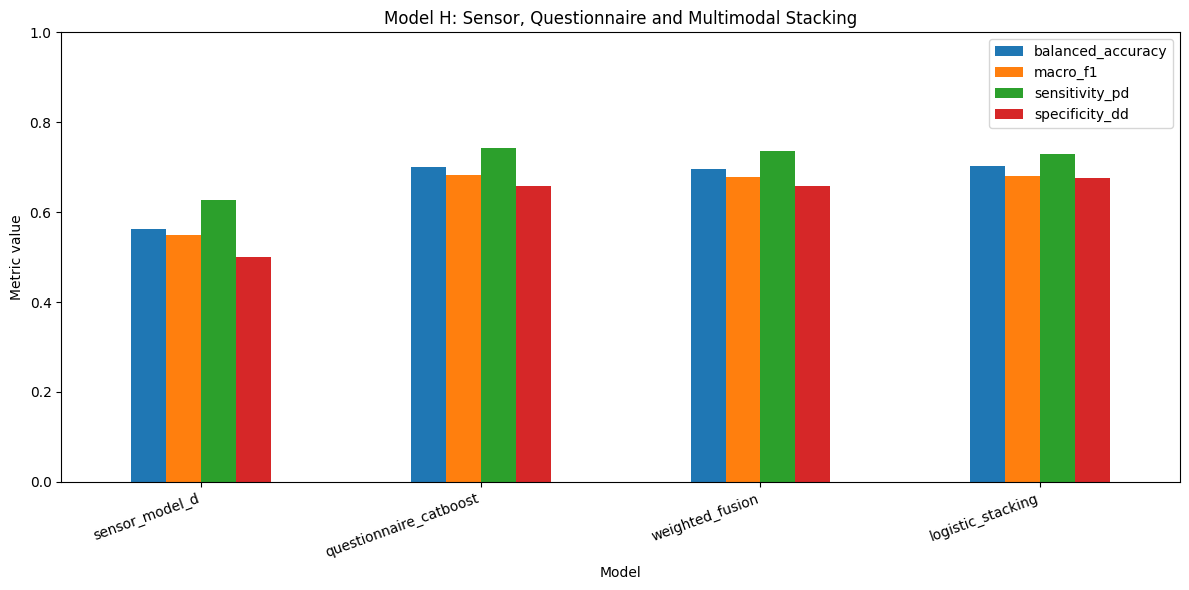

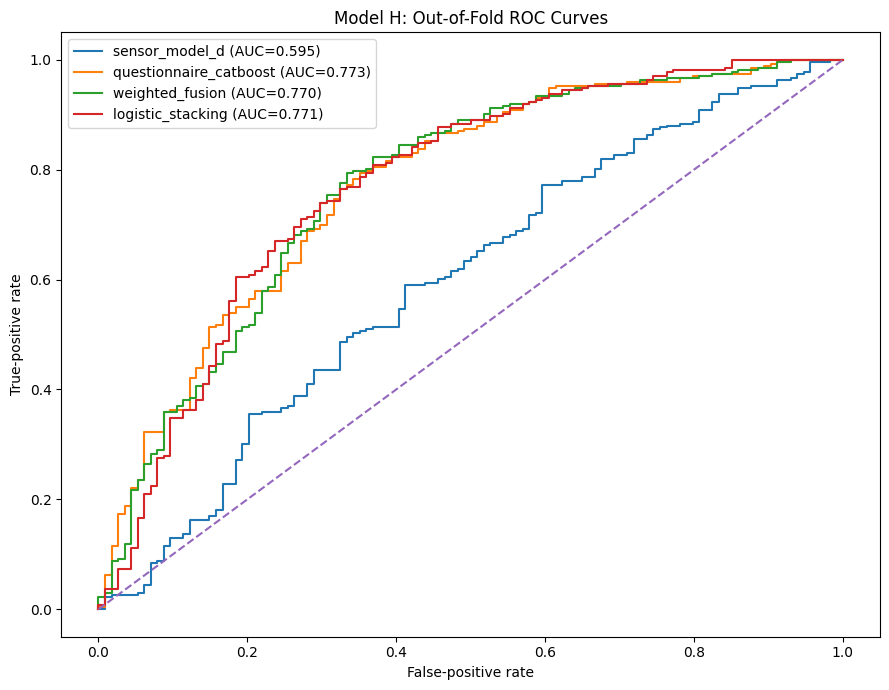

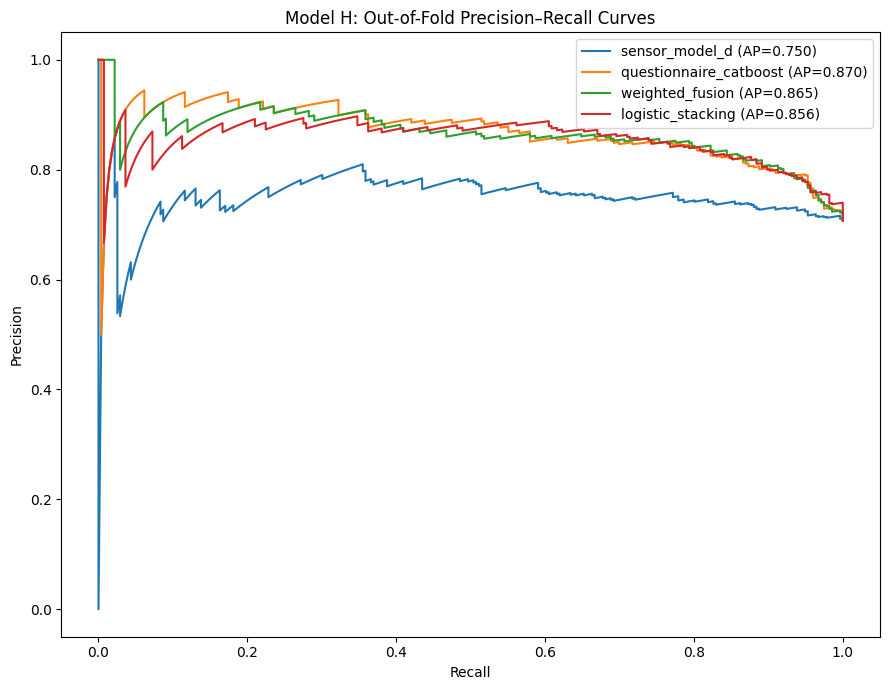

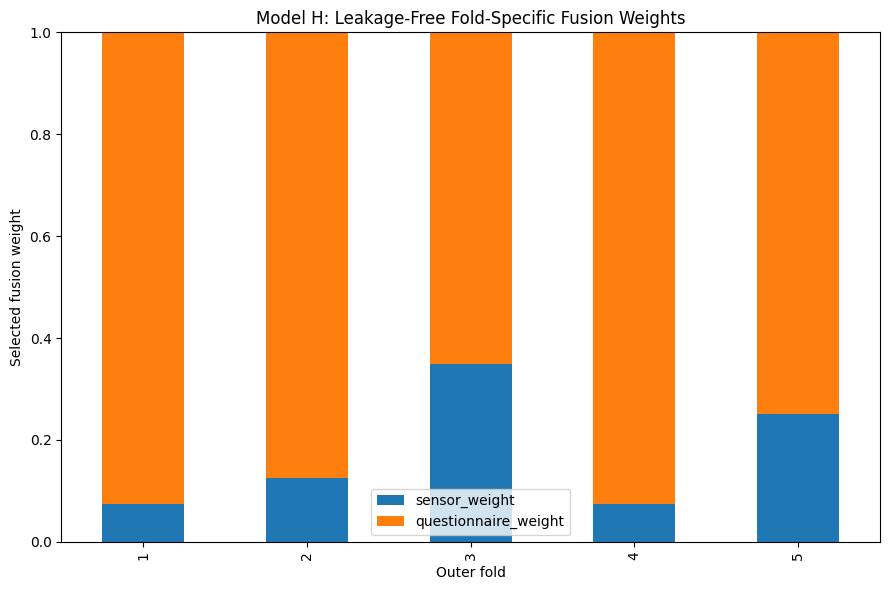

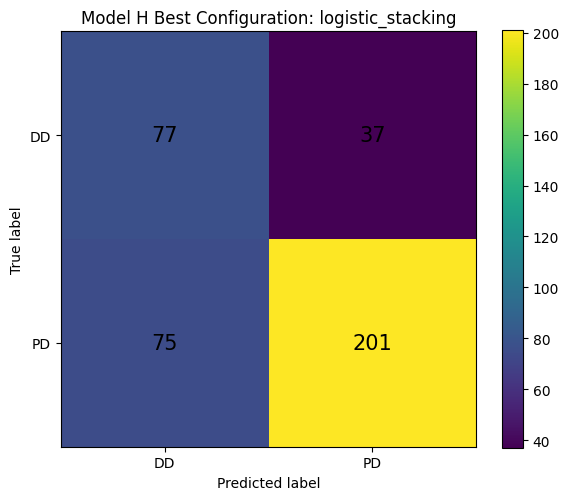


MODEL H COMPLETE

Overall out-of-fold comparison:

                 model  accuracy  balanced_accuracy  macro_f1  sensitivity_pd  specificity_dd  roc_auc  pr_auc  brier_score  ece_10_bins  true_negative  false_positive  false_negative  true_positive
     logistic_stacking    0.7128             0.7018    0.6805          0.7283          0.6754   0.7714  0.8561       0.1887       0.1590             77              37              75            201
questionnaire_catboost    0.7179             0.7003    0.6827          0.7428          0.6579   0.7726  0.8695       0.1721       0.1026             75              39              71            205
       weighted_fusion    0.7128             0.6967    0.6782          0.7355          0.6579   0.7700  0.8648       0.1690       0.0881             75              39              73            203
        sensor_model_d    0.5897             0.5634    0.5499          0.6268          0.5000   0.5947  0.7503       0.2254       0.1283             57 

In [ ]:
# ==================================================================================================
# MODEL H — LEAKAGE-FREE SENSOR + 30-ITEM NMS QUESTIONNAIRE STACKED ENSEMBLE
#
# Uses:
#   1. Exact Model-D Top-8 sensor probabilities
#   2. All 30 NMS questionnaire responses
#   3. Safe demographics: age, gender, handedness, height, weight
#   4. Questionnaire CatBoost
#   5. Cross-fitted logistic stacking and weighted fusion
#
# Scientific design:
#   - Same fixed five outer patient-level folds
#   - Questionnaire model tuning uses outer-training patients only
#   - Sensor training probabilities use Model-F2 cross-fitted Model-D probabilities
#   - Meta-model fitted only on outer-training cross-fitted predictions
#   - Fusion weights and threshold selected only from outer-training predictions
#   - Outer-test patients never used for tuning, stacking or threshold selection
#
# IMPORTANT:
#   Better performance and Q1 acceptance are not guaranteed.
# ==================================================================================================

import os
import gc
import sys
import ast
import json
import time
import random
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ==================================================================================================
# 1. INSTALL / IMPORT
# ==================================================================================================

try:
    from catboost import CatBoostClassifier
except ImportError:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "catboost"
    ])
    from catboost import CatBoostClassifier

from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve,
    precision_recall_curve
)

print("=" * 122)
print("MODEL H — LEAKAGE-FREE SENSOR + NMS QUESTIONNAIRE STACKED ENSEMBLE")
print("=" * 122)

# ==================================================================================================
# 2. CONFIGURATION
# ==================================================================================================

GLOBAL_SEED = 42
INNER_FOLDS = 5
N_BOOTSTRAPS = 2000

TARGET_TASK_COUNT = 8

THRESHOLD_GRID = np.arange(
    0.20,
    0.801,
    0.005
)

FUSION_WEIGHT_GRID = np.arange(
    0.0,
    1.001,
    0.025
)

CATBOOST_PARAMETER_CANDIDATES = [
    {
        "iterations": 250,
        "depth": 3,
        "learning_rate": 0.03,
        "l2_leaf_reg": 5.0,
        "random_strength": 0.5
    },
    {
        "iterations": 400,
        "depth": 3,
        "learning_rate": 0.02,
        "l2_leaf_reg": 8.0,
        "random_strength": 1.0
    },
    {
        "iterations": 350,
        "depth": 4,
        "learning_rate": 0.025,
        "l2_leaf_reg": 8.0,
        "random_strength": 0.5
    },
    {
        "iterations": 500,
        "depth": 4,
        "learning_rate": 0.015,
        "l2_leaf_reg": 12.0,
        "random_strength": 1.0
    },
    {
        "iterations": 350,
        "depth": 5,
        "learning_rate": 0.02,
        "l2_leaf_reg": 15.0,
        "random_strength": 1.5
    }
]

random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

# ==================================================================================================
# 3. PATHS
# ==================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = (
    BASE_DIR
    / "project_ready_data"
)

FEATURE_FILE = (
    PROJECT_DIR
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = (
    PROJECT_DIR
    / "baseline_results"
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

MODEL_D_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_d_nested_minimum_task_selection_xgboost"
)

MODEL_D_PREDICTION_FILE = (
    MODEL_D_DIR
    / "minimum_task_patient_predictions.csv"
)

MODEL_F2_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_f2_corrected_platt_threshold_referral"
)

MODEL_F2_TRAINING_FILE = (
    MODEL_F2_DIR
    / "model_f2_cross_fitted_training_probabilities.csv"
)

QUESTIONNAIRE_DIR = (
    BASE_DIR
    / "questionnaire"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_h_sensor_nms_stacked_ensemble"
)

FIGURE_DIR = (
    OUTPUT_DIR
    / "figures"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def locate_required_file(
    expected_path,
    filename
):
    if expected_path.exists():
        return expected_path

    matches = list(
        BASE_DIR.rglob(filename)
    )

    if not matches:
        raise FileNotFoundError(
            f"Required file nahi mili: {filename}"
        )

    return matches[0]


FEATURE_FILE = locate_required_file(
    FEATURE_FILE,
    "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = locate_required_file(
    FIXED_SPLIT_FILE,
    "fixed_outer_5fold_splits.csv"
)

MODEL_D_PREDICTION_FILE = locate_required_file(
    MODEL_D_PREDICTION_FILE,
    "minimum_task_patient_predictions.csv"
)

MODEL_F2_TRAINING_FILE = locate_required_file(
    MODEL_F2_TRAINING_FILE,
    "model_f2_cross_fitted_training_probabilities.csv"
)

if not QUESTIONNAIRE_DIR.exists():
    questionnaire_matches = list(
        BASE_DIR.rglob(
            "questionnaire_response_*.json"
        )
    )

    if not questionnaire_matches:
        raise FileNotFoundError(
            "Questionnaire JSON files nahi milin."
        )

    QUESTIONNAIRE_DIR = questionnaire_matches[0].parent

print("\nFeature file              :", FEATURE_FILE)
print("Fixed-fold file           :", FIXED_SPLIT_FILE)
print("Model-D predictions       :", MODEL_D_PREDICTION_FILE)
print("Model-F2 training OOF file:", MODEL_F2_TRAINING_FILE)
print("Questionnaire directory   :", QUESTIONNAIRE_DIR)
print("Output directory          :", OUTPUT_DIR)

# ==================================================================================================
# 4. LOAD COHORT AND LABELS
# ==================================================================================================

data = pd.read_csv(
    FEATURE_FILE
)

possible_id_columns = [
    "patient_id",
    "id",
    "patient",
    "Patient_ID"
]

PATIENT_ID_COLUMN = next(
    (
        column
        for column in possible_id_columns
        if column in data.columns
    ),
    None
)

possible_target_columns = [
    "y",
    "label",
    "target",
    "condition_2class",
    "diagnostic_group"
]

TARGET_COLUMN = next(
    (
        column
        for column in possible_target_columns
        if column in data.columns
    ),
    None
)

if PATIENT_ID_COLUMN is None:
    raise ValueError(
        "Patient ID column identify nahi hui."
    )

if TARGET_COLUMN is None:
    raise ValueError(
        "Target column identify nahi hui."
    )

data[PATIENT_ID_COLUMN] = (
    data[PATIENT_ID_COLUMN]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

if pd.api.types.is_numeric_dtype(
    data[TARGET_COLUMN]
):
    numeric_target = pd.to_numeric(
        data[TARGET_COLUMN],
        errors="coerce"
    )

    unique_values = set(
        numeric_target
        .dropna()
        .unique()
    )

    if unique_values.issubset({0, 1}):
        y = numeric_target.astype(
            int
        ).to_numpy()

    elif unique_values.issubset({1, 2}):
        y = (
            numeric_target == 1
        ).astype(int).to_numpy()

    else:
        raise ValueError(
            f"Unexpected target values: {sorted(unique_values)}"
        )

else:
    normalized_target = (
        data[TARGET_COLUMN]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    target_mapping = {
        "pd": 1,
        "parkinson": 1,
        "parkinsons": 1,
        "parkinson's": 1,
        "1": 1,

        "dd": 0,
        "differential diagnosis": 0,
        "differential-diagnosis": 0,
        "other movement disorders": 0,
        "0": 0
    }

    mapped_target = normalized_target.map(
        target_mapping
    )

    if mapped_target.isna().any():
        raise ValueError(
            "Unknown target labels: "
            f"{sorted(normalized_target[mapped_target.isna()].unique())}"
        )

    y = mapped_target.astype(
        int
    ).to_numpy()

patient_ids = (
    data[PATIENT_ID_COLUMN]
    .to_numpy()
)

N_PATIENTS = len(
    patient_ids
)

patient_to_index = {
    patient_id: index
    for index, patient_id
    in enumerate(patient_ids)
}

if len(
    np.unique(patient_ids)
) != N_PATIENTS:
    raise ValueError(
        "Duplicate patient IDs detected."
    )

print("\nPatients:", N_PATIENTS)
print("PD      :", int(np.sum(y == 1)))
print("DD      :", int(np.sum(y == 0)))

# ==================================================================================================
# 5. PARSE ALL 30-ITEM NMS QUESTIONNAIRES
# ==================================================================================================

questionnaire_files = sorted(
    QUESTIONNAIRE_DIR.glob(
        "questionnaire_response_*.json"
    )
)

if not questionnaire_files:
    questionnaire_files = sorted(
        BASE_DIR.rglob(
            "questionnaire_response_*.json"
        )
    )

print(
    "\nQuestionnaire JSON files found:",
    len(questionnaire_files)
)

questionnaire_rows = []
question_text_rows = []

for questionnaire_file in questionnaire_files:
    try:
        raw_object = json.loads(
            questionnaire_file.read_text(
                encoding="utf-8"
            )
        )

        if isinstance(raw_object, dict):
            if "item" in raw_object:
                raw_rows = raw_object[
                    "item"
                ]

            elif "items" in raw_object:
                raw_rows = raw_object[
                    "items"
                ]

            elif "entry" in raw_object:
                raw_rows = raw_object[
                    "entry"
                ]

            else:
                raw_rows = [
                    raw_object
                ]

        elif isinstance(raw_object, list):
            raw_rows = raw_object

        else:
            continue

        parsed_subject_id = None
        response_dictionary = {}

        for raw_row in raw_rows:
            if not isinstance(
                raw_row,
                dict
            ):
                continue

            if parsed_subject_id is None:
                subject_candidate = (
                    raw_row.get(
                        "subject_id"
                    )
                    or raw_row.get(
                        "patient_id"
                    )
                    or raw_row.get(
                        "participant_id"
                    )
                )

                if subject_candidate is not None:
                    parsed_subject_id = str(
                        subject_candidate
                    ).replace(
                        ".0",
                        ""
                    ).zfill(3)

            item = raw_row.get(
                "item",
                raw_row
            )

            if isinstance(item, str):
                try:
                    item = ast.literal_eval(
                        item
                    )
                except Exception:
                    try:
                        item = json.loads(
                            item
                        )
                    except Exception:
                        continue

            if not isinstance(
                item,
                dict
            ):
                continue

            link_id = (
                item.get("link_id")
                or item.get("linkId")
                or item.get("id")
            )

            question_text = (
                item.get("text")
                or item.get("question")
                or ""
            )

            answer = item.get(
                "answer"
            )

            if link_id is None:
                continue

            link_id = str(
                link_id
            ).zfill(2)

            if isinstance(answer, bool):
                numeric_answer = int(
                    answer
                )

            elif answer is None:
                numeric_answer = np.nan

            elif isinstance(
                answer,
                (int, float)
            ):
                numeric_answer = float(
                    answer
                )

            else:
                normalized_answer = str(
                    answer
                ).strip().lower()

                answer_mapping = {
                    "true": 1,
                    "yes": 1,
                    "1": 1,
                    "present": 1,

                    "false": 0,
                    "no": 0,
                    "0": 0,
                    "absent": 0
                }

                numeric_answer = answer_mapping.get(
                    normalized_answer,
                    np.nan
                )

            response_dictionary[
                f"nms_{link_id}"
            ] = numeric_answer

            question_text_rows.append({
                "link_id": link_id,
                "question_text": question_text
            })

        if parsed_subject_id is None:
            filename_subject = (
                questionnaire_file
                .stem
                .replace(
                    "questionnaire_response_",
                    ""
                )
            )

            parsed_subject_id = str(
                filename_subject
            ).zfill(3)

        response_dictionary[
            "patient_id"
        ] = parsed_subject_id

        questionnaire_rows.append(
            response_dictionary
        )

    except Exception as error:
        print(
            "Could not parse:",
            questionnaire_file.name,
            "|",
            str(error)[:150]
        )

questionnaire_df = pd.DataFrame(
    questionnaire_rows
)

questionnaire_df["patient_id"] = (
    questionnaire_df["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

questionnaire_df = (
    questionnaire_df
    .drop_duplicates(
        subset=["patient_id"],
        keep="last"
    )
    .set_index("patient_id")
)

expected_nms_columns = [
    f"nms_{index:02d}"
    for index in range(
        1,
        31
    )
]

for column in expected_nms_columns:
    if column not in questionnaire_df.columns:
        questionnaire_df[column] = np.nan

questionnaire_df = questionnaire_df[
    expected_nms_columns
]

questionnaire_df = (
    questionnaire_df
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
)

matched_questionnaire_patients = len(
    set(patient_ids)
    .intersection(
        questionnaire_df.index
    )
)

print(
    "Questionnaire patients matched:",
    f"{matched_questionnaire_patients}/{N_PATIENTS}"
)

if matched_questionnaire_patients < int(
    0.95 * N_PATIENTS
):
    raise RuntimeError(
        "Less than 95% cohort questionnaire matching. "
        "Patient-ID mapping check karein."
    )

X_questionnaire_df = (
    questionnaire_df
    .reindex(
        patient_ids
    )
    .reset_index(
        drop=True
    )
)

X_questionnaire_df.columns = (
    expected_nms_columns
)

questionnaire_availability = (
    X_questionnaire_df
    .notna()
    .sum(axis=1)
)

X_questionnaire_df[
    "nms_answered_count"
] = questionnaire_availability

X_questionnaire_df[
    "nms_positive_count"
] = (
    X_questionnaire_df[
        expected_nms_columns
    ]
    .sum(
        axis=1,
        skipna=True
    )
)

X_questionnaire_df[
    "nms_positive_fraction"
] = (
    X_questionnaire_df[
        "nms_positive_count"
    ]
    / X_questionnaire_df[
        "nms_answered_count"
    ].replace(
        0,
        np.nan
    )
)

print(
    "NMS feature count:",
    X_questionnaire_df.shape[1]
)

print(
    "Median answered NMS items:",
    float(
        questionnaire_availability.median()
    )
)

question_text_df = (
    pd.DataFrame(
        question_text_rows
    )
    .drop_duplicates(
        subset=["link_id"]
    )
    .sort_values(
        "link_id"
    )
)

question_text_df.to_csv(
    OUTPUT_DIR
    / "nms_question_text_mapping.csv",
    index=False
)

# ==================================================================================================
# 6. SAFE DEMOGRAPHIC FEATURES
# ==================================================================================================

safe_demographic_candidates = [
    "age",
    "gender",
    "sex",
    "handedness",
    "height",
    "weight"
]

demographic_columns = [
    column
    for column in safe_demographic_candidates
    if column in data.columns
]

X_demographic_df = pd.DataFrame(
    index=data.index
)

categorical_mapping_rows = []

for column in demographic_columns:
    numeric_series = pd.to_numeric(
        data[column],
        errors="coerce"
    )

    numeric_fraction = float(
        numeric_series.notna().mean()
    )

    if numeric_fraction >= 0.70:
        X_demographic_df[
            column
        ] = numeric_series

    else:
        normalized_series = (
            data[column]
            .astype(str)
            .str.strip()
            .str.lower()
            .replace({
                "": np.nan,
                "nan": np.nan,
                "none": np.nan
            })
        )

        category_values = sorted(
            normalized_series
            .dropna()
            .unique()
        )

        category_mapping = {
            value: index
            for index, value
            in enumerate(category_values)
        }

        X_demographic_df[
            column
        ] = normalized_series.map(
            category_mapping
        )

        for original_value, encoded_value in (
            category_mapping.items()
        ):
            categorical_mapping_rows.append({
                "column": column,
                "original_value": original_value,
                "encoded_value": encoded_value
            })

print(
    "Safe demographic columns:",
    demographic_columns
)

X_clinical_df = pd.concat(
    [
        X_questionnaire_df.reset_index(
            drop=True
        ),
        X_demographic_df.reset_index(
            drop=True
        )
    ],
    axis=1
)

X_clinical_df = (
    X_clinical_df
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

pd.DataFrame(
    categorical_mapping_rows
).to_csv(
    OUTPUT_DIR
    / "demographic_category_mapping.csv",
    index=False
)

pd.DataFrame({
    "clinical_feature": (
        X_clinical_df.columns
    )
}).to_csv(
    OUTPUT_DIR
    / "model_h_clinical_feature_inventory.csv",
    index=False
)

# ==================================================================================================
# 7. LOAD AND VERIFY FIXED OUTER FOLDS
# ==================================================================================================

fixed_splits = pd.read_csv(
    FIXED_SPLIT_FILE,
    dtype={"patient_id": str}
)

fixed_splits["patient_id"] = (
    fixed_splits["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

fixed_splits["fold"] = pd.to_numeric(
    fixed_splits["fold"],
    errors="raise"
).astype(int)

fixed_splits["role"] = (
    fixed_splits["role"]
    .astype(str)
    .str.lower()
    .str.strip()
)

AVAILABLE_FOLDS = [
    int(value)
    for value in sorted(
        fixed_splits["fold"].unique()
    )
]

if AVAILABLE_FOLDS != [
    1,
    2,
    3,
    4,
    5
]:
    raise ValueError(
        f"Expected folds 1–5, found: {AVAILABLE_FOLDS}"
    )

if set(
    fixed_splits["patient_id"]
) != set(patient_ids):
    raise ValueError(
        "Fixed folds and feature-table IDs do not match."
    )

test_frequency = (
    fixed_splits.loc[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if (
    len(test_frequency) != N_PATIENTS
    or not (test_frequency == 1).all()
):
    raise ValueError(
        "Every patient must appear in outer test exactly once."
    )

print(
    "\n✅ Fixed five outer patient-level folds verified."
)

# ==================================================================================================
# 8. LOAD MODEL-D OUTER-TEST SENSOR PROBABILITIES
# ==================================================================================================

model_d_predictions = pd.read_csv(
    MODEL_D_PREDICTION_FILE,
    dtype={"patient_id": str}
)

model_d_predictions["patient_id"] = (
    model_d_predictions["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

model_d_predictions[
    "task_count"
] = pd.to_numeric(
    model_d_predictions[
        "task_count"
    ],
    errors="raise"
).astype(int)

model_d_top8 = (
    model_d_predictions.loc[
        model_d_predictions[
            "task_count"
        ] == TARGET_TASK_COUNT
    ]
    .drop_duplicates(
        subset=["patient_id"]
    )
    .set_index("patient_id")
    .loc[patient_ids]
)

sensor_outer_probability = (
    model_d_top8[
        "predicted_probability_pd"
    ]
    .to_numpy(
        dtype=np.float64
    )
)

sensor_outer_saved_label = (
    model_d_top8[
        "predicted_label"
    ]
    .to_numpy(
        dtype=int
    )
)

# ==================================================================================================
# 9. LOAD MODEL-F2 CROSS-FITTED SENSOR TRAINING PROBABILITIES
# ==================================================================================================

f2_training = pd.read_csv(
    MODEL_F2_TRAINING_FILE,
    dtype={"patient_id": str}
)

f2_training["patient_id"] = (
    f2_training["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

f2_training["outer_fold"] = pd.to_numeric(
    f2_training["outer_fold"],
    errors="raise"
).astype(int)

required_f2_columns = {
    "outer_fold",
    "patient_id",
    "true_label",
    "raw_inner_oof_probability"
}

if not required_f2_columns.issubset(
    f2_training.columns
):
    raise ValueError(
        "Model-F2 training probability file missing required columns."
    )

# ==================================================================================================
# 10. METRIC AND MODEL HELPERS
# ==================================================================================================

def expected_calibration_error(
    y_true,
    probabilities,
    n_bins=10
):
    y_true = np.asarray(
        y_true,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(
        n_bins
    ):
        lower = bin_edges[
            bin_index
        ]

        upper = bin_edges[
            bin_index + 1
        ]

        if bin_index == n_bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if not np.any(mask):
            continue

        ece += float(
            np.mean(mask)
        ) * abs(
            float(
                np.mean(
                    y_true[mask]
                )
            )
            - float(
                np.mean(
                    probabilities[mask]
                )
            )
        )

    return float(ece)


def calculate_metrics(
    y_true,
    predictions,
    probabilities
):
    y_true = np.asarray(
        y_true,
        dtype=int
    )

    predictions = np.asarray(
        predictions,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions
        ),

        "macro_f1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "sensitivity_pd": (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        ),

        "specificity_dd": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "precision_pd": precision_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_true,
            probabilities
        ),

        "pr_auc": average_precision_score(
            y_true,
            probabilities
        ),

        "brier_score": brier_score_loss(
            y_true,
            probabilities
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            probabilities,
            n_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }


def make_catboost_model(
    parameters,
    seed
):
    return CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="Logloss",
        random_seed=int(seed),
        task_type="CPU",
        thread_count=-1,
        auto_class_weights="Balanced",
        verbose=False,
        allow_writing_files=False,
        border_count=64,
        **parameters
    )


def fit_clinical_preprocessor(
    training_dataframe
):
    imputer = SimpleImputer(
        strategy="median",
        add_indicator=True
    )

    transformed = imputer.fit_transform(
        training_dataframe
    )

    return (
        imputer,
        transformed.astype(
            np.float32
        )
    )


def transform_clinical_preprocessor(
    dataframe,
    imputer
):
    return imputer.transform(
        dataframe
    ).astype(
        np.float32
    )


def select_threshold(
    labels,
    probabilities
):
    rows = []

    for threshold in THRESHOLD_GRID:
        predictions = (
            probabilities >= threshold
        ).astype(int)

        rows.append({
            "threshold": float(
                threshold
            ),

            "balanced_accuracy": balanced_accuracy_score(
                labels,
                predictions
            ),

            "macro_f1": f1_score(
                labels,
                predictions,
                average="macro",
                zero_division=0
            ),

            "distance_from_0_5": abs(
                threshold - 0.50
            )
        })

    threshold_table = pd.DataFrame(
        rows
    )

    best_row = (
        threshold_table
        .sort_values(
            [
                "balanced_accuracy",
                "macro_f1",
                "distance_from_0_5"
            ],
            ascending=[
                False,
                False,
                True
            ]
        )
        .iloc[0]
    )

    return (
        float(
            best_row[
                "threshold"
            ]
        ),
        threshold_table
    )


def select_weighted_fusion(
    labels,
    sensor_probability,
    questionnaire_probability
):
    rows = []

    for sensor_weight in FUSION_WEIGHT_GRID:
        questionnaire_weight = (
            1.0 - sensor_weight
        )

        fused_probability = (
            sensor_weight
            * sensor_probability
            + questionnaire_weight
            * questionnaire_probability
        )

        threshold, _ = select_threshold(
            labels,
            fused_probability
        )

        predictions = (
            fused_probability
            >= threshold
        ).astype(int)

        rows.append({
            "sensor_weight": float(
                sensor_weight
            ),

            "questionnaire_weight": float(
                questionnaire_weight
            ),

            "threshold": float(
                threshold
            ),

            "balanced_accuracy": balanced_accuracy_score(
                labels,
                predictions
            ),

            "macro_f1": f1_score(
                labels,
                predictions,
                average="macro",
                zero_division=0
            ),

            "roc_auc": roc_auc_score(
                labels,
                fused_probability
            )
        })

    fusion_table = pd.DataFrame(
        rows
    )

    best_row = (
        fusion_table
        .sort_values(
            [
                "balanced_accuracy",
                "macro_f1",
                "roc_auc"
            ],
            ascending=[
                False,
                False,
                False
            ]
        )
        .iloc[0]
    )

    return (
        best_row.to_dict(),
        fusion_table
    )

# ==================================================================================================
# 11. OOF STORAGE
# ==================================================================================================

model_names = [
    "sensor_model_d",
    "questionnaire_catboost",
    "weighted_fusion",
    "logistic_stacking"
]

probability_storage = {
    model_name: np.full(
        N_PATIENTS,
        np.nan,
        dtype=np.float64
    )
    for model_name in model_names
}

prediction_storage = {
    model_name: np.full(
        N_PATIENTS,
        -1,
        dtype=int
    )
    for model_name in model_names
}

patient_fold = np.full(
    N_PATIENTS,
    -1,
    dtype=int
)

fold_result_rows = []
parameter_selection_rows = []
fusion_grid_rows = []
threshold_rows = []

total_start_time = time.time()

# ==================================================================================================
# 12. OUTER-FOLD TRAINING
# ==================================================================================================

print("\n" + "=" * 122)
print("STARTING MODEL H FIXED FIVE-FOLD EXPERIMENT")
print("=" * 122)

for outer_fold in AVAILABLE_FOLDS:
    fold_start_time = time.time()

    fold_table = fixed_splits.loc[
        fixed_splits[
            "fold"
        ] == outer_fold
    ]

    outer_train_ids = fold_table.loc[
        fold_table[
            "role"
        ] == "train",
        "patient_id"
    ].tolist()

    outer_test_ids = fold_table.loc[
        fold_table[
            "role"
        ] == "test",
        "patient_id"
    ].tolist()

    outer_train_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id
        in outer_train_ids
    ], dtype=int)

    outer_test_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id
        in outer_test_ids
    ], dtype=int)

    y_outer_train = y[
        outer_train_indices
    ]

    y_outer_test = y[
        outer_test_indices
    ]

    X_outer_train_df = (
        X_clinical_df.iloc[
            outer_train_indices
        ].reset_index(
            drop=True
        )
    )

    X_outer_test_df = (
        X_clinical_df.iloc[
            outer_test_indices
        ].reset_index(
            drop=True
        )
    )

    # ----------------------------------------------------------------------------------------------
    # Obtain Model-D cross-fitted sensor probabilities for current outer-training patients.
    # ----------------------------------------------------------------------------------------------

    current_f2_training = (
        f2_training.loc[
            f2_training[
                "outer_fold"
            ] == outer_fold
        ]
        .drop_duplicates(
            subset=["patient_id"]
        )
        .set_index("patient_id")
        .loc[outer_train_ids]
    )

    sensor_train_probability = (
        current_f2_training[
            "raw_inner_oof_probability"
        ]
        .to_numpy(
            dtype=np.float64
        )
    )

    sensor_test_probability = (
        sensor_outer_probability[
            outer_test_indices
        ]
    )

    # ----------------------------------------------------------------------------------------------
    # Select questionnaire CatBoost parameters through inner OOF evaluation.
    # ----------------------------------------------------------------------------------------------

    inner_splitter = StratifiedKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=(
            GLOBAL_SEED
            + outer_fold * 1000
        )
    )

    inner_splits = list(
        inner_splitter.split(
            np.zeros(
                len(outer_train_indices)
            ),
            y_outer_train
        )
    )

    parameter_candidate_rows = []

    for parameter_index, parameters in enumerate(
        CATBOOST_PARAMETER_CANDIDATES
    ):
        candidate_oof_probability = np.full(
            len(outer_train_indices),
            np.nan,
            dtype=np.float64
        )

        for inner_fold, (
            relative_inner_train,
            relative_inner_validation
        ) in enumerate(
            inner_splits,
            start=1
        ):
            (
                inner_imputer,
                X_inner_train
            ) = fit_clinical_preprocessor(
                X_outer_train_df.iloc[
                    relative_inner_train
                ]
            )

            X_inner_validation = (
                transform_clinical_preprocessor(
                    X_outer_train_df.iloc[
                        relative_inner_validation
                    ],
                    inner_imputer
                )
            )

            inner_model = make_catboost_model(
                parameters=parameters,
                seed=(
                    GLOBAL_SEED
                    + outer_fold * 10000
                    + parameter_index * 100
                    + inner_fold
                )
            )

            inner_model.fit(
                X_inner_train,
                y_outer_train[
                    relative_inner_train
                ]
            )

            candidate_oof_probability[
                relative_inner_validation
            ] = inner_model.predict_proba(
                X_inner_validation
            )[:, 1]

            del (
                inner_imputer,
                X_inner_train,
                X_inner_validation,
                inner_model
            )

            gc.collect()

        candidate_threshold, _ = select_threshold(
            y_outer_train,
            candidate_oof_probability
        )

        candidate_prediction = (
            candidate_oof_probability
            >= candidate_threshold
        ).astype(int)

        parameter_candidate_rows.append({
            "outer_fold": outer_fold,
            "parameter_index": parameter_index,
            "parameters": json.dumps(
                parameters
            ),
            "threshold": candidate_threshold,
            "balanced_accuracy": balanced_accuracy_score(
                y_outer_train,
                candidate_prediction
            ),
            "macro_f1": f1_score(
                y_outer_train,
                candidate_prediction,
                average="macro",
                zero_division=0
            ),
            "roc_auc": roc_auc_score(
                y_outer_train,
                candidate_oof_probability
            ),
            "brier_score": brier_score_loss(
                y_outer_train,
                candidate_oof_probability
            )
        })

    parameter_selection_df = pd.DataFrame(
        parameter_candidate_rows
    )

    best_parameter_row = (
        parameter_selection_df
        .sort_values(
            [
                "balanced_accuracy",
                "macro_f1",
                "roc_auc",
                "brier_score"
            ],
            ascending=[
                False,
                False,
                False,
                True
            ]
        )
        .iloc[0]
    )

    best_parameters = json.loads(
        best_parameter_row[
            "parameters"
        ]
    )

    parameter_selection_rows.append(
        parameter_selection_df
    )

    # ----------------------------------------------------------------------------------------------
    # Recreate selected questionnaire inner OOF probabilities.
    # ----------------------------------------------------------------------------------------------

    questionnaire_train_oof_probability = np.full(
        len(outer_train_indices),
        np.nan,
        dtype=np.float64
    )

    for inner_fold, (
        relative_inner_train,
        relative_inner_validation
    ) in enumerate(
        inner_splits,
        start=1
    ):
        (
            inner_imputer,
            X_inner_train
        ) = fit_clinical_preprocessor(
            X_outer_train_df.iloc[
                relative_inner_train
            ]
        )

        X_inner_validation = (
            transform_clinical_preprocessor(
                X_outer_train_df.iloc[
                    relative_inner_validation
                ],
                inner_imputer
            )
        )

        inner_model = make_catboost_model(
            parameters=best_parameters,
            seed=(
                GLOBAL_SEED
                + outer_fold * 20000
                + inner_fold
            )
        )

        inner_model.fit(
            X_inner_train,
            y_outer_train[
                relative_inner_train
            ]
        )

        questionnaire_train_oof_probability[
            relative_inner_validation
        ] = inner_model.predict_proba(
            X_inner_validation
        )[:, 1]

        del (
            inner_imputer,
            X_inner_train,
            X_inner_validation,
            inner_model
        )

        gc.collect()

    if np.isnan(
        questionnaire_train_oof_probability
    ).any():
        raise RuntimeError(
            f"Missing questionnaire OOF probabilities in fold {outer_fold}."
        )

    # ----------------------------------------------------------------------------------------------
    # Select individual thresholds.
    # ----------------------------------------------------------------------------------------------

    sensor_threshold, _ = select_threshold(
        y_outer_train,
        sensor_train_probability
    )

    questionnaire_threshold, _ = select_threshold(
        y_outer_train,
        questionnaire_train_oof_probability
    )

    # ----------------------------------------------------------------------------------------------
    # Leakage-free weighted fusion selection.
    # ----------------------------------------------------------------------------------------------

    (
        best_weighted_fusion,
        fusion_grid_df
    ) = select_weighted_fusion(
        labels=y_outer_train,
        sensor_probability=sensor_train_probability,
        questionnaire_probability=(
            questionnaire_train_oof_probability
        )
    )

    fusion_grid_df.insert(
        0,
        "outer_fold",
        outer_fold
    )

    fusion_grid_rows.append(
        fusion_grid_df
    )

    sensor_weight = float(
        best_weighted_fusion[
            "sensor_weight"
        ]
    )

    questionnaire_weight = float(
        best_weighted_fusion[
            "questionnaire_weight"
        ]
    )

    weighted_fusion_threshold = float(
        best_weighted_fusion[
            "threshold"
        ]
    )

    weighted_train_probability = (
        sensor_weight
        * sensor_train_probability
        + questionnaire_weight
        * questionnaire_train_oof_probability
    )

    # ----------------------------------------------------------------------------------------------
    # Cross-fitted logistic stacking meta-model.
    # ----------------------------------------------------------------------------------------------

    meta_training_dataframe = pd.DataFrame({
        "sensor_probability": (
            sensor_train_probability
        ),
        "questionnaire_probability": (
            questionnaire_train_oof_probability
        ),
        "probability_mean": (
            (
                sensor_train_probability
                + questionnaire_train_oof_probability
            ) / 2.0
        ),
        "probability_difference": (
            sensor_train_probability
            - questionnaire_train_oof_probability
        ),
        "probability_absolute_difference": np.abs(
            sensor_train_probability
            - questionnaire_train_oof_probability
        ),
        "sensor_logit": np.log(
            np.clip(
                sensor_train_probability,
                1e-6,
                1 - 1e-6
            )
            / (
                1
                - np.clip(
                    sensor_train_probability,
                    1e-6,
                    1 - 1e-6
                )
            )
        ),
        "questionnaire_logit": np.log(
            np.clip(
                questionnaire_train_oof_probability,
                1e-6,
                1 - 1e-6
            )
            / (
                1
                - np.clip(
                    questionnaire_train_oof_probability,
                    1e-6,
                    1 - 1e-6
                )
            )
        )
    })

    stack_train_oof_probability = np.full(
        len(outer_train_indices),
        np.nan,
        dtype=np.float64
    )

    for meta_fold, (
        meta_train_relative,
        meta_validation_relative
    ) in enumerate(
        inner_splits,
        start=1
    ):
        meta_model = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                LogisticRegression(
                    C=0.25,
                    class_weight="balanced",
                    solver="liblinear",
                    max_iter=3000,
                    random_state=(
                        GLOBAL_SEED
                        + outer_fold * 30000
                        + meta_fold
                    )
                )
            )
        ])

        meta_model.fit(
            meta_training_dataframe.iloc[
                meta_train_relative
            ],
            y_outer_train[
                meta_train_relative
            ]
        )

        stack_train_oof_probability[
            meta_validation_relative
        ] = meta_model.predict_proba(
            meta_training_dataframe.iloc[
                meta_validation_relative
            ]
        )[:, 1]

    stacking_threshold, _ = select_threshold(
        y_outer_train,
        stack_train_oof_probability
    )

    # ----------------------------------------------------------------------------------------------
    # Fit final questionnaire model on complete outer training.
    # ----------------------------------------------------------------------------------------------

    (
        final_questionnaire_imputer,
        X_final_questionnaire_train
    ) = fit_clinical_preprocessor(
        X_outer_train_df
    )

    X_final_questionnaire_test = (
        transform_clinical_preprocessor(
            X_outer_test_df,
            final_questionnaire_imputer
        )
    )

    final_questionnaire_model = (
        make_catboost_model(
            parameters=best_parameters,
            seed=(
                GLOBAL_SEED
                + outer_fold * 40000
            )
        )
    )

    final_questionnaire_model.fit(
        X_final_questionnaire_train,
        y_outer_train
    )

    questionnaire_test_probability = (
        final_questionnaire_model.predict_proba(
            X_final_questionnaire_test
        )[:, 1]
    )

    # ----------------------------------------------------------------------------------------------
    # Apply weighted fusion to untouched outer test.
    # ----------------------------------------------------------------------------------------------

    weighted_test_probability = (
        sensor_weight
        * sensor_test_probability
        + questionnaire_weight
        * questionnaire_test_probability
    )

    # ----------------------------------------------------------------------------------------------
    # Fit final stacker on all outer-training cross-fitted probabilities.
    # ----------------------------------------------------------------------------------------------

    final_meta_model = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(
                C=0.25,
                class_weight="balanced",
                solver="liblinear",
                max_iter=3000,
                random_state=(
                    GLOBAL_SEED
                    + outer_fold * 50000
                )
            )
        )
    ])

    final_meta_model.fit(
        meta_training_dataframe,
        y_outer_train
    )

    meta_test_dataframe = pd.DataFrame({
        "sensor_probability": (
            sensor_test_probability
        ),
        "questionnaire_probability": (
            questionnaire_test_probability
        ),
        "probability_mean": (
            (
                sensor_test_probability
                + questionnaire_test_probability
            ) / 2.0
        ),
        "probability_difference": (
            sensor_test_probability
            - questionnaire_test_probability
        ),
        "probability_absolute_difference": np.abs(
            sensor_test_probability
            - questionnaire_test_probability
        ),
        "sensor_logit": np.log(
            np.clip(
                sensor_test_probability,
                1e-6,
                1 - 1e-6
            )
            / (
                1
                - np.clip(
                    sensor_test_probability,
                    1e-6,
                    1 - 1e-6
                )
            )
        ),
        "questionnaire_logit": np.log(
            np.clip(
                questionnaire_test_probability,
                1e-6,
                1 - 1e-6
            )
            / (
                1
                - np.clip(
                    questionnaire_test_probability,
                    1e-6,
                    1 - 1e-6
                )
            )
        )
    })

    stacking_test_probability = (
        final_meta_model.predict_proba(
            meta_test_dataframe
        )[:, 1]
    )

    fold_model_probabilities = {
        "sensor_model_d": (
            sensor_test_probability
        ),
        "questionnaire_catboost": (
            questionnaire_test_probability
        ),
        "weighted_fusion": (
            weighted_test_probability
        ),
        "logistic_stacking": (
            stacking_test_probability
        )
    }

    fold_model_thresholds = {
        "sensor_model_d": (
            sensor_threshold
        ),
        "questionnaire_catboost": (
            questionnaire_threshold
        ),
        "weighted_fusion": (
            weighted_fusion_threshold
        ),
        "logistic_stacking": (
            stacking_threshold
        )
    }

    for model_name in model_names:
        current_probability = (
            fold_model_probabilities[
                model_name
            ]
        )

        current_threshold = (
            fold_model_thresholds[
                model_name
            ]
        )

        current_prediction = (
            current_probability
            >= current_threshold
        ).astype(int)

        probability_storage[
            model_name
        ][outer_test_indices] = (
            current_probability
        )

        prediction_storage[
            model_name
        ][outer_test_indices] = (
            current_prediction
        )

        current_metrics = calculate_metrics(
            y_outer_test,
            current_prediction,
            current_probability
        )

        fold_result_rows.append({
            "outer_fold": outer_fold,
            "model": model_name,
            "threshold": current_threshold,
            "balanced_accuracy": (
                current_metrics[
                    "balanced_accuracy"
                ]
            ),
            "macro_f1": (
                current_metrics[
                    "macro_f1"
                ]
            ),
            "sensitivity_pd": (
                current_metrics[
                    "sensitivity_pd"
                ]
            ),
            "specificity_dd": (
                current_metrics[
                    "specificity_dd"
                ]
            ),
            "roc_auc": (
                current_metrics[
                    "roc_auc"
                ]
            ),
            "pr_auc": (
                current_metrics[
                    "pr_auc"
                ]
            ),
            "brier_score": (
                current_metrics[
                    "brier_score"
                ]
            ),
            "ece_10_bins": (
                current_metrics[
                    "ece_10_bins"
                ]
            ),
            "sensor_weight": (
                sensor_weight
                if model_name
                == "weighted_fusion"
                else np.nan
            ),
            "questionnaire_weight": (
                questionnaire_weight
                if model_name
                == "weighted_fusion"
                else np.nan
            ),
            "questionnaire_parameter_index": int(
                best_parameter_row[
                    "parameter_index"
                ]
            )
        })

        threshold_rows.append({
            "outer_fold": outer_fold,
            "model": model_name,
            "selected_threshold": (
                current_threshold
            )
        })

    patient_fold[
        outer_test_indices
    ] = outer_fold

    print("\n" + "-" * 105)
    print(
        f"OUTER FOLD {outer_fold}/5"
    )
    print("-" * 105)

    print(
        "Best questionnaire parameters:",
        best_parameters
    )

    print(
        "Weighted-fusion weights:",
        {
            "sensor": round(
                sensor_weight,
                3
            ),
            "questionnaire": round(
                questionnaire_weight,
                3
            )
        }
    )

    for model_name in model_names:
        fold_row = fold_result_rows[-4:][
            model_names.index(
                model_name
            )
        ]

        print(
            f"{model_name:25s} "
            f"BA={fold_row['balanced_accuracy']:.4f} | "
            f"F1={fold_row['macro_f1']:.4f} | "
            f"Sens={fold_row['sensitivity_pd']:.4f} | "
            f"Spec={fold_row['specificity_dd']:.4f}"
        )

    print(
        "Fold runtime:",
        f"{(time.time() - fold_start_time) / 60:.2f} minutes"
    )

    del (
        final_questionnaire_imputer,
        X_final_questionnaire_train,
        X_final_questionnaire_test,
        final_questionnaire_model,
        final_meta_model
    )

    gc.collect()

total_runtime_minutes = (
    time.time()
    - total_start_time
) / 60.0

# ==================================================================================================
# 13. VERIFY OOF COMPLETENESS
# ==================================================================================================

for model_name in model_names:
    if np.isnan(
        probability_storage[
            model_name
        ]
    ).any():
        raise RuntimeError(
            f"Missing OOF probability for {model_name}"
        )

    if np.any(
        prediction_storage[
            model_name
        ] < 0
    ):
        raise RuntimeError(
            f"Missing OOF label for {model_name}"
        )

if np.any(
    patient_fold < 1
):
    raise RuntimeError(
        "Some patients do not have an outer fold."
    )

print(
    "\n✅ Every patient received one untouched outer-test prediction."
)

# ==================================================================================================
# 14. OVERALL RESULTS
# ==================================================================================================

overall_rows = []

for model_name in model_names:
    overall_metrics = calculate_metrics(
        y,
        prediction_storage[
            model_name
        ],
        probability_storage[
            model_name
        ]
    )

    overall_rows.append({
        "model": model_name,
        **overall_metrics
    })

overall_df = pd.DataFrame(
    overall_rows
)

fold_results_df = pd.DataFrame(
    fold_result_rows
)

threshold_df = pd.DataFrame(
    threshold_rows
)

parameter_selection_df = pd.concat(
    parameter_selection_rows,
    ignore_index=True
)

fusion_grid_df = pd.concat(
    fusion_grid_rows,
    ignore_index=True
)

# ==================================================================================================
# 15. PATIENT-LEVEL PREDICTIONS
# ==================================================================================================

patient_prediction_rows = []

for patient_index in range(
    N_PATIENTS
):
    for model_name in model_names:
        patient_prediction_rows.append({
            "patient_id": (
                patient_ids[
                    patient_index
                ]
            ),
            "outer_fold": int(
                patient_fold[
                    patient_index
                ]
            ),
            "true_label": int(
                y[
                    patient_index
                ]
            ),
            "model": model_name,
            "predicted_probability_pd": float(
                probability_storage[
                    model_name
                ][
                    patient_index
                ]
            ),
            "predicted_label": int(
                prediction_storage[
                    model_name
                ][
                    patient_index
                ]
            ),
            "correct_prediction": int(
                prediction_storage[
                    model_name
                ][
                    patient_index
                ]
                == y[
                    patient_index
                ]
            )
        })

patient_predictions_df = pd.DataFrame(
    patient_prediction_rows
)

# ==================================================================================================
# 16. BOOTSTRAP CONFIDENCE INTERVALS
# ==================================================================================================

bootstrap_rng = np.random.default_rng(
    GLOBAL_SEED
)

bootstrap_rows = []

for bootstrap_iteration in range(
    N_BOOTSTRAPS
):
    sampled_indices = bootstrap_rng.integers(
        0,
        N_PATIENTS,
        size=N_PATIENTS
    )

    sampled_y = y[
        sampled_indices
    ]

    if len(
        np.unique(sampled_y)
    ) < 2:
        continue

    for model_name in model_names:
        bootstrap_metrics = calculate_metrics(
            sampled_y,
            prediction_storage[
                model_name
            ][
                sampled_indices
            ],
            probability_storage[
                model_name
            ][
                sampled_indices
            ]
        )

        bootstrap_rows.append({
            "bootstrap_iteration": (
                bootstrap_iteration
            ),
            "model": model_name,
            **bootstrap_metrics
        })

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

confidence_interval_rows = []

for _, observed_row in overall_df.iterrows():
    model_name = observed_row[
        "model"
    ]

    bootstrap_subset = bootstrap_df.loc[
        bootstrap_df[
            "model"
        ] == model_name
    ]

    for metric_name in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "ece_10_bins"
    ]:
        values = (
            bootstrap_subset[
                metric_name
            ]
            .dropna()
            .to_numpy()
        )

        confidence_interval_rows.append({
            "model": model_name,
            "metric": metric_name,
            "value": float(
                observed_row[
                    metric_name
                ]
            ),
            "ci_95_lower": float(
                np.percentile(
                    values,
                    2.5
                )
            ),
            "ci_95_upper": float(
                np.percentile(
                    values,
                    97.5
                )
            )
        })

confidence_intervals_df = pd.DataFrame(
    confidence_interval_rows
)

# ==================================================================================================
# 17. PAIRED BOOTSTRAP AGAINST MODEL D
# ==================================================================================================

paired_rows = []

reference_model = "sensor_model_d"

for candidate_model in [
    "questionnaire_catboost",
    "weighted_fusion",
    "logistic_stacking"
]:
    for bootstrap_iteration in range(
        N_BOOTSTRAPS
    ):
        sampled_indices = bootstrap_rng.integers(
            0,
            N_PATIENTS,
            size=N_PATIENTS
        )

        sampled_y = y[
            sampled_indices
        ]

        if len(
            np.unique(sampled_y)
        ) < 2:
            continue

        reference_ba = balanced_accuracy_score(
            sampled_y,
            prediction_storage[
                reference_model
            ][
                sampled_indices
            ]
        )

        candidate_ba = balanced_accuracy_score(
            sampled_y,
            prediction_storage[
                candidate_model
            ][
                sampled_indices
            ]
        )

        reference_f1 = f1_score(
            sampled_y,
            prediction_storage[
                reference_model
            ][
                sampled_indices
            ],
            average="macro",
            zero_division=0
        )

        candidate_f1 = f1_score(
            sampled_y,
            prediction_storage[
                candidate_model
            ][
                sampled_indices
            ],
            average="macro",
            zero_division=0
        )

        paired_rows.append({
            "bootstrap_iteration": (
                bootstrap_iteration
            ),
            "candidate_model": (
                candidate_model
            ),
            "balanced_accuracy_delta": (
                candidate_ba
                - reference_ba
            ),
            "macro_f1_delta": (
                candidate_f1
                - reference_f1
            )
        })

paired_bootstrap_df = pd.DataFrame(
    paired_rows
)

paired_ci_rows = []

for candidate_model in [
    "questionnaire_catboost",
    "weighted_fusion",
    "logistic_stacking"
]:
    subset = paired_bootstrap_df.loc[
        paired_bootstrap_df[
            "candidate_model"
        ] == candidate_model
    ]

    for metric_column in [
        "balanced_accuracy_delta",
        "macro_f1_delta"
    ]:
        values = subset[
            metric_column
        ].to_numpy()

        paired_ci_rows.append({
            "candidate_model": (
                candidate_model
            ),
            "metric": metric_column,
            "observed_delta": (
                overall_df.set_index(
                    "model"
                ).loc[
                    candidate_model,
                    (
                        "balanced_accuracy"
                        if metric_column
                        == "balanced_accuracy_delta"
                        else "macro_f1"
                    )
                ]
                - overall_df.set_index(
                    "model"
                ).loc[
                    reference_model,
                    (
                        "balanced_accuracy"
                        if metric_column
                        == "balanced_accuracy_delta"
                        else "macro_f1"
                    )
                ]
            ),
            "ci_95_lower": float(
                np.percentile(
                    values,
                    2.5
                )
            ),
            "ci_95_upper": float(
                np.percentile(
                    values,
                    97.5
                )
            ),
            "probability_delta_above_zero": float(
                np.mean(
                    values > 0
                )
            )
        })

paired_ci_df = pd.DataFrame(
    paired_ci_rows
)

# ==================================================================================================
# 18. SAVE OUTPUTS
# ==================================================================================================

overall_df.to_csv(
    OUTPUT_DIR
    / "model_h_overall_comparison.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR
    / "model_h_fold_results.csv",
    index=False
)

patient_predictions_df.to_csv(
    OUTPUT_DIR
    / "model_h_patient_predictions.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR
    / "model_h_confidence_intervals_95.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR
    / "model_h_bootstrap_metrics.csv",
    index=False
)

paired_bootstrap_df.to_csv(
    OUTPUT_DIR
    / "model_h_paired_bootstrap_vs_model_d.csv",
    index=False
)

paired_ci_df.to_csv(
    OUTPUT_DIR
    / "model_h_paired_confidence_intervals_vs_model_d.csv",
    index=False
)

parameter_selection_df.to_csv(
    OUTPUT_DIR
    / "model_h_questionnaire_parameter_selection.csv",
    index=False
)

fusion_grid_df.to_csv(
    OUTPUT_DIR
    / "model_h_fusion_weight_selection.csv",
    index=False
)

threshold_df.to_csv(
    OUTPUT_DIR
    / "model_h_thresholds_by_fold.csv",
    index=False
)

questionnaire_output_df = pd.DataFrame({
    "patient_id": patient_ids
})

questionnaire_output_df = pd.concat(
    [
        questionnaire_output_df,
        X_questionnaire_df.reset_index(
            drop=True
        )
    ],
    axis=1
)

questionnaire_output_df.to_csv(
    OUTPUT_DIR
    / "model_h_parsed_nms_questionnaire.csv",
    index=False
)

# ==================================================================================================
# 19. FIGURES
# ==================================================================================================

plot_df = overall_df.set_index(
    "model"
)

plt.figure(
    figsize=(12, 6)
)

plot_df[
    [
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd"
    ]
].plot(
    kind="bar",
    ax=plt.gca()
)

plt.ylim(
    0,
    1
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Model H: Sensor, Questionnaire and Multimodal Stacking"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_model_h_comparison.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

plt.figure(
    figsize=(9, 7)
)

for model_name in model_names:
    false_positive_rate, true_positive_rate, _ = (
        roc_curve(
            y,
            probability_storage[
                model_name
            ]
        )
    )

    auc_value = roc_auc_score(
        y,
        probability_storage[
            model_name
        ]
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=(
            f"{model_name} "
            f"(AUC={auc_value:.3f})"
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False-positive rate"
)

plt.ylabel(
    "True-positive rate"
)

plt.title(
    "Model H: Out-of-Fold ROC Curves"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_model_h_roc_curves.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

plt.figure(
    figsize=(9, 7)
)

for model_name in model_names:
    precision_values, recall_values, _ = (
        precision_recall_curve(
            y,
            probability_storage[
                model_name
            ]
        )
    )

    pr_auc_value = average_precision_score(
        y,
        probability_storage[
            model_name
        ]
    )

    plt.plot(
        recall_values,
        precision_values,
        label=(
            f"{model_name} "
            f"(AP={pr_auc_value:.3f})"
        )
    )

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Model H: Out-of-Fold Precision–Recall Curves"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "03_model_h_precision_recall_curves.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

selected_weight_rows = (
    fold_results_df.loc[
        fold_results_df[
            "model"
        ] == "weighted_fusion"
    ]
    .sort_values(
        "outer_fold"
    )
)

plt.figure(
    figsize=(9, 6)
)

selected_weight_rows.set_index(
    "outer_fold"
)[
    [
        "sensor_weight",
        "questionnaire_weight"
    ]
].plot(
    kind="bar",
    stacked=True,
    ax=plt.gca()
)

plt.ylim(
    0,
    1
)

plt.xlabel(
    "Outer fold"
)

plt.ylabel(
    "Selected fusion weight"
)

plt.title(
    "Model H: Leakage-Free Fold-Specific Fusion Weights"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "04_model_h_fusion_weights.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

best_model_name = (
    overall_df
    .sort_values(
        [
            "balanced_accuracy",
            "macro_f1",
            "roc_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .iloc[0][
        "model"
    ]
)

best_confusion = confusion_matrix(
    y,
    prediction_storage[
        best_model_name
    ],
    labels=[0, 1]
)

plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    best_confusion
)

plt.colorbar()

plt.xticks(
    [0, 1],
    ["DD", "PD"]
)

plt.yticks(
    [0, 1],
    ["DD", "PD"]
)

plt.xlabel(
    "Predicted label"
)

plt.ylabel(
    "True label"
)

plt.title(
    f"Model H Best Configuration: {best_model_name}"
)

for row_index in range(2):
    for column_index in range(2):
        plt.text(
            column_index,
            row_index,
            str(
                best_confusion[
                    row_index,
                    column_index
                ]
            ),
            ha="center",
            va="center",
            fontsize=15
        )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "05_model_h_best_confusion_matrix.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 20. FINAL OUTPUT
# ==================================================================================================

print("\n" + "=" * 122)
print("MODEL H COMPLETE")
print("=" * 122)

display_columns = [
    "model",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
    "true_negative",
    "false_positive",
    "false_negative",
    "true_positive"
]

print("\nOverall out-of-fold comparison:\n")

print(
    overall_df[
        display_columns
    ]
    .sort_values(
        [
            "balanced_accuracy",
            "macro_f1"
        ],
        ascending=[
            False,
            False
        ]
    )
    .round(4)
    .to_string(
        index=False
    )
)

print("\nFold-wise results:\n")

print(
    fold_results_df[
        [
            "outer_fold",
            "model",
            "threshold",
            "balanced_accuracy",
            "macro_f1",
            "sensitivity_pd",
            "specificity_dd",
            "roc_auc",
            "sensor_weight",
            "questionnaire_weight"
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)

print("\nPaired bootstrap versus Model D:\n")

print(
    paired_ci_df
    .round(4)
    .to_string(
        index=False
    )
)

best_result = (
    overall_df
    .sort_values(
        [
            "balanced_accuracy",
            "macro_f1",
            "roc_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .iloc[0]
)

print("\nBest Model-H configuration:\n")

print(
    best_result[
        [
            "model",
            "balanced_accuracy",
            "macro_f1",
            "sensitivity_pd",
            "specificity_dd",
            "roc_auc",
            "pr_auc",
            "brier_score",
            "ece_10_bins"
        ]
    ]
    .round(4)
    .to_string()
)

print("\nScientific controls:")
print("- Same 390 PD-versus-DD patients.")
print("- Same fixed five outer patient-level folds.")
print("- Every patient tested exactly once.")
print("- Complete 30-item NMS questionnaire parsed by subject ID.")
print("- Only safe demographics included.")
print("- Disease comments, diagnosis and condition fields excluded.")
print("- Exact Model-D Top-8 outer-test sensor probabilities used.")
print("- Model-D training probabilities are cross-fitted within each outer-training fold.")
print("- Questionnaire hyperparameters selected only using outer-training patients.")
print("- Fusion weights selected only using outer-training OOF probabilities.")
print("- Stacking meta-model trained only on cross-fitted outer-training probabilities.")
print("- Classification thresholds selected only inside outer training.")
print("- No SMOTE, patient duplication or outer-test leakage.")
print("- 2,000 patient-level bootstrap confidence intervals.")

print(
    "\nTotal runtime:",
    f"{total_runtime_minutes:.2f} minutes"
)

print("\nSaved files:")

for saved_file in sorted(
    OUTPUT_DIR.rglob("*")
):
    if saved_file.is_file():
        print(
            " -",
            saved_file.relative_to(
                OUTPUT_DIR
            )
        )

print(
    "\n✅ MODEL H SENSOR + NMS QUESTIONNAIRE "
    "STACKED ENSEMBLE FINISHED."
)

## Model I - clinical super learner

MODEL I — LEAKAGE-FREE REPEATED-CV CLINICAL SUPER LEARNER
XGBoost version: 3.3.0
✅ XGBoost GPU available.

Feature file       : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Fixed-fold file    : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Questionnaire path : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/questionnaire
Model-H predictions: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_h_sensor_nms_stacked_ensemble/model_h_patient_predictions.csv
Output directory   : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_i_repeated_cv_clinical_super_learner

Patients: 390
PD      : 276
DD      : 114

Questionnaire files f

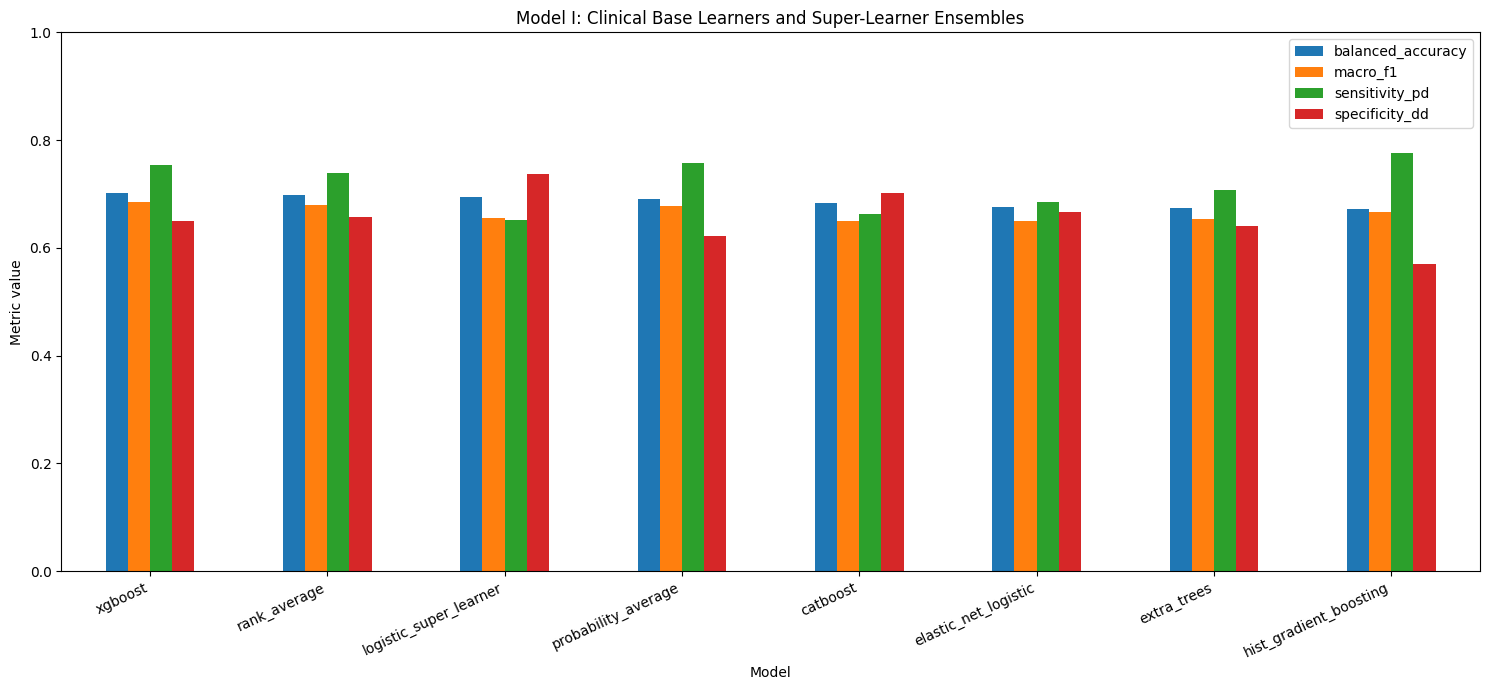

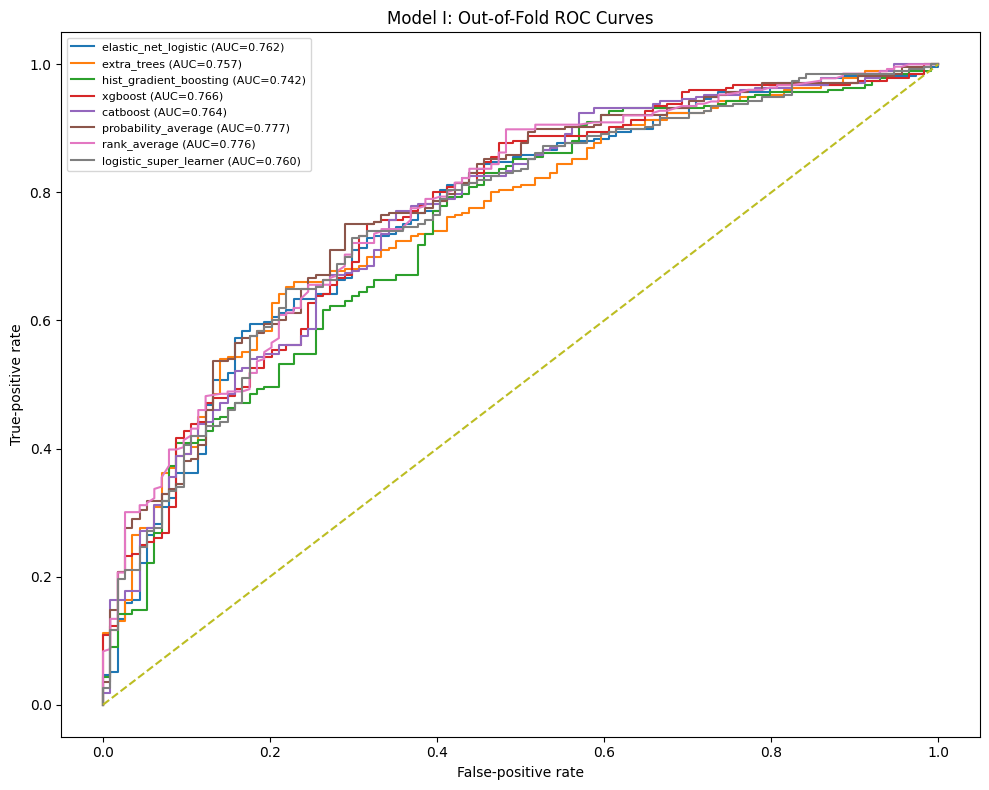

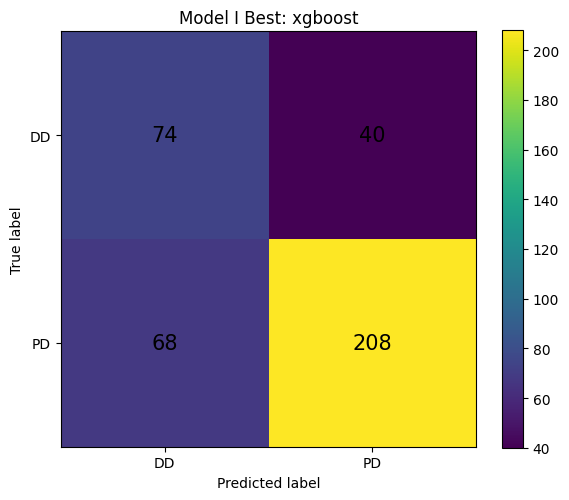


MODEL I COMPLETE

Overall out-of-fold results:

                 model  accuracy  balanced_accuracy  macro_f1  sensitivity_pd  specificity_dd  roc_auc  pr_auc  brier_score  ece_10_bins  true_negative  false_positive  false_negative  true_positive
               xgboost    0.7231             0.7014    0.6860          0.7536          0.6491   0.7662  0.8822       0.1696       0.0679             74              40              68            208
          rank_average    0.7154             0.6985    0.6804          0.7391          0.6579   0.7757  0.8889       0.2126       0.2013             75              39              72            204
logistic_super_learner    0.6769             0.6945    0.6561          0.6522          0.7368   0.7604  0.8757       0.2003       0.1644             84              30              96            180
   probability_average    0.7179             0.6900    0.6776          0.7572          0.6228   0.7772  0.8868       0.1688       0.0479             71    

In [ ]:
# ==================================================================================================
# MODEL I — LEAKAGE-FREE REPEATED-CV CLINICAL SUPER LEARNER
#
# INPUT:
#   - 30-item NMS questionnaire JSON files
#   - Safe demographics
#   - Existing fixed 5 outer patient-level folds
#   - Optional Model-H predictions for paired comparison
#
# BASE LEARNERS:
#   1. Elastic-net Logistic Regression
#   2. Extra Trees
#   3. HistGradientBoosting
#   4. XGBoost
#   5. CatBoost
#
# ENSEMBLES:
#   1. Simple probability average
#   2. AUC-rank average
#   3. Leakage-free logistic super learner
#
# VALIDATION:
#   - Same 390 PD-vs-DD patients
#   - Same fixed five outer folds
#   - Repeated inner stratified CV
#   - Threshold selection only from outer-training OOF predictions
#   - Meta-learner cross-fitted before threshold selection
#   - Every patient tested exactly once
#
# IMPORTANT:
#   No result or Q1 acceptance is guaranteed.
# ==================================================================================================

import os
import gc
import sys
import ast
import json
import time
import random
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ==================================================================================================
# 1. INSTALL / IMPORT
# ==================================================================================================

for import_name, package_name in [
    ("xgboost", "xgboost"),
    ("catboost", "catboost")
]:
    try:
        __import__(import_name)
    except ImportError:
        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            package_name
        ])

import xgboost as xgb

from catboost import CatBoostClassifier

from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    RepeatedStratifiedKFold
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures,
    QuantileTransformer
)
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    mutual_info_classif
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve,
    precision_recall_curve
)

print("=" * 125)
print("MODEL I — LEAKAGE-FREE REPEATED-CV CLINICAL SUPER LEARNER")
print("=" * 125)

print("XGBoost version:", xgb.__version__)

# ==================================================================================================
# 2. CONFIGURATION
# ==================================================================================================

GLOBAL_SEED = 42

INNER_FOLDS = 5
INNER_REPEATS = 3

META_FOLDS = 5

N_BOOTSTRAPS = 2000

THRESHOLD_GRID = np.arange(
    0.20,
    0.801,
    0.0025
)

# Model-H benchmark from completed experiment.
MODEL_H_BALANCED_ACCURACY = 0.70185
MODEL_H_MACRO_F1 = 0.680524

random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

# ==================================================================================================
# 3. GPU CHECK
# ==================================================================================================

GPU_AVAILABLE = False

try:
    test_X = np.random.randn(
        30,
        5
    ).astype(np.float32)

    test_y = np.array(
        [0, 1] * 15,
        dtype=int
    )

    gpu_test_model = xgb.XGBClassifier(
        n_estimators=2,
        max_depth=2,
        tree_method="hist",
        device="cuda",
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=GLOBAL_SEED,
        verbosity=0
    )

    gpu_test_model.fit(
        test_X,
        test_y
    )

    GPU_AVAILABLE = True
    print("✅ XGBoost GPU available.")

    del test_X, test_y, gpu_test_model
    gc.collect()

except Exception:
    print("⚠️ XGBoost GPU unavailable; CPU fallback will be used.")

XGB_DEVICE = (
    "cuda"
    if GPU_AVAILABLE
    else "cpu"
)

# CatBoost remains on CPU because the dataset is small.
CATBOOST_TASK_TYPE = "CPU"

# ==================================================================================================
# 4. PATHS
# ==================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = (
    BASE_DIR
    / "project_ready_data"
)

FEATURE_FILE = (
    PROJECT_DIR
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = (
    PROJECT_DIR
    / "baseline_results"
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

QUESTIONNAIRE_DIR = (
    BASE_DIR
    / "questionnaire"
)

MODEL_H_PREDICTION_FILE = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_h_sensor_nms_stacked_ensemble"
    / "model_h_patient_predictions.csv"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_i_repeated_cv_clinical_super_learner"
)

FIGURE_DIR = (
    OUTPUT_DIR
    / "figures"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def locate_required_file(
    expected_path,
    filename
):
    if expected_path.exists():
        return expected_path

    matches = list(
        BASE_DIR.rglob(filename)
    )

    if not matches:
        raise FileNotFoundError(
            f"Required file nahi mili: {filename}"
        )

    return matches[0]


FEATURE_FILE = locate_required_file(
    FEATURE_FILE,
    "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = locate_required_file(
    FIXED_SPLIT_FILE,
    "fixed_outer_5fold_splits.csv"
)

if not QUESTIONNAIRE_DIR.exists():
    questionnaire_matches = list(
        BASE_DIR.rglob(
            "questionnaire_response_*.json"
        )
    )

    if not questionnaire_matches:
        raise FileNotFoundError(
            "Questionnaire JSON files nahi milin."
        )

    QUESTIONNAIRE_DIR = questionnaire_matches[
        0
    ].parent

print("\nFeature file       :", FEATURE_FILE)
print("Fixed-fold file    :", FIXED_SPLIT_FILE)
print("Questionnaire path :", QUESTIONNAIRE_DIR)
print("Model-H predictions:", MODEL_H_PREDICTION_FILE)
print("Output directory   :", OUTPUT_DIR)

# ==================================================================================================
# 5. LOAD COHORT AND LABELS
# ==================================================================================================

data = pd.read_csv(
    FEATURE_FILE
)

PATIENT_ID_COLUMN = next(
    (
        column
        for column in [
            "patient_id",
            "id",
            "patient",
            "Patient_ID"
        ]
        if column in data.columns
    ),
    None
)

TARGET_COLUMN = next(
    (
        column
        for column in [
            "y",
            "label",
            "target",
            "condition_2class",
            "diagnostic_group"
        ]
        if column in data.columns
    ),
    None
)

if PATIENT_ID_COLUMN is None:
    raise ValueError(
        "Patient-ID column identify nahi hui."
    )

if TARGET_COLUMN is None:
    raise ValueError(
        "Target column identify nahi hui."
    )

data[PATIENT_ID_COLUMN] = (
    data[PATIENT_ID_COLUMN]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

if pd.api.types.is_numeric_dtype(
    data[TARGET_COLUMN]
):
    target_numeric = pd.to_numeric(
        data[TARGET_COLUMN],
        errors="coerce"
    )

    unique_values = set(
        target_numeric
        .dropna()
        .unique()
    )

    if unique_values.issubset(
        {0, 1}
    ):
        y = target_numeric.astype(
            int
        ).to_numpy()

    elif unique_values.issubset(
        {1, 2}
    ):
        y = (
            target_numeric == 1
        ).astype(int).to_numpy()

    else:
        raise ValueError(
            f"Unexpected target values: {sorted(unique_values)}"
        )

else:
    normalized_target = (
        data[TARGET_COLUMN]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    target_mapping = {
        "pd": 1,
        "parkinson": 1,
        "parkinsons": 1,
        "parkinson's": 1,
        "1": 1,

        "dd": 0,
        "differential diagnosis": 0,
        "differential-diagnosis": 0,
        "other movement disorders": 0,
        "0": 0
    }

    mapped_target = normalized_target.map(
        target_mapping
    )

    if mapped_target.isna().any():
        raise ValueError(
            "Unknown labels: "
            f"{sorted(normalized_target[mapped_target.isna()].unique())}"
        )

    y = mapped_target.astype(
        int
    ).to_numpy()

patient_ids = (
    data[PATIENT_ID_COLUMN]
    .to_numpy()
)

N_PATIENTS = len(
    patient_ids
)

patient_to_index = {
    patient_id: index
    for index, patient_id
    in enumerate(patient_ids)
}

if len(
    np.unique(patient_ids)
) != N_PATIENTS:
    raise ValueError(
        "Duplicate patient IDs detected."
    )

print("\nPatients:", N_PATIENTS)
print("PD      :", int(np.sum(y == 1)))
print("DD      :", int(np.sum(y == 0)))

# ==================================================================================================
# 6. PARSE COMPLETE NMS QUESTIONNAIRE
# ==================================================================================================

questionnaire_files = sorted(
    QUESTIONNAIRE_DIR.glob(
        "questionnaire_response_*.json"
    )
)

if not questionnaire_files:
    questionnaire_files = sorted(
        BASE_DIR.rglob(
            "questionnaire_response_*.json"
        )
    )

print(
    "\nQuestionnaire files found:",
    len(questionnaire_files)
)

questionnaire_rows = []
question_text_rows = []

for questionnaire_file in questionnaire_files:
    try:
        raw_object = json.loads(
            questionnaire_file.read_text(
                encoding="utf-8"
            )
        )

        if isinstance(
            raw_object,
            list
        ):
            raw_rows = raw_object

        elif isinstance(
            raw_object,
            dict
        ):
            if isinstance(
                raw_object.get("item"),
                list
            ):
                raw_rows = raw_object[
                    "item"
                ]

            elif isinstance(
                raw_object.get("items"),
                list
            ):
                raw_rows = raw_object[
                    "items"
                ]

            elif isinstance(
                raw_object.get("entry"),
                list
            ):
                raw_rows = raw_object[
                    "entry"
                ]

            else:
                raw_rows = [
                    raw_object
                ]

        else:
            continue

        subject_id = None
        patient_row = {}

        for raw_row in raw_rows:
            if not isinstance(
                raw_row,
                dict
            ):
                continue

            if subject_id is None:
                subject_candidate = (
                    raw_row.get(
                        "subject_id"
                    )
                    or raw_row.get(
                        "patient_id"
                    )
                    or raw_row.get(
                        "participant_id"
                    )
                )

                if subject_candidate is not None:
                    subject_id = (
                        str(subject_candidate)
                        .replace(
                            ".0",
                            ""
                        )
                        .zfill(3)
                    )

            item = raw_row.get(
                "item",
                raw_row
            )

            if isinstance(
                item,
                str
            ):
                try:
                    item = ast.literal_eval(
                        item
                    )
                except Exception:
                    try:
                        item = json.loads(
                            item
                        )
                    except Exception:
                        continue

            if not isinstance(
                item,
                dict
            ):
                continue

            link_id = (
                item.get("link_id")
                or item.get("linkId")
                or item.get("id")
            )

            answer = item.get(
                "answer"
            )

            question_text = (
                item.get("text")
                or item.get("question")
                or ""
            )

            if link_id is None:
                continue

            link_id = str(
                link_id
            ).zfill(2)

            if isinstance(
                answer,
                bool
            ):
                numeric_answer = int(
                    answer
                )

            elif answer is None:
                numeric_answer = np.nan

            elif isinstance(
                answer,
                (int, float)
            ):
                numeric_answer = float(
                    answer
                )

            else:
                answer_mapping = {
                    "true": 1,
                    "yes": 1,
                    "1": 1,
                    "present": 1,

                    "false": 0,
                    "no": 0,
                    "0": 0,
                    "absent": 0
                }

                numeric_answer = answer_mapping.get(
                    str(answer)
                    .strip()
                    .lower(),
                    np.nan
                )

            patient_row[
                f"nms_{link_id}"
            ] = numeric_answer

            question_text_rows.append({
                "link_id": link_id,
                "question_text": question_text
            })

        if subject_id is None:
            subject_id = (
                questionnaire_file
                .stem
                .replace(
                    "questionnaire_response_",
                    ""
                )
                .zfill(3)
            )

        patient_row[
            "patient_id"
        ] = subject_id

        questionnaire_rows.append(
            patient_row
        )

    except Exception as error:
        print(
            "Could not parse:",
            questionnaire_file.name,
            str(error)[:100]
        )

questionnaire_df = pd.DataFrame(
    questionnaire_rows
)

questionnaire_df["patient_id"] = (
    questionnaire_df["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

questionnaire_df = (
    questionnaire_df
    .drop_duplicates(
        subset=["patient_id"],
        keep="last"
    )
    .set_index("patient_id")
)

NMS_COLUMNS = [
    f"nms_{index:02d}"
    for index in range(
        1,
        31
    )
]

for column in NMS_COLUMNS:
    if column not in questionnaire_df.columns:
        questionnaire_df[column] = np.nan

questionnaire_df = (
    questionnaire_df[
        NMS_COLUMNS
    ]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
)

matched_patients = len(
    set(patient_ids)
    .intersection(
        questionnaire_df.index
    )
)

print(
    "Matched questionnaire patients:",
    f"{matched_patients}/{N_PATIENTS}"
)

if matched_patients != N_PATIENTS:
    raise RuntimeError(
        "Questionnaire matching 390/390 nahi hui."
    )

X_nms = (
    questionnaire_df
    .reindex(
        patient_ids
    )
    .reset_index(
        drop=True
    )
)

# ==================================================================================================
# 7. FEATURE ENGINEERING
# ==================================================================================================

X_clinical = X_nms.copy()

# Basic questionnaire aggregates.
X_clinical[
    "nms_answered_count"
] = X_nms.notna().sum(
    axis=1
)

X_clinical[
    "nms_positive_count"
] = X_nms.sum(
    axis=1,
    skipna=True
)

X_clinical[
    "nms_positive_fraction"
] = (
    X_clinical[
        "nms_positive_count"
    ]
    / X_clinical[
        "nms_answered_count"
    ].replace(
        0,
        np.nan
    )
)

# Questionnaire distribution summaries.
X_clinical[
    "nms_first_10_sum"
] = X_nms[
    NMS_COLUMNS[:10]
].sum(
    axis=1,
    skipna=True
)

X_clinical[
    "nms_middle_10_sum"
] = X_nms[
    NMS_COLUMNS[10:20]
].sum(
    axis=1,
    skipna=True
)

X_clinical[
    "nms_last_10_sum"
] = X_nms[
    NMS_COLUMNS[20:30]
].sum(
    axis=1,
    skipna=True
)

# Five six-item blocks allow nonlinear models to capture broad symptom patterns.
for block_index in range(5):
    block_columns = NMS_COLUMNS[
        block_index * 6:
        (block_index + 1) * 6
    ]

    X_clinical[
        f"nms_block_{block_index + 1}_sum"
    ] = X_nms[
        block_columns
    ].sum(
        axis=1,
        skipna=True
    )

# Pairwise local co-occurrence features.
for index in range(
    0,
    30,
    2
):
    first_column = NMS_COLUMNS[
        index
    ]

    second_column = NMS_COLUMNS[
        min(
            index + 1,
            29
        )
    ]

    X_clinical[
        f"{first_column}_{second_column}_both"
    ] = (
        X_nms[
            first_column
        ]
        * X_nms[
            second_column
        ]
    )

# Safe demographics.
SAFE_DEMOGRAPHIC_COLUMNS = [
    column
    for column in [
        "age",
        "gender",
        "sex",
        "handedness",
        "height",
        "weight"
    ]
    if column in data.columns
]

demographic_mapping_rows = []

for column in SAFE_DEMOGRAPHIC_COLUMNS:
    numeric_series = pd.to_numeric(
        data[column],
        errors="coerce"
    )

    if numeric_series.notna().mean() >= 0.70:
        X_clinical[
            column
        ] = numeric_series

    else:
        normalized_series = (
            data[column]
            .astype(str)
            .str.strip()
            .str.lower()
            .replace({
                "": np.nan,
                "nan": np.nan,
                "none": np.nan
            })
        )

        categories = sorted(
            normalized_series
            .dropna()
            .unique()
        )

        mapping = {
            value: index
            for index, value
            in enumerate(categories)
        }

        X_clinical[
            column
        ] = normalized_series.map(
            mapping
        )

        for original_value, encoded_value in (
            mapping.items()
        ):
            demographic_mapping_rows.append({
                "column": column,
                "original_value": original_value,
                "encoded_value": encoded_value
            })

# BMI if valid.
if (
    "height" in X_clinical.columns
    and "weight" in X_clinical.columns
):
    height = pd.to_numeric(
        X_clinical["height"],
        errors="coerce"
    )

    weight = pd.to_numeric(
        X_clinical["weight"],
        errors="coerce"
    )

    height_m = height.copy()

    # Assume values above 3 are centimetres.
    height_m = np.where(
        height_m > 3,
        height_m / 100.0,
        height_m
    )

    X_clinical[
        "bmi"
    ] = (
        weight
        / np.square(
            height_m
        )
    )

    X_clinical.loc[
        (
            X_clinical["bmi"] < 10
        )
        | (
            X_clinical["bmi"] > 70
        ),
        "bmi"
    ] = np.nan

X_clinical = (
    X_clinical
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

print(
    "Clinical feature count:",
    X_clinical.shape[1]
)

print(
    "Safe demographics:",
    SAFE_DEMOGRAPHIC_COLUMNS
)

pd.DataFrame({
    "clinical_feature": (
        X_clinical.columns
    )
}).to_csv(
    OUTPUT_DIR
    / "model_i_feature_inventory.csv",
    index=False
)

pd.DataFrame(
    demographic_mapping_rows
).to_csv(
    OUTPUT_DIR
    / "model_i_demographic_mapping.csv",
    index=False
)

# ==================================================================================================
# 8. FIXED OUTER FOLDS
# ==================================================================================================

fixed_splits = pd.read_csv(
    FIXED_SPLIT_FILE,
    dtype={"patient_id": str}
)

fixed_splits["patient_id"] = (
    fixed_splits["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

fixed_splits["fold"] = pd.to_numeric(
    fixed_splits["fold"],
    errors="raise"
).astype(int)

fixed_splits["role"] = (
    fixed_splits["role"]
    .astype(str)
    .str.lower()
    .str.strip()
)

AVAILABLE_FOLDS = [
    int(value)
    for value in sorted(
        fixed_splits["fold"].unique()
    )
]

if AVAILABLE_FOLDS != [
    1,
    2,
    3,
    4,
    5
]:
    raise ValueError(
        f"Unexpected folds: {AVAILABLE_FOLDS}"
    )

if set(
    fixed_splits["patient_id"]
) != set(patient_ids):
    raise ValueError(
        "Feature-table and fold IDs do not match."
    )

test_frequency = (
    fixed_splits.loc[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if (
    len(test_frequency) != N_PATIENTS
    or not (test_frequency == 1).all()
):
    raise RuntimeError(
        "Every patient must appear as outer test exactly once."
    )

print(
    "✅ Fixed five patient-level folds verified."
)

# ==================================================================================================
# 9. METRIC HELPERS
# ==================================================================================================

def expected_calibration_error(
    y_true,
    probabilities,
    n_bins=10
):
    y_true = np.asarray(
        y_true,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    bin_edges = np.linspace(
        0,
        1,
        n_bins + 1
    )

    result = 0.0

    for bin_index in range(
        n_bins
    ):
        lower = bin_edges[
            bin_index
        ]

        upper = bin_edges[
            bin_index + 1
        ]

        if bin_index == n_bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if not np.any(mask):
            continue

        result += float(
            np.mean(mask)
        ) * abs(
            float(
                np.mean(
                    y_true[mask]
                )
            )
            - float(
                np.mean(
                    probabilities[mask]
                )
            )
        )

    return float(result)


def calculate_metrics(
    y_true,
    predictions,
    probabilities
):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions
        ),

        "macro_f1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "sensitivity_pd": (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        ),

        "specificity_dd": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "precision_pd": precision_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_true,
            probabilities
        ),

        "pr_auc": average_precision_score(
            y_true,
            probabilities
        ),

        "brier_score": brier_score_loss(
            y_true,
            probabilities
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            probabilities,
            10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }


def select_threshold(
    labels,
    probabilities
):
    candidate_rows = []

    for threshold in THRESHOLD_GRID:
        predictions = (
            probabilities
            >= threshold
        ).astype(int)

        candidate_rows.append({
            "threshold": float(
                threshold
            ),

            "balanced_accuracy": balanced_accuracy_score(
                labels,
                predictions
            ),

            "macro_f1": f1_score(
                labels,
                predictions,
                average="macro",
                zero_division=0
            ),

            "distance_from_half": abs(
                threshold - 0.5
            )
        })

    threshold_table = pd.DataFrame(
        candidate_rows
    )

    best_row = (
        threshold_table
        .sort_values(
            [
                "balanced_accuracy",
                "macro_f1",
                "distance_from_half"
            ],
            ascending=[
                False,
                False,
                True
            ]
        )
        .iloc[0]
    )

    return (
        float(
            best_row[
                "threshold"
            ]
        ),
        threshold_table
    )


def probability_rank_transform(
    probabilities
):
    return pd.Series(
        probabilities
    ).rank(
        method="average",
        pct=True
    ).to_numpy()


def build_meta_features(
    probability_dictionary
):
    meta_df = pd.DataFrame(
        probability_dictionary
    )

    probability_matrix = meta_df.to_numpy()

    meta_df[
        "mean_probability"
    ] = np.mean(
        probability_matrix,
        axis=1
    )

    meta_df[
        "median_probability"
    ] = np.median(
        probability_matrix,
        axis=1
    )

    meta_df[
        "probability_std"
    ] = np.std(
        probability_matrix,
        axis=1
    )

    meta_df[
        "probability_min"
    ] = np.min(
        probability_matrix,
        axis=1
    )

    meta_df[
        "probability_max"
    ] = np.max(
        probability_matrix,
        axis=1
    )

    meta_df[
        "probability_range"
    ] = (
        meta_df[
            "probability_max"
        ]
        - meta_df[
            "probability_min"
        ]
    )

    for column in probability_dictionary:
        clipped = np.clip(
            meta_df[column],
            1e-6,
            1 - 1e-6
        )

        meta_df[
            f"{column}_logit"
        ] = np.log(
            clipped
            / (1 - clipped)
        )

    return meta_df

# ==================================================================================================
# 10. BASE MODEL FACTORIES
# ==================================================================================================

def make_logistic_model(
    seed
):
    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "variance",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(
                penalty="elasticnet",
                solver="saga",
                l1_ratio=0.25,
                C=0.25,
                class_weight="balanced",
                max_iter=5000,
                random_state=int(
                    seed
                ),
                n_jobs=1
            )
        )
    ])


def make_extra_trees_model(
    seed
):
    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "variance",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "classifier",
            ExtraTreesClassifier(
                n_estimators=800,
                max_depth=6,
                min_samples_leaf=4,
                max_features=0.75,
                class_weight="balanced",
                random_state=int(
                    seed
                ),
                n_jobs=-1
            )
        )
    ])


def make_hist_gradient_model(
    seed
):
    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "variance",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "classifier",
            HistGradientBoostingClassifier(
                learning_rate=0.035,
                max_iter=350,
                max_leaf_nodes=15,
                max_depth=4,
                min_samples_leaf=12,
                l2_regularization=2.0,
                random_state=int(
                    seed
                )
            )
        )
    ])


def make_xgboost_model(
    seed
):
    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "variance",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "classifier",
            xgb.XGBClassifier(
                n_estimators=450,
                max_depth=3,
                learning_rate=0.025,
                min_child_weight=5,
                subsample=0.80,
                colsample_bytree=0.75,
                reg_alpha=0.5,
                reg_lambda=4.0,
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                device=XGB_DEVICE,
                random_state=int(
                    seed
                ),
                n_jobs=2,
                verbosity=0
            )
        )
    ])


def make_catboost_model(
    seed
):
    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "variance",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "classifier",
            CatBoostClassifier(
                iterations=450,
                depth=4,
                learning_rate=0.02,
                l2_leaf_reg=10.0,
                random_strength=0.75,
                loss_function="Logloss",
                eval_metric="Logloss",
                auto_class_weights="Balanced",
                random_seed=int(
                    seed
                ),
                task_type=CATBOOST_TASK_TYPE,
                thread_count=-1,
                verbose=False,
                allow_writing_files=False
            )
        )
    ])


BASE_MODEL_FACTORIES = {
    "elastic_net_logistic": (
        make_logistic_model
    ),
    "extra_trees": (
        make_extra_trees_model
    ),
    "hist_gradient_boosting": (
        make_hist_gradient_model
    ),
    "xgboost": (
        make_xgboost_model
    ),
    "catboost": (
        make_catboost_model
    )
}

BASE_MODEL_NAMES = list(
    BASE_MODEL_FACTORIES.keys()
)

ENSEMBLE_MODEL_NAMES = [
    "probability_average",
    "rank_average",
    "logistic_super_learner"
]

ALL_MODEL_NAMES = (
    BASE_MODEL_NAMES
    + ENSEMBLE_MODEL_NAMES
)

# ==================================================================================================
# 11. STORAGE
# ==================================================================================================

probability_storage = {
    model_name: np.full(
        N_PATIENTS,
        np.nan,
        dtype=np.float64
    )
    for model_name in ALL_MODEL_NAMES
}

prediction_storage = {
    model_name: np.full(
        N_PATIENTS,
        -1,
        dtype=int
    )
    for model_name in ALL_MODEL_NAMES
}

patient_outer_fold = np.full(
    N_PATIENTS,
    -1,
    dtype=int
)

fold_result_rows = []
threshold_rows = []
base_inner_result_rows = []
meta_coefficient_rows = []

total_start_time = time.time()

# ==================================================================================================
# 12. OUTER-FOLD EXPERIMENT
# ==================================================================================================

print("\n" + "=" * 125)
print("STARTING MODEL I FIXED FIVE-FOLD EXPERIMENT")
print("=" * 125)

for outer_fold in AVAILABLE_FOLDS:
    fold_start_time = time.time()

    current_fold_table = fixed_splits.loc[
        fixed_splits[
            "fold"
        ] == outer_fold
    ]

    outer_train_ids = current_fold_table.loc[
        current_fold_table[
            "role"
        ] == "train",
        "patient_id"
    ].tolist()

    outer_test_ids = current_fold_table.loc[
        current_fold_table[
            "role"
        ] == "test",
        "patient_id"
    ].tolist()

    outer_train_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id
        in outer_train_ids
    ], dtype=int)

    outer_test_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id
        in outer_test_ids
    ], dtype=int)

    X_outer_train_df = (
        X_clinical.iloc[
            outer_train_indices
        ]
        .reset_index(
            drop=True
        )
    )

    X_outer_test_df = (
        X_clinical.iloc[
            outer_test_indices
        ]
        .reset_index(
            drop=True
        )
    )

    y_outer_train = y[
        outer_train_indices
    ]

    y_outer_test = y[
        outer_test_indices
    ]

    # Repeated CV gives each training patient several validation predictions.
    repeated_splitter = RepeatedStratifiedKFold(
        n_splits=INNER_FOLDS,
        n_repeats=INNER_REPEATS,
        random_state=(
            GLOBAL_SEED
            + outer_fold * 1000
        )
    )

    inner_probability_sums = {
        model_name: np.zeros(
            len(outer_train_indices),
            dtype=np.float64
        )
        for model_name in BASE_MODEL_NAMES
    }

    inner_prediction_counts = np.zeros(
        len(outer_train_indices),
        dtype=int
    )

    split_counter = 0

    for (
        relative_inner_train,
        relative_inner_validation
    ) in repeated_splitter.split(
        np.zeros(
            len(outer_train_indices)
        ),
        y_outer_train
    ):
        split_counter += 1

        inner_prediction_counts[
            relative_inner_validation
        ] += 1

        for model_number, model_name in enumerate(
            BASE_MODEL_NAMES
        ):
            model_seed = int(
                GLOBAL_SEED
                + outer_fold * 100000
                + split_counter * 100
                + model_number
            )

            model = BASE_MODEL_FACTORIES[
                model_name
            ](
                model_seed
            )

            model.fit(
                X_outer_train_df.iloc[
                    relative_inner_train
                ],
                y_outer_train[
                    relative_inner_train
                ]
            )

            inner_probability_sums[
                model_name
            ][
                relative_inner_validation
            ] += model.predict_proba(
                X_outer_train_df.iloc[
                    relative_inner_validation
                ]
            )[:, 1]

            del model
            gc.collect()

    if np.any(
        inner_prediction_counts == 0
    ):
        raise RuntimeError(
            f"Missing inner predictions in fold {outer_fold}."
        )

    base_inner_oof = {}

    for model_name in BASE_MODEL_NAMES:
        base_inner_oof[
            model_name
        ] = (
            inner_probability_sums[
                model_name
            ]
            / inner_prediction_counts
        )

        base_threshold, _ = select_threshold(
            y_outer_train,
            base_inner_oof[
                model_name
            ]
        )

        base_predictions = (
            base_inner_oof[
                model_name
            ]
            >= base_threshold
        ).astype(int)

        base_inner_metrics = calculate_metrics(
            y_outer_train,
            base_predictions,
            base_inner_oof[
                model_name
            ]
        )

        base_inner_result_rows.append({
            "outer_fold": outer_fold,
            "model": model_name,
            "selected_threshold": (
                base_threshold
            ),
            "inner_balanced_accuracy": (
                base_inner_metrics[
                    "balanced_accuracy"
                ]
            ),
            "inner_macro_f1": (
                base_inner_metrics[
                    "macro_f1"
                ]
            ),
            "inner_roc_auc": (
                base_inner_metrics[
                    "roc_auc"
                ]
            )
        })

    # ----------------------------------------------------------------------------------------------
    # Simple probability average
    # ----------------------------------------------------------------------------------------------

    average_train_probability = np.mean(
        np.column_stack([
            base_inner_oof[
                model_name
            ]
            for model_name in BASE_MODEL_NAMES
        ]),
        axis=1
    )

    # ----------------------------------------------------------------------------------------------
    # Rank average
    # ----------------------------------------------------------------------------------------------

    rank_train_probability = np.mean(
        np.column_stack([
            probability_rank_transform(
                base_inner_oof[
                    model_name
                ]
            )
            for model_name in BASE_MODEL_NAMES
        ]),
        axis=1
    )

    # ----------------------------------------------------------------------------------------------
    # Cross-fitted logistic super learner
    # ----------------------------------------------------------------------------------------------

    meta_train_df = build_meta_features(
        base_inner_oof
    )

    meta_splitter = StratifiedKFold(
        n_splits=META_FOLDS,
        shuffle=True,
        random_state=(
            GLOBAL_SEED
            + outer_fold * 2000
        )
    )

    meta_oof_probability = np.full(
        len(outer_train_indices),
        np.nan,
        dtype=np.float64
    )

    for meta_fold, (
        meta_train_relative,
        meta_validation_relative
    ) in enumerate(
        meta_splitter.split(
            meta_train_df,
            y_outer_train
        ),
        start=1
    ):
        meta_model = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                LogisticRegression(
                    penalty="l2",
                    C=0.10,
                    class_weight="balanced",
                    solver="liblinear",
                    max_iter=5000,
                    random_state=(
                        GLOBAL_SEED
                        + outer_fold * 3000
                        + meta_fold
                    )
                )
            )
        ])

        meta_model.fit(
            meta_train_df.iloc[
                meta_train_relative
            ],
            y_outer_train[
                meta_train_relative
            ]
        )

        meta_oof_probability[
            meta_validation_relative
        ] = meta_model.predict_proba(
            meta_train_df.iloc[
                meta_validation_relative
            ]
        )[:, 1]

    if np.isnan(
        meta_oof_probability
    ).any():
        raise RuntimeError(
            f"Missing meta OOF predictions in fold {outer_fold}."
        )

    training_probability_dictionary = {
        **base_inner_oof,
        "probability_average": (
            average_train_probability
        ),
        "rank_average": (
            rank_train_probability
        ),
        "logistic_super_learner": (
            meta_oof_probability
        )
    }

    selected_thresholds = {}

    for model_name in ALL_MODEL_NAMES:
        selected_threshold, _ = select_threshold(
            y_outer_train,
            training_probability_dictionary[
                model_name
            ]
        )

        selected_thresholds[
            model_name
        ] = selected_threshold

    # ----------------------------------------------------------------------------------------------
    # Train final base models on complete outer training
    # ----------------------------------------------------------------------------------------------

    base_test_probabilities = {}

    for model_number, model_name in enumerate(
        BASE_MODEL_NAMES
    ):
        final_model = BASE_MODEL_FACTORIES[
            model_name
        ](
            GLOBAL_SEED
            + outer_fold * 40000
            + model_number
        )

        final_model.fit(
            X_outer_train_df,
            y_outer_train
        )

        base_test_probabilities[
            model_name
        ] = final_model.predict_proba(
            X_outer_test_df
        )[:, 1]

        del final_model
        gc.collect()

    average_test_probability = np.mean(
        np.column_stack([
            base_test_probabilities[
                model_name
            ]
            for model_name in BASE_MODEL_NAMES
        ]),
        axis=1
    )

    rank_test_probability = np.mean(
        np.column_stack([
            probability_rank_transform(
                base_test_probabilities[
                    model_name
                ]
            )
            for model_name in BASE_MODEL_NAMES
        ]),
        axis=1
    )

    # Fit final meta-model using cross-fitted base training predictions.
    final_meta_model = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(
                penalty="l2",
                C=0.10,
                class_weight="balanced",
                solver="liblinear",
                max_iter=5000,
                random_state=(
                    GLOBAL_SEED
                    + outer_fold * 50000
                )
            )
        )
    ])

    final_meta_model.fit(
        meta_train_df,
        y_outer_train
    )

    meta_test_df = build_meta_features(
        base_test_probabilities
    )

    super_learner_test_probability = (
        final_meta_model.predict_proba(
            meta_test_df
        )[:, 1]
    )

    final_classifier = (
        final_meta_model.named_steps[
            "classifier"
        ]
    )

    for feature_name, coefficient in zip(
        meta_train_df.columns,
        final_classifier.coef_[0]
    ):
        meta_coefficient_rows.append({
            "outer_fold": outer_fold,
            "feature": feature_name,
            "coefficient": float(
                coefficient
            )
        })

    test_probability_dictionary = {
        **base_test_probabilities,
        "probability_average": (
            average_test_probability
        ),
        "rank_average": (
            rank_test_probability
        ),
        "logistic_super_learner": (
            super_learner_test_probability
        )
    }

    # ----------------------------------------------------------------------------------------------
    # Store untouched outer-test predictions
    # ----------------------------------------------------------------------------------------------

    for model_name in ALL_MODEL_NAMES:
        current_probability = (
            test_probability_dictionary[
                model_name
            ]
        )

        current_threshold = (
            selected_thresholds[
                model_name
            ]
        )

        current_prediction = (
            current_probability
            >= current_threshold
        ).astype(int)

        probability_storage[
            model_name
        ][outer_test_indices] = (
            current_probability
        )

        prediction_storage[
            model_name
        ][outer_test_indices] = (
            current_prediction
        )

        current_metrics = calculate_metrics(
            y_outer_test,
            current_prediction,
            current_probability
        )

        fold_result_rows.append({
            "outer_fold": outer_fold,
            "model": model_name,
            "threshold": current_threshold,
            "balanced_accuracy": (
                current_metrics[
                    "balanced_accuracy"
                ]
            ),
            "macro_f1": (
                current_metrics[
                    "macro_f1"
                ]
            ),
            "sensitivity_pd": (
                current_metrics[
                    "sensitivity_pd"
                ]
            ),
            "specificity_dd": (
                current_metrics[
                    "specificity_dd"
                ]
            ),
            "roc_auc": (
                current_metrics[
                    "roc_auc"
                ]
            ),
            "pr_auc": (
                current_metrics[
                    "pr_auc"
                ]
            ),
            "brier_score": (
                current_metrics[
                    "brier_score"
                ]
            ),
            "ece_10_bins": (
                current_metrics[
                    "ece_10_bins"
                ]
            )
        })

        threshold_rows.append({
            "outer_fold": outer_fold,
            "model": model_name,
            "selected_threshold": (
                current_threshold
            )
        })

    patient_outer_fold[
        outer_test_indices
    ] = outer_fold

    print("\n" + "-" * 110)
    print(
        f"OUTER FOLD {outer_fold}/5"
    )
    print("-" * 110)

    latest_fold_rows = pd.DataFrame(
        fold_result_rows
    )

    latest_fold_rows = latest_fold_rows.loc[
        latest_fold_rows[
            "outer_fold"
        ] == outer_fold
    ]

    latest_fold_rows = (
        latest_fold_rows
        .sort_values(
            "balanced_accuracy",
            ascending=False
        )
    )

    print(
        latest_fold_rows[
            [
                "model",
                "balanced_accuracy",
                "macro_f1",
                "sensitivity_pd",
                "specificity_dd",
                "roc_auc"
            ]
        ]
        .head(8)
        .round(4)
        .to_string(
            index=False
        )
    )

    print(
        "Fold runtime:",
        f"{(time.time() - fold_start_time) / 60:.2f} minutes"
    )

    del (
        final_meta_model,
        meta_train_df,
        meta_test_df
    )

    gc.collect()

total_runtime_minutes = (
    time.time()
    - total_start_time
) / 60.0

# ==================================================================================================
# 13. VERIFY COMPLETE OOF RESULTS
# ==================================================================================================

for model_name in ALL_MODEL_NAMES:
    if np.isnan(
        probability_storage[
            model_name
        ]
    ).any():
        raise RuntimeError(
            f"Missing OOF probabilities: {model_name}"
        )

    if np.any(
        prediction_storage[
            model_name
        ] < 0
    ):
        raise RuntimeError(
            f"Missing OOF predictions: {model_name}"
        )

if np.any(
    patient_outer_fold < 1
):
    raise RuntimeError(
        "Some patients do not have outer-fold predictions."
    )

print(
    "\n✅ Every patient received one untouched outer-test prediction for every model."
)

# ==================================================================================================
# 14. OVERALL COMPARISON
# ==================================================================================================

overall_rows = []

for model_name in ALL_MODEL_NAMES:
    metrics = calculate_metrics(
        y,
        prediction_storage[
            model_name
        ],
        probability_storage[
            model_name
        ]
    )

    overall_rows.append({
        "model": model_name,
        **metrics
    })

overall_df = pd.DataFrame(
    overall_rows
)

fold_results_df = pd.DataFrame(
    fold_result_rows
)

threshold_df = pd.DataFrame(
    threshold_rows
)

base_inner_results_df = pd.DataFrame(
    base_inner_result_rows
)

meta_coefficients_df = pd.DataFrame(
    meta_coefficient_rows
)

# ==================================================================================================
# 15. PATIENT-LEVEL PREDICTIONS
# ==================================================================================================

patient_prediction_rows = []

for patient_index in range(
    N_PATIENTS
):
    for model_name in ALL_MODEL_NAMES:
        patient_prediction_rows.append({
            "patient_id": (
                patient_ids[
                    patient_index
                ]
            ),
            "outer_fold": int(
                patient_outer_fold[
                    patient_index
                ]
            ),
            "true_label": int(
                y[
                    patient_index
                ]
            ),
            "model": model_name,
            "predicted_probability_pd": float(
                probability_storage[
                    model_name
                ][
                    patient_index
                ]
            ),
            "predicted_label": int(
                prediction_storage[
                    model_name
                ][
                    patient_index
                ]
            ),
            "correct_prediction": int(
                prediction_storage[
                    model_name
                ][
                    patient_index
                ]
                == y[
                    patient_index
                ]
            )
        })

patient_predictions_df = pd.DataFrame(
    patient_prediction_rows
)

# ==================================================================================================
# 16. BOOTSTRAP CONFIDENCE INTERVALS
# ==================================================================================================

bootstrap_rng = np.random.default_rng(
    GLOBAL_SEED
)

bootstrap_rows = []

for bootstrap_iteration in range(
    N_BOOTSTRAPS
):
    sampled_indices = bootstrap_rng.integers(
        0,
        N_PATIENTS,
        size=N_PATIENTS
    )

    sampled_y = y[
        sampled_indices
    ]

    if len(
        np.unique(sampled_y)
    ) < 2:
        continue

    for model_name in ALL_MODEL_NAMES:
        metrics = calculate_metrics(
            sampled_y,
            prediction_storage[
                model_name
            ][
                sampled_indices
            ],
            probability_storage[
                model_name
            ][
                sampled_indices
            ]
        )

        bootstrap_rows.append({
            "bootstrap_iteration": (
                bootstrap_iteration
            ),
            "model": model_name,
            **metrics
        })

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

confidence_interval_rows = []

for _, observed_row in overall_df.iterrows():
    model_name = observed_row[
        "model"
    ]

    subset = bootstrap_df.loc[
        bootstrap_df[
            "model"
        ] == model_name
    ]

    for metric_name in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "ece_10_bins"
    ]:
        values = (
            subset[
                metric_name
            ]
            .dropna()
            .to_numpy()
        )

        confidence_interval_rows.append({
            "model": model_name,
            "metric": metric_name,
            "value": float(
                observed_row[
                    metric_name
                ]
            ),
            "ci_95_lower": float(
                np.percentile(
                    values,
                    2.5
                )
            ),
            "ci_95_upper": float(
                np.percentile(
                    values,
                    97.5
                )
            )
        })

confidence_intervals_df = pd.DataFrame(
    confidence_interval_rows
)

# ==================================================================================================
# 17. OPTIONAL PAIRED BOOTSTRAP VERSUS MODEL H
# ==================================================================================================

paired_vs_h_rows = []

if MODEL_H_PREDICTION_FILE.exists():
    model_h_predictions = pd.read_csv(
        MODEL_H_PREDICTION_FILE,
        dtype={"patient_id": str}
    )

    model_h_predictions["patient_id"] = (
        model_h_predictions["patient_id"]
        .astype(str)
        .str.replace(
            ".0",
            "",
            regex=False
        )
        .str.zfill(3)
    )

    # Prefer logistic stacking from Model H.
    model_h_reference = (
        model_h_predictions.loc[
            model_h_predictions[
                "model"
            ] == "logistic_stacking"
        ]
        .drop_duplicates(
            subset=["patient_id"]
        )
        .set_index("patient_id")
        .loc[patient_ids]
    )

    model_h_labels = (
        model_h_reference[
            "predicted_label"
        ]
        .to_numpy(
            dtype=int
        )
    )

    model_h_probabilities = (
        model_h_reference[
            "predicted_probability_pd"
        ]
        .to_numpy(
            dtype=float
        )
    )

    best_model_name = (
        overall_df
        .sort_values(
            [
                "balanced_accuracy",
                "macro_f1",
                "roc_auc"
            ],
            ascending=[
                False,
                False,
                False
            ]
        )
        .iloc[0][
            "model"
        ]
    )

    delta_rows = []

    for bootstrap_iteration in range(
        N_BOOTSTRAPS
    ):
        sampled_indices = bootstrap_rng.integers(
            0,
            N_PATIENTS,
            size=N_PATIENTS
        )

        sampled_y = y[
            sampled_indices
        ]

        if len(
            np.unique(sampled_y)
        ) < 2:
            continue

        model_i_ba = balanced_accuracy_score(
            sampled_y,
            prediction_storage[
                best_model_name
            ][
                sampled_indices
            ]
        )

        model_h_ba = balanced_accuracy_score(
            sampled_y,
            model_h_labels[
                sampled_indices
            ]
        )

        model_i_f1 = f1_score(
            sampled_y,
            prediction_storage[
                best_model_name
            ][
                sampled_indices
            ],
            average="macro",
            zero_division=0
        )

        model_h_f1 = f1_score(
            sampled_y,
            model_h_labels[
                sampled_indices
            ],
            average="macro",
            zero_division=0
        )

        delta_rows.append({
            "bootstrap_iteration": (
                bootstrap_iteration
            ),
            "best_model_i": (
                best_model_name
            ),
            "balanced_accuracy_delta": (
                model_i_ba
                - model_h_ba
            ),
            "macro_f1_delta": (
                model_i_f1
                - model_h_f1
            )
        })

    paired_vs_h_df = pd.DataFrame(
        delta_rows
    )

    for metric_name in [
        "balanced_accuracy_delta",
        "macro_f1_delta"
    ]:
        values = paired_vs_h_df[
            metric_name
        ].to_numpy()

        paired_vs_h_rows.append({
            "best_model_i": (
                best_model_name
            ),
            "metric": metric_name,
            "observed_delta": (
                (
                    overall_df.set_index(
                        "model"
                    ).loc[
                        best_model_name,
                        "balanced_accuracy"
                    ]
                    - MODEL_H_BALANCED_ACCURACY
                )
                if metric_name
                == "balanced_accuracy_delta"
                else
                (
                    overall_df.set_index(
                        "model"
                    ).loc[
                        best_model_name,
                        "macro_f1"
                    ]
                    - MODEL_H_MACRO_F1
                )
            ),
            "ci_95_lower": float(
                np.percentile(
                    values,
                    2.5
                )
            ),
            "ci_95_upper": float(
                np.percentile(
                    values,
                    97.5
                )
            ),
            "probability_delta_above_zero": float(
                np.mean(
                    values > 0
                )
            )
        })

else:
    paired_vs_h_df = pd.DataFrame()

paired_vs_h_summary_df = pd.DataFrame(
    paired_vs_h_rows
)

# ==================================================================================================
# 18. SAVE OUTPUTS
# ==================================================================================================

overall_df.to_csv(
    OUTPUT_DIR
    / "model_i_overall_comparison.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR
    / "model_i_fold_results.csv",
    index=False
)

patient_predictions_df.to_csv(
    OUTPUT_DIR
    / "model_i_patient_predictions.csv",
    index=False
)

threshold_df.to_csv(
    OUTPUT_DIR
    / "model_i_thresholds_by_fold.csv",
    index=False
)

base_inner_results_df.to_csv(
    OUTPUT_DIR
    / "model_i_inner_training_results.csv",
    index=False
)

meta_coefficients_df.to_csv(
    OUTPUT_DIR
    / "model_i_meta_coefficients.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR
    / "model_i_bootstrap_metrics.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR
    / "model_i_confidence_intervals_95.csv",
    index=False
)

if not paired_vs_h_df.empty:
    paired_vs_h_df.to_csv(
        OUTPUT_DIR
        / "model_i_paired_bootstrap_vs_model_h.csv",
        index=False
    )

if not paired_vs_h_summary_df.empty:
    paired_vs_h_summary_df.to_csv(
        OUTPUT_DIR
        / "model_i_paired_ci_vs_model_h.csv",
        index=False
    )

# ==================================================================================================
# 19. FIGURES
# ==================================================================================================

plot_df = (
    overall_df
    .sort_values(
        "balanced_accuracy",
        ascending=False
    )
    .set_index(
        "model"
    )
)

plt.figure(
    figsize=(15, 7)
)

plot_df[
    [
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd"
    ]
].plot(
    kind="bar",
    ax=plt.gca()
)

plt.ylim(
    0,
    1
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Model I: Clinical Base Learners and Super-Learner Ensembles"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_model_i_overall_comparison.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

plt.figure(
    figsize=(10, 8)
)

for model_name in ALL_MODEL_NAMES:
    fpr, tpr, _ = roc_curve(
        y,
        probability_storage[
            model_name
        ]
    )

    auc_value = roc_auc_score(
        y,
        probability_storage[
            model_name
        ]
    )

    plt.plot(
        fpr,
        tpr,
        label=(
            f"{model_name} "
            f"(AUC={auc_value:.3f})"
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False-positive rate"
)

plt.ylabel(
    "True-positive rate"
)

plt.title(
    "Model I: Out-of-Fold ROC Curves"
)

plt.legend(
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_model_i_roc_curves.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

best_model_name = (
    overall_df
    .sort_values(
        [
            "balanced_accuracy",
            "macro_f1",
            "roc_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .iloc[0][
        "model"
    ]
)

best_confusion = confusion_matrix(
    y,
    prediction_storage[
        best_model_name
    ],
    labels=[0, 1]
)

plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    best_confusion
)

plt.colorbar()

plt.xticks(
    [0, 1],
    ["DD", "PD"]
)

plt.yticks(
    [0, 1],
    ["DD", "PD"]
)

plt.xlabel(
    "Predicted label"
)

plt.ylabel(
    "True label"
)

plt.title(
    f"Model I Best: {best_model_name}"
)

for row_index in range(2):
    for column_index in range(2):
        plt.text(
            column_index,
            row_index,
            str(
                best_confusion[
                    row_index,
                    column_index
                ]
            ),
            ha="center",
            va="center",
            fontsize=15
        )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "03_model_i_best_confusion_matrix.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 20. FINAL OUTPUT
# ==================================================================================================

print("\n" + "=" * 125)
print("MODEL I COMPLETE")
print("=" * 125)

display_columns = [
    "model",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
    "true_negative",
    "false_positive",
    "false_negative",
    "true_positive"
]

print("\nOverall out-of-fold results:\n")

print(
    overall_df[
        display_columns
    ]
    .sort_values(
        [
            "balanced_accuracy",
            "macro_f1",
            "roc_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .round(4)
    .to_string(
        index=False
    )
)

print("\nBest configuration:\n")

best_result = (
    overall_df
    .sort_values(
        [
            "balanced_accuracy",
            "macro_f1",
            "roc_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .iloc[0]
)

print(
    best_result[
        [
            "model",
            "balanced_accuracy",
            "macro_f1",
            "sensitivity_pd",
            "specificity_dd",
            "roc_auc",
            "pr_auc",
            "brier_score",
            "ece_10_bins"
        ]
    ]
    .round(4)
    .to_string()
)

print("\nComparison with completed Model H:")

print(
    "Model-H BA:",
    MODEL_H_BALANCED_ACCURACY
)

print(
    "Model-H Macro-F1:",
    MODEL_H_MACRO_F1
)

print(
    "Model-I best BA difference:",
    round(
        float(
            best_result[
                "balanced_accuracy"
            ]
            - MODEL_H_BALANCED_ACCURACY
        ),
        4
    )
)

print(
    "Model-I best Macro-F1 difference:",
    round(
        float(
            best_result[
                "macro_f1"
            ]
            - MODEL_H_MACRO_F1
        ),
        4
    )
)

if not paired_vs_h_summary_df.empty:
    print(
        "\nPaired bootstrap versus Model H:\n"
    )

    print(
        paired_vs_h_summary_df
        .round(4)
        .to_string(
            index=False
        )
    )

print("\nScientific controls:")
print("- Same 390 PD-versus-DD patients.")
print("- Same fixed five patient-level outer folds.")
print("- Complete 30-item NMS questionnaire.")
print("- Only safe demographics included.")
print("- Diagnosis, condition and disease comments excluded.")
print("- Repeated inner CV used for stable base-model probabilities.")
print("- Each base learner trained only on outer-training patients.")
print("- Meta-model trained from cross-fitted base predictions.")
print("- Meta-model threshold selected from cross-fitted training predictions.")
print("- Outer-test patients never used in model or threshold selection.")
print("- Every patient tested exactly once.")
print("- No SMOTE, duplication or outer-test leakage.")
print("- 2,000 patient-level bootstrap samples.")

print(
    "\nTotal runtime:",
    f"{total_runtime_minutes:.2f} minutes"
)

print("\nSaved files:")

for saved_file in sorted(
    OUTPUT_DIR.rglob("*")
):
    if saved_file.is_file():
        print(
            " -",
            saved_file.relative_to(
                OUTPUT_DIR
            )
        )

print(
    "\n✅ MODEL I REPEATED-CV CLINICAL SUPER LEARNER FINISHED."
)